# Example 4.2 — Matched molecular pairs: swapping a group, not an atom

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:58:25Z
- **Contents:** 3 exchanges · 17 tool calls · 2 figures · 3 code cells

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/4.2-matched-pairs-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 4.2-matched-pairs-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 4.2-matched-pairs-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/4.2-matched-pairs-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 4.2-matched-pairs-notebook-rerun.ipynb 4.2-matched-pairs-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Single-atom tweaks are not where my project is. On factor Xa, which whole-group swaps have a track record of improving potency?

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:25 UTC
await replay.call(1, 'search_targets', {'query': 'coagulation factor X', 'organism': 'Homo sapiens'},
                  sha256='ae0cb3e4d27ae6e45081ee65ac39d2fb49040ae92eaef7830d6acf63a914f4ed')

**Call 1** · `search_targets` · recorded result · sha256 `ae0cb3e4d27a…`

_10 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1341 | Coagulation factor X | P00742 | P00742 | Homo sapiens | Enzyme | 8385 | 7201 | Coagulation factor X |
| polymer | 5023 | Neutrophil elastase | P08246 | P08246 | Homo sapiens | Enzyme | 4695 | 3478 | Coagulation factor X |
| polymer | 1357 | Coagulation factor XI | P03951 | P03951 | Homo sapiens | Enzyme | 6746 | 4822 | Coagulation factor XI |
| polymer | 8446 | Coagulation factor XII | P00748 | P00748 | Homo sapiens | Enzyme | 2816 | 2672 | Coagulation factor XII |
| polymer | 1568 | Vitamin K-dependent protein C | P04070 | P04070 | Homo sapiens | Enzyme | 395 | 344 | Blood coagulation factor XIV |
| polymer | 50003192 | Coagulation factor XIII A chain | P00488 | P00488 | Homo sapiens | PROTEIN | 207 | 200 | Coagulation factor XIII |
| polymer | 7810 | Coagulation factor XIII A chain \[Q652E\] | P00488 | P00488\[Q652E\] | Homo sapiens | Protein | 35 | 33 | Coagulation factor XIII A (FXIIIa) |
| polymer | 50000015 | Antithrombin-III | P01008 | P01008 | Homo sapiens | PROTEIN | 21 | 21 | Coagulation factor X/antithrombin III |
| polymer | 11120 | Coagulation factor XII \[20-615\] | P00748 | P00748\[20-615\] | Homo sapiens | Enzyme | 1 | 1 | Coagulation factor XIIa |
| polymer | 1310 | Coagulation factor XIII B chain | P05160 | P05160 | Homo sapiens | Protein | 0 | 0 | Coagulation factor XIII B chain |


In [ ]:
# Call 2 · matched_molecular_pairs · ran 2026-11-24 04:55:38 UTC
await replay.call(2, 'matched_molecular_pairs', {'target_id': 1341, 'group_by_transformation': True, 'max_compounds': 1500, 'limit': 500},
                  sha256='3fb22865818df0ca3239e19884d91baefc3b37519ed7066d9a17cfe4fdde0fa0')

**Call 2** · `matched_molecular_pairs` · recorded result · sha256 `3fb22865818d…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 9442,
  "grouped_by": "transformation",
  "n_transformations": 7387,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_500 rows, truncated at the limit_

| transformation | n_pairs | median_delta_p_affinity | min_delta_p_affinity | max_delta_p_affinity | n_improved | best_monomerid_from | best_monomerid_to |
| --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 119 | 0 | -1.66 | 1.34 | 53 | 50404115 | 17226 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 69 | 0.02 | -1.61 | 0.98 | 36 | 50228918 | 50228925 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 35 | 0.19 | -0.62 | 1.77 | 21 | 50404134 | 17226 |
| C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 28 | 0.2 | -2.26 | 1.61 | 18 | 50096112 | 50096105 |
| \[H\]\[\*:1\] \>\> CO\[\*:1\] | 26 | 0.01 | -2.66 | 1.04 | 13 | 12745 | 12747 |
| NC(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 23 | -0.3 | -1.28 | 0.55 | 4 | 50266013 | 50243592 |
| CS(=O)(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 22 | -0.23 | -1.05 | 0.6 | 6 | 50096096 | 50096099 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 21 | 0.15 | -0.58 | 0.59 | 12 | 50224694 | 50224708 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1c\[nH\]c2cc(\[\*:1\])ccc12 | 20 | -0.28 | -0.93 | 0.86 | 6 | 50216553 | 50216598 |
| CN\[\*:1\] \>\> CN(C)\[\*:1\] | 19 | 0.3 | -0.52 | 1.44 | 14 | 50266179 | 50266214 |
| C\[\*:1\] \>\> CC(C)\[\*:1\] | 19 | -0.1 | -1.17 | 1.02 | 7 | 17282 | 50088963 |
| C\[\*:1\] \>\> Cl\[\*:1\] | 18 | 0.15 | -0.45 | 1.34 | 12 | 50404141 | 17226 |
| \[H\]\[\*:1\] \>\> O\[\*:1\] | 18 | -0.2 | -1.28 | 0.85 | 6 | 50377632 | 50377629 |
| N#C\[\*:1\] \>\> NC(=O)\[\*:1\] | 15 | 0.3 | -1.17 | 1.82 | 11 | 12732 | 12733 |
| CN(C)C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 15 | 0.09 | -1.21 | 1.1 | 10 | 50224694 | 50224693 |
| Clc1ccc(/C=C/\[\*:1\])s1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 15 | -0.1 | -0.48 | 0.4 | 5 | 50338679 | 50338677 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 14 | 0.89 | -0.08 | 1.64 | 13 | 50228908 | 50228909 |
| \[H\]\[\*:1\] \>\> CC\[\*:1\] | 14 | -0 | -0.59 | 1.52 | 7 | 50088960 | 50088951 |
| CN(C)\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 13 | 0.08 | -0.6 | 0.53 | 7 | 19009 | 18991 |
| Br\[\*:1\] \>\> Cl\[\*:1\] | 13 | 0.07 | -0.37 | 0.6 | 8 | 50590078 | 12372 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 12 | 0.7 | -0.69 | 1.96 | 11 | 50374882 | 50374880 |
| CN\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 12 | 0.39 | -0.4 | 1.44 | 8 | 50266179 | 50266215 |
| N\[\*:1\] \>\> O\[\*:1\] | 12 | 0.32 | -0.64 | 1.07 | 9 | 50066627 | 50066638 |
| \[H\]\[\*:1\] \>\> NC(=O)\[\*:1\] | 12 | 0 | -1.11 | 1 | 5 | 50085406 | 50085393 |
| Cl\[\*:1\] \>\> F\[\*:1\] | 12 | -0.08 | -1.49 | 0.44 | 4 | 50123041 | 50123035 |
| N\[\*:1\] \>\> CN(C)\[\*:1\] | 11 | 0.61 | -0.05 | 1.34 | 10 | 18996 | 18999 |
| C\[\*:1\] \>\> F\[\*:1\] | 11 | 0.16 | -1.19 | 0.47 | 6 | 12378 | 12374 |
| \[H\]\[\*:1\] \>\> N\[\*:1\] | 11 | -0.08 | -1.35 | 0.74 | 4 | 13282 | 13283 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.25 | -1.02 | 0.12 | 2 | 19046 | 19048 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.43 | -1.02 | 0.25 | 1 | 50266013 | 50266049 |
| \[H\]\[\*:1\] \>\> N#C\[\*:1\] | 10 | 0.44 | -1.19 | 1.19 | 9 | 50089112 | 50089118 |
| N#C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 10 | 0.15 | -0.52 | 0.55 | 6 | 50265829 | 50266216 |
| Clc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])nc1 | 10 | 0.05 | -0.85 | 0.48 | 6 | 12400 | 15867 |
| \[H\]\[\*:1\] \>\> O=C(O)\[\*:1\] | 10 | 0.05 | -1.17 | 0.82 | 5 | 50101878 | 50101879 |
| O=C(O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 10 | -0.11 | -0.31 | 0.88 | 4 | 50088932 | 50088924 |
| \[H\]\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 10 | -0.18 | -1.35 | 0.85 | 2 | 50111667 | 50111675 |
| O\[\*:1\] \>\> CN(C)\[\*:1\] | 9 | 0.88 | 0.25 | 1.84 | 9 | 50243379 | 50243540 |
| N\[\*:1\] \>\> CN\[\*:1\] | 9 | 0.68 | 0 | 1.25 | 8 | 12674 | 12675 |
| O=C(O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 9 | 0.44 | 0 | 1.36 | 8 | 50088932 | 50088923 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 9 | 0.32 | -0.51 | 1.21 | 7 | 50265915 | 50266215 |
| \[H\]\[\*:1\] \>\> OC\[\*:1\] | 9 | -0.13 | -0.86 | 0.56 | 2 | 12504 | 12519 |
| NC(=O)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 9 | -0.3 | -0.73 | 0.71 | 2 | 50265947 | 50265916 |
| \[H\]\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 9 | -0.34 | -2.49 | 1.51 | 3 | 50096103 | 50096094 |
| O\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 8 | 0.86 | 0.14 | 2.12 | 8 | 50046500 | 50046521 |
| \[H\]\[\*:1\] \>\> NC\[\*:1\] | 8 | 0.74 | 0.16 | 1.54 | 8 | 50211575 | 50211564 |
| \[H\]\[\*:1\] \>\> Br\[\*:1\] | 8 | 0.31 | -0.47 | 1.62 | 6 | 50404134 | 50404108 |
| CN(C)Cc1nccn1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 8 | 0.22 | -0.22 | 0.43 | 5 | 50224705 | 50224711 |
| CN\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 8 | 0.21 | -0.83 | 0.48 | 5 | 50243539 | 50243628 |
| NS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 8 | 0.2 | -0.26 | 1.18 | 6 | 19045 | 19038 |
| CN(C)\[\*:1\] \>\> CN(C)C\[\*:1\] | 8 | 0.1 | -0.13 | 0.45 | 4 | 50046515 | 50046434 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 8 | -0.04 | -0.32 | 0.7 | 4 | 12692 | 12693 |
| O=C1CCCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 8 | -0.33 | -0.46 | 0.62 | 3 | 50374882 | 50374887 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 7 | 0.46 | -0.21 | 1.36 | 6 | 12705 | 12657 |
| \[H\]\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | 0.27 | -0.78 | 0.82 | 5 | 50101878 | 50101880 |
| CN(C)Cc1nccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 7 | 0.19 | -0.14 | 0.34 | 5 | 50224705 | 50224697 |
| CN(C)C\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 7 | 0.12 | -0.98 | 0.85 | 5 | 50224694 | 50224696 |
| Clc1ccc(/C=C/\[\*:1\])s1 \>\> Clc1c\[nH\]c2cc(\[\*:1\])ccc12 | 7 | 0.1 | -0.52 | 1.12 | 4 | 50338688 | 50338686 |
| \[H\]\[\*:1\] \>\> CCC\[\*:1\] | 7 | 0.07 | -0.67 | 1.1 | 4 | 50088960 | 50088952 |
| Clc1c\[nH\]c2cc(\[\*:1\])ccc12 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 7 | 0 | -1.47 | 0.19 | 2 | 50339710 | 50339706 |
| CN(C)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.05 | -1.17 | 0.52 | 2 | 50046515 | 50046441 |
| \[H\]\[\*:1\] \>\> CN(C)C\[\*:1\] | 7 | -0.05 | -1.37 | 1.04 | 3 | 12504 | 12531 |
| CC(C)\[\*:1\] \>\> C1CC1C\[\*:1\] | 7 | -0.07 | -0.58 | 0.22 | 2 | 12506 | 12509 |
| O\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.08 | -2.11 | 0.52 | 3 | 50295587 | 50295588 |
| \[H\]\[\*:1\] \>\> CN(C)\[\*:1\] | 7 | -0.1 | -1.17 | 0.74 | 3 | 12505 | 12531 |
| NC(=O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | -0.18 | -0.36 | 0.37 | 3 | 50374874 | 50374871 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.22 | -0.79 | 0.9 | 3 | 50046522 | 50046441 |
| Cl\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.43 | -1.69 | 0.04 | 1 | 50404129 | 50404105 |
| COc1ccc(\[\*:1\])cc1 \>\> N=C(N)c1cccc(\[\*:1\])c1 | 6 | 2.71 | 2.33 | 3.35 | 6 | 50135948 | 50096101 |
| NC\[\*:1\] \>\> N=C(N)\[\*:1\] | 6 | 2.23 | -1.95 | 2.64 | 5 | 50096086 | 50096099 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 6 | 0.71 | 0.28 | 1.46 | 6 | 50243538 | 50243592 |
| NC(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 6 | 0.33 | -0.25 | 0.56 | 5 | 12524 | 12530 |
| CN\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 6 | 0.1 | -0.69 | 0.54 | 3 | 50266321 | 50266050 |
| N\[\*:1\] \>\> NC(=O)\[\*:1\] | 6 | 0.01 | -0.63 | 1.98 | 3 | 18996 | 18991 |
| \[H\]\[\*:1\] \>\> COC\[\*:1\] | 6 | -0.01 | -1.56 | 0.33 | 3 | 50079259 | 50079252 |
| N#C\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 6 | -0.02 | -0.89 | 1.26 | 3 | 50377639 | 50377640 |
| Br\[\*:1\] \>\> F\[\*:1\] | 6 | -0.04 | -1.34 | 0.47 | 2 | 12376 | 12374 |
| O=C1CCCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 6 | -0.11 | -0.5 | 0.52 | 2 | 50377632 | 50328716 |
| NC(=O)\[\*:1\] \>\> O=C(O)\[\*:1\] | 6 | -0.14 | -2.03 | 0.18 | 1 | 12568 | 12567 |
| Br\[\*:1\] \>\> C\[\*:1\] | 6 | -0.15 | -1.19 | 0.19 | 1 | 13659 | 13663 |
| O=c1ccccn1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 6 | -0.91 | -1.34 | -0.38 | 0 | 50216578 | 50216607 |
| \[H\]\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 1.03 | -0.1 | 1.57 | 4 | 50079229 | 50079240 |
| \[H\]\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 5 | 1 | 0.1 | 1.6 | 5 | 50088957 | 50112524 |
| COC(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 0.94 | 0.87 | 1.12 | 5 | 50079222 | 50079253 |
| C\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 5 | 0.49 | -1.23 | 1.06 | 3 | 50592210 | 50592212 |
| O\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.49 | 0 | 1.6 | 4 | 50243379 | 50243628 |
| CN(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 5 | 0.47 | -0.25 | 0.65 | 4 | 50266112 | 50243592 |
| O=C1CCCCN1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 5 | 0.47 | 0.03 | 1.06 | 5 | 19020 | 50243592 |
| NCc1cccc(\[\*:1\])c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 5 | 0.46 | 0.23 | 1.12 | 5 | 50123042 | 50123038 |
| N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.4 | -0.15 | 0.98 | 3 | 50243538 | 50243628 |
| CC(C)N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 5 | 0.32 | -0.3 | 0.53 | 4 | 12835 | 12840 |
| CN\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 5 | 0.3 | 0.19 | 1.05 | 5 | 12691 | 12693 |
| CNC\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.23 | -0.4 | 0.48 | 4 | 12833 | 12659 |
| c1ccc(\[\*:1\])nc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 5 | 0.23 | 0.19 | 0.4 | 5 | 50211571 | 50211565 |
| C1CCN(\[\*:1\])C1 \>\> CCN(CC)\[\*:1\] | 5 | 0.14 | -0.24 | 0.58 | 3 | 19011 | 19010 |
| F\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.14 | -0.82 | 1.76 | 3 | 50096088 | 50096091 |
| CN(C)\[\*:1\] \>\> CCN(CC)\[\*:1\] | 5 | -0.07 | -0.44 | 0.48 | 2 | 19009 | 19010 |
| N\[\*:1\] \>\> N#C\[\*:1\] | 5 | -0.1 | -0.78 | 1.31 | 2 | 18996 | 18994 |
| CN(C)\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 5 | -0.34 | -1.75 | 1.08 | 1 | 19018 | 19017 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | -0.38 | -0.97 | 0.09 | 1 | 18999 | 18988 |
| COc1ccc(\[\*:1\])cc1 \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 5 | -0.56 | -1.08 | 0.84 | 2 | 12705 | 50307093 |
| CN(C)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 5 | -0.61 | -1.25 | -0.17 | 0 | 17233 | 17235 |
| NC\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.74 | -0.85 | 1.11 | 2 | 12714 | 12710 |
| CN(C)\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.96 | -1.57 | 0.64 | 1 | 18999 | 18991 |
| Nc1noc2ccc(\[\*:1\])cc12 \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 5 | -1.42 | -1.44 | -0.42 | 0 | 12692 | 50307100 |
| N=C(N)c1cccc(\[\*:1\])c1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 5 | -2.25 | -2.83 | -1.79 | 0 | 50096112 | 50140381 |
| O\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 1.54 | 0.12 | 2.12 | 4 | 50046500 | 50046434 |
| CO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 4 | 1.08 | -0.62 | 1.49 | 3 | 50079245 | 50079253 |
| CN\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 4 | 0.93 | 0 | 1.06 | 3 | 50266321 | 50266047 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.93 | 0 | 1.21 | 3 | 50265915 | 50243592 |
| \[H\]\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 4 | 0.81 | 0.49 | 1.06 | 4 | 17237 | 17263 |
| O=C(Nc1ccc(Cl)cc1)\[\*:1\] \>\> Clc1ccc(-c2cc(\[\*:1\])no2)s1 | 4 | 0.76 | 0 | 2.56 | 3 | 12401 | 12396 |
| CN\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 0.73 | 0.25 | 0.96 | 4 | 50243539 | 50266214 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.72 | 0.28 | 0.88 | 4 | 12705 | 50135953 |
| C1CN(\[\*:1\])CCO1 \>\> Cc1nccn1\[\*:1\] | 4 | 0.67 | 0.05 | 2.15 | 4 | 17095 | 17133 |
| N#C\[\*:1\] \>\> CN(C)\[\*:1\] | 4 | 0.59 | 0.03 | 1.31 | 4 | 50243378 | 50266112 |
| CN(C)Cc1nccn1\[\*:1\] \>\> c1ccc(\[\*:1\])c(CN2CCCC2)c1 | 4 | 0.51 | 0.28 | 0.7 | 4 | 50307097 | 50307100 |
| N#C\[\*:1\] \>\> NC\[\*:1\] | 4 | 0.45 | -1.06 | 0.9 | 3 | 50046442 | 50046445 |
| \[H\]\[\*:1\] \>\> CCCC\[\*:1\] | 4 | 0.39 | 0.27 | 1.1 | 4 | 50088960 | 50088942 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 4 | 0.38 | -0.47 | 0.73 | 3 | 50265915 | 50243628 |
| CN\[\*:1\] \>\> CCN(CC)\[\*:1\] | 4 | 0.37 | -0.19 | 0.59 | 3 | 19041 | 19042 |
| C1CN(\[\*:1\])CCO1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0.36 | -0.31 | 0.95 | 2 | 17095 | 17088 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> C\[C@H\](N(C)C)\[\*:1\] | 4 | 0.35 | 0 | 0.4 | 3 | 50306144 | 50306143 |
| CN(C)C(=O)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | 0.33 | 0.11 | 1.56 | 4 | 50243431 | 50266250 |
| N\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | 0.33 | -0.15 | 1.14 | 2 | 50243538 | 50243590 |
| Nc1cc(\[\*:1\])ccc1Cl \>\> Nc1noc2ccc(\[\*:1\])cc12 | 4 | 0.28 | -0.48 | 0.74 | 3 | 50123036 | 50123038 |
| N\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | 0.27 | -0.34 | 0.61 | 2 | 50243538 | 50243629 |
| NC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.26 | 0.22 | 0.55 | 4 | 12526 | 12529 |
| N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.21 | -0.59 | 0.88 | 2 | 12523 | 12529 |
| CC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 4 | 0.18 | -1 | 0.3 | 3 | 50088957 | 50088941 |
| CN(C)Cc1nccn1\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 4 | 0.18 | -0.49 | 0.47 | 3 | 50140401 | 50140384 |
| O=C(O)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 4 | 0.16 | 0.05 | 0.37 | 4 | 50079239 | 50079241 |
| O=C(O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | 0.15 | -0.04 | 0.65 | 3 | 18990 | 18993 |
| C\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.89 | 1 | 2 | 12393 | 12395 |
| Cl\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.56 | 0.82 | 2 | 12391 | 12395 |
| CS(=O)(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 4 | 0.13 | -0.7 | 0.45 | 3 | 50266080 | 50243668 |
| c1nnn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 4 | 0.12 | 0.07 | 0.48 | 4 | 50079235 | 50079236 |
| N#C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.08 | -1 | 0.4 | 3 | 50046442 | 50046522 |
| O=c1ccccn1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 4 | 0.06 | -0.53 | 0.28 | 2 | 50216578 | 50216620 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.06 | -1.37 | 2.21 | 2 | 50096103 | 50096091 |
| CN(C)C\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.05 | 0 | 0.3 | 2 | 17258 | 17259 |
| NCc1cccc(\[\*:1\])c1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.03 | -0.48 | 0.31 | 2 | 19027 | 19028 |
| CN\[\*:1\] \>\> CNC\[\*:1\] | 4 | 0.01 | -0.48 | 0.31 | 2 | 50266321 | 50265978 |
| O=C1CCCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 4 | -0 | -0.3 | 0.47 | 2 | 50224698 | 50224711 |
| c1cn(\[\*:1\])cn1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0 | -0.86 | 0.4 | 2 | 17242 | 17085 |
| CN\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.1 | -1.02 | 0.19 | 2 | 12691 | 12695 |
| CS(=O)(=O)\[\*:1\] \>\> O\[C@@H\]1CCN(C\[\*:1\])C1 | 4 | -0.1 | -0.25 | 0.42 | 1 | 50307096 | 50307099 |
| C\[\*:1\] \>\> c1cncc(\[\*:1\])c1 | 4 | -0.1 | -0.4 | 0.28 | 2 | 12750 | 12772 |
| NCc1cccc(\[\*:1\])c1 \>\> COc1ccc(\[\*:1\])c(CN)c1 | 4 | -0.1 | -0.55 | 0.02 | 1 | 50096104 | 50135960 |
| C\[\*:1\] \>\> O\[\*:1\] | 4 | -0.12 | -0.31 | 0.7 | 1 | 12402 | 50096459 |
| NC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.12 | -1.38 | 0.53 | 1 | 50306150 | 50306148 |
| CN(C)C(=N)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | -0.15 | -0.31 | -0.13 | 0 | 50140410 | 50140415 |
| CN\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | -0.16 | -0.28 | 0.83 | 1 | 18998 | 18988 |
| CN(C)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.17 | -1.81 | 0.59 | 2 | 50370088 | 50066622 |
| C\[\*:1\] \>\> CO\[\*:1\] | 4 | -0.17 | -0.35 | 0.74 | 1 | 50218320 | 50218280 |
| CCN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | -0.19 | -0.4 | 0.06 | 1 | 19035 | 19032 |
| C\[\*:1\] \>\> N\[\*:1\] | 4 | -0.2 | -1.69 | 0.35 | 2 | 12761 | 12762 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])cc1 | 4 | -0.2 | -0.39 | 0.38 | 1 | 50085519 | 50085511 |
| \[H\]\[\*:1\] \>\> O=C(O)C\[\*:1\] | 4 | -0.21 | -0.68 | 1.6 | 2 | 50101878 | 50101871 |
| CC(C)\[\*:1\] \>\> CCC\[\*:1\] | 4 | -0.3 | -0.95 | 0.17 | 1 | 50079255 | 50079244 |
| CN(C)\[\*:1\] \>\> CNC\[\*:1\] | 4 | -0.3 | -1.2 | -0.18 | 0 | 50265826 | 50265977 |
| CN(C)\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | -0.34 | -0.67 | -0.08 | 0 | 50243540 | 50243590 |
| \[H\]\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 4 | -0.36 | -1.39 | 1.38 | 2 | 17237 | 17085 |
| Clc1ccc2cc(\[\*:1\])ccc2c1 \>\> Fc1cc2ccccc2cc1\[\*:1\] | 4 | -0.37 | -0.9 | 0.1 | 1 | 50140410 | 50140413 |
| C1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.39 | -0.85 | 0.02 | 1 | 19011 | 19012 |
| CC(C)\[\*:1\] \>\> CCCC\[\*:1\] | 4 | -0.4 | -0.95 | -0.15 | 0 | 50088947 | 50088939 |
| CN(C)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.45 | -0.74 | -0.08 | 0 | 19009 | 19012 |
| O=C1COCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 4 | -0.47 | -0.97 | -0.23 | 0 | 50216616 | 50216593 |
| C1CN(CC2(\[\*:1\])CC2)CCO1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 4 | -0.49 | -0.57 | -0.25 | 0 | 50266049 | 18991 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl | 4 | -0.54 | -0.94 | 0.41 | 1 | 50094097 | 50123035 |
| COC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.59 | -1.24 | 0.18 | 1 | 50101880 | 50101883 |
| O\[C@@H\]1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.59 | -0.86 | -0.3 | 0 | 12870 | 12871 |
| CN\[\*:1\] \>\> NC(=O)\[\*:1\] | 4 | -0.65 | -1.32 | 1.38 | 1 | 18998 | 18991 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(C\[\*:1\])CCO1 | 4 | -0.66 | -1.44 | 0.07 | 1 | 50046521 | 50046441 |
| C1CCN(CC2(\[\*:1\])CC2)C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 4 | -0.69 | -0.74 | -0.47 | 0 | 50216599 | 50216593 |
| NC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.47 | -0.3 | 1.98 | 2 | 50243430 | 50243540 |
| N\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.35 | 0.3 | 1.46 | 3 | 50243538 | 50266214 |
| CCS(=O)(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 1.19 | 0.82 | 1.21 | 3 | 50079233 | 50079253 |
| N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 1.14 | 1.1 | 1.18 | 3 | 50243538 | 50243340 |
| NC(=O)c1cccc(\[\*:1\])c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 1.13 | 0.66 | 1.38 | 3 | 12742 | 12693 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 1.1 | 0.9 | 1.28 | 3 | 50339723 | 50339714 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 1 | 0.6 | 1 | 3 | 50306147 | 50306153 |
| NC(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | 0.96 | 0.44 | 0.99 | 3 | 50265946 | 50243628 |
| N=C(N)c1cccc(/C=C/\[\*:1\])c1 \>\> N=C(N)c1ccc(O)c(C=C\[\*:1\])c1 | 3 | 0.89 | 0.45 | 0.94 | 3 | 50112495 | 50112491 |
| N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.89 | -0.57 | 1.35 | 2 | 17089 | 17105 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 3 | 0.89 | 0.88 | 1.12 | 3 | 50339721 | 50339708 |
| O=C(N1CCCC1)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 0.87 | 0.11 | 1.01 | 3 | 12664 | 12659 |
| CCO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 0.86 | 0.8 | 1.32 | 3 | 50079248 | 50079253 |
| O=C(N1CCCC1)\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 0.76 | 0.4 | 0.92 | 3 | 50123039 | 50123033 |
| COc1ccc(\[\*:1\])c(CN)c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 0.74 | 0.43 | 0.78 | 3 | 50135943 | 12659 |
| Cl\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.72 | 0.7 | 0.85 | 3 | 12384 | 12389 |
| NCc1ccccc1\[\*:1\] \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 0.71 | 0.15 | 0.76 | 3 | 50135945 | 12660 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.7 | 0.6 | 1 | 3 | 50339721 | 50614408 |
| CN1CCN=C1\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.69 | 0.3 | 1.2 | 3 | 50140416 | 50140371 |
| Br\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.65 | -0.5 | 0.82 | 2 | 12392 | 12395 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.6 | -0.42 | 0.8 | 2 | 50338687 | 50339713 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 3 | 0.6 | 0.52 | 1 | 3 | 50306147 | 50228676 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | 0.6 | 0.52 | 1.18 | 3 | 50339723 | 50339711 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 3 | 0.59 | -0.82 | 0.82 | 2 | 50338688 | 50339708 |
| \[H\]\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 3 | 0.56 | 0.18 | 2 | 3 | 50096103 | 12751 |
| CN(C)C(=N)\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.55 | 0.15 | 0.89 | 3 | 50140407 | 50140371 |
| C1CN(\[\*:1\])CCO1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.54 | 0.2 | 1.06 | 3 | 12696 | 12693 |
| C\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.53 | 0.4 | 0.95 | 3 | 12378 | 12381 |
| \[H\]\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 3 | 0.52 | -0.18 | 0.98 | 2 | 17237 | 17242 |
| CN1CCN(\[\*:1\])CC1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | 0.51 | -1.14 | 0.65 | 2 | 50142103 | 50142129 |
| \[H\]\[\*:1\] \>\> CC(C)\[\*:1\] | 3 | 0.5 | 0.35 | 2.05 | 3 | 50088960 | 50088963 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.48 | 0.3 | 0.7 | 3 | 17643 | 50614408 |
| NC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 3 | 0.45 | 0.41 | 1.74 | 3 | 50243430 | 50243628 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.4 | 0 | 0.8 | 2 | 50338679 | 50614408 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.4 | 0.3 | 0.7 | 3 | 50338688 | 50614408 |
| CN\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.39 | -1.26 | 0.67 | 2 | 17090 | 17105 |
| CO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.37 | -0.06 | 0.48 | 2 | 50079249 | 50079211 |
| N\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.37 | -0.65 | 0.8 | 2 | 17089 | 17088 |
| O\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.37 | 0.08 | 0.89 | 3 | 50046500 | 50046442 |
| \[H\]\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 3 | 0.35 | 0.03 | 1.45 | 3 | 50101878 | 50101881 |
| CC(=O)N(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | 0.34 | -1.12 | 0.91 | 2 | 19022 | 19023 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(\[\*:1\])nc1 | 3 | 0.34 | 0 | 0.75 | 2 | 50085406 | 50114537 |
| CC(C)N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.33 | 0.04 | 0.89 | 3 | 50242833 | 12743 |
| C1CN(CCC2(\[\*:1\])CC2)CCO1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | 0.3 | 0.06 | 0.35 | 3 | 50265829 | 18994 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.3 | 0.1 | 0.58 | 3 | 50339707 | 50339713 |
| N\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0.3 | -0.4 | 0.33 | 2 | 12523 | 12526 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CNC1CCc2cc(\[\*:1\])ccc21 | 3 | 0.3 | 0.3 | 1.7 | 3 | 50339723 | 50338686 |
| CC(C)\[\*:1\] \>\> FC(F)(F)C\[\*:1\] | 3 | 0.28 | -0.23 | 0.28 | 2 | 50324744 | 50324771 |
| \[H\]\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 3 | 0.28 | -0.26 | 1.06 | 2 | 17093 | 17104 |
| \[H\]\[\*:1\] \>\> CN1CCN(C\[\*:1\])CC1 | 3 | 0.26 | -1.54 | 0.3 | 2 | 17238 | 17244 |
| CC\[\*:1\] \>\> CO\[\*:1\] | 3 | 0.25 | -0.73 | 0.93 | 2 | 12739 | 12740 |
| \[H\]\[\*:1\] \>\> NC(=O)C\[\*:1\] | 3 | 0.23 | -0.57 | 0.3 | 2 | 12504 | 12524 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | 0.22 | -0.52 | 0.3 | 2 | 50338688 | 50339709 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.21 | -0.22 | 0.4 | 2 | 50339710 | 50339714 |
| C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 3 | 0.19 | -0.21 | 0.4 | 2 | 50306144 | 50339716 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.18 | 0 | 0.58 | 2 | 50338680 | 50614408 |
| F\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.18 | 0.13 | 0.82 | 3 | 12390 | 12395 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.18 | 0 | 0.4 | 2 | 50339709 | 50614408 |
| N\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.18 | -1 | 1.9 | 2 | 50112530 | 50112524 |
| CO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | 0.17 | -0.01 | 0.28 | 2 | 50079245 | 50079233 |
| c1cn(\[\*:1\])cn1 \>\> c1nnnn1\[\*:1\] | 3 | 0.17 | 0.05 | 0.27 | 3 | 12768 | 12771 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 3 | 0.14 | 0 | 0.46 | 2 | 19018 | 19019 |
| O=C(O)\[\*:1\] \>\> O=C(O)C\[\*:1\] | 3 | 0.12 | -0.15 | 0.78 | 2 | 50101879 | 50101871 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | 0.1 | -0.72 | 0.41 | 2 | 12856 | 12857 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.1 | -0.22 | 0.1 | 2 | 50339719 | 50339713 |
| C\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | 0.09 | -0.64 | 1.51 | 2 | 50307101 | 50307102 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 3 | 0.07 | -0.22 | 1.04 | 2 | 12505 | 12528 |
| C1CN(\[\*:1\])CCN1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.05 | -0.04 | 0.13 | 2 | 12849 | 12848 |
| Clc1cccc(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 3 | 0.05 | 0.04 | 0.23 | 3 | 50172853 | 50172848 |
| OC\[\*:1\] \>\> FC(F)\[\*:1\] | 3 | 0.04 | -0.29 | 0.38 | 2 | 50324750 | 50324752 |
| OC\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.03 | -0.78 | 0.2 | 2 | 50243379 | 50243377 |
| O=C1CCCCN1\[\*:1\] \>\> c1ccc(\[\*:1\])c(CN2CCCC2)c1 | 3 | 0.02 | -0.6 | 0.58 | 2 | 50224698 | 50224704 |
| C1CCC(C\[\*:1\])NC1 \>\> FC(F)(C1CCCCN1)\[\*:1\] | 3 | 0 | -0.19 | 0.51 | 1 | 50172826 | 50172829 |
| CN\[\*:1\] \>\> CN(CCO)\[\*:1\] | 3 | 0 | -0.06 | 0.12 | 1 | 50266111 | 50266113 |
| CN\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | 0 | -0.31 | 0.03 | 1 | 50266321 | 50265945 |
| CS(=O)(=O)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | 0 | -0.06 | 0.25 | 1 | 50265915 | 12743 |
| NC\[\*:1\] \>\> CN(C)\[\*:1\] | 3 | 0 | -0.12 | 0.81 | 1 | 50243538 | 50266112 |
| O\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0 | 0 | 0.48 | 1 | 12519 | 12525 |
| CCO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.02 | -0.33 | 0.11 | 1 | 50079248 | 50079233 |
| CCO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | -0.02 | -0.07 | 0.2 | 1 | 50079248 | 50079222 |
| CNC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.03 | -0.06 | 0 | 0 | 50266320 | 18991 |
| c1ncn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 3 | -0.03 | -0.53 | 0.51 | 1 | 50079246 | 50079236 |
| CNCC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.07 | -0.34 | 0 | 0 | 50243539 | 12743 |
| \[H\]\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 3 | -0.07 | -0.62 | 0.52 | 1 | 12775 | 12776 |
| c1cn(\[\*:1\])nn1 \>\> c1nnnn1\[\*:1\] | 3 | -0.08 | -0.1 | -0.08 | 0 | 12770 | 12771 |
| COC(=O)\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.09 | -0.31 | 0.05 | 1 | 50072445 | 50079242 |
| c1ncn(\[\*:1\])n1 \>\> c1nnn(\[\*:1\])n1 | 3 | -0.1 | -0.64 | 0.03 | 1 | 50079246 | 50079235 |
| C\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.12 | -0.75 | 0.7 | 1 | 50101878 | 50101870 |
| NS(=O)(=O)c1ccccc1\[\*:1\] \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 3 | -0.13 | -0.47 | 0.16 | 1 | 12741 | 50307099 |
| OC\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | -0.14 | -0.42 | -0.07 | 0 | 50266113 | 50266114 |
| CC(=O)N(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.16 | -0.28 | -0.13 | 0 | 50243669 | 50243670 |
| CC(C)N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.16 | -0.21 | 0 | 0 | 17092 | 17095 |
| c1cc(\[\*:1\])ccn1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.17 | -1.2 | 0.15 | 1 | 50228945 | 50228951 |
| C1CN(\[\*:1\])CCO1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.19 | -0.37 | 0.2 | 1 | 12696 | 12695 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.19 | -0.52 | -0.12 | 0 | 50339708 | 50614408 |
| F\[\*:1\] \>\> CO\[\*:1\] | 3 | -0.2 | -0.6 | 0.3 | 1 | 50176255 | 50176250 |
| c1ccc(\[\*:1\])cc1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.2 | -0.25 | 0.43 | 1 | 12514 | 12516 |
| NC(=O)c1cccc(\[\*:1\])c1 \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.22 | -0.65 | 0.4 | 1 | 50085390 | 50085405 |
| COc1ccc(\[\*:1\])cc1 \>\> NC(=O)c1cccc(\[\*:1\])c1 | 3 | -0.24 | -0.6 | 0.22 | 1 | 12740 | 12733 |
| C1CCN(\[\*:1\])CC1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.3 | -0.56 | 0 | 0 | 12543 | 12544 |
| CN\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.3 | -0.38 | -0.12 | 0 | 50266111 | 50266216 |
| c1cc2c(cc1\[\*:1\])CCCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.3 | -0.4 | 0.1 | 1 | 50339712 | 50614408 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.3 | -0.52 | -0.12 | 0 | 50339718 | 50614408 |
| CN(C)C1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.31 | -0.62 | -0.25 | 0 | 50265826 | 18991 |
| CC\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.32 | -0.75 | 0.33 | 1 | 50211560 | 50211580 |
| CN\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.32 | -0.5 | 0.12 | 1 | 17090 | 17088 |
| CN(C)C(=N)\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.33 | -0.36 | 0.07 | 1 | 50140418 | 50140360 |
| CC(C)\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 3 | -0.34 | -0.46 | 0.05 | 1 | 12835 | 12837 |
| C\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.34 | -0.58 | -0.05 | 0 | 50125242 | 50125245 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | -0.37 | -0.52 | 0.3 | 1 | 50339710 | 50339711 |
| N\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.38 | -0.45 | 1.57 | 1 | 18996 | 12743 |
| CN(C)\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | -0.4 | -0.48 | 0.02 | 1 | 12855 | 12857 |
| O=C(O)\[\*:1\] \>\> n1n\[nH\]c(\[\*:1\])n1 | 3 | -0.4 | -0.82 | 1.08 | 1 | 18990 | 19001 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1ccc(\[\*:1\])cc1 | 3 | -0.44 | -0.64 | 0.7 | 1 | 15865 | 12400 |
| CN(C)\[\*:1\] \>\> C1CC1CN\[\*:1\] | 3 | -0.47 | -0.51 | -0.08 | 0 | 12688 | 12834 |
| O=C1COCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.48 | -0.78 | -0.48 | 0 | 50140370 | 50140360 |
| CCN(CC)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.5 | -0.64 | -0.35 | 0 | 19042 | 19039 |
| CN(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.5 | -1.51 | -0.33 | 0 | 50243540 | 50243670 |
| c1cn(\[\*:1\])cn1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.51 | -1.81 | 0.08 | 1 | 12850 | 12847 |
| FC(F)(F)\[\*:1\] \>\> c1nnnn1C\[\*:1\] | 3 | -0.52 | -0.67 | 1.64 | 1 | 50079237 | 50079236 |
| C1CN(\[\*:1\])CCO1 \>\> C1CN(C\[\*:1\])CCO1 | 3 | -0.55 | -0.92 | -0.54 | 0 | 50243628 | 50266216 |
| CN(C)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.55 | -0.97 | -0.37 | 0 | 50266112 | 50266216 |
| CCN(CC)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.56 | -0.83 | -0.3 | 0 | 12689 | 12695 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | -0.56 | -0.56 | -0.25 | 0 | 50265826 | 50265916 |
| O=C1COCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.56 | -0.67 | -0.33 | 0 | 50140370 | 50140367 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.6 | -1 | -0.09 | 0 | 50097772 | 50097759 |
| COc1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.61 | -0.82 | -0.43 | 0 | 12740 | 12730 |
| C1CCN(\[\*:1\])C1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.67 | -0.93 | 0.52 | 1 | 17096 | 17088 |
| NC(=O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 3 | -0.69 | -1.74 | -0.54 | 0 | 12719 | 12716 |
| O=c1ccccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.7 | -1.24 | -0.22 | 0 | 50377638 | 50328716 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> CNC1CCc2cc(\[\*:1\])ccc21 | 3 | -0.7 | -0.82 | 0.52 | 1 | 50339720 | 50338686 |
| N#C\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 3 | -0.71 | -0.81 | -0.5 | 0 | 50243378 | 50243431 |
| CN(C)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.72 | -0.82 | -0.25 | 0 | 50266010 | 18991 |
| O=C1CCCCN1\[\*:1\] \>\> O=C1CCCCCN1\[\*:1\] | 3 | -0.8 | -0.82 | -0.31 | 0 | 19020 | 19021 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN1CCCC1\[\*:1\] | 3 | -0.88 | -1.28 | -0.48 | 0 | 50306144 | 50338683 |
| COC\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.93 | -1.18 | -0.83 | 0 | 50079252 | 50079237 |
| C1CCN(CC2(\[\*:1\])CC2)C1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.96 | -1.09 | 0 | 0 | 50266013 | 18991 |
| CN\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 3 | -0.98 | -1.36 | 0.52 | 1 | 50243539 | 50243669 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCN1 | 3 | -1 | -1.21 | -0.74 | 0 | 12688 | 12849 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CNCC2 | 3 | -1.12 | -1.18 | -1 | 0 | 50339719 | 50339722 |
| CN(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | -1.33 | -2.35 | 1.42 | 1 | 19018 | 19020 |
| N=C(N)c1cccc(\[\*:1\])c1 \>\> COc1ccc(\[\*:1\])c(CN)c1 | 3 | -2.33 | -2.47 | -2.2 | 0 | 50096111 | 50135954 |
| O\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 2.17 | 2.08 | 2.27 | 2 | 50046500 | 50046440 |
| NCc1ccccc1\[\*:1\] \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 2.09 | 2.08 | 2.1 | 2 | 50135966 | 50096110 |
| Nc1cc(\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 1.99 | 1.81 | 2.16 | 2 | 50123036 | 50097626 |
| NC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.85 | 1.47 | 2.22 | 2 | 50243430 | 50243592 |
| Clc1c(\[\*:1\])sc2ccccc12 \>\> O=c1ccccn1-c1ccc(\[\*:1\])cc1 | 2 | 1.72 | 1.53 | 1.91 | 2 | 50404121 | 50377637 |
| N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.68 | 1.36 | 2 | 2 | 17089 | 17133 |
| N#C\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.67 | 1.38 | 1.96 | 2 | 50243378 | 50243592 |
| O\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.62 | 1.06 | 2.19 | 2 | 50046500 | 50046441 |
| C1CN(\[\*:1\])CCO1 \>\> CN(CCN1CCCC1)\[\*:1\] | 2 | 1.59 | 1.31 | 1.87 | 2 | 17095 | 17104 |
| N\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.52 | 1.46 | 1.59 | 2 | 50266083 | 50243592 |
| C1COC(\[\*:1\])=N1 \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.5 | 0.9 | 2.1 | 2 | 50266282 | 50243592 |
| N#C\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.48 | 1.23 | 1.72 | 2 | 50243378 | 50243540 |
| O=C1CCCCCN1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 2 | 1.48 | 1.37 | 1.59 | 2 | 50216602 | 50216584 |
| NS(=O)(=O)c1ccccc1\[\*:1\] \>\> Nc1noc2ccc(\[\*:1\])cc12 | 2 | 1.46 | 1.31 | 1.6 | 2 | 12741 | 12693 |
| CN1CCCC1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 1.44 | 1 | 1.88 | 2 | 50338684 | 50228676 |
| C1CN(\[\*:1\])CCO1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 1.39 | 1.01 | 1.77 | 2 | 17095 | 17103 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.15 | 1.62 | 2 | 50266282 | 50243628 |
| N#C\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.3 | 1.48 | 2 | 50243378 | 50243628 |
| c1ccc2c(c1)ncn2\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 1.38 | 1.07 | 1.68 | 2 | 12750 | 50096091 |
| CC(C)N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.19 | 0.22 | 2.15 | 2 | 17092 | 17133 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 2 | 1.17 | 0.94 | 1.4 | 2 | 19017 | 50243592 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)CC1(\[\*:1\])CC1 | 2 | 1.17 | 1.16 | 1.19 | 2 | 19022 | 50266010 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.16 | 0.44 | 1.88 | 2 | 50266142 | 50243592 |
| CC(C)(CO)\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 1.16 | 1.1 | 1.22 | 2 | 50046425 | 50266049 |
| N\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 1.16 | 0.61 | 1.7 | 2 | 17089 | 17107 |
| \[H\]\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 1.15 | 0.5 | 1.8 | 2 | 50088960 | 50088944 |
| O\[\*:1\] \>\> NC\[\*:1\] | 2 | 1.14 | 0.48 | 1.79 | 2 | 50046500 | 50046445 |
| c1ccc2c(c1)ncn2\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 1.13 | 0.79 | 1.47 | 2 | 12750 | 12751 |
| C1COC(\[\*:1\])=N1 \>\> CN(CCO)\[\*:1\] | 2 | 1.11 | 0.9 | 1.32 | 2 | 50266282 | 50266113 |
| C1CN(\[\*:1\])CCN1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.86 | 1.33 | 2 | 12697 | 12693 |
| CN\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.09 | 0.86 | 1.32 | 2 | 17090 | 17133 |
| NC(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.71 | 1.47 | 2 | 50265946 | 50243592 |
| CCS\[\*:1\] \>\> c1nnnn1\[\*:1\] | 2 | 1.08 | 0.87 | 1.3 | 2 | 50079258 | 50079240 |
| O\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 1.08 | 0.87 | 1.29 | 2 | 50046500 | 50046522 |
| N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 1.07 | 0.48 | 1.66 | 2 | 17089 | 17132 |
| CC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.06 | 0.66 | 1.46 | 2 | 50265913 | 50243540 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 1.05 | 0.92 | 1.19 | 2 | 19022 | 50266049 |
| CC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.05 | 0.41 | 1.7 | 2 | 50265913 | 50243592 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 1.05 | 1 | 1.1 | 2 | 50339722 | 50306143 |
| O=C(O)CN\[\*:1\] \>\> O=C(O)CS(=O)(=O)N\[\*:1\] | 2 | 1.04 | 1 | 1.07 | 2 | 50211556 | 50211585 |
| NC(=O)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.03 | 0.69 | 1.37 | 2 | 50265946 | 50243668 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 1.02 | 0.9 | 1.14 | 2 | 50266282 | 12743 |
| CO\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.02 | 0.25 | 1.8 | 2 | 50243429 | 50243668 |
| O=C1CCCN1\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.99 | -0.11 | 2.1 | 1 | 50266177 | 50243628 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)C1(\[\*:1\])CC1 | 2 | 0.97 | 0.75 | 1.19 | 2 | 19022 | 50265826 |
| OC\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 0.97 | 0.97 | 0.98 | 2 | 17099 | 17104 |
| OC\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.97 | 0.52 | 1.43 | 2 | 50243379 | 50266112 |
| Oc1ccc(\[\*:1\])cc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 2 | 0.97 | 0.95 | 1 | 2 | 50211559 | 50211566 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.96 | 0.52 | 1.4 | 2 | 50338679 | 50228676 |
| O\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.95 | 0.77 | 1.12 | 2 | 50243379 | 50243539 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)NC\[\*:1\] | 2 | 0.95 | 0.56 | 1.34 | 2 | 12504 | 12528 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 2 | 0.95 | 0.79 | 1.1 | 2 | 50339722 | 50339716 |
| CC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.94 | 0.66 | 1.22 | 2 | 50265913 | 50243628 |
| N=C(N)N1CCC(\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.93 | 0.9 | 0.95 | 2 | 50111669 | 50111673 |
| C1COC(\[\*:1\])=N1 \>\> CS(=O)(=O)C\[\*:1\] | 2 | 0.9 | 0.89 | 0.9 | 2 | 50265864 | 50265916 |
| OCC(O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.9 | 0.67 | 1.13 | 2 | 17102 | 17104 |
| c1c\[nH\]c(\[\*:1\])n1 \>\> C1CCN(CC\[\*:1\])C1 | 2 | 0.88 | 0.02 | 1.74 | 2 | 50266318 | 50266215 |
| F\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 2 | 0.86 | 0.67 | 1.06 | 2 | 50096088 | 50096094 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.85 | 0.52 | 1.18 | 2 | 50338680 | 50228676 |
| CC(=O)\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.85 | 0.66 | 1.05 | 2 | 50265913 | 50266112 |
| O=C1CCCCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.85 | 0.84 | 0.87 | 2 | 50216602 | 50216622 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(CC\[\*:1\])CCO1 | 2 | 0.84 | 0.6 | 1.08 | 2 | 50266282 | 50266216 |
| N\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 0.84 | 0.25 | 1.43 | 2 | 18996 | 18988 |
| O=C1CCCCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 0.84 | 0.41 | 1.27 | 2 | 50224714 | 50224711 |
| \[H\]\[\*:1\] \>\> CCC(C)\[\*:1\] | 2 | 0.83 | 0.28 | 1.38 | 2 | 50088960 | 50088954 |
| C1CCN(\[\*:1\])C1 \>\> Cc1nccn1\[\*:1\] | 2 | 0.81 | -0.1 | 1.72 | 1 | 17096 | 17133 |
| \[H\]\[\*:1\] \>\> c1nnn(\[\*:1\])n1 | 2 | 0.81 | 0.66 | 0.96 | 2 | 17237 | 17267 |
| CC(=Cc1cccc(N)c1)\[\*:1\] \>\> Nc1ccc(O)c(C=C\[\*:1\])c1 | 2 | 0.8 | 0.49 | 1.11 | 2 | 50112512 | 50112521 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> c1cc2c(cc1\[\*:1\])CCNC2 | 2 | 0.8 | 0.78 | 0.82 | 2 | 17643 | 50339718 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.79 | 0.7 | 0.88 | 2 | 12538 | 50306143 |
| N\[\*:1\] \>\> CCN(CC)\[\*:1\] | 2 | 0.79 | 0.49 | 1.09 | 2 | 19007 | 19010 |
| O\[\*:1\] \>\> O=C(O)\[\*:1\] | 2 | 0.79 | 0.36 | 1.22 | 2 | 50142129 | 50142111 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.78 | -0.04 | 1.6 | 1 | 19043 | 19039 |
| CC(=O)N(C)\[\*:1\] \>\> CN(CCO)C1(\[\*:1\])CC1 | 2 | 0.78 | 0.62 | 0.94 | 2 | 19022 | 50265948 |
| CC(C)(CO)\[\*:1\] \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 0.78 | 0.6 | 0.97 | 2 | 50046425 | 18991 |
| N\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.78 | 0.44 | 1.11 | 2 | 50266083 | 50243628 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> CNCc1ccccc1\[\*:1\] | 2 | 0.77 | 0.6 | 0.95 | 2 | 50266282 | 50242832 |
| O=C(O)\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 2 | 0.77 | 0.63 | 0.9 | 2 | 50101870 | 50101871 |
| CC(C)N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.76 | -0.29 | 1.81 | 1 | 17092 | 17132 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.75 | 0.7 | 0.8 | 2 | 50338687 | 50306143 |
| N\[\*:1\] \>\> C1CCC(N\[\*:1\])C1 | 2 | 0.75 | 0.68 | 0.82 | 2 | 12832 | 12837 |
| C1CN(\[\*:1\])CCO1 \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.74 | -0.37 | 1.85 | 1 | 17095 | 17107 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 2 | 0.74 | 0.67 | 0.82 | 2 | 17643 | 50339708 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 2 | 0.74 | 0.6 | 0.88 | 2 | 12538 | 50339713 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CN(C)C1CCc2cc(\[\*:1\])ccc21 | 2 | 0.74 | 0.3 | 1.18 | 2 | 50339723 | 50338689 |
| CN(C)C\[\*:1\] \>\> CN(C)C(=N)\[\*:1\] | 2 | 0.73 | 0 | 1.47 | 1 | 50142146 | 50193861 |
| CC(=O)N(C)\[\*:1\] \>\> CNC1(\[\*:1\])CC1 | 2 | 0.72 | 0.5 | 0.94 | 2 | 19022 | 50266320 |
| CC(=O)N(C)\[\*:1\] \>\> CNCC1(\[\*:1\])CC1 | 2 | 0.72 | 0.44 | 1.01 | 2 | 19022 | 50265977 |
| N\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.72 | 0.62 | 0.81 | 2 | 50266083 | 50266113 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0.71 | 0.3 | 1.12 | 2 | 12832 | 12846 |
| C1CN(\[\*:1\])CCO1 \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.7 | -0.09 | 1.5 | 1 | 17095 | 17105 |
| CC(C)(CO)\[\*:1\] \>\> O=C1CCCN1CC1(\[\*:1\])CC1 | 2 | 0.7 | 0.62 | 0.78 | 2 | 50046425 | 50266082 |
| COC(=O)C(=O)N\[\*:1\] \>\> O=C(O)CS(=O)(=O)N\[\*:1\] | 2 | 0.7 | 0.49 | 0.9 | 2 | 50211587 | 50211585 |
| NC(=O)C\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.7 | 0.69 | 0.71 | 2 | 50265947 | 50265948 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.7 | 0.7 | 0.7 | 2 | 50111671 | 50111661 |
| OCC(O)\[\*:1\] \>\> CN(C)CC\[\*:1\] | 2 | 0.7 | 0.37 | 1.03 | 2 | 17102 | 17103 |
| C1CN(\[\*:1\])CCO1 \>\> CN(CC(O)CO)\[\*:1\] | 2 | 0.69 | 0.64 | 0.74 | 2 | 17095 | 17102 |
| C=C(C)\[\*:1\] \>\> C\[C@@H\](N(C)C)\[\*:1\] | 2 | 0.69 | 0.49 | 0.89 | 2 | 50306152 | 50614408 |
| CC(=O)N(C)\[\*:1\] \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 0.69 | 0.44 | 0.94 | 2 | 19022 | 18991 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 2 | 0.69 | 0.49 | 0.88 | 2 | 12538 | 50339716 |
| NC(=O)\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 2 | 0.69 | 0.34 | 1.03 | 2 | 50265946 | 50243669 |
| \[H\]\[\*:1\] \>\> NC(=O)NC\[\*:1\] | 2 | 0.69 | 0.34 | 1.04 | 2 | 12504 | 12525 |
| O=C1CCCCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 2 | 0.68 | 0.19 | 1.18 | 2 | 50224714 | 50224697 |
| CC(=O)\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.67 | 0.41 | 0.92 | 2 | 50265913 | 50266113 |
| O\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.67 | 0.55 | 0.78 | 2 | 12519 | 12528 |
| CC(C)N\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.66 | -0.53 | 1.85 | 1 | 17092 | 17107 |
| CN1CCN(\[\*:1\])CC1 \>\> CN(CCN1CCCC1)\[\*:1\] | 2 | 0.66 | 0.4 | 0.92 | 2 | 17088 | 17104 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> CN(C)Cc1ccccc1\[\*:1\] | 2 | 0.65 | 0.37 | 0.92 | 2 | 50266282 | 12740 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 2 | 0.65 | 0.49 | 0.8 | 2 | 50338687 | 50339716 |
| C\[C@H\](N(C)C)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 0.65 | 0.6 | 0.7 | 2 | 50614410 | 50228950 |
| O\[\*:1\] \>\> OC\[\*:1\] | 2 | 0.64 | 0.12 | 1.15 | 2 | 50046500 | 50046425 |
| \[H\]\[\*:1\] \>\> c1cn(\[\*:1\])nn1 | 2 | 0.64 | 0.17 | 1.11 | 2 | 17237 | 17264 |
| \[H\]\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.63 | 0.62 | 0.64 | 2 | 17132 | 17135 |
| CC(C)N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.62 | -0.25 | 1.5 | 1 | 17092 | 17105 |
| N=C(N)N1CCC(\[\*:1\])CC1 \>\> N=C(NO)N1CCC(\[\*:1\])CC1 | 2 | 0.62 | 0.6 | 0.65 | 2 | 50111669 | 50111665 |
| CC(=O)\[\*:1\] \>\> CNC\[\*:1\] | 2 | 0.61 | 0.48 | 0.74 | 2 | 50265913 | 50243539 |
| CN(S(C)(=O)=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.61 | -0.45 | 1.68 | 1 | 50266176 | 50243628 |
| CNCc1ccccc1\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 0.61 | 0.55 | 0.67 | 2 | 50242832 | 50243628 |
| NC(=O)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 0.61 | 0.51 | 0.71 | 2 | 50265947 | 18991 |
| NC(=O)\[\*:1\] \>\> C\[C@@H\](N(C)C)\[\*:1\] | 2 | 0.61 | 0.41 | 0.81 | 2 | 50306150 | 50614408 |
| c1ccc(\[\*:1\])c(-n2cnnn2)c1 \>\> Clc1ccc(-n2cncn2)c(\[\*:1\])c1 | 2 | 0.61 | 0.26 | 0.96 | 2 | 50172835 | 50172829 |
| C1CCC(\[\*:1\])NC1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 2 | 0.6 | 0.6 | 0.61 | 2 | 50172835 | 50172828 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> C\[C@H\](N(C)C)\[\*:1\] | 2 | 0.6 | 0.4 | 0.8 | 2 | 50338679 | 50306146 |
| Cc1nccn1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 0.6 | 0.31 | 0.9 | 2 | 12663 | 12659 |
| NC(=O)c1ccc(\[\*:1\])cc1 \>\> NC(=O)c1cccc(\[\*:1\])c1 | 2 | 0.6 | 0.6 | 0.6 | 2 | 50085396 | 50085390 |
| C1CCN(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.58 | 0.2 | 0.96 | 2 | 19019 | 19020 |
| C1CN(\[\*:1\])CCN1 \>\> OC1CCN(\[\*:1\])CC1 | 2 | 0.58 | 0.47 | 0.7 | 2 | 50142106 | 50142129 |
| CC(=O)C1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 0.57 | 0.41 | 0.74 | 2 | 50265913 | 12743 |
| CN\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.57 | 0.11 | 1.02 | 2 | 17090 | 17107 |
| CC(=O)N(C)\[\*:1\] \>\> CS(=O)(=O)CC1(\[\*:1\])CC1 | 2 | 0.56 | 0.19 | 0.94 | 2 | 19022 | 50265916 |
| CN(S(C)(=O)=O)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 0.56 | 0.47 | 0.65 | 2 | 17105 | 17133 |
| COc1ccc(\[\*:1\])cc1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 2 | 0.56 | 0.19 | 0.92 | 2 | 50135948 | 50140366 |
| O=C1NCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 2 | 0.56 | 0.34 | 0.77 | 2 | 50216596 | 50216556 |
| OCC\[\*:1\] \>\> CN1CCC(\[\*:1\])CC1 | 2 | 0.56 | 0.32 | 0.8 | 2 | 50374890 | 50374889 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1cc(\[C@H\]2CCCN2)ccc1\[\*:1\] | 2 | 0.56 | 0.42 | 0.7 | 2 | 50339722 | 50338678 |
| CC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.55 | 0.23 | 0.86 | 2 | 50125248 | 50125242 |
| NC(=O)CC1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.55 | 0.41 | 0.68 | 2 | 50265947 | 19023 |
| C1CN(\[\*:1\])CCN1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 2 | 0.54 | 0.34 | 0.73 | 2 | 12697 | 12694 |
| NC(=O)\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.54 | 0.04 | 1.04 | 2 | 12524 | 12528 |
| \[H\]\[\*:1\] \>\> CCO\[\*:1\] | 2 | 0.53 | 0.34 | 0.71 | 2 | 50079229 | 50079230 |
| c1cn(\[\*:1\])cn1 \>\> Cn1ccnc1\[\*:1\] | 2 | 0.53 | 0.46 | 0.6 | 2 | 50228949 | 50228932 |
| CCC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 0.52 | 0.35 | 0.7 | 2 | 50088952 | 50088944 |
| C1CCC(C\[\*:1\])NC1 \>\> \[O-\]\[n+\]1ccccc1C(F)(F)\[\*:1\] | 2 | 0.51 | 0.42 | 0.6 | 2 | 50172853 | 50172855 |
| CC(=O)C1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.51 | 0.38 | 0.64 | 2 | 50265913 | 19020 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(CCC2(\[\*:1\])CC2)CCO1 | 2 | 0.51 | 0.38 | 0.64 | 2 | 19022 | 50265828 |
| CN(C)C1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.5 | 0.3 | 0.7 | 2 | 50338692 | 50614408 |
| O=C1COCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 2 | 0.5 | 0.23 | 0.77 | 2 | 50216616 | 50216604 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C\[C@H\](N(C)C)\[\*:1\] | 2 | 0.49 | 0.4 | 0.58 | 2 | 50338680 | 50306146 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1cc(\[\*:1\])ccc1Cl | 2 | 0.49 | 0.17 | 0.82 | 2 | 50125238 | 50125242 |
| FC(F)(F)\[\*:1\] \>\> c1ncn(C\[\*:1\])n1 | 2 | 0.49 | -0.14 | 1.13 | 1 | 50079237 | 50079246 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.49 | 0.4 | 0.58 | 2 | 50339707 | 50306143 |
| NC(=O)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.48 | 0.06 | 0.9 | 2 | 50265946 | 50243670 |
| O=C(N1CCOCC1)\[\*:1\] \>\> CC(C)N(CCNC(N)=O)C(=O)\[\*:1\] | 2 | 0.48 | 0.48 | 0.48 | 2 | 12538 | 12525 |
| CC(C)N\[\*:1\] \>\> CCN(C)\[\*:1\] | 2 | 0.46 | 0.1 | 0.81 | 2 | 17092 | 17093 |
| CN1CCN(\[\*:1\])CC1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 0.46 | 0.1 | 0.82 | 2 | 17088 | 17103 |
| C\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.46 | 0.3 | 0.63 | 2 | 12671 | 12675 |
| NC\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 2 | 0.46 | -0.18 | 1.1 | 1 | 12832 | 12660 |
| CC(=O)N(C)\[\*:1\] \>\> CNCc1ccccc1\[\*:1\] | 2 | 0.45 | 0.25 | 0.64 | 2 | 19022 | 19008 |
| CC(=O)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 2 | 0.45 | 0.41 | 0.49 | 2 | 50265913 | 50265915 |
| \[H\]\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.45 | 0.44 | 0.47 | 2 | 17237 | 17240 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1cc(\[C@@H\]2CCCN2)ccc1\[\*:1\] | 2 | 0.45 | 0.2 | 0.7 | 2 | 50339722 | 50338677 |
| NC\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 0.43 | -0.5 | 1.35 | 1 | 12832 | 12659 |
| O=C1CCCCN1\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 0.43 | 0.28 | 0.58 | 2 | 19020 | 50243628 |
| c1cn(\[\*:1\])cn1 \>\> CN(CCN1CCCC1)\[\*:1\] | 2 | 0.43 | 0.06 | 0.8 | 2 | 17242 | 17259 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.41 | -0.58 | 1.4 | 1 | 50266142 | 50243628 |
| CC(=O)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 2 | 0.4 | 0.11 | 0.68 | 2 | 50265913 | 50266216 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> N=C(NO)N1CCC(\[\*:1\])CC1 | 2 | 0.4 | 0.4 | 0.4 | 2 | 50111671 | 50111675 |
| C1CCC(N\[\*:1\])C1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 0.39 | 0.28 | 0.5 | 2 | 50243591 | 50243340 |
| CC(=N)N(C)\[\*:1\] \>\> CN(C(=N)N)\[\*:1\] | 2 | 0.39 | 0 | 0.78 | 1 | 50142177 | 50142139 |
| CN(CCO)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.39 | 0 | 0.78 | 1 | 50266113 | 50243592 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 2 | 0.39 | 0.19 | 0.58 | 2 | 50339707 | 50339716 |
| c1cn(\[\*:1\])cn1 \>\> c1cc(\[\*:1\])ccn1 | 2 | 0.39 | -0.31 | 1.08 | 1 | 50114541 | 50114544 |
| CN(C)\[\*:1\] \>\> C\[N+\](C)(C)\[\*:1\] | 2 | 0.36 | 0.11 | 0.62 | 2 | 12688 | 12853 |
| C\[C@H\](N(C)C)\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.36 | 0.12 | 0.6 | 2 | 50306146 | 50228676 |
| Cc1nccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 2 | 0.36 | 0.2 | 0.53 | 2 | 12663 | 12688 |
| NC(=O)CC1(\[\*:1\])CC1 \>\> CNCc1ccccc1\[\*:1\] | 2 | 0.36 | 0.32 | 0.41 | 2 | 50265947 | 19008 |
| N\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 2 | 0.36 | -0.29 | 1.02 | 1 | 50243538 | 50243669 |
| \[H\]\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 2 | 0.35 | 0.32 | 0.38 | 2 | 50079229 | 50079232 |
| \[H\]\[\*:1\] \>\> NC(=O)CC\[\*:1\] | 2 | 0.35 | 0.24 | 0.46 | 2 | 50088960 | 50088953 |
| CO\[\*:1\] \>\> CCS\[\*:1\] | 2 | 0.34 | 0.06 | 0.62 | 2 | 50079245 | 50079243 |
| O=C(O)CN\[\*:1\] \>\> COC(=O)C(=O)N\[\*:1\] | 2 | 0.34 | 0.17 | 0.51 | 2 | 50211554 | 50211568 |
| CC(=O)C1(\[\*:1\])CC1 \>\> CNCc1ccccc1\[\*:1\] | 2 | 0.33 | 0.11 | 0.55 | 2 | 50265913 | 50242832 |
| CCN\[\*:1\] \>\> CCN(C)\[\*:1\] | 2 | 0.33 | 0.26 | 0.4 | 2 | 50306141 | 50306142 |
| CN(CCO)\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.33 | -0.38 | 1.04 | 1 | 17098 | 17132 |


In [ ]:
# Call 3 · matched_molecular_pairs · ran 2026-11-24 04:55:51 UTC
arguments = {
    'target_id': 1341,
    'max_compounds': 1500,
    'limit': 100,
    'transformation': 'COc1ccc([*:1])cc1 >> Nc1noc2ccc([*:1])cc12',
}
await replay.call(3, 'matched_molecular_pairs', arguments,
                  sha256='5726e7d303ce150bc4d5b9a42b62d37292a3f8a8306ad5c5c4ad61ee2607f8e3')

**Call 3** · `matched_molecular_pairs` · recorded result · sha256 `5726e7d303ce…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 14,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_14 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 1.64 | 43.7 | NS(=O)(=O)c1ccccc1-c1ccc(CC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])c(F)c1 | 50228908 | 3'-fluoro-4'-{2-\[2-(4-methoxy-phenyl)-5-trifluoromethyl-2H-pyrazol-3-yl\]-2-oxo-ethyl}-biphenyl-2-sulfonic acid amide | 8.16 | 6.9 | 50228909 | 4'-{2-\[2-(3-amino-benzo\[d\]isoxazol-5-yl)-5-trifluoromethyl-2H-pyrazol-3-yl\]-2-oxo-ethyl}-3'-fluoro-biphenyl-2-sulfonic acid amide | 9.8 | 0.16 | COc1ccc(cc1)-n1nc(cc1C(=O)Cc1ccc(cc1F)-c1ccccc1S(N)(=O)=O)C(F)(F)F | Nc1noc2ccc(cc12)-n1nc(cc1C(=O)Cc1ccc(cc1F)-c1ccccc1S(N)(=O)=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 1.59 | 38.9 | CS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])c(F)c1 | 12705 | N-arylpyrazole carboxamide 3 | 8.46 | 3.5 | 12659 | Razaxaban Analogue | 10.05 | 0.09 | COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(C)(=O)=O)C(F)(F)F | CS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(nn2-c2ccc3onc(N)c3c2)C(F)(F)F)c(F)c1 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 1.42 | 26.3 | NS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])c(F)c1 | 50135955 | 2-(4-Methoxy-phenyl)-5-trifluoromethyl-2H-pyrazole-3-carboxylic acid (3-fluoro-2'-sulfamoyl-biphenyl-4-yl)-amide | 8.38 | 4.2 | 12660 | Razaxaban Analogue | 9.8 | 0.16 | COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(N)(=O)=O)C(F)(F)F | Nc1noc2ccc(cc12)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(N)(=O)=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 1.36 | 22.9 | NS(=O)(=O)c1ccccc1-c1ccc(CC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])cc1 | 50228923 | 4'-{2-\[2-(4-methoxy-phenyl)-5-trifluoromethyl-2H-pyrazol-3-yl\]-2-oxo-ethyl}-biphenyl-2-sulfonic acid amide | 7.92 | 12 | 50228919 | 4'-{2-\[2-(3-amino-benzo\[d\]isoxazol-5-yl)-5-trifluoromethyl-2H-pyrazol-3-yl\]-2-oxo-ethyl}-biphenyl-2-sulfonic acid amide | 9.28 | 0.53 | COc1ccc(cc1)-n1nc(cc1C(=O)Cc1ccc(cc1)-c1ccccc1S(N)(=O)=O)C(F)(F)F | Nc1noc2ccc(cc12)-n1nc(cc1C(=O)Cc1ccc(cc1)-c1ccccc1S(N)(=O)=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.92 | 8.3 | CS(=O)(=O)c1ccccc1N1CCC(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])CC1 | 19031 | DPC 423 derivative, 11a | 7.85 | 14 | 19029 | DPC 423 derivative, 9a | 8.77 | 1.7 | COc1ccc(cc1)-n1nc(cc1C(=O)NC1CCN(CC1)c1ccccc1S(C)(=O)=O)C(F)(F)F | CS(=O)(=O)c1ccccc1N1CCC(CC1)NC(=O)c1cc(nn1-c1ccc2onc(N)c2c1)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.91 | 8.1 | NS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2nnnn2\[\*:1\])cc1 | 50123034 | 1-(4-Methoxy-phenyl)-1H-tetrazole-5-carboxylic acid (2'-sulfamoyl-biphenyl-4-yl)-amide | 8.1 | 8 | 50123038 | 1-(3-Amino-benzo\[d\]isoxazol-5-yl)-1H-tetrazole-5-carboxylic acid (2'-sulfamoyl-biphenyl-4-yl)-amide | 9.01 | 0.98 | COc1ccc(cc1)-n1nnnc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O | Nc1noc2ccc(cc12)-n1nnnc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.89 | 7.8 | Cc1cc(C(=O)Nc2ccc(-c3ccccc3S(N)(=O)=O)cc2)n(\[\*:1\])n1 | 18971 | pyrazole-based inhibitor, 22a | 7.96 | 11 | 18978 | pyrazole-based inhibitor, 23a | 8.85 | 1.4 | COc1ccc(cc1)-n1nc(C)cc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O | Cc1cc(C(=O)Nc2ccc(cc2)-c2ccccc2S(N)(=O)=O)n(n1)-c1ccc2onc(N)c2c1 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.88 | 7.6 | CN(C)Cc1ccccc1-c1ccc(N2CCc3c(C(F)(F)F)nn(\[\*:1\])c3C2=O)cc1 | 12740 | dihydropyrazolopyridinone analogue 6k | 9.52 | 0.3 | 12681 | bicyclic pyrazole scaffold | 10.4 | 0.04 | COc1ccc(cc1)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN(C)C)C(F)(F)F | CN(C)Cc1ccccc1-c1ccc(cc1)N1CCc2c(nn(c2C1=O)-c1ccc2onc(N)c2c1)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.78 | 6 | O=C1c2c(c(C(F)(F)F)nn2\[\*:1\])CCN1c1ccc(-c2ccccc2CN2CC\[C@@H\](O)C2)cc1 | 12743 | dihydropyrazolopyridinone analogue 7c | 9.74 | 0.18 | 12693 | BMS-740808 | 10.52 | 0.03 | COc1ccc(cc1)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN1CC\[C@@H\](O)C1)C(F)(F)F \|r\| | Nc1noc2ccc(cc12)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN1CC\[C@@H\](O)C1)C(F)(F)F \|r\| |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.47 | 3 | O=C(Cc1ccc(N2CCCCC2=O)cc1)c1cc(C(F)(F)F)nn1\[\*:1\] | 50228906 | 1-(4-(2-(1-(4-methoxyphenyl)-3-(trifluoromethyl)-1H-pyrazol-5-yl)-2-oxoethyl)phenyl)piperidin-2-one | 9 | 1 | 50228922 | 1-(4-{2-\[2-(3-amino-benzo\[d\]isoxazol-5-yl)-5-trifluoromethyl-2H-pyrazol-3-yl\]-2-oxo-ethyl}-phenyl)-piperidin-2-one | 9.47 | 0.34 | COc1ccc(cc1)-n1nc(cc1C(=O)Cc1ccc(cc1)N1CCCCC1=O)C(F)(F)F | Nc1noc2ccc(cc12)-n1nc(cc1C(=O)Cc1ccc(cc1)N1CCCCC1=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.43 | 2.7 | O=C(Cc1ccc(-n2ccccc2=O)cc1F)c1cc(C(F)(F)F)nn1\[\*:1\] | 50228926 | 1-(3-fluoro-4-(2-(1-(4-methoxyphenyl)-3-(trifluoromethyl)-1H-pyrazol-5-yl)-2-oxoethyl)phenyl)pyridin-2(1H)-one | 10.05 | 0.09 | 50228913 | 1-(4-{2-\[2-(3-amino-benzo\[d\]isoxazol-5-yl)-5-trifluoromethyl-2H-pyrazol-3-yl\]-2-oxo-ethyl}-3-fluoro-phenyl)-1H-pyridin-2-one | 10.48 | 0.033 | COc1ccc(cc1)-n1nc(cc1C(=O)Cc1ccc(cc1F)-n1ccccc1=O)C(F)(F)F | Nc1noc2ccc(cc12)-n1nc(cc1C(=O)Cc1ccc(cc1F)-n1ccccc1=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.38 | 2.4 | CCOC(=O)c1nn(\[\*:1\])c2c(=O)n(-c3ccc(-c4ccccc4CN4CCCC4)cc3)cnc12 | 12716 | pyrazolo\[4,3-d\]pyrimidinone 38a | 8.42 | 3.8 | 12854 | Pyrazolo\[4,3-d\]pyrimidinone 12 | 8.8 | 1.6 | CCOC(=O)c1nn(-c2ccc(OC)cc2)c2c1ncn(-c1ccc(cc1)-c1ccccc1CN1CCCC1)c2=O | CCOC(=O)c1nn(-c2ccc3onc(N)c3c2)c2c1ncn(-c1ccc(cc1)-c1ccccc1CN1CCCC1)c2=O |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 0.34 | 2.2 | CS(=O)(=O)NCC1(C(=O)Nc2ccc(-c3ccccc3S(N)(=O)=O)cn2)CC(\[\*:1\])=NO1 | 50125238 | 5-(Methanesulfonylamino-methyl)-3-(4-methoxy-phenyl)-4,5-dihydro-isoxazole-5-carboxylic acid \[5-(2-sulfamoyl-phenyl)-pyridin-2-yl\]-amide | 8 | 10 | 50125251 | 3-(3-Amino-benzo\[d\]isoxazol-5-yl)-5-(methanesulfonylamino-methyl)-4,5-dihydro-isoxazole-5-carboxylic acid \[5-(2-sulfamoyl-phenyl)-pyridin-2-yl\]-amide | 8.34 | 4.6 | COc1ccc(cc1)C1=NOC(CNS(C)(=O)=O)(C1)C(=O)Nc1ccc(cn1)-c1ccccc1S(N)(=O)=O \|t:9\| | CS(=O)(=O)NCC1(CC(=NO1)c1ccc2onc(N)c2c1)C(=O)Nc1ccc(cn1)-c1ccccc1S(N)(=O)=O \|c:8\| |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | -0.08 | 0.83 | CNCc1ccccc1-c1ccc(N2CCc3c(C(F)(F)F)nn(\[\*:1\])c3C2=O)cc1 | 50242832 | 1-(4-Methoxy-phenyl)-6-(2'-methylaminomethyl-biphenyl-4-yl)-3-trifluoromethyl-1,4,5,6-tetrahydro-pyrazolo\[3,4-c\]pyridin-7-one | 9.55 | 0.28 | 12691 | BMS-740808 Analogue 6d | 9.47 | 0.34 | CNCc1ccccc1-c1ccc(cc1)N1CCc2c(nn(c2C1=O)-c1ccc(OC)cc1)C(F)(F)F | CNCc1ccccc1-c1ccc(cc1)N1CCc2c(nn(c2C1=O)-c1ccc2onc(N)c2c1)C(F)(F)F |


In [ ]:
# Call 4 · matched_molecular_pairs · ran 2026-11-24 04:56:03 UTC
arguments = {
    'target_id': 1341,
    'max_compounds': 1500,
    'limit': 100,
    'transformation': 'O=C1CCCCN1[*:1] >> O=c1ccccn1[*:1]',
}
await replay.call(4, 'matched_molecular_pairs', arguments,
                  sha256='4e4c3906486c0c48400b03d3e496e62781e909cb1ff6e3658cbf4a8e2ed6ae4c')

**Call 4** · `matched_molecular_pairs` · recorded result · sha256 `4e4c3906486c…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 12,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_12 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 1.96 | 91.2 | O=C1C(NS(=O)(=O)c2ccc3cc(Cl)ccc3c2)CCCN1c1ccc(\[\*:1\])cc1F | 50374882 | CHEMBL257037 | 8 | 10 | 50374880 | CHEMBL271904 | 9.96 | 0.11 | Fc1cc(ccc1N1CCCC(NS(=O)(=O)c2ccc3cc(Cl)ccc3c2)C1=O)N1CCCCC1=O \|w:11.12\| | Fc1cc(ccc1N1CCCC(NS(=O)(=O)c2ccc3cc(Cl)ccc3c2)C1=O)-n1ccccc1=O \|w:11.12\| |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 1.22 | 16.6 | CS(=O)(=O)Nc1ccc(NC(=O)c2ccc(\[\*:1\])cc2)c(C(=O)Nc2ccc(Cl)cn2)c1 | 50377634 | CHEMBL428432 | 8.7 | 2 | 50377640 | CHEMBL258196 | 9.92 | 0.12 | CS(=O)(=O)Nc1ccc(NC(=O)c2ccc(cc2)N2CCCCC2=O)c(c1)C(=O)Nc1ccc(Cl)cn1 | CS(=O)(=O)Nc1ccc(NC(=O)c2ccc(cc2)-n2ccccc2=O)c(c1)C(=O)Nc1ccc(Cl)cn1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 1.08 | 12 | NC(=O)c1cc(C(=O)N2CCc3cc(\[\*:1\])ccc32)n(-c2ccc3onc(N)c3c2)n1 | 50224698 | 1-(3-aminobenzo\[d\]isoxazol-5-yl)-5-(5-(2-oxopiperidin-1-yl)indoline-1-carbonyl)-1H-pyrazole-3-carboxamide | 8.62 | 2.4 | 50224712 | 1-(3-aminobenzo\[d\]isoxazol-5-yl)-5-(5-(2-oxopyridin-1(2H)-yl)indoline-1-carbonyl)-1H-pyrazole-3-carboxamide | 9.7 | 0.2 | NC(=O)c1cc(C(=O)N2CCc3cc(ccc23)N2CCCCC2=O)n(n1)-c1ccc2onc(N)c2c1 | NC(=O)c1cc(C(=O)N2CCc3cc(ccc23)-n2ccccc2=O)n(n1)-c1ccc2onc(N)c2c1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.93 | 8.5 | O=C(Nc1ccccc1C(=O)Nc1ccc(Cl)cn1)c1ccc(\[\*:1\])cc1 | 50377650 | CHEMBL260354 | 8.92 | 1.2 | 50377656 | CHEMBL259534 | 9.85 | 0.14 | Clc1ccc(NC(=O)c2ccccc2NC(=O)c2ccc(cc2)N2CCCCC2=O)nc1 | Clc1ccc(NC(=O)c2ccccc2NC(=O)c2ccc(cc2)-n2ccccc2=O)nc1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.83 | 6.8 | Cc1ccc(NC(=O)c2ccc(\[\*:1\])cc2)c(C(=O)Nc2ccc(Cl)cn2)c1 | 50377630 | CHEMBL404448 | 9.72 | 0.19 | 50377637 | CHEMBL257398 | 10.55 | 0.028 | Cc1ccc(NC(=O)c2ccc(cc2)N2CCCCC2=O)c(c1)C(=O)Nc1ccc(Cl)cn1 | Cc1ccc(NC(=O)c2ccc(cc2)-n2ccccc2=O)c(c1)C(=O)Nc1ccc(Cl)cn1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.74 | 5.5 | O=C(Nc1ccc(Cl)cc1C(=O)Nc1ccc(Cl)cn1)c1ccc(\[\*:1\])cc1 | 50377632 | CHEMBL404449 | 9.48 | 0.33 | 50377638 | CHEMBL257400 | 10.22 | 0.06 | Clc1ccc(NC(=O)c2cc(Cl)ccc2NC(=O)c2ccc(cc2)N2CCCCC2=O)nc1 | Clc1ccc(NC(=O)c2cc(Cl)ccc2NC(=O)c2ccc(cc2)-n2ccccc2=O)nc1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | -0.69 | 0.2 | N#Cc1ccc(NC(=O)c2ccc(\[\*:1\])cc2)c(C(=O)Nc2ccc(Cl)cn2)c1 | 50377633 | CHEMBL403075 | 9.35 | 0.45 | 50377639 | CHEMBL258188 | 8.66 | 2.2 | Clc1ccc(NC(=O)c2cc(ccc2NC(=O)c2ccc(cc2)N2CCCCC2=O)C#N)nc1 | Clc1ccc(NC(=O)c2cc(ccc2NC(=O)c2ccc(cc2)-n2ccccc2=O)C#N)nc1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.65 | 4.5 | COc1cc(Cl)cc(C(=O)Nc2ccc(Cl)cn2)c1NC(=O)c1ccc(\[\*:1\])cc1 | 50328717 | 5-chloro-N-(5-chloropyridin-2-yl)-3-methoxy-2-(4-(2-oxopiperidin-1-yl)benzamido)benzamide | 10.24 | 0.057 | 50377635 | CHEMBL402980 | 10.89 | 0.013 | COc1cc(Cl)cc(C(=O)Nc2ccc(Cl)cn2)c1NC(=O)c1ccc(cc1)N1CCCCC1=O | COc1cc(Cl)cc(C(=O)Nc2ccc(Cl)cn2)c1NC(=O)c1ccc(cc1)-n1ccccc1=O |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.58 | 3.8 | O=C(N\[C@H\]1CCCC\[C@H\]1NC(=O)c1ccc2c(Cl)c\[nH\]c2c1)c1ccc(\[\*:1\])cc1 | 50216569 | 3-chloro-N-((1R,2S)-2-(4-(2-oxopiperidin-1-yl)benzamido)cyclohexyl)-1H-indole-6-carboxamide | 8.59 | 2.6 | 50216556 | 3-chloro-N-((1R,2S)-2-(4-(2-oxopyridin-1(2H)-yl)benzamido)cyclohexyl)-1H-indole-6-carboxamide | 9.17 | 0.67 | O=C(N\[C@H\]1CCCC\[C@H\]1NC(=O)c1ccc2c(Cl)c\[nH\]c2c1)c1ccc(N2CCCCC2=O)cc1 | O=C(N\[C@H\]1CCCC\[C@H\]1NC(=O)c1ccc2c(Cl)c\[nH\]c2c1)c1ccc(-n2ccccc2=O)cc1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.56 | 3.6 | O=C(N\[C@H\]1CCC\[C@H\]1NC(=O)c1ccc2c(Cl)c\[nH\]c2c1)c1ccc(\[\*:1\])cc1 | 50216618 | 3-chloro-N-((1R,2S)-2-(4-(2-oxopiperidin-1-yl)benzamido)cyclopentyl)-1H-indole-6-carboxamide | 8.59 | 2.6 | 50216604 | 3-chloro-N-((1R,2S)-2-(4-(2-oxopyridin-1(2H)-yl)benzamido)cyclopentyl)-3H-indole-6-carboxamide | 9.15 | 0.7 | O=C(N\[C@H\]1CCC\[C@H\]1NC(=O)c1ccc2c(Cl)c\[nH\]c2c1)c1ccc(N2CCCCC2=O)cc1 | O=C(N\[C@H\]1CCC\[C@H\]1NC(=O)c1ccc2c(Cl)c\[nH\]c2c1)c1ccc(-n2ccccc2=O)cc1 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.55 | 3.5 | O=C(N\[C@H\]1CCC\[C@H\]1NC(=O)c1ccc(Cl)s1)c1ccc(\[\*:1\])cc1 | 50216557 | 5-chloro-N-((1R,2S)-2-(4-(2-oxopiperidin-1-yl)benzamido)cyclopentyl)thiophene-2-carboxamide | 8.82 | 1.5 | 50216554 | 5-chloro-N-((1R,2S)-2-(4-(2-oxopyridin-1(2H)-yl)benzamido)cyclopentyl)thiophene-2-carboxamide | 9.37 | 0.43 | Clc1ccc(s1)C(=O)N\[C@@H\]1CCC\[C@@H\]1NC(=O)c1ccc(cc1)N1CCCCC1=O | c1cc(ccc1C(=O)N\[C@H\]2CCC\[C@H\]2NC(=O)c3ccc(s3)Cl)N4C=CC=CC4=O |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 0.01 | 1 | O=C(NC\[C@@H\]1OC(=O)N2c3ccc(\[\*:1\])cc3OC\[C@@H\]12)c1ccc(Cl)s1 | 50024354 | CHEMBL3330444 | 8.71 | 1.93 | 294042 | US10106557, Compound 8 | 8.72 | 1.92 | \[H\]\[C@@\]12COc3cc(ccc3N1C(=O)O\[C@H\]2CNC(=O)c1ccc(Cl)s1)N1CCCCC1=O \|r\| | Clc1ccc(s1)C(=O)NC\[C@@H\]1OC(=O)N2\[C@H\]1COc1cc(ccc21)-n1ccccc1=O \|r\| |


In [ ]:
# Call 5 · matched_molecular_pairs · ran 2026-11-24 04:56:16 UTC
arguments = {
    'target_id': 1341,
    'max_compounds': 1500,
    'limit': 100,
    'transformation': 'COc1ccc([*:1])cc1 >> NCc1cccc([*:1])c1',
}
await replay.call(5, 'matched_molecular_pairs', arguments,
                  sha256='edcab4de2b29fae109bcad2fc63446da20de8c2f34c83a865e18867d1a0f95af')

**Call 5** · `matched_molecular_pairs` · recorded result · sha256 `edcab4de2b29…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 7,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_7 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 1.36 | 22.9 | CS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])c(F)c1 | 12705 | N-arylpyrazole carboxamide 3 | 8.46 | 3.5 | 12657 | DPC423 | 9.82 | 0.15 | COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(C)(=O)=O)C(F)(F)F | CS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(nn2-c2cccc(CN)c2)C(F)(F)F)c(F)c1 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 0.66 | 4.6 | NS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])c(F)c1 | 50135955 | 2-(4-Methoxy-phenyl)-5-trifluoromethyl-2H-pyrazole-3-carboxylic acid (3-fluoro-2'-sulfamoyl-biphenyl-4-yl)-amide | 8.38 | 4.2 | 50096104 | 2-(3-Aminomethyl-phenyl)-5-trifluoromethyl-2H-pyrazole-3-carboxylic acid (3-fluoro-2'-sulfamoyl-biphenyl-4-yl)-amide | 9.04 | 0.91 | COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(N)(=O)=O)C(F)(F)F | NCc1cccc(c1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(N)(=O)=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 0.61 | 4.1 | Cc1cc(C(=O)Nc2ccc(-c3ccccc3S(N)(=O)=O)cc2)n(\[\*:1\])n1 | 18971 | pyrazole-based inhibitor, 22a | 7.96 | 11 | 18965 | pyrazole-based inhibitor, 15a | 8.57 | 2.7 | COc1ccc(cc1)-n1nc(C)cc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O | Cc1cc(C(=O)Nc2ccc(cc2)-c2ccccc2S(N)(=O)=O)n(n1)-c1cccc(CN)c1 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 0.46 | 2.9 | CS(=O)(=O)c1ccccc1N1CCC(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])CC1 | 19031 | DPC 423 derivative, 11a | 7.85 | 14 | 19027 | DPC 423 derivative, 7 | 8.31 | 4.9 | COc1ccc(cc1)-n1nc(cc1C(=O)NC1CCN(CC1)c1ccccc1S(C)(=O)=O)C(F)(F)F | CS(=O)(=O)c1ccccc1N1CCC(CC1)NC(=O)c1cc(nn1-c1cccc(CN)c1)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 0.38 | 2.4 | Cc1cc(C(=O)Nc2ccc(-c3ccccc3S(N)(=O)=O)cc2F)n(\[\*:1\])n1 | 50135965 | 2-(4-Methoxy-phenyl)-5-methyl-2H-pyrazole-3-carboxylic acid (3-fluoro-2'-sulfamoyl-biphenyl-4-yl)-amide | 8.28 | 5.3 | 50096086 | 2-(3-Aminomethyl-phenyl)-5-methyl-2H-pyrazole-3-carboxylic acid (3-fluoro-2'-sulfamoyl-biphenyl-4-yl)-amide | 8.66 | 2.2 | COc1ccc(cc1)-n1nc(C)cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(N)(=O)=O | Cc1cc(C(=O)Nc2ccc(cc2F)-c2ccccc2S(N)(=O)=O)n(n1)-c1cccc(CN)c1 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 0.22 | 1.7 | NS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(C(F)(F)F)nn2\[\*:1\])cc1 | 50135959 | 2-(4-Methoxy-phenyl)-5-trifluoromethyl-2H-pyrazole-3-carboxylic acid (2'-sulfamoyl-biphenyl-4-yl)-amide | 8.46 | 3.5 | 50096089 | 2-(3-Aminomethyl-phenyl)-5-trifluoromethyl-2H-pyrazole-3-carboxylic acid (2'-sulfamoyl-biphenyl-4-yl)-amide | 8.68 | 2.1 | COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O)C(F)(F)F | NCc1cccc(c1)-n1nc(cc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O)C(F)(F)F |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | -0.21 | 0.62 | NS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2nnnn2\[\*:1\])cc1 | 50123034 | 1-(4-Methoxy-phenyl)-1H-tetrazole-5-carboxylic acid (2'-sulfamoyl-biphenyl-4-yl)-amide | 8.1 | 8 | 50123042 | 1-(3-Aminomethyl-phenyl)-1H-tetrazole-5-carboxylic acid (2'-sulfamoyl-biphenyl-4-yl)-amide | 7.89 | 13 | COc1ccc(cc1)-n1nnnc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O | NCc1cccc(c1)-n1nnnc1C(=O)Nc1ccc(cc1)-c1ccccc1S(N)(=O)=O |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    SELECT a.monomerid, c.smiles, c.name, count(*) AS n, min(a.value) AS best_nm, min(a.source_id) AS source_min, max(a.source_id) AS source_max FROM activity a JOIN compound c USING (monomerid) WHERE a.monomerid IN (12705,12659,12743,12693) AND a.polymerid=1341 AND a.affinity_type='Ki' AND a.relation='=' GROUP BY ALL ORDER BY a.monomerid
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'max_rows': 10},
                  sha256='e6bc9624a7219bd0cfdf8473bcbda82e1a22ef4d47aa5263e10719c67fc931a5')

**Call 6** · `run_sql` · recorded result · sha256 `e6bc9624a721…`

_4 rows_

| monomerid | smiles | name | n | best_nm | source_min | source_max |
| --- | --- | --- | --- | --- | --- | --- |
| 12659 | CS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(nn2-c2ccc3onc(N)c3c2)C(F)(F)F)c(F)c1 | Razaxaban Analogue | 2 | 0.09 | 15771420 | 17933529 |
| 12693 | Nc1noc2ccc(cc12)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN1CC\[C@@H\](O)C1)C(F)(F)F \|r\| | BMS-740808 | 4 | 0.03 | 16730984 | 20503967 |
| 12705 | COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(C)(=O)=O)C(F)(F)F | N-arylpyrazole carboxamide 3 | 2 | 3.5 | 14640539 | 16682200 |
| 12743 | COc1ccc(cc1)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN1CC\[C@@H\](O)C1)C(F)(F)F \|r\| | dihydropyrazolopyridinone analogue 7c | 4 | 0.18 | 16963264 | 21443196 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    SELECT monomerid, min(value) AS best_nm, arg_min(source_id, value) AS best_source FROM activity WHERE monomerid IN (12705,12659,12743,12693) AND polymerid=1341 AND affinity_type='Ki' AND relation='=' GROUP BY monomerid ORDER BY monomerid
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'max_rows': 10},
                  sha256='f9e1d4a2eef09b25ca5845fb1d7c94fa2c021c24f0a1bf6106017c390af49099')

**Call 7** · `run_sql` · recorded result · sha256 `f9e1d4a2eef0…`

_4 rows_

| monomerid | best_nm | best_source |
| --- | --- | --- |
| 12659 | 0.09 | 15771420 |
| 12693 | 0.03 | 18054227 |
| 12705 | 3.5 | 16682200 |
| 12743 | 0.18 | 17914785 |


In [ ]:
# Call 8 · search_compounds · ran 2026-11-24 04:56:16 UTC
await replay.call(8, 'search_compounds', {'query': 'apixaban'},
                  sha256='9fe2d182b9395894223086496c69aebdd94036fe60940b0dddecfcce5fd45b8e')

**Call 8** · `search_compounds` · recorded result · sha256 `9fe2d182b939…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 19023 | BDBM19023 | Apixaban | QNZCBYKSOIHPEH-UHFFFAOYSA-N | COc1ccc(cc1)-n1nc(C(N)=O)c2CCN(C(=O)c12)c1ccc(cc1)N1CCCCC1=O | 459.19 | 27 | 5 | Apixaban |


In [ ]:
# Call 9 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    SELECT polymerid AS target_id, any_value(target_name) AS target, count(*) AS n, min(value) AS best_nm, median(value) AS median_nm FROM activity WHERE monomerid = 19023 AND affinity_type='Ki' AND relation='=' GROUP BY polymerid ORDER BY n DESC, polymerid
    
"""
await replay.call(9, 'run_sql', {'sql': sql, 'max_rows': 10},
                  sha256='03af7632f009454291b5824efa840b17ff3c9f8b5d85b8ebea29e12aa4706bfe')

**Call 9** · `run_sql` · recorded result · sha256 `03af7632f009…`

_3 rows_

| target_id | target | n | best_nm | median_nm |
| --- | --- | --- | --- | --- |
| 1341 | Coagulation factor X | 15 | 0.075 | 0.08 |
| 334 | Prothrombin | 2 | 3100 | 3100 |
| 1789 | Coagulation factor X | 2 | 1.3 | 15.65 |


In [ ]:
# Code 1: Keep the group swaps (4+ heavy atoms on both sides)
from rdkit import Chem

def heavy(fragment):
    """Heavy atoms of a fragment, not counting the attachment point."""
    mol = Chem.MolFromSmiles(fragment) or Chem.MolFromSmarts(fragment)
    return sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() > 1)

def group_swaps(result, min_atoms=4):
    """The transformation rows whose two fragments both have at least min_atoms heavy atoms."""
    rows = []
    for r in result["rows"]:
        small, large = r["transformation"].split(" >> ")
        if heavy(small) >= min_atoms and heavy(large) >= min_atoms:
            rows.append(r)
    return rows

def show_swaps(result, min_pairs=7, top=12):
    swaps = group_swaps(result)
    print(len(swaps), "of", len(result["rows"]), "most frequent transformations swap groups of 4+ atoms")
    best = sorted((r for r in swaps if r["n_pairs"] >= min_pairs), key=lambda r: -r["median_delta_p_affinity"])
    for r in best[:top]:
        print(r["transformation"], r["n_pairs"], r["n_improved"], r["median_delta_p_affinity"],
              r["max_delta_p_affinity"], r["min_delta_p_affinity"])

show_swaps(replay.result(2))

**Figure 1: One group swap, two scaffolds: the neutral P1 of factor Xa.** _(as recorded)_

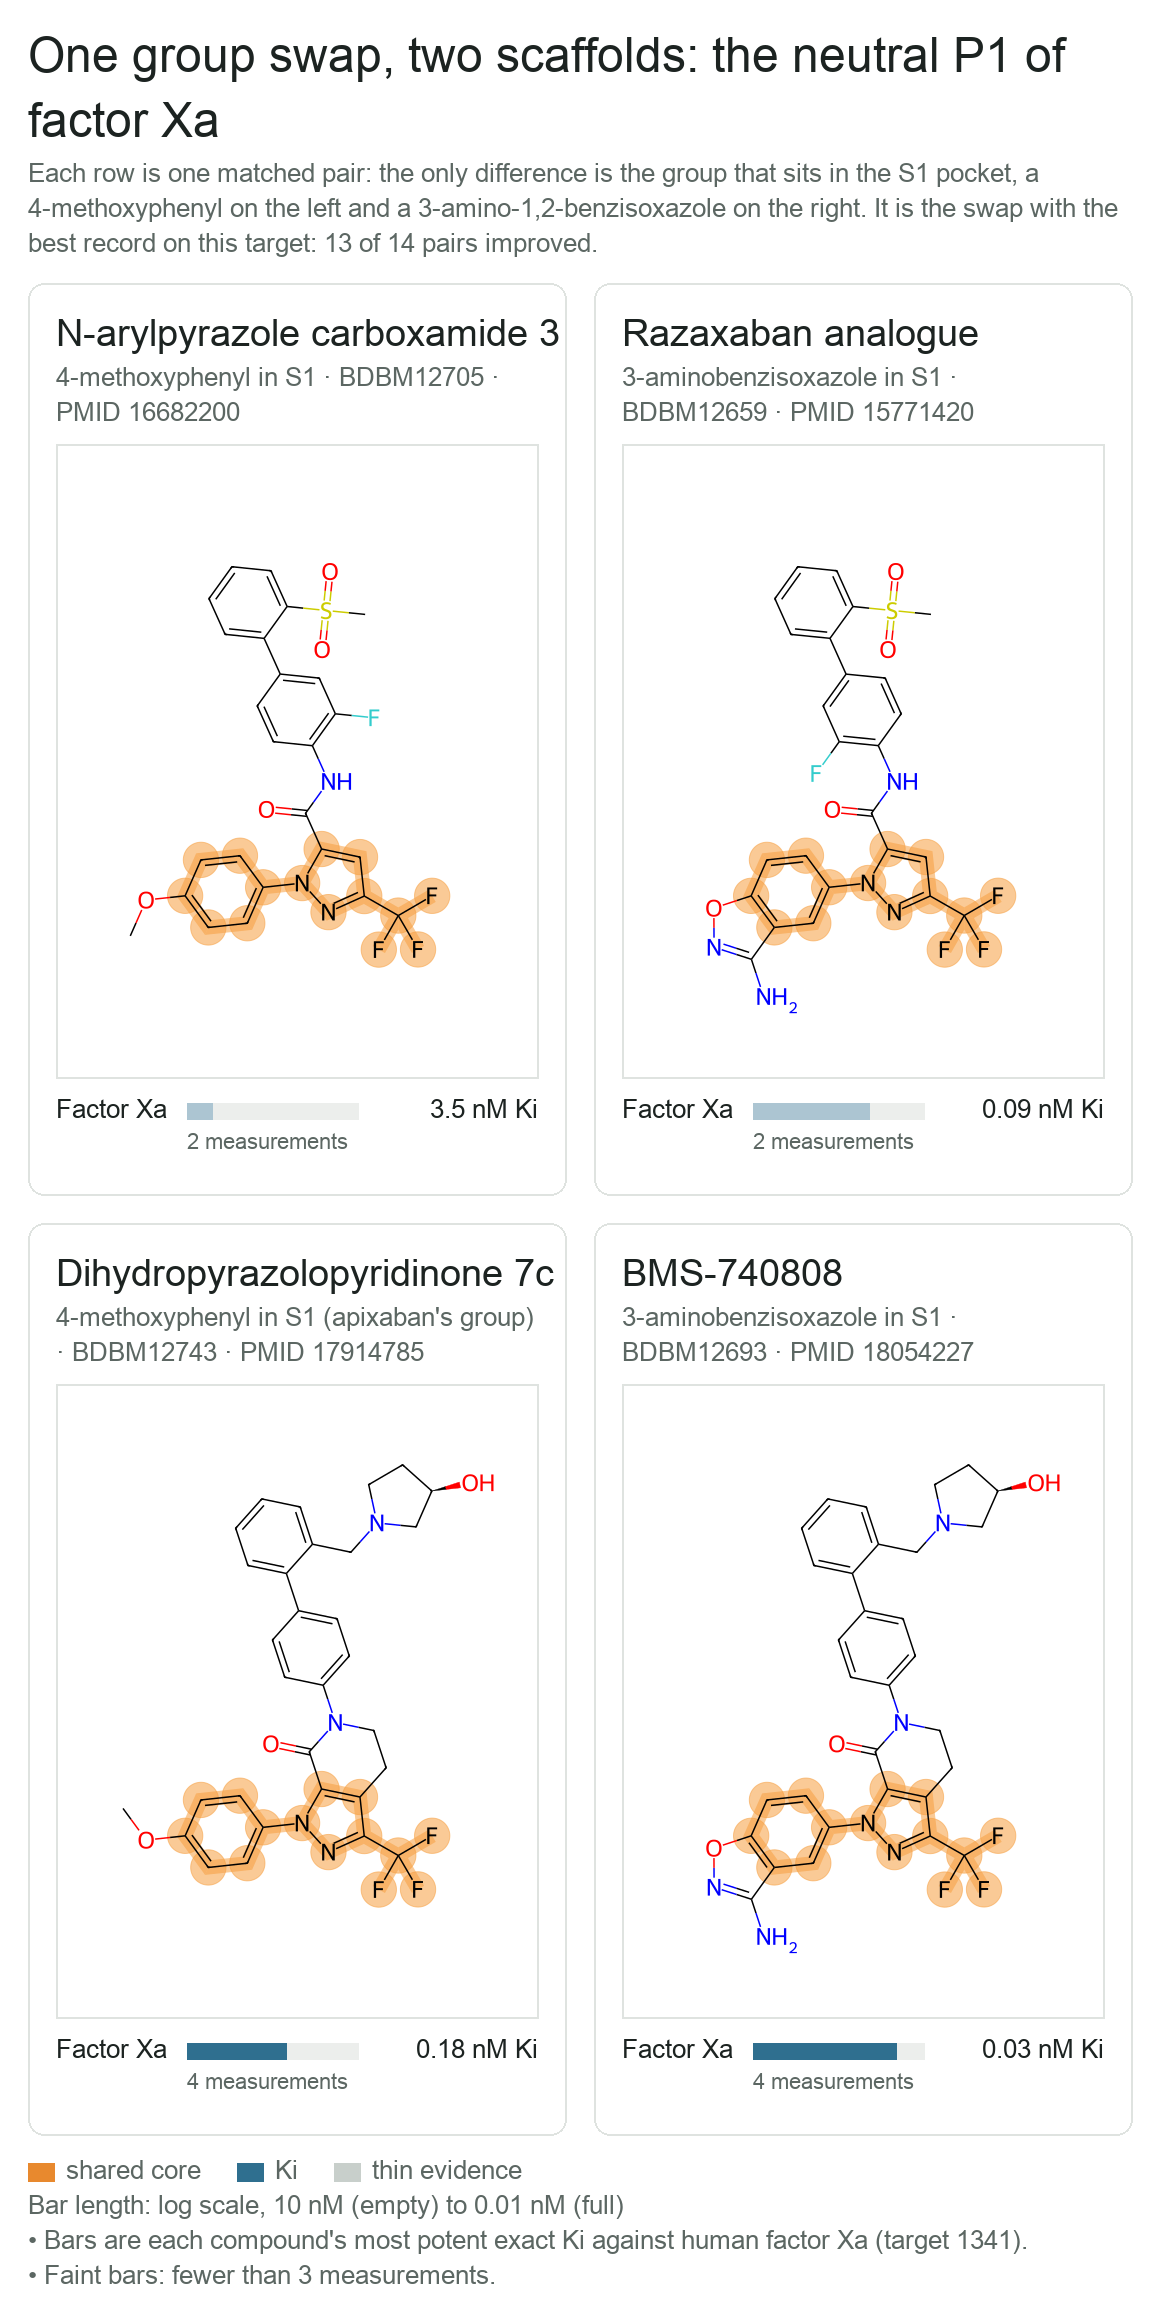

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'One group swap, two scaffolds: the neutral P1 of factor Xa',
    'compounds': [
        {
            'smiles': 'COc1ccc(cc1)-n1nc(cc1C(=O)Nc1ccc(cc1F)-c1ccccc1S(C)(=O)=O)C(F)(F)F',
            'title': 'N-arylpyrazole carboxamide 3',
            'subtitle': '4-methoxyphenyl in S1 · BDBM12705 · PMID 16682200',
            'bars': [
                {
                    'label': 'Factor Xa',
                    'value_nm': 3.5,
                    'type': 'Ki',
                    'note': '2 measurements',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CS(=O)(=O)c1ccccc1-c1ccc(NC(=O)c2cc(nn2-c2ccc3onc(N)c3c2)C(F)(F)F)c(F)c1',
            'title': 'Razaxaban analogue',
            'subtitle': '3-aminobenzisoxazole in S1 · BDBM12659 · PMID 15771420',
            'bars': [
                {
                    'label': 'Factor Xa',
                    'value_nm': 0.09,
                    'type': 'Ki',
                    'note': '2 measurements',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1ccc(cc1)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN1CC[C@@H](O)C1)C(F)(F)F',
            'title': 'Dihydropyrazolopyridinone 7c',
            'subtitle': "4-methoxyphenyl in S1 (apixaban's group) · BDBM12743 · PMID 17914785",
            'bars': [{'label': 'Factor Xa', 'value_nm': 0.18, 'type': 'Ki', 'note': '4 measurements'}],
        },
        {
            'smiles': 'Nc1noc2ccc(cc12)-n1nc(c2CCN(C(=O)c12)c1ccc(cc1)-c1ccccc1CN1CC[C@@H](O)C1)C(F)(F)F',
            'title': 'BMS-740808',
            'subtitle': '3-aminobenzisoxazole in S1 · BDBM12693 · PMID 18054227',
            'bars': [{'label': 'Factor Xa', 'value_nm': 0.03, 'type': 'Ki', 'note': '4 measurements'}],
        },
    ],
    'columns': 2,
    'description': 'Each row is one matched pair: the only difference is the group that sits in the S1 pocket, a 4-methoxyphenyl on the left and a 3-amino-1,2-benzisoxazole on the right. It is the swap with the best record on this target: 13 of 14 pairs improved.',
    'notes': [
        "Bars are each compound's most potent exact Ki against human factor Xa (target 1341).",
        'Faint bars: fewer than 3 measurements.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Among the 1,500 most potent compounds with an exact Ki against human factor Xa (target 1341, P00742), matched_molecular_pairs finds **9,442 pairs over 7,387 distinct transformations**. Keeping only the changes that swap a group of four or more heavy atoms for another leaves 264 of the 500 most frequent, and unlike the single-atom tweaks, several of them have a real record. The table gives the nine that matter most: the best records and the instructive losers among the ones made at least seven times.

| smaller group | SMILES | larger group | SMILES | Pairs | Improved | Median Δp | Best | Worst |
|---|---|---|---|---|---|---|---|---|
| 4-methoxyphenyl | COc1ccc([*:1])cc1 | 3-amino-1,2-benzisoxazol-5-yl | Nc1noc2ccc([*:1])cc12 | 14 | 13 | +0.89 (8×) | +1.64 (44×) | −0.08 |
| 2-oxopiperidin-1-yl | O=C1CCCCN1[*:1] | 2-oxopyridin-1-yl | O=c1ccccn1[*:1] | 12 | 11 | +0.70 (5×) | +1.96 (91×) | −0.69 |
| 4-methoxyphenyl | COc1ccc([*:1])cc1 | 3-(aminomethyl)phenyl | NCc1cccc([*:1])c1 | 7 | 6 | +0.46 | +1.36 | −0.21 |
| methanesulfonyl | CS(=O)(=O)[*:1] | (pyrrolidin-1-yl)methyl | C1CCN(C[*:1])C1 | 9 | 7 | +0.32 | +1.21 | −0.51 |
| dimethylaminomethyl | CN(C)C[*:1] | methanesulfonyl | CS(=O)(=O)[*:1] | 15 | 10 | +0.09 | +1.10 | −1.21 |
| 4-chlorophenyl | Clc1ccc([*:1])cc1 | 5-chloropyridin-2-yl | Clc1ccc([*:1])nc1 | 10 | 6 | +0.05 | +0.48 | −0.85 |
| methanesulfonyl | CS(=O)(=O)[*:1] | sulfamoyl | NS(=O)(=O)[*:1] | 22 | 6 | −0.23 | +0.60 | −1.05 |
| 5-chlorothiophen-2-yl | Clc1ccc([*:1])s1 | chloroindolyl | Clc1c[nH]c2cc([*:1])ccc12 | 20 | 6 | −0.28 | +0.86 | −0.93 |
| pyrrolidin-1-yl | C1CCN([*:1])C1 | morpholin-4-yl | C1CN([*:1])CCO1 | 11 | 1 | −0.43 | +0.25 | −1.02 |

Compare that with the single-atom changes on the same target, which are far more common and almost inert: hydrogen to methyl 119 pairs, median 0.00, 53 improved; hydrogen to fluorine 69 pairs, +0.02, 36 improved; hydrogen to chlorine 35 pairs, +0.19; methyl to trifluoromethyl 28 pairs, +0.20. A group swap is made a tenth as often and is worth reading one by one, because when it moves potency it moves it by a log unit, not by a rounding error.

**The top row is the S1 story of this whole target class.** Factor Xa's S1 pocket was addressed for years with a basic benzamidine; the programmes that produced oral drugs replaced it with neutral aryls, and the 3-amino-1,2-benzisoxazole is the one that kept the hydrogen-bonding pattern without the charge. In these pairs it beats a 4-methoxyphenyl in 13 of 14 matched compounds, by 8-fold at the median and 44-fold at best (6.9 → 0.16 nM). The figure shows the swap in two different scaffolds: an N-arylpyrazole carboxamide where it gives 3.5 → 0.09 nM (razaxaban's chemotype) and the bicyclic pyrazolopyridinone where it gives 0.18 → 0.03 nM (BMS-740808). The 14 pairs come from many different publications, so this is one long programme seen from many papers rather than one table copied twice. The figure's compounds are aligned on the aryl-pyrazole-trifluoromethyl part all four share; the swapped S1 group lies outside that common part.

A caution that goes with it: the swap that wins by far the most on this target is the opposite one. 4-methoxyphenyl to a 3-amidinophenyl, the old basic group, improved all 6 of its pairs by a median of +2.71 (about 500-fold, worst +2.33). A neutral group is what made oral drugs possible, not what makes the tightest binder, and that row is a reason the benzisoxazole's +0.89 is a good result and not a poor one.

**The second row is the P4 lactam**, and it is the same kind of result: flattening the saturated 2-oxopiperidine to an aromatic 2-oxopyridinone improved 11 of 12 pairs, median 5-fold. A clean pair in that set is a chloro-substituted carboxamide, 2.6 nM with the saturated lactam against 0.67 nM with the pyridinone.

**And the drug does neither.** Apixaban (BDBM19023, factor Xa Ki 0.075 nM from 15 exact values, thrombin 3.1 µM) carries both left-hand groups: the 4-methoxyphenyl in S1 and the 2-oxopiperidin-1-yl in P4. On this evidence each could have been swapped for something more potent. It was not, and that is the right reading of a matched-pair table: at 0.075 nM and about 40,000-fold selectivity over thrombin, potency had stopped being the problem, and a neutral, metabolically plain methoxyphenyl is easier to dose than an aminoisoxazole. Matched pairs rank changes on the one axis the database holds.

**What the negative rows are worth.** Pyrrolidine to morpholine lost potency in 10 of 11 pairs (median −0.43). That is a solubility move being paid for in affinity, visible here because somebody made both compounds; so is methanesulfonyl to sulfamoyl (6 of 22 improved). These are the rows a project actually needs: not "what helps" but "what this target will tolerate".

**How this was answered**
- search_targets for "coagulation factor X" in Homo sapiens gave target 1341 (P00742, 7,201 compounds); the tool picked Ki, its most measured exact type.
- matched_molecular_pairs with group_by_transformation: true, max_compounds: 1500 and limit: 500 returned one row per transformation with its pair count, median, best and worst change.
- Those rows were filtered to the ones whose two fragments both have at least four heavy atoms (the code cell below): the tool reports every transformation, including the single-atom ones, so "a group, not an atom" is a filter on the output.
- matched_molecular_pairs with transformation set to each of the three interesting swaps returned the individual pairs behind them, and draw_structure_grid drew two of the benzisoxazole pairs.

**Try next**
- "Did the same move work on thrombin?" (the follow-up below)
- "Which swaps improve factor Xa without touching thrombin?" (the same call on target 334, then compare the two transformation tables)

Example 4.4 runs two single-atom changes across seven target classes, which is the other half of this picture.

## Exchange 2

**👤 User**

The benzisoxazole is the neutral P1 that made oral factor Xa inhibitors possible. Did the same move work on thrombin, where the P1 was a benzamidine?

In [ ]:
# Call 10 · search_targets · ran 2026-11-24 04:56:16 UTC
await replay.call(10, 'search_targets', {'query': 'thrombin', 'organism': 'Homo sapiens'},
                  sha256='a2e3b6793dcf922ee5c42f6dec6cf9d86767a67ec4e93a61068a488aed2ef686')

**Call 10** · `search_targets` · recorded result · sha256 `a2e3b6793dcf…`

_13 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 5023 | Neutrophil elastase | P08246 | P08246 | Homo sapiens | Enzyme | 4695 | 3478 | Thrombin |
| polymer | 334 | Prothrombin | P00734 | P00734 | Homo sapiens | Protein | 10197 | 8290 | Prothrombin |
| polymer | 1529 | Serine protease 1 | P07477 | P07477 | Homo sapiens | Enzyme | 2401 | 2168 | Thrombin & trypsin |
| polymer | 364 | Proteinase-activated receptor 4 | Q96RI0 | Q96RI0 | Homo sapiens | Protein | 1805 | 1178 | Thrombin receptor-like 3 |
| polymer | 6553 | Proteinase-activated receptor 1 | P25116 | P25116 | Homo sapiens | Protein | 1329 | 1013 | Thrombin receptor |
| polymer | 1517 | Tissue-type plasminogen activator | P00750 | P00750 | Homo sapiens | Enzyme | 1280 | 1209 | Thrombin receptor protein |
| polymer | 1346 | Coagulation factor VII | P08709 | P08709 | Homo sapiens | Enzyme | 894 | 789 | Thrombin and coagulation factor VII |
| polymer | 5887 | Carboxypeptidase B2 | Q96IY4 | Q96IY4 | Homo sapiens | Enzyme | 430 | 393 | Thrombin-activable fibrinolysis inhibitor |
| polymer | 1568 | Vitamin K-dependent protein C | P04070 | P04070 | Homo sapiens | Enzyme | 395 | 344 | Autoprothrombin IIA |
| polymer | 6170 | Carboxypeptidase B | P15086 | P15086 | Homo sapiens | Enzyme | 91 | 90 | Thrombin-activatable fibrinolysis (TAFI) |
| polymer | 50000400 | Trypsin-3 | P35030 | P35030 | Homo sapiens | PROTEIN | 22 | 22 | Thrombin & trypsin |
| polymer | 50000015 | Antithrombin-III | P01008 | P01008 | Homo sapiens | PROTEIN | 21 | 21 | Antithrombin-III |
| polymer | 50000341 | Trypsin-2 | P07478 | P07478 | Homo sapiens | PROTEIN | 14 | 14 | Thrombin & trypsin |


In [ ]:
# Call 11 · matched_molecular_pairs · ran 2026-11-24 04:56:49 UTC
await replay.call(11, 'matched_molecular_pairs', {'target_id': 334, 'group_by_transformation': True, 'max_compounds': 1500, 'limit': 500},
                  sha256='7dbc249e4352a4cc29ce3939116d416af1b9bcbc5ce292a5070aa4281ac307fa')

**Call 11** · `matched_molecular_pairs` · recorded result · sha256 `7dbc249e4352…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 6431,
  "grouped_by": "transformation",
  "n_transformations": 4876,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_500 rows, truncated at the limit_

| transformation | n_pairs | median_delta_p_affinity | min_delta_p_affinity | max_delta_p_affinity | n_improved | best_monomerid_from | best_monomerid_to |
| --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 72 | 0.82 | -3.18 | 2.27 | 57 | 50337482 | 50337483 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 65 | 0.18 | -1.39 | 2.49 | 40 | 50126504 | 50126520 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 55 | 0.02 | -1.16 | 1.11 | 28 | 50130215 | 50130216 |
| \[H\]\[\*:1\] \>\> CO\[\*:1\] | 32 | 0.17 | -0.8 | 1 | 25 | 50080881 | 50080885 |
| C\[\*:1\] \>\> Cl\[\*:1\] | 20 | 0.03 | -0.82 | 0.6 | 11 | 50337457 | 50337456 |
| \[H\]\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 19 | 0.42 | -0.74 | 2.47 | 10 | 50228853 | 14073 |
| Cl\[\*:1\] \>\> CO\[\*:1\] | 19 | -0.16 | -0.67 | 1.12 | 6 | 50111721 | 50111714 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(\[\*:1\])nc1 | 18 | 0.38 | -0.78 | 1.06 | 14 | 50124097 | 50124093 |
| C1CCC(\[\*:1\])CC1 \>\> c1ccc(\[\*:1\])cc1 | 18 | -0.05 | -1.67 | 1.6 | 7 | 50072539 | 50072532 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])cc1 | 16 | 0.11 | -0.52 | 1.28 | 10 | 50072522 | 50072529 |
| \[H\]\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 15 | 0.29 | -0.06 | 0.77 | 13 | 50337469 | 50337470 |
| c1ccc(\[\*:1\])nc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 15 | 0.28 | -0.7 | 0.53 | 13 | 50172849 | 50172837 |
| \[H\]\[\*:1\] \>\> N\[\*:1\] | 15 | 0.08 | -0.87 | 1.3 | 8 | 50060705 | 50056773 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> Cc1nc(N)ccc1\[\*:1\] | 15 | -0.23 | -3.56 | 1.31 | 7 | 50069193 | 50069191 |
| c1ncn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 14 | 0.72 | -1.12 | 1.42 | 13 | 50337484 | 50337483 |
| O=C(O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 14 | 0.04 | -0.55 | 2.05 | 7 | 50126529 | 50126528 |
| \[H\]\[\*:1\] \>\> O\[\*:1\] | 13 | -0.08 | -0.33 | 1.2 | 5 | 50307856 | 50066340 |
| C\[\*:1\] \>\> CO\[\*:1\] | 12 | -0.2 | -0.98 | 0.33 | 3 | 50075935 | 50075938 |
| Cl\[\*:1\] \>\> N#C\[\*:1\] | 11 | 0.41 | -0.68 | 1.31 | 8 | 50223072 | 50377607 |
| Cl\[\*:1\] \>\> F\[\*:1\] | 11 | -0.03 | -1.45 | 0.56 | 5 | 50077042 | 50077058 |
| NC\[\*:1\] \>\> N=C(N)N\[\*:1\] | 10 | 0.78 | -0.31 | 1.79 | 9 | 50289590 | 50289587 |
| O=C(O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 10 | 0.18 | -2.19 | 2.13 | 6 | 50066335 | 50066338 |
| C1CCC(\[\*:1\])CC1 \>\> c1ccc(C\[\*:1\])cc1 | 10 | 0.1 | -1.08 | 1.3 | 6 | 50072539 | 50072533 |
| F\[\*:1\] \>\> CO\[\*:1\] | 10 | 0.05 | -0.48 | 0.78 | 7 | 50126310 | 50126297 |
| C\[\*:1\] \>\> CC(C)\[\*:1\] | 9 | 0.44 | 0.03 | 2.98 | 9 | 50126504 | 50126521 |
| C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 9 | 0.1 | -1.38 | 0.55 | 5 | 50288637 | 50288621 |
| N=C(N)NS(=O)(=O)\[\*:1\] \>\> NC(N)=NNS(=O)(=O)\[\*:1\] | 9 | 0.07 | -0.01 | 0.18 | 8 | 50087907 | 50087941 |
| CC\[\*:1\] \>\> C1CC1\[\*:1\] | 9 | 0.04 | -0.09 | 0.48 | 6 | 50149013 | 50149037 |
| c1ccc(\[\*:1\])nc1 \>\> c1cncc(\[\*:1\])c1 | 9 | 0 | -0.6 | 0.4 | 4 | 50149006 | 50149035 |
| N=C(N)NS(=O)(=O)\[\*:1\] \>\> COC(=N)NS(=O)(=O)\[\*:1\] | 9 | -0.1 | -0.18 | 0.03 | 1 | 50087993 | 50087884 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 9 | -0.3 | -1.01 | 0.22 | 3 | 50111105 | 50111101 |
| NC\[\*:1\] \>\> NN=C(N)\[\*:1\] | 8 | 1.36 | -1.07 | 2.04 | 7 | 50071722 | 50080882 |
| c1ccc(\[\*:1\])c(-n2cnnn2)c1 \>\> Clc1ccc(-n2cncn2)c(\[\*:1\])c1 | 8 | 1.03 | 0.26 | 1.63 | 8 | 50172848 | 50172826 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 8 | 0.33 | -0.48 | 0.91 | 7 | 50111724 | 50133529 |
| c1csc(\[\*:1\])n1 \>\> c1ccc2sc(\[\*:1\])nc2c1 | 8 | 0.26 | -0.26 | 1.02 | 4 | 14117 | 14063 |
| COC(=N)NS(=O)(=O)\[\*:1\] \>\> NC(N)=NNS(=O)(=O)\[\*:1\] | 8 | 0.17 | 0.09 | 0.28 | 8 | 50087994 | 50087941 |
| Br\[\*:1\] \>\> Cl\[\*:1\] | 8 | -0.06 | -1.24 | 1.42 | 4 | 50126514 | 50126525 |
| C1CCC(C(C2CCCCC2)\[\*:1\])CC1 \>\> c1ccc(C(c2ccccc2)\[\*:1\])cc1 | 8 | -0.23 | -1.17 | 0.85 | 3 | 50060711 | 50060705 |
| c1ccc(\[\*:1\])c(-n2cncn2)c1 \>\> Clc1ccc(-n2cnnn2)c(\[\*:1\])c1 | 7 | 2.5 | 0.51 | 2.75 | 7 | 50147815 | 50147793 |
| \[H\]\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 7 | 1.65 | 1.43 | 2.5 | 7 | 50172856 | 50172839 |
| COC(=O)N\[\*:1\] \>\> NS(=O)(=O)N\[\*:1\] | 7 | 0.93 | 0.05 | 1.85 | 7 | 50131777 | 50131798 |
| Clc1cccc(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 7 | 0.7 | 0 | 1.08 | 6 | 50172856 | 50172836 |
| CC(C)\[\*:1\] \>\> C1CCC(\[\*:1\])CC1 | 7 | 0.6 | -1.24 | 1.42 | 4 | 50126523 | 50126525 |
| C1CC1\[\*:1\] \>\> C1CC(\[\*:1\])C1 | 7 | 0.4 | -0.27 | 0.96 | 6 | 50126490 | 50126493 |
| C1CCC(\[\*:1\])CC1 \>\> COc1ccc(\[\*:1\])cc1 | 7 | 0.25 | -0.45 | 2.08 | 4 | 50126530 | 50126500 |
| \[H\]\[\*:1\] \>\> CC\[\*:1\] | 7 | 0.15 | -0.23 | 2.83 | 5 | 50034589 | 50034573 |
| Nc1ccc(\[\*:1\])cn1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 7 | 0.14 | -0.68 | 1.52 | 5 | 50069194 | 50069189 |
| C\[\*:1\] \>\> C1CC1\[\*:1\] | 7 | 0.13 | -1.52 | 0.88 | 4 | 50088656 | 50088660 |
| c1cc(\[\*:1\])ccn1 \>\> c1cncc(\[\*:1\])c1 | 7 | 0.05 | -0.81 | 0.47 | 4 | 50123505 | 50123479 |
| CC\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.05 | -0.55 | 1.13 | 3 | 50034583 | 50034581 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])nc1 | 7 | -0.11 | -0.81 | 0.77 | 2 | 50123505 | 50123496 |
| NC\[\*:1\] \>\> N=CN\[\*:1\] | 7 | -0.29 | -0.73 | -0.1 | 0 | 50069934 | 50069927 |
| N\[\*:1\] \>\> O\[\*:1\] | 7 | -0.43 | -2.11 | 0.59 | 2 | 253000 | 252990 |
| CCCc1ccc(\[\*:1\])cc1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 7 | -0.45 | -0.91 | -0.28 | 0 | 50069055 | 50069053 |
| Brc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])cc1Cl | 7 | -1.02 | -2.78 | 0.22 | 2 | 50126517 | 50126501 |
| C\[\*:1\] \>\> C1CCC(\[\*:1\])CC1 | 6 | 0.84 | -0.93 | 3.15 | 3 | 50126502 | 50126525 |
| \[H\]\[\*:1\] \>\> Br\[\*:1\] | 6 | 0.72 | -0.41 | 2.1 | 4 | 50126532 | 50126528 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(CC\[\*:1\])cc1 | 6 | 0.5 | -0.94 | 1.62 | 5 | 50072540 | 50072532 |
| NC\[\*:1\] \>\> c1nnnn1\[\*:1\] | 6 | 0.45 | 0.23 | 0.57 | 6 | 50133526 | 50147798 |
| C1CCC(\[\*:1\])CC1 \>\> Clc1ccc(\[\*:1\])cc1Cl | 6 | 0.15 | -0.44 | 2.58 | 3 | 50126530 | 50126508 |
| Clc1cccc(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cncn2)c1 | 6 | 0.04 | -0.14 | 0.4 | 3 | 50172856 | 50172857 |
| F\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 6 | -0.01 | -0.56 | 0.43 | 3 | 50288625 | 50288631 |
| \[H\]\[\*:1\] \>\> OC\[\*:1\] | 6 | -0.01 | -0.4 | 1.04 | 3 | 50307857 | 50505757 |
| N\[\*:1\] \>\> CC(C)(C)OC(=O)N\[\*:1\] | 6 | -0.02 | -0.57 | 0.44 | 3 | 50060748 | 50060755 |
| Br\[\*:1\] \>\> CO\[\*:1\] | 6 | -0.12 | -1.52 | 3 | 3 | 50034588 | 50034574 |
| c1cc2c(cc1\[\*:1\])CCCC2 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 6 | -0.58 | -0.79 | -0.26 | 0 | 50071726 | 50069053 |
| N=C(N)\[\*:1\] \>\> NN=C(N)\[\*:1\] | 6 | -1.75 | -4.19 | 1.25 | 2 | 50070783 | 50069294 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 5 | 2.78 | 2.42 | 3.53 | 5 | 50095186 | 50111120 |
| \[H\]\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 2.41 | 2.1 | 2.59 | 5 | 50122184 | 50147788 |
| NC\[\*:1\] \>\> N=C(N)\[\*:1\] | 5 | 2.12 | 0.43 | 3.12 | 5 | 50111116 | 50111101 |
| \[H\]\[\*:1\] \>\> NC\[\*:1\] | 5 | 1.88 | -0.43 | 3.15 | 4 | 50307857 | 50505754 |
| \[H\]\[\*:1\] \>\> NN\[\*:1\] | 5 | 1.76 | 1.56 | 1.92 | 5 | 50071726 | 50098243 |
| Clc1cccc(\[\*:1\])c1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 5 | 1.35 | 0.6 | 2.67 | 5 | 32654 | 32657 |
| N=CN\[\*:1\] \>\> N=C(N)N\[\*:1\] | 5 | 1.14 | -0.19 | 1.76 | 4 | 50288410 | 50288405 |
| \[H\]\[\*:1\] \>\> CCC\[\*:1\] | 5 | 1.13 | -3.35 | 2.07 | 3 | 50037972 | 50037984 |
| N\[\*:1\] \>\> O=S(=O)(Cc1ccccc1)N\[\*:1\] | 5 | 1.05 | 0.13 | 1.6 | 5 | 50056773 | 50056769 |
| Clc1cccc(\[\*:1\])c1 \>\> Clc1ccccc1\[\*:1\] | 5 | 0.67 | -0.99 | 1.22 | 3 | 50080916 | 50080924 |
| N=C(N)N1CCC(\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 5 | 0.59 | 0.13 | 0.82 | 5 | 50110384 | 50110392 |
| c1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])cc1Cl | 5 | 0.45 | -0.38 | 1.08 | 3 | 50126532 | 50126508 |
| C1CCC(\[\*:1\])CC1 \>\> Clc1ccc(\[\*:1\])cc1 | 5 | 0.28 | -0.47 | 2.45 | 3 | 50126530 | 50126526 |
| N=C(N)NN=C\[\*:1\] \>\> N=C(N)NOC\[\*:1\] | 5 | 0.21 | -0.16 | 0.6 | 3 | 50083969 | 50126647 |
| CCCc1ccc(\[\*:1\])cc1 \>\> c1cc2c(cc1\[\*:1\])CCCC2 | 5 | 0.2 | -0.02 | 0.31 | 4 | 50080880 | 50080884 |
| c1ccc(\[\*:1\])cc1 \>\> Cc1cc(C)cc(\[\*:1\])c1 | 5 | 0.17 | -0.7 | 0.38 | 3 | 50069932 | 50069937 |
| CCCc1ccc(\[\*:1\])cc1 \>\> COc1ccc2cc(\[\*:1\])ccc2c1 | 5 | 0.16 | -0.53 | 0.55 | 4 | 50080886 | 50080885 |
| COc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])cc1Cl | 5 | 0.12 | -0.44 | 0.67 | 4 | 50072537 | 50072528 |
| C1CCC(\[\*:1\])NC1 \>\> c1ccc(\[\*:1\])nc1 | 5 | 0.06 | -0.71 | 0.38 | 3 | 50337463 | 50337456 |
| \[H\]\[\*:1\] \>\> COC(=O)\[\*:1\] | 5 | -0.25 | -0.83 | 1.67 | 2 | 50337490 | 50337487 |
| N=C(N)NN=CC\[\*:1\] \>\> N=C(N)N1CCC(\[\*:1\])CC1 | 5 | -0.37 | -0.78 | 0.26 | 2 | 50083969 | 50070597 |
| F\[\*:1\] \>\> O\[\*:1\] | 5 | -0.49 | -0.78 | 0.2 | 1 | 50073282 | 50073293 |
| NS(=O)(=O)N\[\*:1\] \>\> O=C(O)CN\[\*:1\] | 5 | -0.63 | -1.74 | 0.2 | 1 | 50131797 | 50131787 |
| \[H\]\[\*:1\] \>\> O=C(O)\[\*:1\] | 5 | -0.8 | -1.02 | -0.3 | 0 | 14068 | 14072 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> NCc1ccc(\[\*:1\])cc1 | 5 | -1.2 | -2.9 | -0.78 | 0 | 50070784 | 50069053 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1ccc(\[\*:1\])s1 | 4 | 2.84 | 2.3 | 3.46 | 4 | 50095186 | 50131780 |
| Cl\[\*:1\] \>\> c1nnnn1\[\*:1\] | 4 | 1.84 | 1.7 | 3.12 | 4 | 50122188 | 50147788 |
| CNc1ccc(C#C\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1 | 4 | 1.7 | 1.6 | 2.65 | 4 | 50076725 | 50080882 |
| F\[\*:1\] \>\> c1nnnn1\[\*:1\] | 4 | 1.68 | 1.57 | 2.2 | 4 | 50126303 | 50147818 |
| Cl\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 4 | 1.35 | 1.08 | 2.18 | 4 | 50122188 | 50147810 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 4 | 1.33 | -0.48 | 1.46 | 3 | 50176236 | 50337454 |
| CC(C)\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 4 | 1.28 | -0.47 | 2.51 | 3 | 50034589 | 50034580 |
| NCc1ccc(\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])c(F)c1 | 4 | 1.21 | 0.96 | 1.52 | 4 | 50071722 | 50080885 |
| CNc1ccc(C#C\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])c(F)c1 | 4 | 1.02 | 0.98 | 2.13 | 4 | 50076725 | 50080885 |
| C1CCC(\[\*:1\])CC1 \>\> c1ccc(C(c2ccccc2)\[\*:1\])cc1 | 4 | 0.83 | 0.22 | 2.22 | 4 | 50111117 | 50111101 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1 | 4 | 0.69 | -3.97 | 0.91 | 3 | 50070780 | 50080882 |
| \[H\]\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.68 | -0.74 | 1.85 | 2 | 50292201 | 50292203 |
| C1CC1\[\*:1\] \>\> C1CC1C\[\*:1\] | 4 | 0.59 | 0.22 | 0.97 | 4 | 50126489 | 50126490 |
| NC(N)=NOC\[\*:1\] \>\> Cc1nc(N)ccc1\[\*:1\] | 4 | 0.54 | 0.04 | 1.11 | 4 | 50312651 | 50123504 |
| c1ccc(C\[\*:1\])cc1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 4 | 0.46 | 0.16 | 1.68 | 4 | 50098231 | 50098235 |
| Cc1nc(N)ccc1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 4 | 0.41 | 0.13 | 0.81 | 4 | 50110381 | 50110389 |
| O\[\*:1\] \>\> CN\[\*:1\] | 4 | 0.29 | -0.26 | 0.53 | 3 | 50073293 | 50073296 |
| c1cc2c(cc1\[\*:1\])CCCC2 \>\> COc1ccc2cc(\[\*:1\])ccc2c1 | 4 | 0.2 | -0.73 | 0.4 | 3 | 50080888 | 50080885 |
| COC(=O)N\[\*:1\] \>\> O=C(O)CN\[\*:1\] | 4 | 0.18 | -0.49 | 0.78 | 2 | 50131788 | 50131787 |
| O\[\*:1\] \>\> CO\[\*:1\] | 4 | 0.13 | 0.05 | 0.76 | 4 | 50075941 | 50075938 |
| NCc1ccc(\[\*:1\])cc1 \>\> CNc1ccc(C#C\[\*:1\])cc1 | 4 | 0.03 | -0.61 | 0.3 | 2 | 50071726 | 50076722 |
| C\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.01 | -0.58 | 0.4 | 2 | 50123503 | 50123486 |
| Nc1n\[nH\]c2ccc(\[\*:1\])cc12 \>\> Nc1noc2cc(\[\*:1\])ccc12 | 4 | 0.01 | -0.02 | 0.21 | 2 | 50105480 | 50215314 |
| O=C(O)\[\*:1\] \>\> O=C(O)C\[\*:1\] | 4 | 0.01 | -0.4 | 0.18 | 2 | 50131780 | 50131778 |
| CO\[\*:1\] \>\> N#C\[\*:1\] | 4 | -0.05 | -0.91 | 0.79 | 2 | 50337457 | 50337460 |
| C1CC1\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 4 | -0.09 | -0.31 | 0.65 | 2 | 50126489 | 50126488 |
| C1CC1\[\*:1\] \>\> C1CCC(\[\*:1\])CC1 | 4 | -0.2 | -0.85 | 0.75 | 1 | 50126489 | 50126491 |
| CO\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 4 | -0.23 | -0.63 | 0.4 | 1 | 50083964 | 50083968 |
| Cl\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 4 | -0.33 | -0.92 | 0.28 | 1 | 50083969 | 50083968 |
| N\[\*:1\] \>\> NC\[\*:1\] | 4 | -0.42 | -1.27 | 0.11 | 1 | 50133526 | 50133519 |
| CC\[\*:1\] \>\> C1CCC(\[\*:1\])CC1 | 4 | -0.43 | -0.75 | -0.26 | 0 | 50211566 | 50211577 |
| c1ccc(C\[\*:1\])cc1 \>\> c1ccc(O\[\*:1\])cc1 | 4 | -0.45 | -1.42 | 0.03 | 1 | 50288636 | 50288630 |
| CS(=O)(=O)N\[\*:1\] \>\> O=C(O)CN\[\*:1\] | 4 | -0.93 | -1.77 | -0.48 | 0 | 50111105 | 50131780 |
| NC1CCC(\[\*:1\])CC1 \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 4 | -1.48 | -1.48 | -0.22 | 0 | 50062628 | 50131476 |
| Cc1nc(N)ccc1\[\*:1\] \>\> Nc1noc2cc(\[\*:1\])ccc12 | 4 | -1.7 | -2.17 | -1.39 | 0 | 50377611 | 50377609 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])s1 | 4 | -2.53 | -3.38 | -1.13 | 0 | 50070783 | 50070781 |
| Fc1cccnc1\[\*:1\] \>\> Cc1nc(N)ccc1\[\*:1\] | 3 | 1.83 | 1.63 | 2 | 3 | 50123491 | 50123490 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> Cc1nc(N)ccc1\[\*:1\] | 3 | 1.82 | 1.2 | 1.91 | 3 | 50176236 | 50123496 |
| Cc1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])cc1 | 3 | 1.76 | -0.38 | 1.77 | 2 | 50126497 | 50126498 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])s1 | 3 | 1.73 | 1.66 | 1.94 | 3 | 50110377 | 50110393 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 3 | 1.7 | 0.49 | 2 | 3 | 50133525 | 50133529 |
| N=C(N)c1cc(\[\*:1\])cs1 \>\> N=C(N)c1ccc(\[\*:1\])s1 | 3 | 1.6 | 0.82 | 1.6 | 3 | 50131788 | 50131796 |
| N=C(N)c1csc(\[\*:1\])n1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 3 | 1.6 | 0.05 | 1.7 | 3 | 50131793 | 50111120 |
| O=C(c1nccs1)\[\*:1\] \>\> O=C(NCCc1ccccc1)C(=O)\[\*:1\] | 3 | 1.53 | 0.49 | 1.53 | 3 | 50076228 | 50076227 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 3 | 1.38 | 0.81 | 2.18 | 3 | 50176238 | 50067795 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1cc(\[\*:1\])cs1 | 3 | 1.37 | 0.7 | 2.64 | 3 | 50095186 | 50131787 |
| CO\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 3 | 1.36 | 1.16 | 1.56 | 3 | 50337490 | 50337488 |
| c1ccc(C\[\*:1\])cc1 \>\> FC(F)(c1ccccc1)\[\*:1\] | 3 | 1.34 | 0.9 | 1.51 | 3 | 50215316 | 50215314 |
| C1CCC(\[\*:1\])CC1 \>\> Brc1ccc(\[\*:1\])cc1 | 3 | 1.31 | -0.47 | 3.6 | 2 | 50126530 | 50126528 |
| N=C(N)c1cc(\[\*:1\])cs1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 3 | 1.3 | 0.89 | 1.72 | 3 | 50131797 | 50111110 |
| O=C(N1CCCC1)\[\*:1\] \>\> O=C(OC1CCCCC1)\[\*:1\] | 3 | 1.3 | -0.68 | 2.62 | 2 | 50126516 | 50126525 |
| N\[\*:1\] \>\> CCN(CC)C(=O)CN\[\*:1\] | 3 | 1.21 | 0.34 | 1.21 | 3 | 50066336 | 50066331 |
| O=C(O)CN\[\*:1\] \>\> O=S(=O)(Cc1ccccc1)N\[\*:1\] | 3 | 1.16 | 0.41 | 1.49 | 3 | 50211556 | 50211578 |
| c1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])nc1 | 3 | 1.15 | 0.6 | 1.41 | 3 | 50223072 | 50223066 |
| CC(C)\[\*:1\] \>\> C1CCC(C\[\*:1\])CC1 | 3 | 1.1 | 0.51 | 1.18 | 3 | 50392027 | 50324478 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 3 | 1.05 | 0.93 | 1.09 | 3 | 50133525 | 50111724 |
| F\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 3 | 1.03 | 0.9 | 1.04 | 3 | 50126302 | 50147826 |
| C1CC1\[\*:1\] \>\> C1CC(C\[\*:1\])C1 | 3 | 0.99 | 0.69 | 1.93 | 3 | 50126489 | 50126493 |
| \[H\]\[\*:1\] \>\> CN\[\*:1\] | 3 | 0.92 | -0.28 | 0.92 | 2 | 50073301 | 50073296 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 3 | 0.82 | 0.08 | 1.12 | 3 | 50095185 | 50060746 |
| C1CCC(C\[\*:1\])CC1 \>\> c1ccc(C(c2ccccc2)\[\*:1\])cc1 | 3 | 0.82 | 0.33 | 1.31 | 3 | 50324477 | 50111108 |
| Cc1nc(N)ccc1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])s1 | 3 | 0.82 | 0.7 | 1.82 | 3 | 50110381 | 50110393 |
| c1ncc(CC\[\*:1\])\[nH\]1 \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 3 | 0.75 | 0.15 | 0.75 | 3 | 50176239 | 50063562 |
| COC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 3 | 0.74 | 0.48 | 1 | 3 | 50111122 | 50111101 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> Nc1ccc(\[\*:1\])cn1 | 3 | 0.73 | -0.14 | 0.8 | 2 | 50176238 | 50067793 |
| NCc1ccc(\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1F | 3 | 0.72 | 0.52 | 1.05 | 3 | 50071726 | 50080884 |
| N\[C@H\](Cc1ccccc1)\[\*:1\] \>\> O=C(O)CN\[C@H\](CC1CCCCC1)\[\*:1\] | 3 | 0.69 | -1.82 | 1.77 | 2 | 50113786 | 50113785 |
| CNc1ccc(C#C\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1F | 3 | 0.64 | 0.54 | 0.75 | 3 | 50076722 | 50080884 |
| Nc1ccc(\[\*:1\])cn1 \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 3 | 0.6 | -0.34 | 0.6 | 2 | 50060751 | 50063562 |
| C\[\*:1\] \>\> FC(F)(F)CO\[\*:1\] | 3 | 0.54 | 0.34 | 0.55 | 3 | 50337467 | 50337470 |
| COC(=O)\[\*:1\] \>\> O=C(N1CCCC1)\[\*:1\] | 3 | 0.53 | 0.44 | 0.63 | 3 | 50126527 | 50126501 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> Nc1ccc(\[\*:1\])cn1 | 3 | 0.5 | 0 | 0.98 | 2 | 50095185 | 50060741 |
| c1ccc(\[\*:1\])cc1 \>\> c1cc2c(cc1\[\*:1\])CCO2 | 3 | 0.49 | 0.47 | 0.8 | 3 | 50215318 | 50215447 |
| CC(C)(C)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | 0.44 | 0.37 | 1 | 3 | 50307875 | 50085448 |
| c1ccc(\[\*:1\])cc1 \>\> COc1ccc(C\[\*:1\])cc1 | 3 | 0.44 | -0.79 | 0.7 | 2 | 50072530 | 50072537 |
| C\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | 0.4 | 0.08 | 0.64 | 3 | 50088656 | 50088655 |
| c1ccc(C\[\*:1\])cc1 \>\> c1cc2c(cc1\[\*:1\])CCO2 | 3 | 0.4 | 0.37 | 0.49 | 3 | 50110385 | 50110389 |
| c1ccc(C\[\*:1\])cc1 \>\> COc1ccc(\[\*:1\])cc1 | 3 | 0.39 | 0.38 | 0.44 | 3 | 50073301 | 50076830 |
| c1ccc(\[\*:1\])cc1 \>\> c1cc2c(cc1\[\*:1\])OCO2 | 3 | 0.37 | 0.33 | 1.55 | 3 | 50060707 | 50060708 |
| C1CC(\[\*:1\])C1 \>\> C1CC1C\[\*:1\] | 3 | 0.3 | -0.42 | 0.68 | 2 | 50126487 | 50126486 |
| O=C(O)\[\*:1\] \>\> O=C(OC1CCCCC1)\[\*:1\] | 3 | 0.29 | -0.6 | 2.75 | 2 | 50126535 | 50126525 |
| Clc1ccc(Cl)c(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 3 | 0.24 | 0.21 | 1.23 | 3 | 50122188 | 50147798 |
| COc1ccc(Cl)cc1\[\*:1\] \>\> COc1ccc(C#N)c(\[\*:1\])c1 | 3 | 0.22 | 0.1 | 0.42 | 3 | 50337463 | 50337465 |
| Clc1cccc(\[\*:1\])c1Cl \>\> FC(F)(F)c1ccccc1\[\*:1\] | 3 | 0.19 | -0.26 | 0.33 | 2 | 50083961 | 50083968 |
| Cl\[\*:1\] \>\> FC(F)(F)CO\[\*:1\] | 3 | 0.18 | 0.14 | 0.39 | 3 | 50337468 | 50337470 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> NN=C(N)c1ccc(\[\*:1\])c(F)c1 | 3 | 0.18 | -0.07 | 0.39 | 2 | 50070780 | 50080885 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> NN=C(N)c1ccc(\[\*:1\])s1 | 3 | 0.15 | -0.54 | 0.69 | 2 | 50095190 | 50111099 |
| C1CC1\[\*:1\] \>\> CCC\[\*:1\] | 3 | 0.14 | -0.11 | 1.27 | 2 | 50070828 | 50070823 |
| Cc1cccc(\[\*:1\])c1 \>\> FC(F)(F)c1ccccc1\[\*:1\] | 3 | 0.14 | -0.66 | 0.41 | 2 | 50084081 | 50084068 |
| c1ccc(\[\*:1\])cc1 \>\> c1cncc(\[\*:1\])c1 | 3 | 0.14 | -0.7 | 0.17 | 2 | 50067797 | 50123479 |
| C1CCC(\[\*:1\])C1 \>\> C1CCC(\[\*:1\])CC1 | 3 | 0.13 | 0.05 | 0.66 | 3 | 50113795 | 50113798 |
| C1CC1\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | 0.12 | 0.12 | 0.19 | 3 | 50070825 | 50070827 |
| CC(C)(c1ccccc1)\[\*:1\] \>\> Cc1cc(C)cc(C\[\*:1\])c1 | 3 | 0.11 | -0.98 | 0.51 | 2 | 50069925 | 50069937 |
| CS(=O)(=O)N\[\*:1\] \>\> NS(=O)(=O)N\[\*:1\] | 3 | 0.1 | 0 | 0.51 | 2 | 50095190 | 50095188 |
| C1CC1\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 3 | 0.08 | -0.83 | 1.03 | 2 | 50126489 | 50126498 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 3 | 0.08 | -1.06 | 0.16 | 2 | 50076836 | 50076829 |
| CC(C)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | 0.05 | 0.04 | 0.8 | 3 | 50150296 | 50150299 |
| C\[\*:1\] \>\> N\[\*:1\] | 3 | 0.05 | -0.2 | 0.43 | 2 | 50111107 | 50111115 |
| N\[\*:1\] \>\> CN\[\*:1\] | 3 | 0.03 | -1.56 | 0.51 | 2 | 50073295 | 50073296 |
| N\[\*:1\] \>\> CO\[\*:1\] | 3 | 0.03 | -0.45 | 1.11 | 2 | 50126648 | 50126642 |
| N\[C@H\](Cc1ccccc1)\[\*:1\] \>\> O=S(=O)(Cc1ccccc1)NC\[\*:1\] | 3 | 0.03 | -0.53 | 0.72 | 2 | 50133517 | 50392025 |
| Nc1ccc(\[\*:1\])cc1 \>\> Nc1cccc(\[\*:1\])c1 | 3 | 0.03 | 0.02 | 0.06 | 3 | 50089120 | 50089117 |
| c1ccc(\[\*:1\])nc1 \>\> Oc1ccc(\[\*:1\])cc1 | 3 | 0.03 | 0.02 | 0.3 | 3 | 50076822 | 50076824 |
| c1ccc(C2(\[\*:1\])CC2)cc1 \>\> Cc1cc(C)cc(C(C)(C)\[\*:1\])c1 | 3 | 0.02 | -0.7 | 0.2 | 2 | 50069923 | 50069929 |
| CC(C)(c1ccccc1)\[\*:1\] \>\> c1ccc(C2(\[\*:1\])CC2)cc1 | 3 | 0 | -0.07 | 0.16 | 1 | 50069925 | 50069923 |
| COc1ccc(\[\*:1\])cc1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 3 | 0 | -0.28 | 0.15 | 1 | 50080905 | 50080895 |
| C\[\*:1\] \>\> F\[\*:1\] | 3 | 0 | -0.96 | 0.44 | 1 | 50126312 | 50126302 |
| Cc1ccc(Cl)cc1\[\*:1\] \>\> COc1ccc(C#N)c(\[\*:1\])c1 | 3 | 0 | -0.16 | 0.1 | 1 | 50337464 | 50337465 |
| CC(C)\[\*:1\] \>\> CCC\[\*:1\] | 3 | -0.01 | -0.34 | 0.88 | 1 | 50149036 | 50149017 |
| Br\[\*:1\] \>\> C\[\*:1\] | 3 | -0.04 | -0.62 | 0.04 | 1 | 50075931 | 50075935 |
| CC\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.04 | -1.25 | -0.03 | 0 | 50080904 | 50080900 |
| C1CCC(C\[\*:1\])NC1 \>\> \[O-\]\[n+\]1ccccc1C(F)(F)\[\*:1\] | 3 | -0.07 | -0.95 | 0.13 | 1 | 50172833 | 50172837 |
| c1ccc(\[\*:1\])cc1 \>\> COc1ccc(\[\*:1\])cc1OC | 3 | -0.08 | -0.1 | 0.17 | 1 | 50110391 | 50110392 |
| Cl\[\*:1\] \>\> CC\[\*:1\] | 3 | -0.11 | -0.52 | 0.11 | 1 | 50126644 | 50126645 |
| N\[C@H\](Cc1ccccc1)\[\*:1\] \>\> C\[C@@H\](NS(=O)(=O)Cc1ccccc1)\[\*:1\] | 3 | -0.12 | -0.68 | 0.18 | 1 | 50133517 | 50392026 |
| \[H\]\[\*:1\] \>\> CN(C)\[\*:1\] | 3 | -0.12 | -0.33 | 1.42 | 1 | 50098241 | 50098245 |
| c1ccc(C\[\*:1\])cc1 \>\> CC(C)(c1ccccc1)\[\*:1\] | 3 | -0.13 | -0.14 | 0.06 | 1 | 50069924 | 50069931 |
| Cc1cccc(\[\*:1\])c1 \>\> Clc1ccccc1\[\*:1\] | 3 | -0.14 | -0.5 | 0.9 | 1 | 50084081 | 50070597 |
| Cc1cc(C)cc(C\[\*:1\])c1 \>\> Cc1cc(C)cc(C(C)(C)\[\*:1\])c1 | 3 | -0.15 | -0.16 | 0.28 | 1 | 50069938 | 50069935 |
| Cc1ccnc(\[\*:1\])c1 \>\> Fc1cccnc1\[\*:1\] | 3 | -0.15 | -0.17 | 0 | 0 | 50123487 | 50123494 |
| C1CCC(C\[\*:1\])NC1 \>\> FC(F)(C1CCCCN1)\[\*:1\] | 3 | -0.18 | -0.29 | 0.15 | 1 | 50172848 | 50172835 |
| Cc1cc(C)cc(C\[\*:1\])c1 \>\> c1ccc(C2(\[\*:1\])CC2)cc1 | 3 | -0.18 | -0.35 | 0.98 | 1 | 50069938 | 50069928 |
| Cc1cccc(\[\*:1\])c1 \>\> Clc1cccc(\[\*:1\])c1Cl | 3 | -0.19 | -0.4 | 0.22 | 1 | 50084081 | 50084078 |
| C\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 3 | -0.23 | -0.28 | 0.03 | 1 | 50077044 | 50077053 |
| NC(N)=NOC\[\*:1\] \>\> Nc1noc2cc(\[\*:1\])ccc12 | 3 | -0.29 | -0.66 | -0.15 | 0 | 50312654 | 50216992 |
| N\[\*:1\] \>\> O=C(O)CN\[\*:1\] | 3 | -0.31 | -0.56 | 0.13 | 1 | 50118721 | 50118737 |
| CCC\[\*:1\] \>\> C1CCC(\[\*:1\])CC1 | 3 | -0.32 | -0.42 | 0.11 | 1 | 50080904 | 50080907 |
| N#C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 3 | -0.34 | -0.5 | -0.08 | 0 | 50126650 | 50126635 |
| C1CCC(\[\*:1\])CC1 \>\> C1CCC(C\[\*:1\])CC1 | 3 | -0.35 | -0.4 | 1.4 | 1 | 50111117 | 50111102 |
| Clc1ccc(Cl)c(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cncn2)c1 | 3 | -0.38 | -0.47 | 0.52 | 1 | 50122188 | 50147795 |
| FC(F)(F)c1ccccc1\[\*:1\] \>\> c1ccc2c(\[\*:1\])cccc2c1 | 3 | -0.39 | -1 | 0.16 | 1 | 50072524 | 50072536 |
| NN=C(N)c1ccc(\[\*:1\])c(F)c1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1F | 3 | -0.41 | -0.44 | -0.25 | 0 | 50080888 | 50080884 |
| Clc1ccc(Cl)c(\[\*:1\])c1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 3 | -0.52 | -0.52 | 1.86 | 1 | 50122188 | 50069189 |
| NC\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 3 | -0.54 | -1.02 | -0.14 | 0 | 50133526 | 50147795 |
| Nc1ccc(\[\*:1\])cn1 \>\> Nc1noc2cc(\[\*:1\])ccc12 | 3 | -0.83 | -0.99 | -0.24 | 0 | 50377612 | 50377609 |
| Cl\[\*:1\] \>\> N\[\*:1\] | 3 | -1.06 | -1.62 | 0.08 | 1 | 50084075 | 50084077 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> CNc1ccc(C#C\[\*:1\])cc1 | 3 | -1.12 | -1.74 | -0.8 | 0 | 50070784 | 50076724 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCCc1ccc(Cl)cc1\[\*:1\] | 3 | -1.19 | -1.75 | 0.87 | 1 | 50111724 | 50133521 |
| CC(C)OC(=O)\[\*:1\] \>\> O=C(N1CCCC1)\[\*:1\] | 3 | -1.2 | -2.54 | 0.46 | 1 | 50126533 | 50126501 |
| O=C(O)C(=O)\[\*:1\] \>\> O=C(c1nccs1)\[\*:1\] | 3 | -1.39 | -1.56 | -0.95 | 0 | 50118739 | 50118737 |
| NC1CCC(\[\*:1\])CC1 \>\> Nc1ccc(\[\*:1\])cn1 | 3 | -1.48 | -2.08 | -1.16 | 0 | 50057826 | 50060760 |
| NCc1ccc(Cl)cc1\[\*:1\] \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 3 | -1.49 | -1.87 | -1.17 | 0 | 50133524 | 50147812 |
| NC1CCC(\[\*:1\])CC1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 3 | -1.84 | -2 | -1.34 | 0 | 50057827 | 50060746 |
| Cc1nc(N)ccc1\[\*:1\] \>\> Nc1n\[nH\]c2ccc(\[\*:1\])cc12 | 3 | -2.05 | -2.16 | -1.61 | 0 | 50123504 | 50105480 |
| N\[\*:1\] \>\> CC(=O)N\[\*:1\] | 3 | -2.06 | -3.37 | -2.04 | 0 | 50287476 | 50287475 |
| c1ccc(\[\*:1\])cc1 \>\> Clc1ccc(-n2cnnn2)c(\[\*:1\])c1 | 2 | 3.89 | 3.85 | 3.93 | 2 | 50147803 | 50147824 |
| Clc1cccnc1\[\*:1\] \>\> Clc1ccc(-n2cnnn2)c(\[\*:1\])c1 | 2 | 3.6 | 3.46 | 3.75 | 2 | 50123485 | 50147824 |
| Fc1cccnc1\[\*:1\] \>\> Clc1ccc(-n2cnnn2)c(\[\*:1\])c1 | 2 | 3.53 | 3.49 | 3.57 | 2 | 50123494 | 50147824 |
| Fc1ccccc1\[\*:1\] \>\> Clc1ccc(-n2cnnn2)c(\[\*:1\])c1 | 2 | 3.44 | 3.36 | 3.53 | 2 | 50126305 | 50147824 |
| Fc1cccnc1\[\*:1\] \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 3.07 | 2.96 | 3.18 | 2 | 50292184 | 50292202 |
| c1ccc(\[\*:1\])nc1 \>\> COc1ccc2nc(\[\*:1\])sc2c1 | 2 | 2.78 | 2.78 | 2.78 | 2 | 14110 | 14123 |
| c1ccc(\[\*:1\])nc1 \>\> Fc1ccc2nc(\[\*:1\])sc2c1 | 2 | 2.75 | 2.75 | 2.75 | 2 | 14110 | 14125 |
| c1ccc(\[\*:1\])nc1 \>\> c1ccc2sc(\[\*:1\])nc2c1 | 2 | 2.64 | 2.63 | 2.65 | 2 | 50228855 | 50228853 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 2.42 | 2.24 | 2.61 | 2 | 50176238 | 50133520 |
| c1cnc(\[\*:1\])c(-n2cncn2)c1 \>\> Clc1ccc(-n2cnnn2)c(\[\*:1\])c1 | 2 | 2.37 | 2.06 | 2.67 | 2 | 50147806 | 50147824 |
| Clc1cccc(C\[\*:1\])c1 \>\> NCCCC\[C@@H\](C(=O)C(=O)O)\[\*:1\] | 2 | 2.33 | 1.8 | 2.85 | 2 | 50307857 | 50118719 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1ccc(\[\*:1\])cn1 | 2 | 2.32 | 1.72 | 2.92 | 2 | 50095189 | 50131792 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> NC1CCC(\[\*:1\])CC1 | 2 | 2.27 | 2.08 | 2.46 | 2 | 50095185 | 50057827 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])s1 | 2 | 2.27 | 1.9 | 2.64 | 2 | 50176238 | 50111729 |
| Nc1ccc(\[\*:1\])cn1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 2.09 | 1.81 | 2.38 | 2 | 50069194 | 50133529 |
| Cl\[\*:1\] \>\> NC\[\*:1\] | 2 | 2.06 | 1.41 | 2.72 | 2 | 50122188 | 50133529 |
| \[H\]\[\*:1\] \>\> O=C(CO\[\*:1\])NC1CC1 | 2 | 2.05 | 1.81 | 2.3 | 2 | 50337455 | 50337452 |
| Cc1nc(\[\*:1\])sc1C(=O)O \>\> c1ccc2sc(\[\*:1\])nc2c1 | 2 | 2.04 | 2.04 | 2.05 | 2 | 50374310 | 50374316 |
| N\[C@H\](Cc1ccccc1)\[\*:1\] \>\> CS(=O)(=O)N\[C@H\](CC1CCCCC1)\[\*:1\] | 2 | 2.02 | 1.74 | 2.3 | 2 | 50307877 | 50111102 |
| CC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 2.01 | 1.72 | 2.3 | 2 | 50111125 | 50111099 |
| \[H\]\[\*:1\] \>\> CCNC(=O)CO\[\*:1\] | 2 | 1.99 | 1.73 | 2.25 | 2 | 50122184 | 50122190 |
| Nc1ccc(\[\*:1\])cn1 \>\> N=C(N)c1ccc(\[\*:1\])s1 | 2 | 1.94 | 1.84 | 2.04 | 2 | 50069194 | 50111741 |
| Clc1ccc(Cl)c(\[\*:1\])c1 \>\> \[H\]/N=C(\\N)c1ccc(\[\*:1\])cc1 | 2 | 1.92 | 1.92 | 1.92 | 2 | 50063562 | 50111104 |
| CO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 2 | 1.9 | 1.78 | 2.03 | 2 | 50123506 | 50147822 |
| O=C\[\*:1\] \>\> COc1ccc2nc(C(=O)\[\*:1\])sc2c1 | 2 | 1.85 | 1.59 | 2.11 | 2 | 14130 | 14123 |
| Clc1cccnc1\[\*:1\] \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 2 | 1.84 | 1.76 | 1.92 | 2 | 50123485 | 50147821 |
| O=C\[\*:1\] \>\> O=C(c1nc2ccc(F)cc2s1)\[\*:1\] | 2 | 1.82 | 1.56 | 2.08 | 2 | 14130 | 14125 |
| c1ccc(\[\*:1\])nc1 \>\> COC(=O)c1ccc2nc(\[\*:1\])sc2c1 | 2 | 1.82 | 1.82 | 1.82 | 2 | 14110 | 14128 |
| Cl\[\*:1\] \>\> CCNC(=O)CO\[\*:1\] | 2 | 1.8 | 0.83 | 2.78 | 2 | 50122188 | 50122190 |
| Fc1cccnc1\[\*:1\] \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 2 | 1.77 | 1.74 | 1.79 | 2 | 50126316 | 50147812 |
| O=C(N1CCOCC1)\[\*:1\] \>\> O=C(OC1CCCCC1)\[\*:1\] | 2 | 1.77 | 1.41 | 2.13 | 2 | 50126519 | 50126525 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1csc(\[\*:1\])c1 | 2 | 1.76 | 1.6 | 1.92 | 2 | 50095189 | 50131779 |
| Cn1c(\[\*:1\])nc2ccccc21 \>\> COc1ccc2nc(\[\*:1\])sc2c1 | 2 | 1.76 | 1.76 | 1.76 | 2 | 14114 | 14123 |
| Cc1ccnc(\[\*:1\])c1 \>\> Cc1nc(N)ccc1\[\*:1\] | 2 | 1.75 | 1.68 | 1.83 | 2 | 50123484 | 50123490 |
| Cn1c(\[\*:1\])nc2ccccc21 \>\> Fc1ccc2nc(\[\*:1\])sc2c1 | 2 | 1.73 | 1.73 | 1.73 | 2 | 14114 | 14125 |
| O=C\[\*:1\] \>\> O=C(c1nc2ccccc2s1)\[\*:1\] | 2 | 1.71 | 1.46 | 1.96 | 2 | 14130 | 14063 |
| \[H\]\[\*:1\] \>\> C1CCC(\[\*:1\])CC1 | 2 | 1.67 | 1.62 | 1.71 | 2 | 50392031 | 50324477 |
| CNc1ccc(C#C\[\*:1\])cc1 \>\> NNC(N)c1ccc(\[\*:1\])cc1 | 2 | 1.66 | 1.62 | 1.7 | 2 | 50076724 | 50098235 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 1.65 | 1.33 | 1.96 | 2 | 50176238 | 50111726 |
| CCOC(=O)c1csc(\[\*:1\])n1 \>\> COc1ccc2nc(\[\*:1\])sc2c1 | 2 | 1.5 | 1.5 | 1.5 | 2 | 14119 | 14123 |
| CCOC(=O)c1csc(\[\*:1\])n1 \>\> Fc1ccc2nc(\[\*:1\])sc2c1 | 2 | 1.47 | 1.47 | 1.47 | 2 | 14119 | 14125 |
| C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 1.39 | 1.38 | 1.4 | 2 | 50111736 | 50133520 |
| N=C(N)c1cc(\[\*:1\])co1 \>\> N=C(N)c1ccc(\[\*:1\])s1 | 2 | 1.33 | 0.7 | 1.97 | 2 | 50131777 | 50131796 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1csc(\[\*:1\])n1 | 2 | 1.32 | 0.82 | 1.83 | 2 | 50095186 | 50131793 |
| Nc1ccc(\[\*:1\])cn1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 1.31 | 1.16 | 1.47 | 2 | 50069194 | 50111724 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> N=C(N)c1cc(\[\*:1\])co1 | 2 | 1.3 | 1 | 1.6 | 2 | 50095188 | 50131798 |
| Cl\[\*:1\] \>\> O=C(CO\[\*:1\])NC1CC1 | 2 | 1.3 | 0.91 | 1.7 | 2 | 50337454 | 50337452 |
| N=C(N)c1cc(\[\*:1\])cs1 \>\> N=C(N)c1ccc(\[\*:1\])cn1 | 2 | 1.29 | 1.02 | 1.55 | 2 | 50131788 | 50131792 |
| c1ccc(\[\*:1\])nc1 \>\> CCOC(=O)c1csc(\[\*:1\])n1 | 2 | 1.28 | 1.28 | 1.28 | 2 | 14110 | 14119 |
| \[H\]\[\*:1\] \>\> O=C(NC1CCCNC1)\[\*:1\] | 2 | 1.27 | 1.2 | 1.33 | 2 | 50337490 | 50337486 |
| NC1=NC\[C@H\](\[\*:1\])CN1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 1.25 | 1.17 | 1.34 | 2 | 50111739 | 50133529 |
| N=C(N)c1cc(\[\*:1\])co1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 1.24 | 0.82 | 1.67 | 2 | 50131777 | 50111122 |
| C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])s1 | 2 | 1.23 | 1.04 | 1.43 | 2 | 50111736 | 50111729 |
| Cc1ccnc(\[\*:1\])c1F \>\> Cc1nc(N)ccc1\[\*:1\] | 2 | 1.23 | 1.08 | 1.38 | 2 | 50123503 | 50123490 |
| O=C(NCc1ncccc1F)\[\*:1\] \>\> OC(NCc1cccc(Cl)c1)\[\*:1\] | 2 | 1.22 | 1.16 | 1.28 | 2 | 50292184 | 50292189 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1cc2cc(\[\*:1\])ncc2\[nH\]1 | 2 | 1.21 | 1.15 | 1.26 | 2 | 50176236 | 50124086 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 2 | 1.21 | 1.14 | 1.27 | 2 | 50176242 | 50067795 |
| Clc1cccnc1\[\*:1\] \>\> c1ccc(\[\*:1\])c(-n2cncn2)c1 | 2 | 1.19 | 1.14 | 1.25 | 2 | 50123485 | 50147790 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> NC1=NC\[C@H\](\[\*:1\])CN1 | 2 | 1.17 | 0.9 | 1.44 | 2 | 50176238 | 50111742 |
| \[H\]\[\*:1\] \>\> NCC\[\*:1\] | 2 | 1.16 | 0.16 | 2.15 | 2 | 50122184 | 50133521 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> Clc1ccc(-n2cncn2)c(\[\*:1\])c1 | 2 | 1.14 | 0.57 | 1.7 | 2 | 50176226 | 50147810 |
| Nc1cc(\[\*:1\])cc(N)n1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 1.13 | 0.85 | 1.41 | 2 | 50511169 | 50085448 |
| Fc1cccnc1\[\*:1\] \>\> c1ccc(\[\*:1\])c(-n2cncn2)c1 | 2 | 1.12 | 1.07 | 1.17 | 2 | 50126316 | 50147826 |
| c1ncc(CC\[\*:1\])\[nH\]1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 2 | 1.12 | 0.23 | 2.01 | 2 | 50176240 | 50069189 |
| CN\[\*:1\] \>\> O=S(=O)(Cc1ccccc1)N\[\*:1\] | 2 | 1.1 | 1.09 | 1.1 | 2 | 50056771 | 50056774 |
| Clc1cccc(\[\*:1\])c1 \>\> Cc1nc(N)ccc1\[\*:1\] | 2 | 1.1 | 1.05 | 1.15 | 2 | 50122184 | 50067796 |
| NC1=NC\[C@H\](\[\*:1\])CN1 \>\> N=C(N)c1ccc(\[\*:1\])s1 | 2 | 1.1 | 1 | 1.2 | 2 | 50111742 | 50111729 |
| c1ccc(O\[\*:1\])cc1 \>\> FC(F)(F)c1ccccc1C\[\*:1\] | 2 | 1.1 | 0.71 | 1.5 | 2 | 50072521 | 50072524 |
| N=C(N)NCCC\[\*:1\] \>\> NCCCC\[C@@H\](C(=O)C(=O)O)\[\*:1\] | 2 | 1.09 | 1.02 | 1.16 | 2 | 50073316 | 50118728 |
| \[H\]\[\*:1\] \>\> N#CC\[\*:1\] | 2 | 1.05 | 0.95 | 1.15 | 2 | 50069168 | 50069150 |
| C1CCC(\[\*:1\])CC1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 2 | 1.04 | 0.4 | 1.68 | 2 | 50072539 | 50072534 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] | 2 | 1.03 | 0.86 | 1.21 | 2 | 50176238 | 50111736 |
| N=C(N)c1cc(\[\*:1\])co1 \>\> N=C(N)c1ccc(\[\*:1\])cn1 | 2 | 1.02 | 0.12 | 1.92 | 2 | 50131777 | 50131792 |
| c1ccc(\[\*:1\])nc1 \>\> Cn1c(\[\*:1\])nc2ccccc21 | 2 | 1.02 | 1.02 | 1.02 | 2 | 14110 | 14114 |
| NCc1ccccc1\[\*:1\] \>\> Clc1ccc(-n2cncn2)c(\[\*:1\])c1 | 2 | 1 | 0.49 | 1.52 | 2 | 50133526 | 50147810 |
| c1cncc(\[\*:1\])c1 \>\> c1cnc2c(\[\*:1\])cccc2c1 | 2 | 1 | 0.89 | 1.1 | 2 | 50223077 | 50223081 |
| N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.99 | 0.67 | 1.3 | 2 | 50307876 | 50111117 |
| CC\[C@@H\](C)\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 2 | 0.98 | 0.7 | 1.26 | 2 | 50307874 | 50085448 |
| N=C(N)NCCCNC(=O)\[\*:1\] \>\> N=C(N)c1ccc(OCC\[\*:1\])cc1 | 2 | 0.98 | 0.91 | 1.05 | 2 | 50073316 | 50113787 |
| Fc1ccc(C\[\*:1\])cc1 \>\> FC(F)(c1ccccc1)\[\*:1\] | 2 | 0.93 | 0.86 | 1 | 2 | 50312654 | 50312651 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 0.93 | 0.63 | 1.23 | 2 | 50075933 | 50075926 |
| Cc1nc(N)ccc1\[\*:1\] \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 0.92 | 0.79 | 1.04 | 2 | 50067796 | 50133529 |
| c1ccc(\[\*:1\])cc1 \>\> Fc1ccc(\[\*:1\])c2ccccc12 | 2 | 0.86 | 0.55 | 1.18 | 2 | 50223072 | 50223069 |
| Cn1nnnc1\[\*:1\] \>\> c1ccc2sc(\[\*:1\])nc2c1 | 2 | 0.84 | 0.84 | 0.85 | 2 | 50374309 | 50374316 |
| c1ccc(CCN\[\*:1\])cc1 \>\> O=S(=O)(Cc1ccccc1)N\[\*:1\] | 2 | 0.83 | 0.66 | 1.01 | 2 | 50069193 | 50133525 |
| c1ccc2cc(\[\*:1\])ccc2c1 \>\> c1cc2c(cc1\[\*:1\])CCCCC2 | 2 | 0.83 | 0.74 | 0.93 | 2 | 50098235 | 50098242 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> NCCc1ccc(Cl)cc1\[\*:1\] | 2 | 0.82 | -0.31 | 1.96 | 1 | 50133525 | 50133521 |
| CC(=O)N\[\*:1\] \>\> O=C(O)CN\[\*:1\] | 2 | 0.81 | 0.53 | 1.09 | 2 | 50111114 | 50111120 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1cc2cc(\[\*:1\])ccc2\[nH\]1 | 2 | 0.8 | 0.46 | 1.14 | 2 | 50176236 | 50124093 |
| Cn1c(\[\*:1\])nc2ccccc21 \>\> COC(=O)c1ccc2nc(\[\*:1\])sc2c1 | 2 | 0.8 | 0.8 | 0.8 | 2 | 14114 | 14128 |
| FC(F)(F)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 2 | 0.79 | -0.24 | 1.81 | 1 | 50172847 | 50172841 |
| N=C(N)c1csc(\[\*:1\])c1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.78 | 0.75 | 0.82 | 2 | 50131782 | 50111110 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1cc2nc(\[\*:1\])ccc2\[nH\]1 | 2 | 0.76 | 0.68 | 0.83 | 2 | 50176236 | 50124091 |
| Clc1ccc(Cl)c(\[\*:1\])c1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.76 | -0.3 | 1.81 | 1 | 50122188 | 50111724 |
| C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 2 | 0.74 | 0.52 | 0.97 | 2 | 50111736 | 50067795 |
| c1ccc(C\[\*:1\])cc1 \>\> Fc1ccc(C2(\[\*:1\])CC2)cc1 | 2 | 0.74 | 0.71 | 0.77 | 2 | 50216991 | 50215304 |
| COC(=O)N\[\*:1\] \>\> O=S(=O)(Cc1ccccc1)N\[\*:1\] | 2 | 0.73 | 0.67 | 0.78 | 2 | 50111122 | 50111108 |
| N=C(N)c1cc(\[\*:1\])cs1 \>\> N=C(N)c1csc(\[\*:1\])c1 | 2 | 0.73 | 0.55 | 0.9 | 2 | 50131797 | 50131782 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 0.71 | 0.61 | 0.81 | 2 | 50141565 | 50141568 |
| c1cc2cc(\[\*:1\])cnc2\[nH\]1 \>\> c1cc2cc(\[\*:1\])ncc2\[nH\]1 | 2 | 0.71 | 0.69 | 0.74 | 2 | 50124090 | 50124086 |
| Nc1ccc(\[\*:1\])cn1 \>\> C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] | 2 | 0.7 | 0.41 | 1 | 2 | 50069194 | 50111738 |
| \[H\]\[\*:1\] \>\> FC(F)(F)CO\[\*:1\] | 2 | 0.69 | 0.59 | 0.78 | 2 | 50337455 | 50337461 |
| COC(=O)\[\*:1\] \>\> O=C(N1CCOCC1)\[\*:1\] | 2 | 0.68 | 0.33 | 1.02 | 2 | 50126502 | 50126519 |
| Cc1ccnc(\[\*:1\])c1 \>\> Clc1cccc(\[\*:1\])c1 | 2 | 0.66 | 0.23 | 1.08 | 2 | 50123487 | 50147820 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1cc2\[nH\]ncc2cc1\[\*:1\] | 2 | 0.66 | 0.46 | 0.85 | 2 | 50176236 | 50100973 |
| Cc1cc(N)nc(C)c1\[\*:1\] \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 0.65 | 0.43 | 0.86 | 2 | 50069189 | 50133529 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> N=C(N)N1CCC(\[\*:1\])CC1 | 2 | 0.65 | 0.34 | 0.96 | 2 | 50133525 | 50069190 |
| O=C(O)CNC(CC1CCCCC1)\[\*:1\] \>\> O=C(O)CN\[C@H\](CC1CCCCC1)\[\*:1\] | 2 | 0.63 | 0.56 | 0.7 | 2 | 50087960 | 50289562 |
| N\[C@H\](Cc1ccccc1)\[\*:1\] \>\> CS(=O)(=O)N\[C@H\](C1CCCCC1)\[\*:1\] | 2 | 0.62 | 0.34 | 0.9 | 2 | 50307877 | 50111117 |
| C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.61 | 0.47 | 0.75 | 2 | 50111736 | 50111726 |
| NC1=NC\[C@H\](\[\*:1\])CN1 \>\> Cc1cc(N)nc(C)c1\[\*:1\] | 2 | 0.61 | 0.48 | 0.74 | 2 | 50111742 | 50067795 |
| C(#C\[\*:1\])c1cnc\[nH\]1 \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 2 | 0.6 | 0.6 | 0.6 | 2 | 50095198 | 50063562 |
| O=C(O)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | 0.59 | 0.05 | 1.14 | 2 | 50211585 | 50211578 |
| CC(C)\[\*:1\] \>\> C1CC(\[\*:1\])C1 | 2 | 0.58 | 0.49 | 0.68 | 2 | 50088652 | 50088653 |
| c1ccc2c(\[\*:1\])cccc2c1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 2 | 0.58 | -0.16 | 1.32 | 1 | 50098241 | 50098235 |
| CC(=O)N\[\*:1\] \>\> CC(C)(C)OC(=O)N\[\*:1\] | 2 | 0.57 | 0.1 | 1.03 | 2 | 50456030 | 50456027 |
| CCC(C)(C)\[\*:1\] \>\> COCCC\[\*:1\] | 2 | 0.57 | 0 | 1.15 | 1 | 50034573 | 50034581 |
| COC(=O)C(CSC1CCCCC1)\[\*:1\] \>\> O=C(O)C(CSc1ccc(Cl)cc1)\[\*:1\] | 2 | 0.57 | -0.06 | 1.2 | 1 | 50126530 | 50126505 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 | 2 | 0.57 | 0.24 | 0.91 | 2 | 50176238 | 50176242 |
| N=C(N)c1csc(\[\*:1\])c1 \>\> N=C(N)c1ccc(\[\*:1\])cn1 | 2 | 0.56 | 0.12 | 1 | 2 | 50131779 | 50131792 |
| c1ccc(\[\*:1\])nc1 \>\> COc1ccc(\[\*:1\])cc1 | 2 | 0.56 | 0.35 | 0.78 | 2 | 50072541 | 50072537 |
| c1cc2\[nH\]ncc2cc1\[\*:1\] \>\> c1cc2cc(\[\*:1\])ncc2\[nH\]1 | 2 | 0.55 | 0.41 | 0.69 | 2 | 50215318 | 50124092 |
| CCOC(=O)c1csc(\[\*:1\])n1 \>\> COC(=O)c1ccc2nc(\[\*:1\])sc2c1 | 2 | 0.54 | 0.54 | 0.54 | 2 | 14119 | 14128 |
| Fc1cccc(\[\*:1\])c1 \>\> FC(F)(F)c1ccccc1\[\*:1\] | 2 | 0.54 | 0.3 | 0.78 | 2 | 50288625 | 50288621 |
| N=C(N)c1csc(\[\*:1\])n1 \>\> N=C(N)c1ccc(\[\*:1\])c(F)c1 | 2 | 0.54 | -0.01 | 1.08 | 1 | 50131781 | 50131795 |
| COc1ccc(C#N)c(\[\*:1\])c1 \>\> FC(F)(F)COc1ccc(Cl)cc1\[\*:1\] | 2 | 0.53 | 0.5 | 0.55 | 2 | 50337466 | 50337470 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 2 | 0.53 | 0.31 | 0.75 | 2 | 50176226 | 50147798 |
| c1ccc(CC\[\*:1\])cc1 \>\> CC(=O)N\[C@H\](Cc1ccccc1)\[\*:1\] | 2 | 0.52 | 0.52 | 0.52 | 2 | 50288408 | 50288414 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1cc2cc(\[\*:1\])cnc2\[nH\]1 | 2 | 0.49 | 0.46 | 0.52 | 2 | 50176236 | 50124090 |
| O=C(O)\[\*:1\] \>\> CC(C)OC(=O)\[\*:1\] | 2 | 0.48 | -0.38 | 1.33 | 1 | 50126535 | 50126523 |
| C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] \>\> Cc1nc(N)ccc1\[\*:1\] | 2 | 0.47 | 0.34 | 0.61 | 2 | 50111736 | 50067797 |
| NC1=NC\[C@H\](\[\*:1\])CN1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.47 | 0.43 | 0.52 | 2 | 50111742 | 50111726 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> Clc1cccc(\[\*:1\])c1 | 2 | 0.46 | 0.05 | 0.86 | 2 | 50176236 | 50337455 |
| N=C(N)c1cc(\[\*:1\])co1 \>\> N=C(N)c1csc(\[\*:1\])c1 | 2 | 0.46 | 0 | 0.92 | 1 | 50131777 | 50131779 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] | 2 | 0.46 | 0.3 | 0.62 | 2 | 50133525 | 50111738 |
| NCC\[\*:1\] \>\> c1nnnn1\[\*:1\] | 2 | 0.45 | 0.44 | 0.46 | 2 | 50133519 | 50147798 |
| c1cc2c(cc1\[\*:1\])CCCC2 \>\> c1cc2c(cc1\[\*:1\])CCCCC2 | 2 | 0.45 | 0.43 | 0.48 | 2 | 50071726 | 50071723 |
| c1ccc(C\[\*:1\])cc1 \>\> c1ccc2c(\[\*:1\])cccc2c1 | 2 | 0.45 | 0.36 | 0.54 | 2 | 50072533 | 50072536 |
| CS(=O)(=O)c1ccccc1\[\*:1\] \>\> c1cnc2c(\[\*:1\])cccc2c1 | 2 | 0.44 | 0.25 | 0.63 | 2 | 50083972 | 50083963 |
| c1ccc(\[\*:1\])nc1 \>\> Fc1ccc(\[\*:1\])cc1 | 2 | 0.43 | 0.21 | 0.65 | 2 | 50149026 | 50149000 |
| c1ccc(\[\*:1\])nc1 \>\> c1ccc2cc(\[\*:1\])ccc2c1 | 2 | 0.43 | 0.07 | 0.78 | 2 | 50072541 | 50072534 |
| CC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 0.42 | 0.1 | 0.74 | 2 | 50372043 | 50372046 |
| N=C(N)NOCC\[\*:1\] \>\> N=C(N)NOCC1(\[\*:1\])CC1 | 2 | 0.4 | 0.35 | 0.44 | 2 | 50148999 | 50149022 |
| O=C(O)C(CSC1CCCCC1)\[\*:1\] \>\> COC(=O)C(CSc1ccccc1)\[\*:1\] | 2 | 0.4 | -0.47 | 1.26 | 1 | 50126518 | 50126532 |
| c1cc2cc(\[\*:1\])ccc2\[nH\]1 \>\> c1cc2cc(\[\*:1\])ncc2\[nH\]1 | 2 | 0.4 | 0.12 | 0.69 | 2 | 50124097 | 50124092 |
| Nc1nc2c(s1)C\[C@H\](\[\*:1\])CC2 \>\> N=c1sc2c(n1N)CCC(\[\*:1\])C2 | 2 | 0.39 | 0.23 | 0.55 | 2 | 50147475 | 50147480 |
| c1ccc(\[\*:1\])cc1 \>\> Fc1ccc(C\[\*:1\])cc1 | 2 | 0.39 | 0.19 | 0.58 | 2 | 14075 | 14066 |
| C1CC(\[\*:1\])C1 \>\> C1CC(C\[\*:1\])C1 | 2 | 0.38 | 0.35 | 0.41 | 2 | 50126487 | 50126485 |
| O\[\*:1\] \>\> O=S(=O)(Cc1ccccc1)N\[\*:1\] | 2 | 0.38 | -0.1 | 0.85 | 1 | 50150296 | 50392027 |
| C1CCC(\[\*:1\])CC1 \>\> c1ccc(\[\*:1\])nc1 | 2 | 0.36 | -0.18 | 0.9 | 1 | 50072539 | 50072541 |
| c1ccc(\[\*:1\])cc1 \>\> Clc1cccc(\[\*:1\])c1Cl | 2 | 0.36 | 0.17 | 0.55 | 2 | 50126299 | 50126307 |
| c1ccc(\[\*:1\])cc1 \>\> Fc1cccnc1\[\*:1\] | 2 | 0.36 | 0.36 | 0.36 | 2 | 50126299 | 50126316 |
| O=C\[\*:1\] \>\> CCOC(=O)c1csc(C(=O)\[\*:1\])n1 | 2 | 0.35 | 0.09 | 0.61 | 2 | 14130 | 14119 |
| NC1=NC\[C@H\](\[\*:1\])CN1 \>\> Cc1nc(N)ccc1\[\*:1\] | 2 | 0.34 | 0.3 | 0.38 | 2 | 50111742 | 50067797 |
| Fc1cccnc1\[\*:1\] \>\> Nc1noc2cc(\[\*:1\])ccc12 | 2 | 0.33 | 0.24 | 0.43 | 2 | 50123488 | 50215314 |
| Cc1nc\[nH\]c1C#C\[\*:1\] \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 2 | 0.3 | 0.3 | 0.3 | 2 | 50176237 | 50063562 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])c(F)c1 | 2 | 0.3 | 0.07 | 0.53 | 2 | 50070783 | 50080881 |
| c1ccc2\[nH\]c(\[\*:1\])nc2c1 \>\> c1ccc2oc(\[\*:1\])nc2c1 | 2 | 0.3 | 0.19 | 0.4 | 2 | 50052423 | 50052417 |
| CN\[C@H\](Cc1ccccc1)\[\*:1\] \>\> COc1cc(C(O)\[\*:1\])ccc1O | 2 | 0.29 | 0.29 | 0.3 | 2 | 50056771 | 50062623 |
| c1ccc(\[\*:1\])cc1 \>\> Clc1cccnc1\[\*:1\] | 2 | 0.29 | 0.18 | 0.39 | 2 | 50126299 | 50126298 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])cc1 | 2 | 0.27 | 0.23 | 0.3 | 2 | 50123505 | 50067797 |
| c1cc2cc(\[\*:1\])cnc2\[nH\]1 \>\> c1cc2nc(\[\*:1\])ccc2\[nH\]1 | 2 | 0.27 | 0.22 | 0.31 | 2 | 50124090 | 50124091 |
| O\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 2 | 0.26 | 0.21 | 0.31 | 2 | 50073295 | 50073297 |
| c1cc(\[\*:1\])c2ccncc2c1 \>\> c1cnc2c(\[\*:1\])cccc2c1 | 2 | 0.26 | 0.24 | 0.28 | 2 | 50126651 | 50126634 |
| Fc1cccc(\[\*:1\])c1 \>\> Fc1ccccc1\[\*:1\] | 2 | 0.25 | 0 | 0.5 | 1 | 50126310 | 50126302 |
| CC\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 2 | 0.24 | 0.15 | 0.34 | 2 | 50126314 | 50126293 |
| O=C(O)\[\*:1\] \>\> O=C(NCc1ccccc1)\[\*:1\] | 2 | 0.24 | 0.24 | 0.25 | 2 | 13557 | 13578 |
| \[H\]\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 2 | 0.24 | -0.12 | 0.61 | 1 | 50069174 | 50288409 |
| N#Cc1ccccc1\[\*:1\] \>\> c1cnc2c(\[\*:1\])cccc2c1 | 2 | 0.23 | 0.17 | 0.29 | 2 | 50083967 | 50083963 |
| CN\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.21 | 0.21 | 0.22 | 2 | 50056771 | 50056770 |
| NN=C(N)c1ccc(\[\*:1\])s1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.21 | -1.95 | 2.38 | 1 | 50070781 | 50069294 |
| O=C(N1CCCC1)\[\*:1\] \>\> O=C(N1CCOCC1)\[\*:1\] | 2 | 0.19 | -0.11 | 0.49 | 1 | 50126516 | 50126519 |
| COc1ccccc1\[\*:1\] \>\> c1cnc2c(\[\*:1\])cccc2c1 | 2 | 0.18 | 0 | 0.37 | 1 | 50083964 | 50083963 |
| Cl\[\*:1\] \>\> O\[\*:1\] | 2 | 0.18 | 0.07 | 0.3 | 2 | 50066336 | 50066340 |
| \[H\]\[\*:1\] \>\> FC(F)O\[\*:1\] | 2 | 0.18 | 0 | 0.37 | 1 | 50126299 | 50126289 |
| N=C(N)c1ccc(C\[\*:1\])cc1 \>\> NCCCC\[C@@H\](C(=O)C(=O)O)\[\*:1\] | 2 | 0.17 | -0.11 | 0.45 | 1 | 50307877 | 50118720 |
| Clc1cccnc1\[\*:1\] \>\> Fc1ccccc1\[\*:1\] | 2 | 0.16 | 0.1 | 0.22 | 2 | 50123485 | 50126305 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 2 | 0.16 | -0.03 | 0.34 | 1 | 50111741 | 50133529 |
| NC\[\*:1\] \>\> CCNC(=O)CO\[\*:1\] | 2 | 0.16 | 0.06 | 0.26 | 2 | 50133520 | 50122183 |
| c1ccc(\[\*:1\])nc1 \>\> c1ccc(C\[\*:1\])cc1 | 2 | 0.16 | -0.09 | 0.4 | 1 | 50072541 | 50072533 |
| c1ccc2cc(\[\*:1\])ccc2c1 \>\> CN(C)c1cccc2c(\[\*:1\])cccc12 | 2 | 0.16 | 0.1 | 0.22 | 2 | 50069053 | 50071724 |
| N=C(N)N1CCCC(\[\*:1\])C1 \>\> N=C(N)N1CCC\[C@@H\](\[\*:1\])C1 | 2 | 0.15 | 0 | 0.31 | 1 | 50037987 | 50037992 |
| c1cc2\[nH\]ncc2cc1\[\*:1\] \>\> c1cc2cc(\[\*:1\])ccc2\[nH\]1 | 2 | 0.14 | 0 | 0.29 | 1 | 50100973 | 50124093 |
| c1ccc(\[\*:1\])cc1 \>\> Fc1ccc(\[\*:1\])cc1F | 2 | 0.14 | 0.1 | 0.17 | 2 | 50253817 | 50365126 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> NCc1ccccc1\[\*:1\] | 2 | 0.13 | 0.08 | 0.18 | 2 | 50176226 | 50133526 |
| c1ccc(\[\*:1\])cc1 \>\> Cc1ccnc(\[\*:1\])c1 | 2 | 0.13 | -0.1 | 0.36 | 1 | 50147803 | 50123487 |
| COc1ccccc1\[\*:1\] \>\> Clc1cccc(\[\*:1\])c1Cl | 2 | 0.12 | 0.07 | 0.18 | 2 | 50126292 | 50126307 |
| O\[\*:1\] \>\> CNC(=O)O\[\*:1\] | 2 | 0.12 | -0.08 | 0.32 | 1 | 50077056 | 50077049 |
| c1ccc(C\[\*:1\])cc1 \>\> Cc1cc(C)cc(C(C)(C)\[\*:1\])c1 | 2 | 0.12 | 0.01 | 0.23 | 2 | 50069932 | 50069929 |
| Cc1nc(N)ccc1\[\*:1\] \>\> N=C(N)N1CCC(\[\*:1\])CC1 | 2 | 0.11 | 0 | 0.22 | 1 | 50110381 | 50110397 |
| O=C(O)\[\*:1\] \>\> O=C(N1CCCC1)\[\*:1\] | 2 | 0.11 | 0.08 | 0.13 | 2 | 50126535 | 50126516 |
| \[H\]\[\*:1\] \>\> OCC\[\*:1\] | 2 | 0.11 | -0.18 | 0.41 | 1 | 50076540 | 50076548 |
| c1cc2\[nH\]ncc2cc1\[\*:1\] \>\> c1cc2nc(\[\*:1\])ccc2\[nH\]1 | 2 | 0.1 | -0.02 | 0.22 | 1 | 50215318 | 50124089 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc2c(\[\*:1\])cccc2c1 | 2 | 0.1 | -0.03 | 0.24 | 1 | 50072532 | 50072536 |
| C1CCC(\[\*:1\])CC1 \>\> Cc1ccc(\[\*:1\])cc1 | 2 | 0.09 | -1.49 | 1.68 | 1 | 50072539 | 50072527 |
| NCc1ccc(\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])s1 | 2 | 0.09 | -0.7 | 0.88 | 1 | 50111116 | 50111099 |
| O=C\[\*:1\] \>\> Cn1c(C(=O)\[\*:1\])nc2ccccc21 | 2 | 0.09 | -0.17 | 0.35 | 1 | 14130 | 14114 |
| CCCN(CC1CCC1)C(=O)\[\*:1\] \>\> O=C(N(Cc1ccoc1)CC1CC1)\[\*:1\] | 2 | 0.08 | -0.03 | 0.19 | 1 | 50149027 | 50148999 |
| COc1ccc(\[\*:1\])cc1 \>\> c1ccc2c(\[\*:1\])cccc2c1 | 2 | 0.06 | -0.04 | 0.16 | 1 | 50072537 | 50072536 |
| NCc1ccc(Cl)cc1C\[\*:1\] \>\> NCCCC\[C@@H\](C(=O)C(=O)O)\[\*:1\] | 2 | 0.04 | -0.3 | 0.37 | 1 | 50133517 | 50118720 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> COc1ccc(Cl)cc1\[\*:1\] | 2 | 0.03 | -0.99 | 1.04 | 1 | 50176236 | 50337456 |
| Fc1ccc(C\[\*:1\])cc1 \>\> c1ccc(C(c2ccccc2)\[\*:1\])cc1 | 2 | 0.03 | -0.23 | 0.28 | 1 | 50312654 | 50312663 |
| C=CCN(C(=O)\[\*:1\])C1CCCC1 \>\> O=C(N(Cc1ccoc1)CC1CC1)\[\*:1\] | 2 | 0.02 | -0.04 | 0.09 | 1 | 50149003 | 50149034 |
| O\[\*:1\] \>\> OC\[\*:1\] | 2 | 0.01 | -0.21 | 0.22 | 1 | 50090245 | 50090243 |
| c1ccc(C\[\*:1\])cc1 \>\> c1ccc(C2(\[\*:1\])CC2)cc1 | 2 | 0.01 | -0.01 | 0.03 | 1 | 50069932 | 50069923 |
| NC1CCC(\[\*:1\])CC1 \>\> N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 | 2 | 0 | 0 | 0 | 0 | 50056772 | 50454822 |
| COc1ccc(\[\*:1\])cc1 \>\> FC(F)(F)c1ccccc1\[\*:1\] | 2 | -0.01 | -0.03 | 0 | 0 | 50072537 | 50072524 |
| \[H\]\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | -0.01 | -0.08 | 0.06 | 1 | 50122187 | 50122186 |
| C1CC1\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 2 | -0.02 | -0.22 | 0.18 | 1 | 50126490 | 50126495 |
| \[H\]\[\*:1\] \>\> COC(=O)C\[\*:1\] | 2 | -0.02 | -0.44 | 0.39 | 1 | 50076540 | 50076545 |
| Cc1nc\[nH\]c1\[\*:1\] \>\> c1ncc(CC\[\*:1\])\[nH\]1 | 2 | -0.03 | -0.63 | 0.58 | 1 | 50176233 | 50176239 |
| NC1CCC(C\[\*:1\])CC1 \>\> NC(N)=NCCC\[C@@H\](C=O)\[\*:1\] | 2 | -0.04 | -0.05 | -0.04 | 0 | 50056771 | 50228863 |
| NN=C(N)\[\*:1\] \>\> NNC(N)\[\*:1\] | 2 | -0.04 | -0.08 | 0 | 0 | 50069294 | 50098235 |
| c1cc2cc(\[\*:1\])ccc2\[nH\]1 \>\> c1cc2nc(\[\*:1\])ccc2\[nH\]1 | 2 | -0.04 | -0.31 | 0.22 | 1 | 50124097 | 50124089 |
| CCCC\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | -0.05 | -0.34 | 0.24 | 1 | 50034577 | 50034585 |
| Cl\[\*:1\] \>\> FC(F)(F)O\[\*:1\] | 2 | -0.05 | -0.12 | 0.02 | 1 | 50126311 | 50126293 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(OC\[\*:1\])cc1 | 2 | -0.05 | -0.3 | 0.2 | 1 | 50072540 | 50072521 |
| C=CCN(C(=O)\[\*:1\])C1CCCC1 \>\> CCCN(CC1CCC1)C(=O)\[\*:1\] | 2 | -0.06 | -0.23 | 0.12 | 1 | 50149003 | 50148987 |
| F\[\*:1\] \>\> FC(F)O\[\*:1\] | 2 | -0.06 | -0.12 | 0.01 | 1 | 50126310 | 50126291 |
| N=C(N)NOCC\[\*:1\] \>\> N=C(N)N1CCC(\[\*:1\])CC1 | 2 | -0.06 | -0.34 | 0.22 | 1 | 50126648 | 50084073 |
| C1CC1\[\*:1\] \>\> C1CNCC(\[\*:1\])C1 | 2 | -0.08 | -0.92 | 0.77 | 1 | 50372044 | 50372039 |
| Clc1cccc(\[\*:1\])c1Cl \>\> FC(F)(F)Oc1ccccc1\[\*:1\] | 2 | -0.08 | -0.08 | -0.07 | 0 | 50083961 | 50083957 |
| O=C(O)CN\[\*:1\] \>\> CC(C)(C)OC(=O)N\[\*:1\] | 2 | -0.08 | -0.43 | 0.26 | 1 | 50095186 | 50095193 |
| Fc1ccccc1\[\*:1\] \>\> Fc1cccnc1\[\*:1\] | 2 | -0.09 | -0.13 | -0.04 | 0 | 50126305 | 50123494 |
| c1ccc(C\[\*:1\])cc1 \>\> O=\[N+\](\[O-\])c1cccc(\[\*:1\])c1 | 2 | -0.09 | -0.32 | 0.15 | 1 | 50069150 | 50069173 |
| FC(F)(F)\[\*:1\] \>\> FC(F)(F)O\[\*:1\] | 2 | -0.11 | -0.4 | 0.18 | 1 | 50126296 | 50126293 |
| OC\[\*:1\] \>\> O=C(O)\[\*:1\] | 2 | -0.11 | -0.43 | 0.2 | 1 | 50172832 | 50172845 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NN=C(N)c1ccc(\[\*:1\])cc1F | 2 | -0.12 | -0.34 | 0.09 | 1 | 50070783 | 50080887 |
| Clc1ccccc1\[\*:1\] \>\> c1cnc2c(\[\*:1\])cccc2c1 | 2 | -0.13 | -0.51 | 0.25 | 1 | 50083969 | 50083963 |
| Cc1cc(N)nc(C)c1\[\*:1\] \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | -0.14 | -0.22 | -0.05 | 0 | 50069189 | 50111724 |
| NC1=NC\[C@H\](\[\*:1\])CN1 \>\> C\[C@H\]1N=C(N)NC\[C@H\]1\[\*:1\] | 2 | -0.14 | -0.23 | -0.04 | 0 | 50111739 | 50111738 |
| C1CCc2sc(\[\*:1\])nc2C1 \>\> c1ccc2oc(\[\*:1\])nc2c1 | 2 | -0.15 | -0.26 | -0.05 | 0 | 50052422 | 50052417 |
| COC(=O)C(CSc1ccccc1)\[\*:1\] \>\> O=C(O)C(CSc1ccc(Cl)cc1)\[\*:1\] | 2 | -0.15 | -0.3 | 0 | 0 | 50126531 | 50126535 |
| Cc1ccccc1\[\*:1\] \>\> Fc1cccc(\[\*:1\])c1 | 2 | -0.15 | -0.23 | -0.06 | 0 | 50126312 | 50126310 |
| \[H\]\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 2 | -0.17 | -0.33 | 0 | 0 | 50071693 | 50081157 |
| c1cc2\[nH\]ncc2cc1\[\*:1\] \>\> c1cc2cc(\[\*:1\])cnc2\[nH\]1 | 2 | -0.17 | -0.33 | 0 | 0 | 50215318 | 50124095 |
| C(=C\[\*:1\])c1cnc\[nH\]1 \>\> Clc1ccc(Cl)c(\[\*:1\])c1 | 2 | -0.18 | -0.18 | -0.18 | 0 | 50176224 | 50063562 |
| c1csc(\[\*:1\])n1 \>\> Cn1nnnc1\[\*:1\] | 2 | -0.19 | -0.19 | -0.19 | 0 | 50096630 | 50096627 |
| CC(C)\[\*:1\] \>\> \[H\]/N=C(\\N)NCC\[\*:1\] | 2 | -0.2 | -0.34 | -0.05 | 0 | 50392028 | 50324476 |
| CCC(C)(C)\[\*:1\] \>\> CCCCC\[\*:1\] | 2 | -0.2 | -0.43 | 0.02 | 1 | 50034573 | 50034583 |
| c1ccc2\[nH\]c(\[\*:1\])nc2c1 \>\> O=c1\[nH\]c(\[\*:1\])nc2ccccc12 | 2 | -0.2 | -0.2 | -0.2 | 0 | 14113 | 14116 |
| N=C(N)NCC\[\*:1\] \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | -0.21 | -0.48 | 0.05 | 1 | 50374307 | 14093 |
| N\[C@@H\](C1CCCCC1)\[\*:1\] \>\> CN\[C@H\](Cc1ccccc1)\[\*:1\] | 2 | -0.21 | -0.22 | -0.21 | 0 | 50062628 | 50366827 |
| c1csc(\[\*:1\])n1 \>\> C1CCc2sc(\[\*:1\])nc2C1 | 2 | -0.21 | -0.21 | -0.21 | 0 | 14117 | 14121 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> N=C(N)c1ccc(\[\*:1\])cn1 | 2 | -0.22 | -0.7 | 0.25 | 1 | 50111122 | 50131792 |
| c1cc2c(cc1\[\*:1\])CCCC2 \>\> CN(C)c1cccc2c(\[\*:1\])cccc12 | 2 | -0.22 | -0.4 | -0.04 | 0 | 50071726 | 50071724 |
| Clc1ccc(Cl)c(\[\*:1\])c1 \>\> COc1ccc(C#N)c(\[\*:1\])c1 | 2 | -0.24 | -0.32 | -0.16 | 0 | 50337468 | 50337466 |
| N\[C@H\]1CC\[C@H\](\[\*:1\])CC1 \>\> Nc1ccc(\[\*:1\])cn1 | 2 | -0.24 | -0.38 | -0.11 | 0 | 50176242 | 50067793 |
| O\[\*:1\] \>\> O=C(O)C\[\*:1\] | 2 | -0.24 | -0.38 | -0.1 | 0 | 50090245 | 50090241 |
| c1ccc2c(c1)CNC2\[\*:1\] \>\> c1ccc2c(c1)COC2\[\*:1\] | 2 | -0.24 | -1.19 | 0.71 | 1 | 252993 | 252991 |
| CCC(C)(C)\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 2 | -0.26 | -0.32 | -0.19 | 0 | 50034579 | 50034585 |
| CCOC(=O)c1csc(\[\*:1\])n1 \>\> Cn1c(\[\*:1\])nc2ccccc21 | 2 | -0.26 | -0.26 | -0.26 | 0 | 14119 | 14114 |
| CO\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | -0.26 | -0.26 | -0.25 | 0 | 50126642 | 50126635 |
| N=C(N)c1cc(\[\*:1\])co1 \>\> N=C(N)c1cc(\[\*:1\])cs1 | 2 | -0.27 | -0.9 | 0.37 | 1 | 50131777 | 50131788 |
| OC\[\*:1\] \>\> COC(=O)\[\*:1\] | 2 | -0.28 | -0.54 | -0.02 | 0 | 50076548 | 50076545 |
| c1ccc(\[\*:1\])cc1 \>\> C1CCC(C\[\*:1\])CC1 | 2 | -0.29 | -0.98 | 0.4 | 1 | 14075 | 14068 |
| c1cc2c(cc1\[\*:1\])CCCCC2 \>\> COc1ccc2cc(\[\*:1\])ccc2c1 | 2 | -0.3 | -0.3 | -0.3 | 0 | 50071723 | 50071722 |
| C\[\*:1\] \>\> FC(F)O\[\*:1\] | 2 | -0.31 | -0.95 | 0.32 | 1 | 50126312 | 50126289 |
| C\[\*:1\] \>\> O\[\*:1\] | 2 | -0.31 | -0.43 | -0.19 | 0 | 50073303 | 50073291 |
| c1cc2cc(\[\*:1\])ccc2\[nH\]1 \>\> c1cc2cc(\[\*:1\])cnc2\[nH\]1 | 2 | -0.31 | -0.62 | 0 | 0 | 50124097 | 50124095 |
| C1CC1\[\*:1\] \>\> CC(C)\[\*:1\] | 2 | -0.32 | -0.36 | -0.28 | 0 | 50088660 | 50088652 |
| N=C(N)c1ccc(\[\*:1\])s1 \>\> N=C(N)c1ccc(\[\*:1\])cn1 | 2 | -0.32 | -0.58 | -0.05 | 0 | 50131796 | 50131792 |
| Nc1ccc(\[\*:1\])cn1 \>\> c1ncc(CC\[\*:1\])\[nH\]1 | 2 | -0.32 | -0.49 | -0.15 | 0 | 50060751 | 50176239 |


In [ ]:
# Call 12 · matched_molecular_pairs · ran 2026-11-24 04:57:19 UTC
arguments = {
    'target_id': 334,
    'max_compounds': 1500,
    'limit': 100,
    'transformation': 'COc1ccc([*:1])cc1 >> Nc1noc2ccc([*:1])cc12',
}
await replay.call(12, 'matched_molecular_pairs', arguments,
                  sha256='5387a84bcb97479ae0d0fca8a46ad3c84fcc6dbd53cb2e7d5da31badec8f8200')

**Call 12** · `matched_molecular_pairs` · recorded result · sha256 `5387a84bcb97…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 0,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. No pair of the 1,500 compounds differs by a single group under these filters; a larger max_compounds or max_variable_atoms finds more."
}
```

_0 rows_

_(no rows)_


In [ ]:
# Call 13 · matched_molecular_pairs · ran 2026-11-24 04:57:48 UTC
arguments = {
    'target_id': 334,
    'max_compounds': 1500,
    'limit': 100,
    'transformation': 'N=C(N)c1ccc([*:1])cc1 >> NCc1ccc(Cl)cc1[*:1]',
}
await replay.call(13, 'matched_molecular_pairs', arguments,
                  sha256='2fe68f18bdee16dbc432ba18a10877cfe0fce0e38687fc5e7528e0026d20386e')

**Call 13** · `matched_molecular_pairs` · recorded result · sha256 `2fe68f18bdee…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 8,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_8 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.91 | 8.1 | Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NC\[\*:1\] | 50111724 | N-(4-Carbamimidoyl-benzyl)-2-(6-methyl-2-oxo-3-phenylmethanesulfonylamino-2H-pyridin-1-yl)-acetamide | 9.43 | 0.37 | 50133529 | N-(2-Aminomethyl-5-chloro-benzyl)-2-(6-methyl-2-oxo-3-phenylmethanesulfonylamino-2H-pyridin-1-yl)-acetamide | 10.34 | 0.046 | Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NCc1ccc(cc1)C(N)=N | Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NCc1cc(Cl)ccc1CN |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.77 | 5.9 | O=C(NC\[\*:1\])\[C@@H\]1CCCN1C(=O)CNS(=O)(=O)Cc1ccccc1 | 50392030 | CHEMBL2152430 | 8.43 | 3.7 | 50392025 | CHEMBL2152426 | 9.2 | 0.63 | NC(=N)c1ccc(CNC(=O)\[C@@H\]2CCCN2C(=O)CNS(=O)(=O)Cc2ccccc2)cc1 \|r\| | NCc1ccc(Cl)cc1CNC(=O)\[C@@H\]1CCCN1C(=O)CNS(=O)(=O)Cc1ccccc1 \|r\| |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.65 | 4.5 | Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NC\[\*:1\] | 50111726 | N-(4-Carbamimidoyl-benzyl)-2-(6-methyl-2-oxo-3-phenethylamino-2H-pyrazin-1-yl)-acetamide | 9.24 | 0.57 | 50133520 | N-(2-Aminomethyl-5-chloro-benzyl)-2-(6-methyl-2-oxo-3-phenethylamino-2H-pyrazin-1-yl)-acetamide | 9.89 | 0.13 | Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NCc1ccc(cc1)C(N)=N | Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NCc1cc(Cl)ccc1CN |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | -0.48 | 0.33 | N\[C@H\](Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NC\[\*:1\] | 50085448 | D-Phe-Pro-p-amindinobenzylamine | 8.96 | 1.1 | 50133517 | (S)-1-((R)-2-Amino-3-phenyl-propionyl)-pyrrolidine-2-carboxylic acid 2-aminomethyl-5-chloro-benzylamide | 8.48 | 3.3 | N\[C@H\](Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NCc1ccc(cc1)C(N)=N | NCc1ccc(Cl)cc1CNC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](N)Cc1ccccc1 |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.38 | 2.4 | C\[C@@H\](NS(=O)(=O)Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NC\[\*:1\] | 50392031 | CHEMBL2152431 | 8.28 | 5.2 | 50392026 | CHEMBL2152427 | 8.66 | 2.2 | C\[C@@H\](NS(=O)(=O)Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NCc1ccc(cc1)C(N)=N \|r\| | C\[C@@H\](NS(=O)(=O)Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NCc1cc(Cl)ccc1CN \|r\| |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.29 | 1.9 | O=C(NC\[\*:1\])\[C@@H\]1CCCN1C(=O)\[C@@H\](CC1CCCCC1)NS(=O)(=O)Cc1ccccc1 | 50324477 | Benzylsulfonyl-D-cyclohexylalanyl-proline-(4-amidinobenzyl)-amide Trifluoroacetate | 9.99 | 0.102 | 50324478 | Benzylsulfonyl-D-cyclohexylalanyl-proline-(2-aminomethyl-5-chlorobenzyl)amide Trifluoroacetate | 10.28 | 0.052 | NC(=N)c1ccc(CNC(=O)\[C@@H\]2CCCN2C(=O)\[C@@H\](CC2CCCCC2)NS(=O)(=O)Cc2ccccc2)cc1 \|r\| | NCc1ccc(Cl)cc1CNC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](CC1CCCCC1)NS(=O)(=O)Cc1ccccc1 \|r\| |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.21 | 1.6 | CC(C)\[C@@H\](NS(=O)(=O)Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NC\[\*:1\] | 50349364 | CHEMBL1809219 | 8.89 | 1.29 | 50392027 | CHEMBL2152428 | 9.1 | 0.798 | CC(C)\[C@@H\](NS(=O)(=O)Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NCc1ccc(cc1)C(N)=N \|r\| | CC(C)\[C@@H\](NS(=O)(=O)Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NCc1cc(Cl)ccc1CN \|r\| |
| N=C(N)c1ccc(\[\*:1\])cc1 \>\> NCc1ccc(Cl)cc1\[\*:1\] | 0.08 | 1.2 | N\[C@H\](Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NC\[\*:1\] | 50307877 | (S)-1-((R)-2-amino-3-phenylpropanoyl)-N-(4-carbamimidoylbenzyl)pyrrolidine-2-carboxamide dihydrochloride | 8.4 | 4 | 50133517 | (S)-1-((R)-2-Amino-3-phenyl-propionyl)-pyrrolidine-2-carboxylic acid 2-aminomethyl-5-chloro-benzylamide | 8.48 | 3.3 | N\[C@H\](Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)NCc1ccc(cc1)C(N)=N \|r\| | NCc1ccc(Cl)cc1CNC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](N)Cc1ccccc1 |


In [ ]:
# Call 14 · run_sql · ran 2026-11-24 04:57:48 UTC
sql = """
    SELECT a.monomerid, any_value(c.smiles) AS smiles, count(*) AS n, min(a.value) AS best_nm, arg_min(a.source_id, a.value) AS best_source FROM activity a JOIN compound c USING (monomerid) WHERE a.monomerid IN (50111724,50133529,50111726,50133520) AND a.polymerid=334 AND a.affinity_type='Ki' AND a.relation='=' GROUP BY a.monomerid ORDER BY a.monomerid
    
"""
await replay.call(14, 'run_sql', {'sql': sql, 'max_rows': 10},
                  sha256='70c74c332702373302e9e2ec65b8403e762cea7c1db92e887896cc3a5bcbfc7e')

**Call 14** · `run_sql` · recorded result · sha256 `70c74c332702…`

_4 rows_

| monomerid | smiles | n | best_nm | best_source |
| --- | --- | --- | --- | --- |
| 50111724 | Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NCc1ccc(cc1)C(N)=N | 1 | 0.37 | 11934589 |
| 50111726 | Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NCc1ccc(cc1)C(N)=N | 1 | 0.57 | 11934589 |
| 50133520 | Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NCc1cc(Cl)ccc1CN | 1 | 0.13 | 14505652 |
| 50133529 | Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NCc1cc(Cl)ccc1CN | 1 | 0.046 | 14505652 |


In [ ]:
# Code 2: The same filter on thrombin
from rdkit import Chem

def heavy(fragment):
    """Heavy atoms of a fragment, not counting the attachment point."""
    mol = Chem.MolFromSmiles(fragment) or Chem.MolFromSmarts(fragment)
    return sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() > 1)

def group_swaps(result, min_atoms=4):
    """The transformation rows whose two fragments both have at least min_atoms heavy atoms."""
    rows = []
    for r in result["rows"]:
        small, large = r["transformation"].split(" >> ")
        if heavy(small) >= min_atoms and heavy(large) >= min_atoms:
            rows.append(r)
    return rows

def show_swaps(result, min_pairs=7, top=12):
    swaps = group_swaps(result)
    print(len(swaps), "of", len(result["rows"]), "most frequent transformations swap groups of 4+ atoms")
    best = sorted((r for r in swaps if r["n_pairs"] >= min_pairs), key=lambda r: -r["median_delta_p_affinity"])
    for r in best[:top]:
        print(r["transformation"], r["n_pairs"], r["n_improved"], r["median_delta_p_affinity"],
              r["max_delta_p_affinity"], r["min_delta_p_affinity"])

show_swaps(replay.result(11))

**Figure 2: Thrombin: the basic amidine and what replaced it.** _(as recorded)_

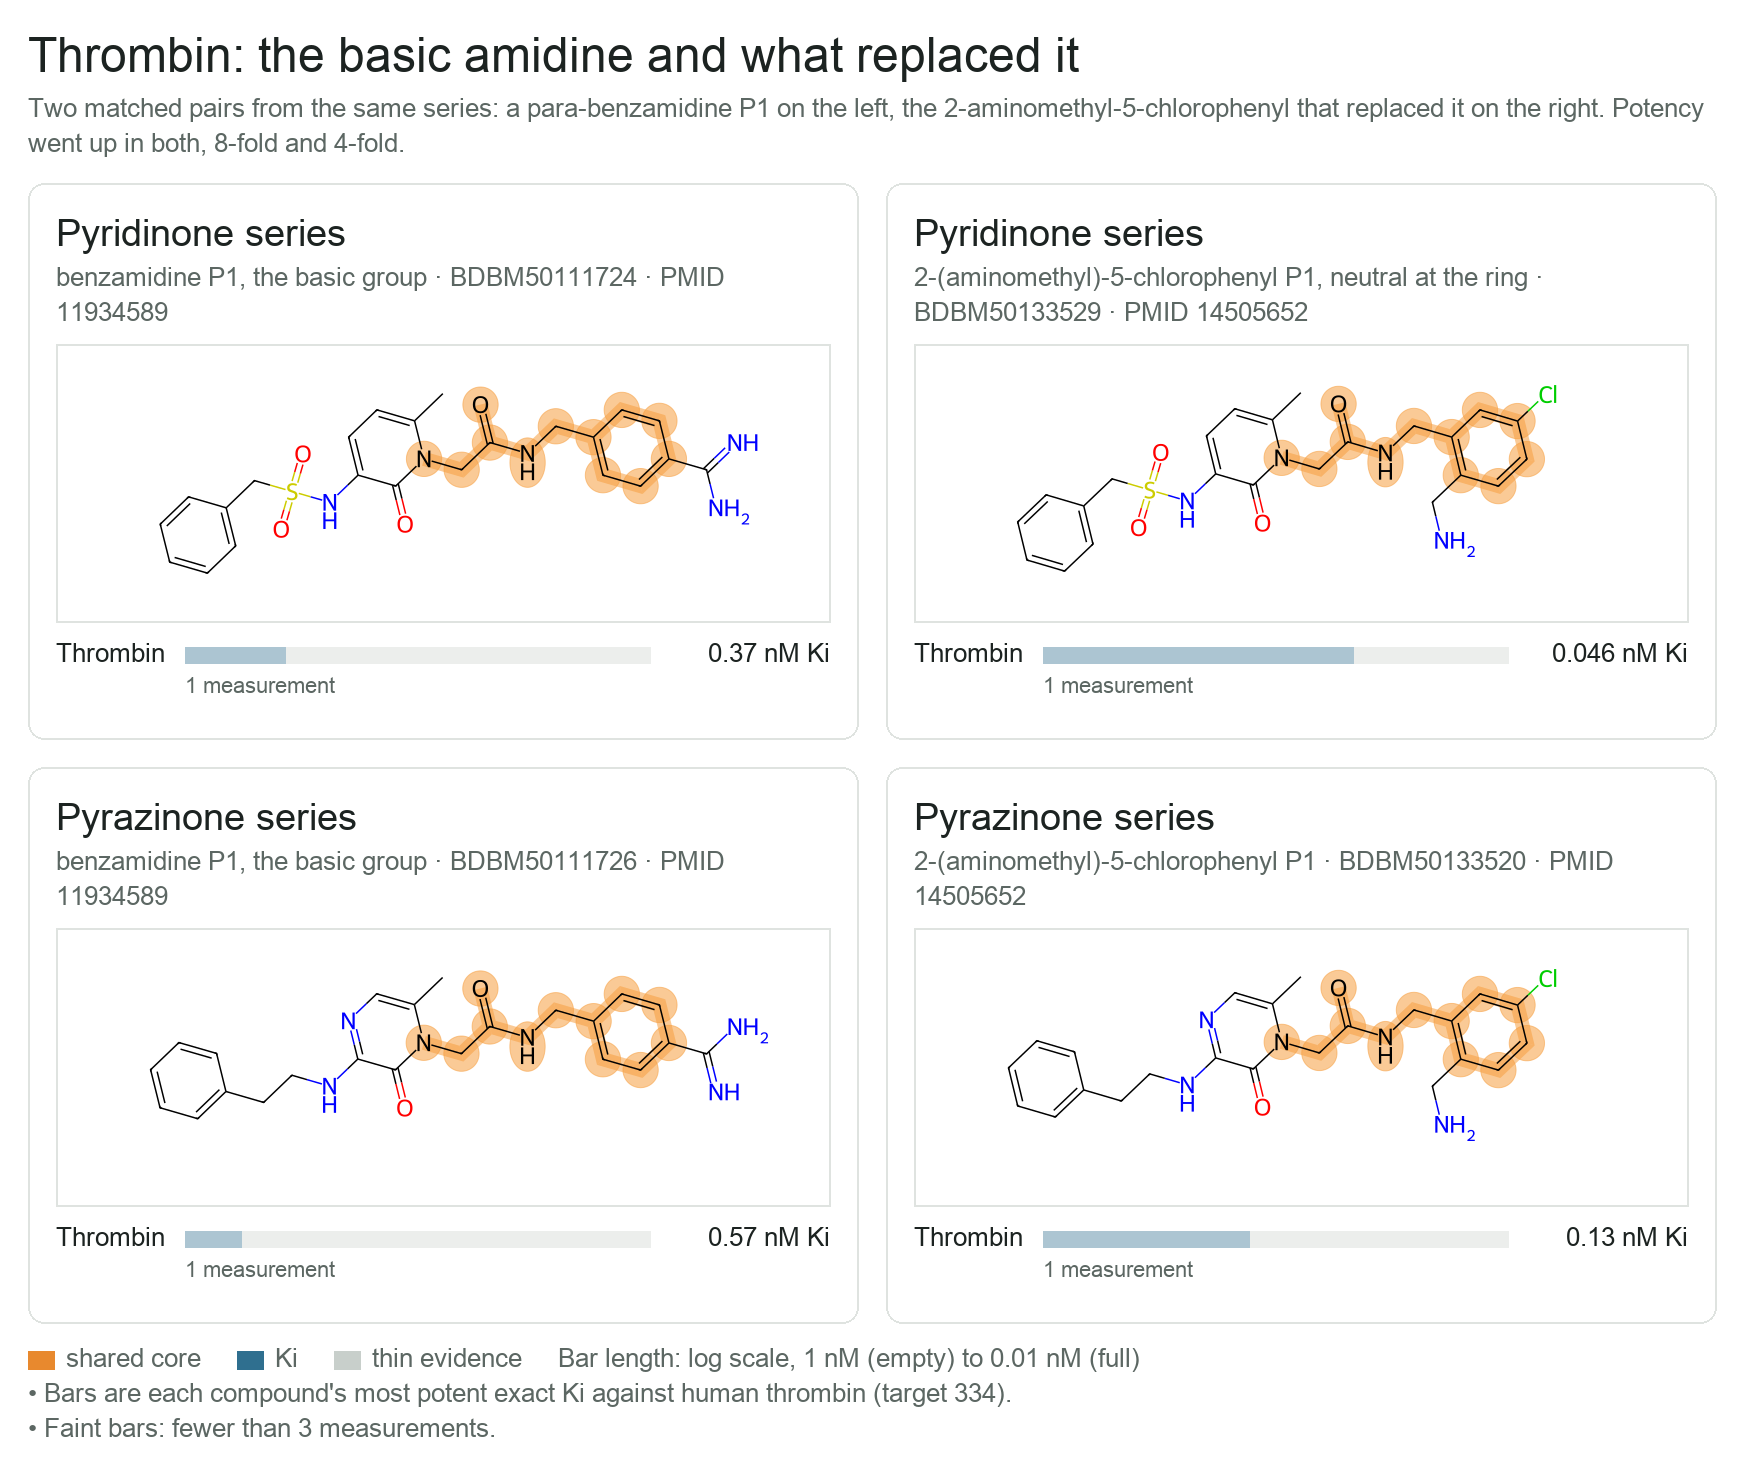

In [ ]:
# Figure 2 · draw_structure_grid draws it again
arguments = {
    'title': 'Thrombin: the basic amidine and what replaced it',
    'compounds': [
        {
            'smiles': 'Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NCc1ccc(cc1)C(N)=N',
            'title': 'Pyridinone series',
            'subtitle': 'benzamidine P1, the basic group · BDBM50111724 · PMID 11934589',
            'bars': [
                {
                    'label': 'Thrombin',
                    'value_nm': 0.37,
                    'type': 'Ki',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1ccc(NS(=O)(=O)Cc2ccccc2)c(=O)n1CC(=O)NCc1cc(Cl)ccc1CN',
            'title': 'Pyridinone series',
            'subtitle': '2-(aminomethyl)-5-chlorophenyl P1, neutral at the ring · BDBM50133529 · PMID 14505652',
            'bars': [
                {
                    'label': 'Thrombin',
                    'value_nm': 0.046,
                    'type': 'Ki',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NCc1ccc(cc1)C(N)=N',
            'title': 'Pyrazinone series',
            'subtitle': 'benzamidine P1, the basic group · BDBM50111726 · PMID 11934589',
            'bars': [
                {
                    'label': 'Thrombin',
                    'value_nm': 0.57,
                    'type': 'Ki',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1cnc(NCCc2ccccc2)c(=O)n1CC(=O)NCc1cc(Cl)ccc1CN',
            'title': 'Pyrazinone series',
            'subtitle': '2-(aminomethyl)-5-chlorophenyl P1 · BDBM50133520 · PMID 14505652',
            'bars': [
                {
                    'label': 'Thrombin',
                    'value_nm': 0.13,
                    'type': 'Ki',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 2,
    'description': 'Two matched pairs from the same series: a para-benzamidine P1 on the left, the 2-aminomethyl-5-chlorophenyl that replaced it on the right. Potency went up in both, 8-fold and 4-fold.',
    'notes': [
        "Bars are each compound's most potent exact Ki against human thrombin (target 334).",
        'Faint bars: fewer than 3 measurements.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(2, 'draw_structure_grid', arguments)

**🧠 Assistant**

Not with that group: the 3-aminobenzisoxazole does not appear in thrombin's pairs at all. But **the same move does work, with a different group**: a para-benzamidine replaced by a neutral-at-the-ring 2-(aminomethyl)-5-chlorophenyl improved 7 of 8 matched pairs, 2-fold at the median and 8-fold at best. And the two swaps with better records than that are both further work on the group that replaced it.

Among the 1,500 most potent compounds with an exact Ki against human thrombin (target 334, listed as Prothrombin, P00734), matched_molecular_pairs finds **6,431 pairs over 4,876 transformations**. Filtered to group swaps as before (353 of the 500 most frequent), and ranked by median change, with the instructive losers:

| smaller group | SMILES | larger group | SMILES | Pairs | Improved | Median Δp | Best | Worst |
|---|---|---|---|---|---|---|---|---|
| 2-(1,2,4-triazol-1-yl)phenyl | c1ccc([*:1])c(-n2cncn2)c1 | 5-chloro-2-(tetrazol-1-yl)phenyl | Clc1ccc(-n2cnnn2)c([*:1])c1 | 7 | 7 | +2.50 (316×) | +2.75 | +0.51 |
| 2-(tetrazol-1-yl)phenyl | c1ccc([*:1])c(-n2cnnn2)c1 | 5-chloro-2-(1,2,4-triazol-1-yl)phenyl | Clc1ccc(-n2cncn2)c([*:1])c1 | 8 | 8 | +1.03 (11×) | +1.63 | +0.26 |
| 1,2,4-triazol-1-yl | c1ncn([*:1])n1 | tetrazol-1-yl | c1nnnn1[*:1] | 14 | 13 | +0.72 (5×) | +1.42 | −1.12 |
| phenyl | c1ccc([*:1])cc1 | pyridin-3-yl | c1ccc([*:1])nc1 | 18 | 14 | +0.38 | +1.06 | −0.78 |
| benzamidine | N=C(N)c1ccc([*:1])cc1 | 2-(aminomethyl)-5-chlorophenyl | NCc1ccc(Cl)cc1[*:1] | 8 | 7 | +0.33 | +0.91 | −0.48 |
| pyridin-3-yl | c1ccc([*:1])nc1 | pyridine N-oxide | [O-][n+]1ccccc1[*:1] | 15 | 13 | +0.28 | +0.53 | −0.70 |
| phenyl | c1ccc([*:1])cc1 | benzyl | c1ccc(C[*:1])cc1 | 16 | 10 | +0.11 | +1.28 | −0.52 |
| cyclohexyl | C1CCC([*:1])CC1 | phenyl | c1ccc([*:1])cc1 | 18 | 7 | −0.05 | +1.60 | −1.67 |
| trans-4-aminocyclohexyl | N[C@H]1CC\[C@H]([*:1])CC1 | 6-amino-2-methylpyridin-3-yl | Cc1nc(N)ccc1[*:1] | 15 | 7 | −0.23 | +1.31 | −3.56 |

**The P1 row answers the question: the basic amidine was not load-bearing.** The figure below shows two pairs from the same pyridinone/pyrazinone series, one with a benzylsulfonamide and one with a phenethylamino group, each measured in both P1 forms. The benzamidine is 0.37 nM and the chlorobenzylamine 0.046 nM, 8-fold better without the amidine; the second pair moves 0.57 → 0.13 nM. A third pair elsewhere in the set goes 0.102 → 0.052 nM, and only one of the eight goes backwards (−0.48, a D-Phe-Pro peptidomimetic). The amine is still present, but it has moved off the ring and out of the pocket, and a chlorine now sits in thrombin's hydrophobic S1. That is the same structural bet the factor Xa programmes made, reached from a different chemotype, and here the new group was not even a potency sacrifice. (The two pairs are aligned on a 12-atom part they share, the glycinamide and the benzyl ring on which the P1 group sits.)

**The top two rows say which part of the new group is doing the work, and it is the chlorine.** Both act on that same replacement phenyl ring, and each changes the azole as well as adding the chlorine. Adding the chlorine while switching the azole from tetrazole to triazole improved all 8 of its pairs, median 11-fold, worst case still +0.26; adding it while switching from triazole to tetrazole improved all 7, median +2.5 log units. Meanwhile the azole swap on its own (triazole to tetrazole, no chlorine) is worth only 5-fold over 14 pairs. The two chlorine rows run in opposite azole directions, so the azole's +0.72 cancels out of their difference: 2.50 − 0.72 and 1.03 + 0.72 both come to about +1.8 log units for the chlorine. Read together: the chlorine in S1 is the large effect (around 60-fold), the azole next to it a smaller one, and the amidine the series started with was worth less than either. These two are the only rows in the thrombin table without a loser; each is a short run of pairs from one programme, so the clean record is partly the small sample.

**What the comparison is worth, and where it stops.** Eight pairs is a thin record next to factor Xa's fourteen, and all eight come from a handful of programmes, so this is closer to one laboratory's result than to a cross-programme consensus. More importantly, the database cannot show you why either swap mattered: replacing a benzamidine was never about affinity, it was that a permanently charged group does not cross a gut wall. Matched pairs measure the axis BindingDB holds. The useful finding here is the negative one: the project could drop the charge without paying for it.

**The bottom two rows are the ones to show someone who likes saturated rings.** Cyclohexyl to phenyl is a coin flip (7 of 18 pairs improved, median −0.05) and trans-4-aminocyclohexyl to aminopyridine loses more often than it wins (7 of 15, median −0.23, worst −3.56), even though both are routine moves for lowering logP. Note how wide those rows are: from −1.7 to +1.6 log units around a median of roughly zero means the change is not neutral, it is context-dependent, and the median is hiding two populations. That is the one place a matched-pair median actively misleads, and the fix is to open the row and look at the pairs.

**How this was answered**
- search_targets for "thrombin" in Homo sapiens gave target 334 (8,290 compounds); the tool picked Ki.
- matched_molecular_pairs with group_by_transformation: true and max_compounds: 1500 gave the transformation table, filtered as before to swaps of four or more heavy atoms on both sides.
- The factor Xa transformation from the previous answer, run against target 334, returns no pairs: the two chemotypes do not overlap in the matched-pair sense, so the comparison has to be made between moves, not between identical transformations.
- matched_molecular_pairs with the benzamidine transformation returned its 8 individual pairs, and draw_structure_grid drew two of them.

**Try next**
- "Why does it only find groups up to a certain size?" (the follow-up below)
- "Open the cyclohexyl → phenyl row" (the same call with that transformation, to see the two populations the median hides)

Example 5.2 does the cross-target comparison the other way round: whole compounds against a panel, read as a heat map rather than as pairs.

## Exchange 3

**👤 User**

Why does it only find groups up to a certain size, and what happens if I allow bigger ones?

In [ ]:
# Call 15 · matched_molecular_pairs · ran 2026-11-24 04:58:01 UTC
arguments = {
    'target_id': 1341,
    'group_by_transformation': True,
    'max_compounds': 1500,
    'limit': 500,
    'max_variable_atoms': 8,
}
await replay.call(15, 'matched_molecular_pairs', arguments,
                  sha256='bc70cc610c2aa2993fe828bd50b0882be2879af623b91cbc7c36e9949c005a34')

**Call 15** · `matched_molecular_pairs` · recorded result · sha256 `bc70cc610c2a…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 5616,
  "grouped_by": "transformation",
  "n_transformations": 3984,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_500 rows, truncated at the limit_

| transformation | n_pairs | median_delta_p_affinity | min_delta_p_affinity | max_delta_p_affinity | n_improved | best_monomerid_from | best_monomerid_to |
| --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 119 | 0 | -1.66 | 1.34 | 53 | 50404115 | 17226 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 69 | 0.02 | -1.61 | 0.98 | 36 | 50228918 | 50228925 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 35 | 0.19 | -0.62 | 1.77 | 21 | 50404134 | 17226 |
| C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 28 | 0.2 | -2.26 | 1.61 | 18 | 50096112 | 50096105 |
| \[H\]\[\*:1\] \>\> CO\[\*:1\] | 26 | 0.01 | -2.66 | 1.04 | 13 | 12745 | 12747 |
| NC(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 23 | -0.3 | -1.28 | 0.55 | 4 | 50266013 | 50243592 |
| CS(=O)(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 22 | -0.23 | -1.05 | 0.6 | 6 | 50096096 | 50096099 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 21 | 0.15 | -0.58 | 0.59 | 12 | 50224694 | 50224708 |
| CN\[\*:1\] \>\> CN(C)\[\*:1\] | 19 | 0.3 | -0.52 | 1.44 | 14 | 50266179 | 50266214 |
| C\[\*:1\] \>\> CC(C)\[\*:1\] | 19 | -0.1 | -1.17 | 1.02 | 7 | 17282 | 50088963 |
| C\[\*:1\] \>\> Cl\[\*:1\] | 18 | 0.15 | -0.45 | 1.34 | 12 | 50404141 | 17226 |
| \[H\]\[\*:1\] \>\> O\[\*:1\] | 18 | -0.2 | -1.28 | 0.85 | 6 | 50377632 | 50377629 |
| N#C\[\*:1\] \>\> NC(=O)\[\*:1\] | 15 | 0.3 | -1.17 | 1.82 | 11 | 12732 | 12733 |
| CN(C)C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 15 | 0.09 | -1.21 | 1.1 | 10 | 50224694 | 50224693 |
| \[H\]\[\*:1\] \>\> CC\[\*:1\] | 14 | -0 | -0.59 | 1.52 | 7 | 50088960 | 50088951 |
| CN(C)\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 13 | 0.08 | -0.6 | 0.53 | 7 | 19009 | 18991 |
| Br\[\*:1\] \>\> Cl\[\*:1\] | 13 | 0.07 | -0.37 | 0.6 | 8 | 50590078 | 12372 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 12 | 0.7 | -0.69 | 1.96 | 11 | 50374882 | 50374880 |
| CN\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 12 | 0.39 | -0.4 | 1.44 | 8 | 50266179 | 50266215 |
| N\[\*:1\] \>\> O\[\*:1\] | 12 | 0.32 | -0.64 | 1.07 | 9 | 50066627 | 50066638 |
| \[H\]\[\*:1\] \>\> NC(=O)\[\*:1\] | 12 | 0 | -1.11 | 1 | 5 | 50085406 | 50085393 |
| Cl\[\*:1\] \>\> F\[\*:1\] | 12 | -0.08 | -1.49 | 0.44 | 4 | 50123041 | 50123035 |
| N\[\*:1\] \>\> CN(C)\[\*:1\] | 11 | 0.61 | -0.05 | 1.34 | 10 | 18996 | 18999 |
| C\[\*:1\] \>\> F\[\*:1\] | 11 | 0.16 | -1.19 | 0.47 | 6 | 12378 | 12374 |
| \[H\]\[\*:1\] \>\> N\[\*:1\] | 11 | -0.08 | -1.35 | 0.74 | 4 | 13282 | 13283 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.25 | -1.02 | 0.12 | 2 | 19046 | 19048 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.43 | -1.02 | 0.25 | 1 | 50266013 | 50266049 |
| \[H\]\[\*:1\] \>\> N#C\[\*:1\] | 10 | 0.44 | -1.19 | 1.19 | 9 | 50089112 | 50089118 |
| N#C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 10 | 0.15 | -0.52 | 0.55 | 6 | 50265829 | 50266216 |
| Clc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])nc1 | 10 | 0.05 | -0.85 | 0.48 | 6 | 12400 | 15867 |
| \[H\]\[\*:1\] \>\> O=C(O)\[\*:1\] | 10 | 0.05 | -1.17 | 0.82 | 5 | 50101878 | 50101879 |
| O=C(O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 10 | -0.11 | -0.31 | 0.88 | 4 | 50088932 | 50088924 |
| \[H\]\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 10 | -0.18 | -1.35 | 0.85 | 2 | 50111667 | 50111675 |
| O\[\*:1\] \>\> CN(C)\[\*:1\] | 9 | 0.88 | 0.25 | 1.84 | 9 | 50243379 | 50243540 |
| N\[\*:1\] \>\> CN\[\*:1\] | 9 | 0.68 | 0 | 1.25 | 8 | 12674 | 12675 |
| O=C(O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 9 | 0.44 | 0 | 1.36 | 8 | 50088932 | 50088923 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 9 | 0.32 | -0.51 | 1.21 | 7 | 50265915 | 50266215 |
| \[H\]\[\*:1\] \>\> OC\[\*:1\] | 9 | -0.13 | -0.86 | 0.56 | 2 | 12504 | 12519 |
| NC(=O)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 9 | -0.3 | -0.73 | 0.71 | 2 | 50265947 | 50265916 |
| \[H\]\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 9 | -0.34 | -2.49 | 1.51 | 3 | 50096103 | 50096094 |
| O\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 8 | 0.86 | 0.14 | 2.12 | 8 | 50046500 | 50046521 |
| \[H\]\[\*:1\] \>\> NC\[\*:1\] | 8 | 0.74 | 0.16 | 1.54 | 8 | 50211575 | 50211564 |
| \[H\]\[\*:1\] \>\> Br\[\*:1\] | 8 | 0.31 | -0.47 | 1.62 | 6 | 50404134 | 50404108 |
| CN\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 8 | 0.21 | -0.83 | 0.48 | 5 | 50243539 | 50243628 |
| NS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 8 | 0.2 | -0.26 | 1.18 | 6 | 19045 | 19038 |
| CN(C)\[\*:1\] \>\> CN(C)C\[\*:1\] | 8 | 0.1 | -0.13 | 0.45 | 4 | 50046515 | 50046434 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 8 | -0.04 | -0.32 | 0.7 | 4 | 12692 | 12693 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 7 | 0.46 | -0.21 | 1.36 | 6 | 12705 | 12657 |
| \[H\]\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | 0.27 | -0.78 | 0.82 | 5 | 50101878 | 50101880 |
| CN(C)C\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 7 | 0.12 | -0.98 | 0.85 | 5 | 50224694 | 50224696 |
| \[H\]\[\*:1\] \>\> CCC\[\*:1\] | 7 | 0.07 | -0.67 | 1.1 | 4 | 50088960 | 50088952 |
| CN(C)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.05 | -1.17 | 0.52 | 2 | 50046515 | 50046441 |
| \[H\]\[\*:1\] \>\> CN(C)C\[\*:1\] | 7 | -0.05 | -1.37 | 1.04 | 3 | 12504 | 12531 |
| CC(C)\[\*:1\] \>\> C1CC1C\[\*:1\] | 7 | -0.07 | -0.58 | 0.22 | 2 | 12506 | 12509 |
| O\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.08 | -2.11 | 0.52 | 3 | 50295587 | 50295588 |
| \[H\]\[\*:1\] \>\> CN(C)\[\*:1\] | 7 | -0.1 | -1.17 | 0.74 | 3 | 12505 | 12531 |
| NC(=O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | -0.18 | -0.36 | 0.37 | 3 | 50374874 | 50374871 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.22 | -0.79 | 0.9 | 3 | 50046522 | 50046441 |
| Cl\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.43 | -1.69 | 0.04 | 1 | 50404129 | 50404105 |
| NC\[\*:1\] \>\> N=C(N)\[\*:1\] | 6 | 2.23 | -1.95 | 2.64 | 5 | 50096086 | 50096099 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 6 | 0.71 | 0.28 | 1.46 | 6 | 50243538 | 50243592 |
| NC(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 6 | 0.33 | -0.25 | 0.56 | 5 | 12524 | 12530 |
| CN\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 6 | 0.1 | -0.69 | 0.54 | 3 | 50266321 | 50266050 |
| N\[\*:1\] \>\> NC(=O)\[\*:1\] | 6 | 0.01 | -0.63 | 1.98 | 3 | 18996 | 18991 |
| \[H\]\[\*:1\] \>\> COC\[\*:1\] | 6 | -0.01 | -1.56 | 0.33 | 3 | 50079259 | 50079252 |
| N#C\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 6 | -0.02 | -0.89 | 1.26 | 3 | 50377639 | 50377640 |
| Br\[\*:1\] \>\> F\[\*:1\] | 6 | -0.04 | -1.34 | 0.47 | 2 | 12376 | 12374 |
| NC(=O)\[\*:1\] \>\> O=C(O)\[\*:1\] | 6 | -0.14 | -2.03 | 0.18 | 1 | 12568 | 12567 |
| Br\[\*:1\] \>\> C\[\*:1\] | 6 | -0.15 | -1.19 | 0.19 | 1 | 13659 | 13663 |
| \[H\]\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 1.03 | -0.1 | 1.57 | 4 | 50079229 | 50079240 |
| \[H\]\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 5 | 1 | 0.1 | 1.6 | 5 | 50088957 | 50112524 |
| COC(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 0.94 | 0.87 | 1.12 | 5 | 50079222 | 50079253 |
| C\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 5 | 0.49 | -1.23 | 1.06 | 3 | 50592210 | 50592212 |
| O\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.49 | 0 | 1.6 | 4 | 50243379 | 50243628 |
| CN(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 5 | 0.47 | -0.25 | 0.65 | 4 | 50266112 | 50243592 |
| N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.4 | -0.15 | 0.98 | 3 | 50243538 | 50243628 |
| CC(C)N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 5 | 0.32 | -0.3 | 0.53 | 4 | 12835 | 12840 |
| CN\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 5 | 0.3 | 0.19 | 1.05 | 5 | 12691 | 12693 |
| CNC\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.23 | -0.4 | 0.48 | 4 | 12833 | 12659 |
| c1ccc(\[\*:1\])nc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 5 | 0.23 | 0.19 | 0.4 | 5 | 50211571 | 50211565 |
| C1CCN(\[\*:1\])C1 \>\> CCN(CC)\[\*:1\] | 5 | 0.14 | -0.24 | 0.58 | 3 | 19011 | 19010 |
| F\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.14 | -0.82 | 1.76 | 3 | 50096088 | 50096091 |
| CN(C)\[\*:1\] \>\> CCN(CC)\[\*:1\] | 5 | -0.07 | -0.44 | 0.48 | 2 | 19009 | 19010 |
| N\[\*:1\] \>\> N#C\[\*:1\] | 5 | -0.1 | -0.78 | 1.31 | 2 | 18996 | 18994 |
| CN(C)\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 5 | -0.34 | -1.75 | 1.08 | 1 | 19018 | 19017 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | -0.38 | -0.97 | 0.09 | 1 | 18999 | 18988 |
| CN(C)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 5 | -0.61 | -1.25 | -0.17 | 0 | 17233 | 17235 |
| NC\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.74 | -0.85 | 1.11 | 2 | 12714 | 12710 |
| CN(C)\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.96 | -1.57 | 0.64 | 1 | 18999 | 18991 |
| O\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 1.54 | 0.12 | 2.12 | 4 | 50046500 | 50046434 |
| CO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 4 | 1.08 | -0.62 | 1.49 | 3 | 50079245 | 50079253 |
| CN\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 4 | 0.93 | 0 | 1.06 | 3 | 50266321 | 50266047 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.93 | 0 | 1.21 | 3 | 50265915 | 50243592 |
| \[H\]\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 4 | 0.81 | 0.49 | 1.06 | 4 | 17237 | 17263 |
| CN\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 0.73 | 0.25 | 0.96 | 4 | 50243539 | 50266214 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.72 | 0.28 | 0.88 | 4 | 12705 | 50135953 |
| C1CN(\[\*:1\])CCO1 \>\> Cc1nccn1\[\*:1\] | 4 | 0.67 | 0.05 | 2.15 | 4 | 17095 | 17133 |
| N#C\[\*:1\] \>\> CN(C)\[\*:1\] | 4 | 0.59 | 0.03 | 1.31 | 4 | 50243378 | 50266112 |
| N#C\[\*:1\] \>\> NC\[\*:1\] | 4 | 0.45 | -1.06 | 0.9 | 3 | 50046442 | 50046445 |
| \[H\]\[\*:1\] \>\> CCCC\[\*:1\] | 4 | 0.39 | 0.27 | 1.1 | 4 | 50088960 | 50088942 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 4 | 0.38 | -0.47 | 0.73 | 3 | 50265915 | 50243628 |
| CN\[\*:1\] \>\> CCN(CC)\[\*:1\] | 4 | 0.37 | -0.19 | 0.59 | 3 | 19041 | 19042 |
| C1CN(\[\*:1\])CCO1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0.36 | -0.31 | 0.95 | 2 | 17095 | 17088 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> C\[C@H\](N(C)C)\[\*:1\] | 4 | 0.35 | 0 | 0.4 | 3 | 50306144 | 50306143 |
| CN(C)C(=O)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | 0.33 | 0.11 | 1.56 | 4 | 50243431 | 50266250 |
| N\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | 0.33 | -0.15 | 1.14 | 2 | 50243538 | 50243590 |
| N\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | 0.27 | -0.34 | 0.61 | 2 | 50243538 | 50243629 |
| NC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.26 | 0.22 | 0.55 | 4 | 12526 | 12529 |
| N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.21 | -0.59 | 0.88 | 2 | 12523 | 12529 |
| CC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 4 | 0.18 | -1 | 0.3 | 3 | 50088957 | 50088941 |
| O=C(O)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 4 | 0.16 | 0.05 | 0.37 | 4 | 50079239 | 50079241 |
| O=C(O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | 0.15 | -0.04 | 0.65 | 3 | 18990 | 18993 |
| C\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.89 | 1 | 2 | 12393 | 12395 |
| Cl\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.56 | 0.82 | 2 | 12391 | 12395 |
| CS(=O)(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 4 | 0.13 | -0.7 | 0.45 | 3 | 50266080 | 50243668 |
| c1nnn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 4 | 0.12 | 0.07 | 0.48 | 4 | 50079235 | 50079236 |
| N#C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.08 | -1 | 0.4 | 3 | 50046442 | 50046522 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.06 | -1.37 | 2.21 | 2 | 50096103 | 50096091 |
| CN(C)C\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.05 | 0 | 0.3 | 2 | 17258 | 17259 |
| NCc1cccc(\[\*:1\])c1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.03 | -0.48 | 0.31 | 2 | 19027 | 19028 |
| CN\[\*:1\] \>\> CNC\[\*:1\] | 4 | 0.01 | -0.48 | 0.31 | 2 | 50266321 | 50265978 |
| c1cn(\[\*:1\])cn1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0 | -0.86 | 0.4 | 2 | 17242 | 17085 |
| CN\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.1 | -1.02 | 0.19 | 2 | 12691 | 12695 |
| CS(=O)(=O)\[\*:1\] \>\> O\[C@@H\]1CCN(C\[\*:1\])C1 | 4 | -0.1 | -0.25 | 0.42 | 1 | 50307096 | 50307099 |
| C\[\*:1\] \>\> c1cncc(\[\*:1\])c1 | 4 | -0.1 | -0.4 | 0.28 | 2 | 12750 | 12772 |
| C\[\*:1\] \>\> O\[\*:1\] | 4 | -0.12 | -0.31 | 0.7 | 1 | 12402 | 50096459 |
| NC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.12 | -1.38 | 0.53 | 1 | 50306150 | 50306148 |
| CN(C)C(=N)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | -0.15 | -0.31 | -0.13 | 0 | 50140410 | 50140415 |
| CN\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | -0.16 | -0.28 | 0.83 | 1 | 18998 | 18988 |
| CN(C)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.17 | -1.81 | 0.59 | 2 | 50370088 | 50066622 |
| C\[\*:1\] \>\> CO\[\*:1\] | 4 | -0.17 | -0.35 | 0.74 | 1 | 50218320 | 50218280 |
| CCN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | -0.19 | -0.4 | 0.06 | 1 | 19035 | 19032 |
| C\[\*:1\] \>\> N\[\*:1\] | 4 | -0.2 | -1.69 | 0.35 | 2 | 12761 | 12762 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])cc1 | 4 | -0.2 | -0.39 | 0.38 | 1 | 50085519 | 50085511 |
| \[H\]\[\*:1\] \>\> O=C(O)C\[\*:1\] | 4 | -0.21 | -0.68 | 1.6 | 2 | 50101878 | 50101871 |
| CC(C)\[\*:1\] \>\> CCC\[\*:1\] | 4 | -0.3 | -0.95 | 0.17 | 1 | 50079255 | 50079244 |
| CN(C)\[\*:1\] \>\> CNC\[\*:1\] | 4 | -0.3 | -1.2 | -0.18 | 0 | 50265826 | 50265977 |
| CN(C)\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | -0.34 | -0.67 | -0.08 | 0 | 50243540 | 50243590 |
| \[H\]\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 4 | -0.36 | -1.39 | 1.38 | 2 | 17237 | 17085 |
| C1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.39 | -0.85 | 0.02 | 1 | 19011 | 19012 |
| CC(C)\[\*:1\] \>\> CCCC\[\*:1\] | 4 | -0.4 | -0.95 | -0.15 | 0 | 50088947 | 50088939 |
| CN(C)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.45 | -0.74 | -0.08 | 0 | 19009 | 19012 |
| COC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.59 | -1.24 | 0.18 | 1 | 50101880 | 50101883 |
| O\[C@@H\]1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.59 | -0.86 | -0.3 | 0 | 12870 | 12871 |
| CN\[\*:1\] \>\> NC(=O)\[\*:1\] | 4 | -0.65 | -1.32 | 1.38 | 1 | 18998 | 18991 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(C\[\*:1\])CCO1 | 4 | -0.66 | -1.44 | 0.07 | 1 | 50046521 | 50046441 |
| NC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.47 | -0.3 | 1.98 | 2 | 50243430 | 50243540 |
| N\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.35 | 0.3 | 1.46 | 3 | 50243538 | 50266214 |
| CCS(=O)(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 1.19 | 0.82 | 1.21 | 3 | 50079233 | 50079253 |
| N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 1.14 | 1.1 | 1.18 | 3 | 50243538 | 50243340 |
| NC(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | 0.96 | 0.44 | 0.99 | 3 | 50265946 | 50243628 |
| N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.89 | -0.57 | 1.35 | 2 | 17089 | 17105 |
| CCO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 0.86 | 0.8 | 1.32 | 3 | 50079248 | 50079253 |
| Cl\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.72 | 0.7 | 0.85 | 3 | 12384 | 12389 |
| CN1CCN=C1\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.69 | 0.3 | 1.2 | 3 | 50140416 | 50140371 |
| Br\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.65 | -0.5 | 0.82 | 2 | 12392 | 12395 |
| \[H\]\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 3 | 0.56 | 0.18 | 2 | 3 | 50096103 | 12751 |
| CN(C)C(=N)\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.55 | 0.15 | 0.89 | 3 | 50140407 | 50140371 |
| C1CN(\[\*:1\])CCO1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.54 | 0.2 | 1.06 | 3 | 12696 | 12693 |
| C\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.53 | 0.4 | 0.95 | 3 | 12378 | 12381 |
| \[H\]\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 3 | 0.52 | -0.18 | 0.98 | 2 | 17237 | 17242 |
| CN1CCN(\[\*:1\])CC1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | 0.51 | -1.14 | 0.65 | 2 | 50142103 | 50142129 |
| \[H\]\[\*:1\] \>\> CC(C)\[\*:1\] | 3 | 0.5 | 0.35 | 2.05 | 3 | 50088960 | 50088963 |
| NC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 3 | 0.45 | 0.41 | 1.74 | 3 | 50243430 | 50243628 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.4 | 0 | 0.8 | 2 | 50338679 | 50614408 |
| CN\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.39 | -1.26 | 0.67 | 2 | 17090 | 17105 |
| CO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.37 | -0.06 | 0.48 | 2 | 50079249 | 50079211 |
| N\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.37 | -0.65 | 0.8 | 2 | 17089 | 17088 |
| O\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.37 | 0.08 | 0.89 | 3 | 50046500 | 50046442 |
| \[H\]\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 3 | 0.35 | 0.03 | 1.45 | 3 | 50101878 | 50101881 |
| CC(=O)N(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | 0.34 | -1.12 | 0.91 | 2 | 19022 | 19023 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(\[\*:1\])nc1 | 3 | 0.34 | 0 | 0.75 | 2 | 50085406 | 50114537 |
| CC(C)N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.33 | 0.04 | 0.89 | 3 | 50242833 | 12743 |
| N\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0.3 | -0.4 | 0.33 | 2 | 12523 | 12526 |
| CC(C)\[\*:1\] \>\> FC(F)(F)C\[\*:1\] | 3 | 0.28 | -0.23 | 0.28 | 2 | 50324744 | 50324771 |
| \[H\]\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 3 | 0.28 | -0.26 | 1.06 | 2 | 17093 | 17104 |
| \[H\]\[\*:1\] \>\> CN1CCN(C\[\*:1\])CC1 | 3 | 0.26 | -1.54 | 0.3 | 2 | 17238 | 17244 |
| CC\[\*:1\] \>\> CO\[\*:1\] | 3 | 0.25 | -0.73 | 0.93 | 2 | 12739 | 12740 |
| \[H\]\[\*:1\] \>\> NC(=O)C\[\*:1\] | 3 | 0.23 | -0.57 | 0.3 | 2 | 12504 | 12524 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.18 | 0 | 0.58 | 2 | 50338680 | 50614408 |
| F\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.18 | 0.13 | 0.82 | 3 | 12390 | 12395 |
| N\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.18 | -1 | 1.9 | 2 | 50112530 | 50112524 |
| CO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | 0.17 | -0.01 | 0.28 | 2 | 50079245 | 50079233 |
| c1cn(\[\*:1\])cn1 \>\> c1nnnn1\[\*:1\] | 3 | 0.17 | 0.05 | 0.27 | 3 | 12768 | 12771 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 3 | 0.14 | 0 | 0.46 | 2 | 19018 | 19019 |
| O=C(O)\[\*:1\] \>\> O=C(O)C\[\*:1\] | 3 | 0.12 | -0.15 | 0.78 | 2 | 50101879 | 50101871 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | 0.1 | -0.72 | 0.41 | 2 | 12856 | 12857 |
| C\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | 0.09 | -0.64 | 1.51 | 2 | 50307101 | 50307102 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 3 | 0.07 | -0.22 | 1.04 | 2 | 12505 | 12528 |
| C1CN(\[\*:1\])CCN1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.05 | -0.04 | 0.13 | 2 | 12849 | 12848 |
| OC\[\*:1\] \>\> FC(F)\[\*:1\] | 3 | 0.04 | -0.29 | 0.38 | 2 | 50324750 | 50324752 |
| OC\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.03 | -0.78 | 0.2 | 2 | 50243379 | 50243377 |
| CN\[\*:1\] \>\> CN(CCO)\[\*:1\] | 3 | 0 | -0.06 | 0.12 | 1 | 50266111 | 50266113 |
| CN\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | 0 | -0.31 | 0.03 | 1 | 50266321 | 50265945 |
| NC\[\*:1\] \>\> CN(C)\[\*:1\] | 3 | 0 | -0.12 | 0.81 | 1 | 50243538 | 50266112 |
| O\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0 | 0 | 0.48 | 1 | 12519 | 12525 |
| CCO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.02 | -0.33 | 0.11 | 1 | 50079248 | 50079233 |
| CCO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | -0.02 | -0.07 | 0.2 | 1 | 50079248 | 50079222 |
| c1ncn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 3 | -0.03 | -0.53 | 0.51 | 1 | 50079246 | 50079236 |
| \[H\]\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 3 | -0.07 | -0.62 | 0.52 | 1 | 12775 | 12776 |
| c1cn(\[\*:1\])nn1 \>\> c1nnnn1\[\*:1\] | 3 | -0.08 | -0.1 | -0.08 | 0 | 12770 | 12771 |
| COC(=O)\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.09 | -0.31 | 0.05 | 1 | 50072445 | 50079242 |
| c1ncn(\[\*:1\])n1 \>\> c1nnn(\[\*:1\])n1 | 3 | -0.1 | -0.64 | 0.03 | 1 | 50079246 | 50079235 |
| C\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.12 | -0.75 | 0.7 | 1 | 50101878 | 50101870 |
| OC\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | -0.14 | -0.42 | -0.07 | 0 | 50266113 | 50266114 |
| CC(=O)N(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.16 | -0.28 | -0.13 | 0 | 50243669 | 50243670 |
| CC(C)N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.16 | -0.21 | 0 | 0 | 17092 | 17095 |
| c1cc(\[\*:1\])ccn1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.17 | -1.2 | 0.15 | 1 | 50228945 | 50228951 |
| C1CN(\[\*:1\])CCO1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.19 | -0.37 | 0.2 | 1 | 12696 | 12695 |
| F\[\*:1\] \>\> CO\[\*:1\] | 3 | -0.2 | -0.6 | 0.3 | 1 | 50176255 | 50176250 |
| c1ccc(\[\*:1\])cc1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.2 | -0.25 | 0.43 | 1 | 12514 | 12516 |
| C1CCN(\[\*:1\])CC1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.3 | -0.56 | 0 | 0 | 12543 | 12544 |
| CN\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.3 | -0.38 | -0.12 | 0 | 50266111 | 50266216 |
| CC\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.32 | -0.75 | 0.33 | 1 | 50211560 | 50211580 |
| CN\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.32 | -0.5 | 0.12 | 1 | 17090 | 17088 |
| CC(C)\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 3 | -0.34 | -0.46 | 0.05 | 1 | 12835 | 12837 |
| C\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.34 | -0.58 | -0.05 | 0 | 50125242 | 50125245 |
| N\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.38 | -0.45 | 1.57 | 1 | 18996 | 12743 |
| CN(C)\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | -0.4 | -0.48 | 0.02 | 1 | 12855 | 12857 |
| O=C(O)\[\*:1\] \>\> n1n\[nH\]c(\[\*:1\])n1 | 3 | -0.4 | -0.82 | 1.08 | 1 | 18990 | 19001 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1ccc(\[\*:1\])cc1 | 3 | -0.44 | -0.64 | 0.7 | 1 | 15865 | 12400 |
| CN(C)\[\*:1\] \>\> C1CC1CN\[\*:1\] | 3 | -0.47 | -0.51 | -0.08 | 0 | 12688 | 12834 |
| CCN(CC)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.5 | -0.64 | -0.35 | 0 | 19042 | 19039 |
| CN(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.5 | -1.51 | -0.33 | 0 | 50243540 | 50243670 |
| c1cn(\[\*:1\])cn1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.51 | -1.81 | 0.08 | 1 | 12850 | 12847 |
| FC(F)(F)\[\*:1\] \>\> c1nnnn1C\[\*:1\] | 3 | -0.52 | -0.67 | 1.64 | 1 | 50079237 | 50079236 |
| C1CN(\[\*:1\])CCO1 \>\> C1CN(C\[\*:1\])CCO1 | 3 | -0.55 | -0.92 | -0.54 | 0 | 50243628 | 50266216 |
| CN(C)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.55 | -0.97 | -0.37 | 0 | 50266112 | 50266216 |
| CCN(CC)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.56 | -0.83 | -0.3 | 0 | 12689 | 12695 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | -0.56 | -0.56 | -0.25 | 0 | 50265826 | 50265916 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.6 | -1 | -0.09 | 0 | 50097772 | 50097759 |
| C1CCN(\[\*:1\])C1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.67 | -0.93 | 0.52 | 1 | 17096 | 17088 |
| NC(=O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 3 | -0.69 | -1.74 | -0.54 | 0 | 12719 | 12716 |
| N#C\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 3 | -0.71 | -0.81 | -0.5 | 0 | 50243378 | 50243431 |
| O=C1CCCCN1\[\*:1\] \>\> O=C1CCCCCN1\[\*:1\] | 3 | -0.8 | -0.82 | -0.31 | 0 | 19020 | 19021 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN1CCCC1\[\*:1\] | 3 | -0.88 | -1.28 | -0.48 | 0 | 50306144 | 50338683 |
| COC\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.93 | -1.18 | -0.83 | 0 | 50079252 | 50079237 |
| CN\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 3 | -0.98 | -1.36 | 0.52 | 1 | 50243539 | 50243669 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCN1 | 3 | -1 | -1.21 | -0.74 | 0 | 12688 | 12849 |
| CN(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | -1.33 | -2.35 | 1.42 | 1 | 19018 | 19020 |
| O\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 2.17 | 2.08 | 2.27 | 2 | 50046500 | 50046440 |
| NC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.85 | 1.47 | 2.22 | 2 | 50243430 | 50243592 |
| N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.68 | 1.36 | 2 | 2 | 17089 | 17133 |
| N#C\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.67 | 1.38 | 1.96 | 2 | 50243378 | 50243592 |
| O\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.62 | 1.06 | 2.19 | 2 | 50046500 | 50046441 |
| N\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.52 | 1.46 | 1.59 | 2 | 50266083 | 50243592 |
| C1COC(\[\*:1\])=N1 \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.5 | 0.9 | 2.1 | 2 | 50266282 | 50243592 |
| N#C\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.48 | 1.23 | 1.72 | 2 | 50243378 | 50243540 |
| C1CN(\[\*:1\])CCO1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 1.39 | 1.01 | 1.77 | 2 | 17095 | 17103 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.15 | 1.62 | 2 | 50266282 | 50243628 |
| N#C\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.3 | 1.48 | 2 | 50243378 | 50243628 |
| CC(C)N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.19 | 0.22 | 2.15 | 2 | 17092 | 17133 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)CC1(\[\*:1\])CC1 | 2 | 1.17 | 1.16 | 1.19 | 2 | 19022 | 50266010 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.16 | 0.44 | 1.88 | 2 | 50266142 | 50243592 |
| N\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 1.16 | 0.61 | 1.7 | 2 | 17089 | 17107 |
| \[H\]\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 1.15 | 0.5 | 1.8 | 2 | 50088960 | 50088944 |
| O\[\*:1\] \>\> NC\[\*:1\] | 2 | 1.14 | 0.48 | 1.79 | 2 | 50046500 | 50046445 |
| C1COC(\[\*:1\])=N1 \>\> CN(CCO)\[\*:1\] | 2 | 1.11 | 0.9 | 1.32 | 2 | 50266282 | 50266113 |
| C1CN(\[\*:1\])CCN1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.86 | 1.33 | 2 | 12697 | 12693 |
| CN\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.09 | 0.86 | 1.32 | 2 | 17090 | 17133 |
| NC(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.71 | 1.47 | 2 | 50265946 | 50243592 |
| CCS\[\*:1\] \>\> c1nnnn1\[\*:1\] | 2 | 1.08 | 0.87 | 1.3 | 2 | 50079258 | 50079240 |
| O\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 1.08 | 0.87 | 1.29 | 2 | 50046500 | 50046522 |
| N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 1.07 | 0.48 | 1.66 | 2 | 17089 | 17132 |
| CC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.06 | 0.66 | 1.46 | 2 | 50265913 | 50243540 |
| CC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.05 | 0.41 | 1.7 | 2 | 50265913 | 50243592 |
| O=C(O)CN\[\*:1\] \>\> O=C(O)CS(=O)(=O)N\[\*:1\] | 2 | 1.04 | 1 | 1.07 | 2 | 50211556 | 50211585 |
| NC(=O)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.03 | 0.69 | 1.37 | 2 | 50265946 | 50243668 |
| CO\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.02 | 0.25 | 1.8 | 2 | 50243429 | 50243668 |
| O=C1CCCN1\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.99 | -0.11 | 2.1 | 1 | 50266177 | 50243628 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)C1(\[\*:1\])CC1 | 2 | 0.97 | 0.75 | 1.19 | 2 | 19022 | 50265826 |
| OC\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 0.97 | 0.97 | 0.98 | 2 | 17099 | 17104 |
| OC\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.97 | 0.52 | 1.43 | 2 | 50243379 | 50266112 |
| Oc1ccc(\[\*:1\])cc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 2 | 0.97 | 0.95 | 1 | 2 | 50211559 | 50211566 |
| O\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.95 | 0.77 | 1.12 | 2 | 50243379 | 50243539 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)NC\[\*:1\] | 2 | 0.95 | 0.56 | 1.34 | 2 | 12504 | 12528 |
| CC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.94 | 0.66 | 1.22 | 2 | 50265913 | 50243628 |
| C1COC(\[\*:1\])=N1 \>\> CS(=O)(=O)C\[\*:1\] | 2 | 0.9 | 0.89 | 0.9 | 2 | 50265864 | 50265916 |
| OCC(O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.9 | 0.67 | 1.13 | 2 | 17102 | 17104 |
| c1c\[nH\]c(\[\*:1\])n1 \>\> C1CCN(CC\[\*:1\])C1 | 2 | 0.88 | 0.02 | 1.74 | 2 | 50266318 | 50266215 |
| F\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 2 | 0.86 | 0.67 | 1.06 | 2 | 50096088 | 50096094 |
| CC(=O)\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.85 | 0.66 | 1.05 | 2 | 50265913 | 50266112 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(CC\[\*:1\])CCO1 | 2 | 0.84 | 0.6 | 1.08 | 2 | 50266282 | 50266216 |
| N\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 0.84 | 0.25 | 1.43 | 2 | 18996 | 18988 |
| \[H\]\[\*:1\] \>\> CCC(C)\[\*:1\] | 2 | 0.83 | 0.28 | 1.38 | 2 | 50088960 | 50088954 |
| C1CCN(\[\*:1\])C1 \>\> Cc1nccn1\[\*:1\] | 2 | 0.81 | -0.1 | 1.72 | 1 | 17096 | 17133 |
| \[H\]\[\*:1\] \>\> c1nnn(\[\*:1\])n1 | 2 | 0.81 | 0.66 | 0.96 | 2 | 17237 | 17267 |
| N\[\*:1\] \>\> CCN(CC)\[\*:1\] | 2 | 0.79 | 0.49 | 1.09 | 2 | 19007 | 19010 |
| O\[\*:1\] \>\> O=C(O)\[\*:1\] | 2 | 0.79 | 0.36 | 1.22 | 2 | 50142129 | 50142111 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.78 | -0.04 | 1.6 | 1 | 19043 | 19039 |
| CC(=O)N(C)\[\*:1\] \>\> CN(CCO)C1(\[\*:1\])CC1 | 2 | 0.78 | 0.62 | 0.94 | 2 | 19022 | 50265948 |
| N\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.78 | 0.44 | 1.11 | 2 | 50266083 | 50243628 |
| O=C(O)\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 2 | 0.77 | 0.63 | 0.9 | 2 | 50101870 | 50101871 |
| CC(C)N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.76 | -0.29 | 1.81 | 1 | 17092 | 17132 |
| N\[\*:1\] \>\> C1CCC(N\[\*:1\])C1 | 2 | 0.75 | 0.68 | 0.82 | 2 | 12832 | 12837 |
| C1CN(\[\*:1\])CCO1 \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.74 | -0.37 | 1.85 | 1 | 17095 | 17107 |
| CN(C)C\[\*:1\] \>\> CN(C)C(=N)\[\*:1\] | 2 | 0.73 | 0 | 1.47 | 1 | 50142146 | 50193861 |
| CC(=O)N(C)\[\*:1\] \>\> CNC1(\[\*:1\])CC1 | 2 | 0.72 | 0.5 | 0.94 | 2 | 19022 | 50266320 |
| CC(=O)N(C)\[\*:1\] \>\> CNCC1(\[\*:1\])CC1 | 2 | 0.72 | 0.44 | 1.01 | 2 | 19022 | 50265977 |
| N\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.72 | 0.62 | 0.81 | 2 | 50266083 | 50266113 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0.71 | 0.3 | 1.12 | 2 | 12832 | 12846 |
| C1CN(\[\*:1\])CCO1 \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.7 | -0.09 | 1.5 | 1 | 17095 | 17105 |
| COC(=O)C(=O)N\[\*:1\] \>\> O=C(O)CS(=O)(=O)N\[\*:1\] | 2 | 0.7 | 0.49 | 0.9 | 2 | 50211587 | 50211585 |
| NC(=O)C\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.7 | 0.69 | 0.71 | 2 | 50265947 | 50265948 |
| OCC(O)\[\*:1\] \>\> CN(C)CC\[\*:1\] | 2 | 0.7 | 0.37 | 1.03 | 2 | 17102 | 17103 |
| C1CN(\[\*:1\])CCO1 \>\> CN(CC(O)CO)\[\*:1\] | 2 | 0.69 | 0.64 | 0.74 | 2 | 17095 | 17102 |
| C=C(C)\[\*:1\] \>\> C\[C@@H\](N(C)C)\[\*:1\] | 2 | 0.69 | 0.49 | 0.89 | 2 | 50306152 | 50614408 |
| NC(=O)\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 2 | 0.69 | 0.34 | 1.03 | 2 | 50265946 | 50243669 |
| \[H\]\[\*:1\] \>\> NC(=O)NC\[\*:1\] | 2 | 0.69 | 0.34 | 1.04 | 2 | 12504 | 12525 |
| CC(=O)\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.67 | 0.41 | 0.92 | 2 | 50265913 | 50266113 |
| O\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.67 | 0.55 | 0.78 | 2 | 12519 | 12528 |
| CC(C)N\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.66 | -0.53 | 1.85 | 1 | 17092 | 17107 |
| O\[\*:1\] \>\> OC\[\*:1\] | 2 | 0.64 | 0.12 | 1.15 | 2 | 50046500 | 50046425 |
| \[H\]\[\*:1\] \>\> c1cn(\[\*:1\])nn1 | 2 | 0.64 | 0.17 | 1.11 | 2 | 17237 | 17264 |
| \[H\]\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.63 | 0.62 | 0.64 | 2 | 17132 | 17135 |
| CC(C)N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.62 | -0.25 | 1.5 | 1 | 17092 | 17105 |
| CC(=O)\[\*:1\] \>\> CNC\[\*:1\] | 2 | 0.61 | 0.48 | 0.74 | 2 | 50265913 | 50243539 |
| CN(S(C)(=O)=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.61 | -0.45 | 1.68 | 1 | 50266176 | 50243628 |
| NC(=O)\[\*:1\] \>\> C\[C@@H\](N(C)C)\[\*:1\] | 2 | 0.61 | 0.41 | 0.81 | 2 | 50306150 | 50614408 |
| C1CCC(\[\*:1\])NC1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 2 | 0.6 | 0.6 | 0.61 | 2 | 50172835 | 50172828 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> C\[C@H\](N(C)C)\[\*:1\] | 2 | 0.6 | 0.4 | 0.8 | 2 | 50338679 | 50306146 |
| C1CCN(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.58 | 0.2 | 0.96 | 2 | 19019 | 19020 |
| C1CN(\[\*:1\])CCN1 \>\> OC1CCN(\[\*:1\])CC1 | 2 | 0.58 | 0.47 | 0.7 | 2 | 50142106 | 50142129 |
| CN\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.57 | 0.11 | 1.02 | 2 | 17090 | 17107 |
| CC(=O)N(C)\[\*:1\] \>\> CS(=O)(=O)CC1(\[\*:1\])CC1 | 2 | 0.56 | 0.19 | 0.94 | 2 | 19022 | 50265916 |
| CN(S(C)(=O)=O)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 0.56 | 0.47 | 0.65 | 2 | 17105 | 17133 |
| O=C1NCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 2 | 0.56 | 0.34 | 0.77 | 2 | 50216596 | 50216556 |
| OCC\[\*:1\] \>\> CN1CCC(\[\*:1\])CC1 | 2 | 0.56 | 0.32 | 0.8 | 2 | 50374890 | 50374889 |
| CC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.55 | 0.23 | 0.86 | 2 | 50125248 | 50125242 |
| NC(=O)CC1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.55 | 0.41 | 0.68 | 2 | 50265947 | 19023 |
| C1CN(\[\*:1\])CCN1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 2 | 0.54 | 0.34 | 0.73 | 2 | 12697 | 12694 |
| NC(=O)\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.54 | 0.04 | 1.04 | 2 | 12524 | 12528 |
| \[H\]\[\*:1\] \>\> CCO\[\*:1\] | 2 | 0.53 | 0.34 | 0.71 | 2 | 50079229 | 50079230 |
| c1cn(\[\*:1\])cn1 \>\> Cn1ccnc1\[\*:1\] | 2 | 0.53 | 0.46 | 0.6 | 2 | 50228949 | 50228932 |
| CCC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 0.52 | 0.35 | 0.7 | 2 | 50088952 | 50088944 |
| CC(=O)C1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.51 | 0.38 | 0.64 | 2 | 50265913 | 19020 |
| O=C1COCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 2 | 0.5 | 0.23 | 0.77 | 2 | 50216616 | 50216604 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C\[C@H\](N(C)C)\[\*:1\] | 2 | 0.49 | 0.4 | 0.58 | 2 | 50338680 | 50306146 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1cc(\[\*:1\])ccc1Cl | 2 | 0.49 | 0.17 | 0.82 | 2 | 50125238 | 50125242 |
| FC(F)(F)\[\*:1\] \>\> c1ncn(C\[\*:1\])n1 | 2 | 0.49 | -0.14 | 1.13 | 1 | 50079237 | 50079246 |
| NC(=O)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.48 | 0.06 | 0.9 | 2 | 50265946 | 50243670 |
| CC(C)N\[\*:1\] \>\> CCN(C)\[\*:1\] | 2 | 0.46 | 0.1 | 0.81 | 2 | 17092 | 17093 |
| CN1CCN(\[\*:1\])CC1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 0.46 | 0.1 | 0.82 | 2 | 17088 | 17103 |
| C\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.46 | 0.3 | 0.63 | 2 | 12671 | 12675 |
| NC\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 2 | 0.46 | -0.18 | 1.1 | 1 | 12832 | 12660 |
| CC(=O)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 2 | 0.45 | 0.41 | 0.49 | 2 | 50265913 | 50265915 |
| \[H\]\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.45 | 0.44 | 0.47 | 2 | 17237 | 17240 |
| NC\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 0.43 | -0.5 | 1.35 | 1 | 12832 | 12659 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.41 | -0.58 | 1.4 | 1 | 50266142 | 50243628 |
| CC(=O)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 2 | 0.4 | 0.11 | 0.68 | 2 | 50265913 | 50266216 |
| C1CCC(N\[\*:1\])C1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 0.39 | 0.28 | 0.5 | 2 | 50243591 | 50243340 |
| CC(=N)N(C)\[\*:1\] \>\> CN(C(=N)N)\[\*:1\] | 2 | 0.39 | 0 | 0.78 | 1 | 50142177 | 50142139 |
| CN(CCO)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.39 | 0 | 0.78 | 1 | 50266113 | 50243592 |
| c1cn(\[\*:1\])cn1 \>\> c1cc(\[\*:1\])ccn1 | 2 | 0.39 | -0.31 | 1.08 | 1 | 50114541 | 50114544 |
| CN(C)\[\*:1\] \>\> C\[N+\](C)(C)\[\*:1\] | 2 | 0.36 | 0.11 | 0.62 | 2 | 12688 | 12853 |
| N\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 2 | 0.36 | -0.29 | 1.02 | 1 | 50243538 | 50243669 |
| \[H\]\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 2 | 0.35 | 0.32 | 0.38 | 2 | 50079229 | 50079232 |
| \[H\]\[\*:1\] \>\> NC(=O)CC\[\*:1\] | 2 | 0.35 | 0.24 | 0.46 | 2 | 50088960 | 50088953 |
| CO\[\*:1\] \>\> CCS\[\*:1\] | 2 | 0.34 | 0.06 | 0.62 | 2 | 50079245 | 50079243 |
| O=C(O)CN\[\*:1\] \>\> COC(=O)C(=O)N\[\*:1\] | 2 | 0.34 | 0.17 | 0.51 | 2 | 50211554 | 50211568 |
| CCN\[\*:1\] \>\> CCN(C)\[\*:1\] | 2 | 0.33 | 0.26 | 0.4 | 2 | 50306141 | 50306142 |
| CN(CCO)\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.33 | -0.38 | 1.04 | 1 | 17098 | 17132 |
| N\[\*:1\] \>\> CNC\[\*:1\] | 2 | 0.33 | 0.02 | 0.63 | 2 | 50266083 | 50243539 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])nc1 | 2 | 0.33 | 0.27 | 0.38 | 2 | 50085519 | 50085518 |
| C1CC1CN\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 0.32 | 0.2 | 0.44 | 2 | 12865 | 12866 |
| COCC\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | 0.32 | 0.23 | 0.41 | 2 | 50034574 | 50034585 |
| CCN(CC)\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 0.31 | 0.05 | 0.56 | 2 | 12689 | 12693 |
| C\[\*:1\] \>\> CCC(C)\[\*:1\] | 2 | 0.31 | 0.27 | 0.35 | 2 | 17282 | 50088954 |
| c1cnn(\[\*:1\])n1 \>\> c1ncn(\[\*:1\])n1 | 2 | 0.31 | 0.28 | 0.34 | 2 | 17265 | 17263 |
| C1CC(\[\*:1\])C1 \>\> C1CC1C\[\*:1\] | 2 | 0.3 | -0.1 | 0.7 | 1 | 12510 | 12509 |
| C1CN(\[\*:1\])CCN1 \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.3 | 0.27 | 0.32 | 2 | 12849 | 12847 |
| CN\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.29 | -0.39 | 0.98 | 1 | 17090 | 17132 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1cnccn1\[\*:1\] | 2 | 0.29 | 0.14 | 0.44 | 2 | 50216569 | 50216583 |
| O\[\*:1\] \>\> CCN(CC)\[\*:1\] | 2 | 0.29 | 0.18 | 0.39 | 2 | 50374890 | 50374891 |
| C1CCN(\[\*:1\])C1 \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.28 | -0.85 | 1.42 | 1 | 17096 | 17107 |
| C1CCN(\[\*:1\])C1 \>\> c1cn(\[\*:1\])cn1 | 2 | 0.28 | -0.82 | 1.38 | 1 | 17096 | 17132 |
| CCN(CC)CC\[\*:1\] \>\> CN1CCC(\[\*:1\])CC1 | 2 | 0.28 | 0.14 | 0.41 | 2 | 50374891 | 50374889 |
| CN(CCO)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.28 | 0.25 | 0.3 | 2 | 50266113 | 50243628 |
| CC(C)N\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 2 | 0.27 | -0.4 | 0.95 | 1 | 17092 | 17088 |
| C1CC1CN\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 0.26 | 0.12 | 0.4 | 2 | 12834 | 12840 |
| C1CCN(\[\*:1\])C1 \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.25 | -0.57 | 1.07 | 1 | 17096 | 17105 |
| C1CN(\[\*:1\])CCO1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 2 | 0.24 | 0.02 | 0.46 | 2 | 12696 | 12694 |
| CN(CC(O)CO)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 2 | 0.24 | 0.21 | 0.27 | 2 | 17253 | 17085 |
| NC\[\*:1\] \>\> COC(=O)\[\*:1\] | 2 | 0.24 | -0.42 | 0.89 | 1 | 12714 | 12708 |
| N\[\*:1\] \>\> CCN\[\*:1\] | 2 | 0.24 | 0.08 | 0.4 | 2 | 17089 | 17091 |
| O\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0.24 | 0 | 0.48 | 1 | 12519 | 12532 |
| c1cn(\[\*:1\])cn1 \>\> c1cn(\[\*:1\])nn1 | 2 | 0.24 | 0.13 | 0.35 | 2 | 12768 | 12770 |
| c1cn(\[\*:1\])cn1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 0.23 | -0.04 | 0.5 | 1 | 17242 | 17258 |
| CN(C)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 2 | 0.22 | -0.25 | 0.7 | 1 | 50370088 | 50066637 |
| N\[\*:1\] \>\> COC\[\*:1\] | 2 | 0.21 | -0.31 | 0.73 | 1 | 50087528 | 50087532 |
| N\[\*:1\] \>\> NC\[\*:1\] | 2 | 0.21 | 0.13 | 0.3 | 2 | 12522 | 12535 |
| CN(C)C(=O)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.2 | 0.11 | 0.3 | 2 | 50243431 | 50266176 |
| c1cnn(\[\*:1\])c1 \>\> c1nnnn1\[\*:1\] | 2 | 0.2 | 0.09 | 0.3 | 2 | 50125239 | 50125237 |
| FC(F)(F)\[\*:1\] \>\> c1nnn(C\[\*:1\])n1 | 2 | 0.19 | -0.78 | 1.16 | 1 | 50079237 | 50079235 |
| c1cn(\[\*:1\])nn1 \>\> c1ncn(\[\*:1\])n1 | 2 | 0.19 | -0.05 | 0.43 | 1 | 19002 | 19004 |
| CN(C)CC\[\*:1\] \>\> CN1CCC(\[\*:1\])CC1 | 2 | 0.18 | 0.07 | 0.29 | 2 | 50374892 | 50374889 |
| O=C1CCCCN1\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 2 | 0.18 | -0.21 | 0.56 | 1 | 50140387 | 50140394 |
| N\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 2 | 0.17 | 0.12 | 0.22 | 2 | 12749 | 12748 |
| N\[\*:1\] \>\> OC\[\*:1\] | 2 | 0.17 | -0.49 | 0.83 | 1 | 50087528 | 50087540 |
| O\[\*:1\] \>\> NC(=O)\[\*:1\] | 2 | 0.17 | -0.26 | 0.61 | 1 | 50243379 | 50265946 |
| CN(C)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 0.16 | 0.14 | 0.18 | 2 | 50370088 | 50113925 |
| O=C1CCCCN1\[\*:1\] \>\> CN(CCO)C1(\[\*:1\])CC1 | 2 | 0.16 | 0.03 | 0.28 | 2 | 19020 | 50266113 |
| CC(C)N\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 2 | 0.14 | -0.19 | 0.48 | 1 | 12859 | 12857 |
| NS(=O)(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.14 | -0.54 | 0.83 | 1 | 19045 | 19039 |
| CC(=O)N(C)\[\*:1\] \>\> CC(=O)C1(\[\*:1\])CC1 | 2 | 0.12 | -0.3 | 0.53 | 1 | 19022 | 50265914 |
| c1cc(\[\*:1\])no1 \>\> c1cncc(\[\*:1\])c1 | 2 | 0.12 | 0.07 | 0.18 | 2 | 13306 | 13304 |
| C1CC1CN\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 2 | 0.11 | -0.32 | 0.53 | 1 | 12858 | 12857 |
| \[H\]\[\*:1\] \>\> c1ccc(\[\*:1\])nc1 | 2 | 0.11 | -0.07 | 0.3 | 1 | 12504 | 12515 |
| CC\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | 0.1 | -0.04 | 0.23 | 1 | 50125246 | 50125241 |
| CN(C)C(=O)\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | 0.1 | -0.08 | 0.28 | 1 | 50243431 | 50266140 |
| CN(CCO)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 2 | 0.1 | 0.02 | 0.18 | 2 | 17098 | 17088 |
| CS(=O)(=O)N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.1 | 0.02 | 0.19 | 2 | 50228937 | 50228933 |
| CC(=O)N(C)\[\*:1\] \>\> NC(=O)CC1(\[\*:1\])CC1 | 2 | 0.08 | -0.07 | 0.23 | 1 | 19022 | 50265947 |
| CCCC\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | 0.08 | -0.32 | 0.48 | 1 | 50034583 | 50034580 |
| CCS\[\*:1\] \>\> COC(=O)\[\*:1\] | 2 | 0.08 | -0.25 | 0.42 | 1 | 50079258 | 50079211 |
| CN(C)C(=O)\[\*:1\] \>\> C\[C@@H\](N(C)C)\[\*:1\] | 2 | 0.08 | -0.12 | 0.28 | 1 | 50306148 | 50614408 |
| CN\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 2 | 0.08 | -0.29 | 0.45 | 1 | 12691 | 12694 |
| NC(=O)\[\*:1\] \>\> O=C1CCCN1\[\*:1\] | 2 | 0.08 | -0.36 | 0.52 | 1 | 50265947 | 50266082 |
| c1cn(\[\*:1\])cn1 \>\> c1cnn(\[\*:1\])c1 | 2 | 0.08 | -0.04 | 0.21 | 1 | 50228949 | 50228936 |
| C1CCN(\[\*:1\])C1 \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.07 | 0 | 0.15 | 1 | 50046521 | 50046440 |
| COC\[\*:1\] \>\> COC(=O)\[\*:1\] | 2 | 0.07 | 0.02 | 0.11 | 2 | 50079231 | 50072445 |
| C\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 2 | 0.07 | -0.05 | 0.18 | 1 | 50243539 | 50243591 |
| N#C\[\*:1\] \>\> OC\[\*:1\] | 2 | 0.07 | -0.12 | 0.26 | 1 | 50046442 | 50046425 |
| CNC\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.05 | -0.07 | 0.18 | 1 | 50243539 | 50266113 |
| Cc1nccn1\[\*:1\] \>\> Cn1ccnc1\[\*:1\] | 2 | 0.05 | -0.05 | 0.14 | 1 | 12663 | 12662 |
| Cc1nccn1\[\*:1\] \>\> O=C(N1CCCC1)\[\*:1\] | 2 | 0.05 | -0.11 | 0.2 | 1 | 50140352 | 50140382 |
| CC\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 2 | 0.04 | 0.03 | 0.05 | 2 | 50125246 | 50125236 |
| CNC\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 2 | 0.04 | -0.92 | 1 | 1 | 50266179 | 50243669 |
| N#C\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 2 | 0.04 | -0.22 | 0.3 | 1 | 12379 | 12381 |
| O=C1CCCN1\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 2 | 0.04 | -0.42 | 0.5 | 1 | 50216617 | 50216569 |
| CN(S(C)(=O)=O)\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.03 | -0.28 | 0.35 | 1 | 17105 | 17107 |
| NS(=O)(=O)\[\*:1\] \>\> O\[C@@H\]1CCN(C\[\*:1\])C1 | 2 | 0.03 | 0 | 0.05 | 1 | 12710 | 12721 |
| \[H\]\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 2 | 0.03 | 0 | 0.05 | 1 | 50112493 | 50112507 |
| c1cnn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 2 | 0.03 | -0.25 | 0.31 | 1 | 17265 | 17266 |
| C1CCC(N\[\*:1\])C1 \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.02 | -0.26 | 0.3 | 1 | 50243591 | 50243628 |
| CC(C)N\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0.02 | -0.3 | 0.35 | 1 | 12835 | 12846 |
| N#C\[\*:1\] \>\> NC(=O)N\[\*:1\] | 2 | 0.02 | -0.37 | 0.4 | 1 | 12506 | 12525 |
| NS(=O)(=O)\[\*:1\] \>\> O\[C@H\]1CCN(C\[\*:1\])C1 | 2 | 0.02 | -0.52 | 0.56 | 1 | 50228923 | 50228910 |
| CCO\[\*:1\] \>\> CCS\[\*:1\] | 2 | 0.01 | -0.44 | 0.45 | 1 | 50079248 | 50079243 |
| \[H\]\[\*:1\] \>\> c1cncc(\[\*:1\])c1 | 2 | 0.01 | -0.37 | 0.39 | 1 | 12504 | 12516 |
| c1cn(\[\*:1\])cn1 \>\> c1nnn(\[\*:1\])n1 | 2 | 0.01 | -0.02 | 0.04 | 1 | 12725 | 12727 |
| NC(=O)N\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0 | 0 | 0 | 0 | 12525 | 12532 |
| CO\[\*:1\] \>\> NC(=O)\[\*:1\] | 2 | -0.01 | -0.44 | 0.43 | 1 | 50243429 | 50265946 |
| C1CC(\[\*:1\])C1 \>\> C1CCC(\[\*:1\])C1 | 2 | -0.02 | -0.18 | 0.14 | 1 | 12510 | 12511 |
| CN\[\*:1\] \>\> CCN(C)\[\*:1\] | 2 | -0.02 | -0.02 | -0.02 | 0 | 17090 | 17093 |
| CC(=O)\[\*:1\] \>\> NC(=O)C\[\*:1\] | 2 | -0.03 | -0.3 | 0.23 | 1 | 50265913 | 50265946 |
| N#C\[\*:1\] \>\> COC(=O)\[\*:1\] | 2 | -0.05 | -0.17 | 0.08 | 1 | 50243378 | 50243377 |
| CCN\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | -0.06 | -0.12 | 0 | 0 | 50306141 | 50306137 |
| O=C1CCCCN1\[\*:1\] \>\> CS(=O)(=O)CC1(\[\*:1\])CC1 | 2 | -0.06 | -0.15 | 0.03 | 1 | 19023 | 50265916 |
| c1cnn(\[\*:1\])n1 \>\> c1nnn(\[\*:1\])n1 | 2 | -0.06 | -0.36 | 0.24 | 1 | 17265 | 17267 |
| C1CCN(\[\*:1\])C1 \>\> C1CCN(\[\*:1\])CC1 | 2 | -0.09 | -0.18 | 0 | 0 | 50306137 | 50306136 |
| CNC1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | -0.1 | -0.16 | -0.03 | 0 | 50266320 | 19023 |
| CNCC1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | -0.1 | -0.1 | -0.1 | 0 | 50243539 | 19020 |
| Brc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])nc1 | 2 | -0.11 | -0.7 | 0.48 | 1 | 50590072 | 15867 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C1CN\[C@H\](\[\*:1\])C1 | 2 | -0.11 | -0.22 | 0 | 0 | 50338678 | 50338677 |
| CCC(C)\[\*:1\] \>\> CCCC\[\*:1\] | 2 | -0.11 | -0.28 | 0.07 | 1 | 50088949 | 50088939 |
| CC(C)\[\*:1\] \>\> C1CC(\[\*:1\])C1 | 2 | -0.12 | -0.48 | 0.23 | 1 | 12835 | 12836 |
| CCS\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 2 | -0.12 | -0.34 | 0.11 | 1 | 50079258 | 50079232 |
| c1cn(\[\*:1\])nn1 \>\> c1cnn(\[\*:1\])n1 | 2 | -0.12 | -0.39 | 0.15 | 1 | 19002 | 19003 |
| N\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 2 | -0.14 | -0.87 | 0.6 | 1 | 18996 | 18993 |
| c1cn(\[\*:1\])cn1 \>\> c1cncc(\[\*:1\])c1 | 2 | -0.14 | -0.16 | -0.12 | 0 | 50114541 | 50114545 |
| Cl\[\*:1\] \>\> I\[\*:1\] | 2 | -0.15 | -0.37 | 0.07 | 1 | 50094096 | 50094100 |
| NC(=O)N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | -0.15 | -0.3 | 0 | 0 | 12541 | 12544 |
| CNC\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | -0.16 | -1.2 | 0.87 | 1 | 50266179 | 50243670 |
| CNC\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 2 | -0.18 | -0.59 | 0.23 | 1 | 12833 | 12660 |
| CN\[\*:1\] \>\> N#C\[\*:1\] | 2 | -0.18 | -1.06 | 0.71 | 1 | 18998 | 18994 |
| OC\[\*:1\] \>\> CC(C)\[\*:1\] | 2 | -0.18 | -0.2 | -0.16 | 0 | 50349350 | 50349346 |
| c1cn(\[\*:1\])nn1 \>\> c1nnn(\[\*:1\])n1 | 2 | -0.18 | -0.21 | -0.15 | 0 | 17264 | 17267 |
| COC(=O)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | -0.19 | -0.34 | -0.04 | 0 | 50084192 | 50084163 |
| CC(=N)N(C)\[\*:1\] \>\> N=C1OCCN1\[\*:1\] | 2 | -0.2 | -0.4 | 0 | 0 | 17130 | 17123 |
| CCOC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 2 | -0.2 | -0.76 | 0.36 | 1 | 18989 | 18993 |
| CN(CCO)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 2 | -0.21 | -0.43 | 0 | 0 | 50265948 | 50265916 |
| NC\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 2 | -0.21 | -0.72 | 0.3 | 1 | 12535 | 12528 |
| NS(=O)(=O)\[\*:1\] \>\> CNS(=O)(=O)\[\*:1\] | 2 | -0.22 | -0.24 | -0.21 | 0 | 12775 | 50094091 |
| N\[\*:1\] \>\> C1CN(\[\*:1\])CCN1 | 2 | -0.23 | -0.7 | 0.24 | 1 | 12832 | 12849 |
| CCN(CC)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 2 | -0.25 | -0.81 | 0.31 | 1 | 17094 | 17088 |
| CN(C)C(=O)\[\*:1\] \>\> Cn1ccnc1\[\*:1\] | 2 | -0.26 | -0.46 | -0.05 | 0 | 50243431 | 50266319 |
| O=C1CCCCN1\[\*:1\] \>\> O=C1NCCCN1\[\*:1\] | 2 | -0.26 | -0.33 | -0.19 | 0 | 50216569 | 50216596 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])nc1 | 2 | -0.26 | -0.26 | -0.25 | 0 | 50114544 | 50114537 |
| CN(CCO)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 2 | -0.27 | -0.3 | -0.24 | 0 | 50266113 | 50266216 |
| O=c1ccccn1\[\*:1\] \>\> O=c1cnccn1\[\*:1\] | 2 | -0.28 | -0.41 | -0.14 | 0 | 50216556 | 50216583 |
| C1CCN(\[\*:1\])C1 \>\> CC(C)N(C)\[\*:1\] | 2 | -0.29 | -0.4 | -0.18 | 0 | 50374264 | 50374263 |
| CN(C)C(=O)\[\*:1\] \>\> n1n\[nH\]c(\[\*:1\])n1 | 2 | -0.29 | -1 | 0.43 | 1 | 18993 | 19001 |
| O\[\*:1\] \>\> OCCO\[\*:1\] | 2 | -0.31 | -0.34 | -0.28 | 0 | 17252 | 17255 |
| Br\[\*:1\] \>\> I\[\*:1\] | 2 | -0.32 | -0.37 | -0.27 | 0 | 50094092 | 50094100 |
| C1CC1C\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 2 | -0.32 | -0.56 | -0.08 | 0 | 12834 | 12837 |
| CC(C)(C)\[\*:1\] \>\> CCC(C)\[\*:1\] | 2 | -0.32 | -0.42 | -0.22 | 0 | 50088941 | 50088949 |
| CN(CCO)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | -0.32 | -1.38 | 0.73 | 1 | 17098 | 17105 |
| \[H\]\[\*:1\] \>\> C1CC1\[\*:1\] | 2 | -0.32 | -0.67 | 0.03 | 1 | 12833 | 12834 |
| CC(=O)N(C)\[\*:1\] \>\> C1COC(C2(\[\*:1\])CC2)=N1 | 2 | -0.33 | -0.7 | 0.04 | 1 | 19022 | 50265864 |
| CN(C)C(=N)\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 2 | -0.33 | -0.51 | -0.14 | 0 | 50193861 | 50377638 |
| CN(C)C1(\[\*:1\])CC1 \>\> O=C1CCCCN1\[\*:1\] | 2 | -0.34 | -0.41 | -0.28 | 0 | 50265826 | 19023 |
| CN(C)\[\*:1\] \>\> C1CCC(N\[\*:1\])C1 | 2 | -0.35 | -0.54 | -0.16 | 0 | 12688 | 12837 |
| CC(C)N\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 2 | -0.36 | -0.53 | -0.19 | 0 | 17092 | 17097 |
| CC\[\*:1\] \>\> NC(=O)\[\*:1\] | 2 | -0.38 | -0.64 | -0.11 | 0 | 50088939 | 50088958 |
| OC\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 2 | -0.39 | -0.82 | 0.04 | 1 | 50172832 | 50172841 |
| OC\[\*:1\] \>\> O=C(O)\[\*:1\] | 2 | -0.39 | -0.53 | -0.24 | 0 | 50172832 | 50172845 |
| CN(C)C\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | -0.4 | -0.54 | -0.25 | 0 | 50266010 | 50265948 |
| OC\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 2 | -0.4 | -0.6 | -0.19 | 0 | 50172832 | 50172831 |
| NC(=O)C\[\*:1\] \>\> C1COC(\[\*:1\])=N1 | 2 | -0.41 | -0.63 | -0.19 | 0 | 50265947 | 50265864 |


In [ ]:
# Call 16 · matched_molecular_pairs · ran 2026-11-24 04:58:13 UTC
arguments = {
    'target_id': 1341,
    'group_by_transformation': True,
    'max_compounds': 1500,
    'limit': 500,
    'max_variable_atoms': 20,
}
await replay.call(16, 'matched_molecular_pairs', arguments,
                  sha256='4847ab3a8341efdcb62a79794b2c5b3ff8f927c4a0dcef3ac662e46c366e1ef6')

**Call 16** · `matched_molecular_pairs` · recorded result · sha256 `4847ab3a8341…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 14427,
  "grouped_by": "transformation",
  "n_transformations": 12063,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_500 rows, truncated at the limit_

| transformation | n_pairs | median_delta_p_affinity | min_delta_p_affinity | max_delta_p_affinity | n_improved | best_monomerid_from | best_monomerid_to |
| --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 119 | 0 | -1.66 | 1.34 | 53 | 50404115 | 17226 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 69 | 0.02 | -1.61 | 0.98 | 36 | 50228918 | 50228925 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 35 | 0.19 | -0.62 | 1.77 | 21 | 50404134 | 17226 |
| C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 28 | 0.2 | -2.26 | 1.61 | 18 | 50096112 | 50096105 |
| \[H\]\[\*:1\] \>\> CO\[\*:1\] | 26 | 0.01 | -2.66 | 1.04 | 13 | 12745 | 12747 |
| NC(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 23 | -0.3 | -1.28 | 0.55 | 4 | 50266013 | 50243592 |
| CS(=O)(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 22 | -0.23 | -1.05 | 0.6 | 6 | 50096096 | 50096099 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 21 | 0.15 | -0.58 | 0.59 | 12 | 50224694 | 50224708 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1c\[nH\]c2cc(\[\*:1\])ccc12 | 20 | -0.28 | -0.93 | 0.86 | 6 | 50216553 | 50216598 |
| CN\[\*:1\] \>\> CN(C)\[\*:1\] | 19 | 0.3 | -0.52 | 1.44 | 14 | 50266179 | 50266214 |
| C\[\*:1\] \>\> CC(C)\[\*:1\] | 19 | -0.1 | -1.17 | 1.02 | 7 | 17282 | 50088963 |
| C\[\*:1\] \>\> Cl\[\*:1\] | 18 | 0.15 | -0.45 | 1.34 | 12 | 50404141 | 17226 |
| \[H\]\[\*:1\] \>\> O\[\*:1\] | 18 | -0.2 | -1.28 | 0.85 | 6 | 50377632 | 50377629 |
| N#C\[\*:1\] \>\> NC(=O)\[\*:1\] | 15 | 0.3 | -1.17 | 1.82 | 11 | 12732 | 12733 |
| CN(C)C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 15 | 0.09 | -1.21 | 1.1 | 10 | 50224694 | 50224693 |
| Clc1ccc(/C=C/\[\*:1\])s1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 15 | -0.1 | -0.48 | 0.4 | 5 | 50338679 | 50338677 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 14 | 0.89 | -0.08 | 1.64 | 13 | 50228908 | 50228909 |
| \[H\]\[\*:1\] \>\> CC\[\*:1\] | 14 | -0 | -0.59 | 1.52 | 7 | 50088960 | 50088951 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 | 13 | 0.25 | -0.17 | 0.68 | 10 | 50079236 | 50079240 |
| CN(C)\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 13 | 0.08 | -0.6 | 0.53 | 7 | 19009 | 18991 |
| Br\[\*:1\] \>\> Cl\[\*:1\] | 13 | 0.07 | -0.37 | 0.6 | 8 | 50590078 | 12372 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 12 | 0.7 | -0.69 | 1.96 | 11 | 50374882 | 50374880 |
| CN\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 12 | 0.39 | -0.4 | 1.44 | 8 | 50266179 | 50266215 |
| N\[\*:1\] \>\> O\[\*:1\] | 12 | 0.32 | -0.64 | 1.07 | 9 | 50066627 | 50066638 |
| \[H\]\[\*:1\] \>\> NC(=O)\[\*:1\] | 12 | 0 | -1.11 | 1 | 5 | 50085406 | 50085393 |
| Cl\[\*:1\] \>\> F\[\*:1\] | 12 | -0.08 | -1.49 | 0.44 | 4 | 50123041 | 50123035 |
| N\[\*:1\] \>\> CN(C)\[\*:1\] | 11 | 0.61 | -0.05 | 1.34 | 10 | 18996 | 18999 |
| C\[\*:1\] \>\> F\[\*:1\] | 11 | 0.16 | -1.19 | 0.47 | 6 | 12378 | 12374 |
| \[H\]\[\*:1\] \>\> N\[\*:1\] | 11 | -0.08 | -1.35 | 0.74 | 4 | 13282 | 13283 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.25 | -1.02 | 0.12 | 2 | 19046 | 19048 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.43 | -1.02 | 0.25 | 1 | 50266013 | 50266049 |
| \[H\]\[\*:1\] \>\> N#C\[\*:1\] | 10 | 0.44 | -1.19 | 1.19 | 9 | 50089112 | 50089118 |
| N#C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 10 | 0.15 | -0.52 | 0.55 | 6 | 50265829 | 50266216 |
| Clc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])nc1 | 10 | 0.05 | -0.85 | 0.48 | 6 | 12400 | 15867 |
| \[H\]\[\*:1\] \>\> O=C(O)\[\*:1\] | 10 | 0.05 | -1.17 | 0.82 | 5 | 50101878 | 50101879 |
| O=C(O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 10 | -0.11 | -0.31 | 0.88 | 4 | 50088932 | 50088924 |
| \[H\]\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 10 | -0.18 | -1.35 | 0.85 | 2 | 50111667 | 50111675 |
| O\[\*:1\] \>\> CN(C)\[\*:1\] | 9 | 0.88 | 0.25 | 1.84 | 9 | 50243379 | 50243540 |
| N\[\*:1\] \>\> CN\[\*:1\] | 9 | 0.68 | 0 | 1.25 | 8 | 12674 | 12675 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 9 | 0.6 | -0.19 | 1.14 | 7 | 50096089 | 12657 |
| O=C(O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 9 | 0.44 | 0 | 1.36 | 8 | 50088932 | 50088923 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 9 | 0.32 | -0.51 | 1.21 | 7 | 50265915 | 50266215 |
| \[H\]\[\*:1\] \>\> OC\[\*:1\] | 9 | -0.13 | -0.86 | 0.56 | 2 | 12504 | 12519 |
| NC(=O)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 9 | -0.3 | -0.73 | 0.71 | 2 | 50265947 | 50265916 |
| \[H\]\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 9 | -0.34 | -2.49 | 1.51 | 3 | 50096103 | 50096094 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 9 | -0.49 | -0.93 | 0.95 | 1 | 50096108 | 50096105 |
| O\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 8 | 0.86 | 0.14 | 2.12 | 8 | 50046500 | 50046521 |
| \[H\]\[\*:1\] \>\> NC\[\*:1\] | 8 | 0.74 | 0.16 | 1.54 | 8 | 50211575 | 50211564 |
| \[H\]\[\*:1\] \>\> Br\[\*:1\] | 8 | 0.31 | -0.47 | 1.62 | 6 | 50404134 | 50404108 |
| CN(C)Cc1nccn1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 8 | 0.22 | -0.22 | 0.43 | 5 | 50224705 | 50224711 |
| CN\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 8 | 0.21 | -0.83 | 0.48 | 5 | 50243539 | 50243628 |
| NS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 8 | 0.2 | -0.26 | 1.18 | 6 | 19045 | 19038 |
| CN(C)\[\*:1\] \>\> CN(C)C\[\*:1\] | 8 | 0.1 | -0.13 | 0.45 | 4 | 50046515 | 50046434 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 8 | -0.04 | -0.32 | 0.7 | 4 | 12692 | 12693 |
| O=C1CCCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 8 | -0.33 | -0.46 | 0.62 | 3 | 50374882 | 50374887 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 7 | 0.46 | -0.21 | 1.36 | 6 | 12705 | 12657 |
| \[H\]\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | 0.27 | -0.78 | 0.82 | 5 | 50101878 | 50101880 |
| CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 7 | 0.2 | -0.38 | 0.63 | 5 | 50228924 | 50228909 |
| CN(C)Cc1nccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 7 | 0.19 | -0.14 | 0.34 | 5 | 50224705 | 50224697 |
| CN(C)C\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 7 | 0.12 | -0.98 | 0.85 | 5 | 50224694 | 50224696 |
| Clc1ccc(/C=C/\[\*:1\])s1 \>\> Clc1c\[nH\]c2cc(\[\*:1\])ccc12 | 7 | 0.1 | -0.52 | 1.12 | 4 | 50338688 | 50338686 |
| \[H\]\[\*:1\] \>\> CCC\[\*:1\] | 7 | 0.07 | -0.67 | 1.1 | 4 | 50088960 | 50088952 |
| Clc1c\[nH\]c2cc(\[\*:1\])ccc12 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 7 | 0 | -1.47 | 0.19 | 2 | 50339710 | 50339706 |
| CN(C)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.05 | -1.17 | 0.52 | 2 | 50046515 | 50046441 |
| \[H\]\[\*:1\] \>\> CN(C)C\[\*:1\] | 7 | -0.05 | -1.37 | 1.04 | 3 | 12504 | 12531 |
| CC(C)\[\*:1\] \>\> C1CC1C\[\*:1\] | 7 | -0.07 | -0.58 | 0.22 | 2 | 12506 | 12509 |
| O\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.08 | -2.11 | 0.52 | 3 | 50295587 | 50295588 |
| \[H\]\[\*:1\] \>\> CN(C)\[\*:1\] | 7 | -0.1 | -1.17 | 0.74 | 3 | 12505 | 12531 |
| NC(=O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | -0.18 | -0.36 | 0.37 | 3 | 50374874 | 50374871 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 7 | -0.18 | -0.5 | 1.18 | 2 | 50096111 | 50096105 |
| Clc1ccc2cc(\[\*:1\])ccc2c1 \>\> CS(=O)(=O)c1cc2ccccc2cc1\[\*:1\] | 7 | -0.2 | -0.6 | 0.49 | 2 | 50140369 | 50140384 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.22 | -0.79 | 0.9 | 3 | 50046522 | 50046441 |
| Cl\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.43 | -1.69 | 0.04 | 1 | 50404129 | 50404105 |
| COc1ccc(\[\*:1\])cc1 \>\> N=C(N)c1cccc(\[\*:1\])c1 | 6 | 2.71 | 2.33 | 3.35 | 6 | 50135948 | 50096101 |
| NC\[\*:1\] \>\> N=C(N)\[\*:1\] | 6 | 2.23 | -1.95 | 2.64 | 5 | 50096086 | 50096099 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 6 | 0.71 | 0.28 | 1.46 | 6 | 50243538 | 50243592 |
| NC(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 6 | 0.33 | -0.25 | 0.56 | 5 | 12524 | 12530 |
| CN\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 6 | 0.1 | -0.69 | 0.54 | 3 | 50266321 | 50266050 |
| N\[\*:1\] \>\> NC(=O)\[\*:1\] | 6 | 0.01 | -0.63 | 1.98 | 3 | 18996 | 18991 |
| \[H\]\[\*:1\] \>\> COC\[\*:1\] | 6 | -0.01 | -1.56 | 0.33 | 3 | 50079259 | 50079252 |
| N#C\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 6 | -0.02 | -0.89 | 1.26 | 3 | 50377639 | 50377640 |
| Br\[\*:1\] \>\> F\[\*:1\] | 6 | -0.04 | -1.34 | 0.47 | 2 | 12376 | 12374 |
| O=C1CCCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 6 | -0.11 | -0.5 | 0.52 | 2 | 50377632 | 50328716 |
| NC(=O)\[\*:1\] \>\> O=C(O)\[\*:1\] | 6 | -0.14 | -2.03 | 0.18 | 1 | 12568 | 12567 |
| Br\[\*:1\] \>\> C\[\*:1\] | 6 | -0.15 | -1.19 | 0.19 | 1 | 13659 | 13663 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 6 | -0.21 | -0.7 | 0.48 | 2 | 50135948 | 50135965 |
| O=c1ccccn1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 6 | -0.91 | -1.34 | -0.38 | 0 | 50216578 | 50216607 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 5 | 2.11 | 1.51 | 2.79 | 5 | 50094097 | 50096099 |
| \[H\]\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 1.03 | -0.1 | 1.57 | 4 | 50079229 | 50079240 |
| O=C1CCCCN1c1ccc(\[\*:1\])cc1 \>\> O=c1ccccn1-c1ccc(\[\*:1\])c(F)c1 | 5 | 1.01 | -0.49 | 1.06 | 4 | 50328717 | 50377655 |
| \[H\]\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 5 | 1 | 0.1 | 1.6 | 5 | 50088957 | 50112524 |
| COC(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 0.94 | 0.87 | 1.12 | 5 | 50079222 | 50079253 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> N=C(N)c1cccc(C2=NOC(Cn3cnnn3)(\[\*:1\])C2)c1 | 5 | 0.58 | 0.36 | 0.85 | 5 | 50094097 | 50079238 |
| C\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 5 | 0.49 | -1.23 | 1.06 | 3 | 50592210 | 50592212 |
| O\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.49 | 0 | 1.6 | 4 | 50243379 | 50243628 |
| CN(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 5 | 0.47 | -0.25 | 0.65 | 4 | 50266112 | 50243592 |
| O=C1CCCCN1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 5 | 0.47 | 0.03 | 1.06 | 5 | 19020 | 50243592 |
| NCc1cccc(\[\*:1\])c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 5 | 0.46 | 0.23 | 1.12 | 5 | 50123042 | 50123038 |
| N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.4 | -0.15 | 0.98 | 3 | 50243538 | 50243628 |
| CC(C)N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 5 | 0.32 | -0.3 | 0.53 | 4 | 12835 | 12840 |
| CN\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 5 | 0.3 | 0.19 | 1.05 | 5 | 12691 | 12693 |
| CNC\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.23 | -0.4 | 0.48 | 4 | 12833 | 12659 |
| c1ccc(\[\*:1\])nc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 5 | 0.23 | 0.19 | 0.4 | 5 | 50211571 | 50211565 |
| C1CCN(\[\*:1\])C1 \>\> CCN(CC)\[\*:1\] | 5 | 0.14 | -0.24 | 0.58 | 3 | 19011 | 19010 |
| F\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.14 | -0.82 | 1.76 | 3 | 50096088 | 50096091 |
| CN(C)\[\*:1\] \>\> CCN(CC)\[\*:1\] | 5 | -0.07 | -0.44 | 0.48 | 2 | 19009 | 19010 |
| N\[\*:1\] \>\> N#C\[\*:1\] | 5 | -0.1 | -0.78 | 1.31 | 2 | 18996 | 18994 |
| CN(C)\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 5 | -0.34 | -1.75 | 1.08 | 1 | 19018 | 19017 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | -0.38 | -0.97 | 0.09 | 1 | 18999 | 18988 |
| COc1ccc(\[\*:1\])cc1 \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 5 | -0.56 | -1.08 | 0.84 | 2 | 12705 | 50307093 |
| CN(C)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 5 | -0.61 | -1.25 | -0.17 | 0 | 17233 | 17235 |
| NC\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.74 | -0.85 | 1.11 | 2 | 12714 | 12710 |
| CN(C)\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.96 | -1.57 | 0.64 | 1 | 18999 | 18991 |
| Nc1noc2ccc(\[\*:1\])cc12 \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 5 | -1.42 | -1.44 | -0.42 | 0 | 12692 | 50307100 |
| N=C(N)c1cccc(\[\*:1\])c1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 5 | -2.25 | -2.83 | -1.79 | 0 | 50096112 | 50140381 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 5 | -2.48 | -2.92 | -2.02 | 0 | 50096112 | 50079222 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 4 | 2.59 | 2.38 | 3.05 | 4 | 50123040 | 50096101 |
| O\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 1.54 | 0.12 | 2.12 | 4 | 50046500 | 50046434 |
| CO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 4 | 1.08 | -0.62 | 1.49 | 3 | 50079245 | 50079253 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> Nc1noc2ccc(-n3nc(C(F)(F)F)cc3\[\*:1\])cc12 | 4 | 1.08 | 0.76 | 1.33 | 4 | 50140369 | 12660 |
| CS(=O)(=O)c1ccccc1N1CCC(\[\*:1\])CC1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 4 | 1 | 0.61 | 1.51 | 4 | 19027 | 12657 |
| CN\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 4 | 0.93 | 0 | 1.06 | 3 | 50266321 | 50266047 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.93 | 0 | 1.21 | 3 | 50265915 | 50243592 |
| \[H\]\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 4 | 0.81 | 0.49 | 1.06 | 4 | 17237 | 17263 |
| O=C(Nc1ccc(Cl)cc1)\[\*:1\] \>\> Clc1ccc(-c2cc(\[\*:1\])no2)s1 | 4 | 0.76 | 0 | 2.56 | 3 | 12401 | 12396 |
| CN\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 0.73 | 0.25 | 0.96 | 4 | 50243539 | 50266214 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.72 | 0.28 | 0.88 | 4 | 12705 | 50135953 |
| C1CN(\[\*:1\])CCO1 \>\> Cc1nccn1\[\*:1\] | 4 | 0.67 | 0.05 | 2.15 | 4 | 17095 | 17133 |
| CS(=O)(=O)c1ccccc1N1CCC(\[\*:1\])CC1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 4 | 0.63 | 0.42 | 1.03 | 4 | 19029 | 12660 |
| N#C\[\*:1\] \>\> CN(C)\[\*:1\] | 4 | 0.59 | 0.03 | 1.31 | 4 | 50243378 | 50266112 |
| CN(C)Cc1nccn1\[\*:1\] \>\> c1ccc(\[\*:1\])c(CN2CCCC2)c1 | 4 | 0.51 | 0.28 | 0.7 | 4 | 50307097 | 50307100 |
| N#C\[\*:1\] \>\> NC\[\*:1\] | 4 | 0.45 | -1.06 | 0.9 | 3 | 50046442 | 50046445 |
| \[H\]\[\*:1\] \>\> CCCC\[\*:1\] | 4 | 0.39 | 0.27 | 1.1 | 4 | 50088960 | 50088942 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 4 | 0.38 | -0.47 | 0.73 | 3 | 50265915 | 50243628 |
| CN\[\*:1\] \>\> CCN(CC)\[\*:1\] | 4 | 0.37 | -0.19 | 0.59 | 3 | 19041 | 19042 |
| C1CN(\[\*:1\])CCO1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0.36 | -0.31 | 0.95 | 2 | 17095 | 17088 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> C\[C@H\](N(C)C)\[\*:1\] | 4 | 0.35 | 0 | 0.4 | 3 | 50306144 | 50306143 |
| CN(C)C(=O)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | 0.33 | 0.11 | 1.56 | 4 | 50243431 | 50266250 |
| N\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | 0.33 | -0.15 | 1.14 | 2 | 50243538 | 50243590 |
| Nc1cc(\[\*:1\])ccc1Cl \>\> Nc1noc2ccc(\[\*:1\])cc12 | 4 | 0.28 | -0.48 | 0.74 | 3 | 50123036 | 50123038 |
| N\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | 0.27 | -0.34 | 0.61 | 2 | 50243538 | 50243629 |
| NC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.26 | 0.22 | 0.55 | 4 | 12526 | 12529 |
| N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.21 | -0.59 | 0.88 | 2 | 12523 | 12529 |
| CC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 4 | 0.18 | -1 | 0.3 | 3 | 50088957 | 50088941 |
| CN(C)Cc1nccn1\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 4 | 0.18 | -0.49 | 0.47 | 3 | 50140401 | 50140384 |
| O=C(O)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 4 | 0.16 | 0.05 | 0.37 | 4 | 50079239 | 50079241 |
| O=C(O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | 0.15 | -0.04 | 0.65 | 3 | 18990 | 18993 |
| C\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.89 | 1 | 2 | 12393 | 12395 |
| Cl\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.56 | 0.82 | 2 | 12391 | 12395 |
| CS(=O)(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 4 | 0.13 | -0.7 | 0.45 | 3 | 50266080 | 50243668 |
| c1nnn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 4 | 0.12 | 0.07 | 0.48 | 4 | 50079235 | 50079236 |
| N#C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.08 | -1 | 0.4 | 3 | 50046442 | 50046522 |
| O=c1ccccn1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 4 | 0.06 | -0.53 | 0.28 | 2 | 50216578 | 50216620 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.06 | -1.37 | 2.21 | 2 | 50096103 | 50096091 |
| CN(C)C\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.05 | 0 | 0.3 | 2 | 17258 | 17259 |
| NCc1cccc(\[\*:1\])c1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.03 | -0.48 | 0.31 | 2 | 19027 | 19028 |
| CN\[\*:1\] \>\> CNC\[\*:1\] | 4 | 0.01 | -0.48 | 0.31 | 2 | 50266321 | 50265978 |
| CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 | 4 | 0 | -0.13 | 0.7 | 2 | 50079215 | 50079211 |
| O=C1CCCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 4 | -0 | -0.3 | 0.47 | 2 | 50224698 | 50224711 |
| c1ccc(C(c2ccccc2)\[\*:1\])cc1 \>\> c1ccc(C(C\[\*:1\])c2ccccc2)cc1 | 4 | 0 | 0 | 0.05 | 1 | 50111669 | 50111674 |
| c1cn(\[\*:1\])cn1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0 | -0.86 | 0.4 | 2 | 17242 | 17085 |
| NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 4 | -0.06 | -0.13 | 0.91 | 2 | 50096112 | 50096099 |
| CN\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.1 | -1.02 | 0.19 | 2 | 12691 | 12695 |
| CS(=O)(=O)\[\*:1\] \>\> O\[C@@H\]1CCN(C\[\*:1\])C1 | 4 | -0.1 | -0.25 | 0.42 | 1 | 50307096 | 50307099 |
| C\[\*:1\] \>\> c1cncc(\[\*:1\])c1 | 4 | -0.1 | -0.4 | 0.28 | 2 | 12750 | 12772 |
| NCc1cccc(\[\*:1\])c1 \>\> COc1ccc(\[\*:1\])c(CN)c1 | 4 | -0.1 | -0.55 | 0.02 | 1 | 50096104 | 50135960 |
| C\[\*:1\] \>\> O\[\*:1\] | 4 | -0.12 | -0.31 | 0.7 | 1 | 12402 | 50096459 |
| NC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.12 | -1.38 | 0.53 | 1 | 50306150 | 50306148 |
| CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 4 | -0.13 | -0.71 | 0.9 | 1 | 50096110 | 50096105 |
| CN(C)C(=N)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | -0.15 | -0.31 | -0.13 | 0 | 50140410 | 50140415 |
| CN\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | -0.16 | -0.28 | 0.83 | 1 | 18998 | 18988 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 4 | -0.16 | -0.47 | 0.36 | 1 | 50140366 | 50079211 |
| CN(C)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.17 | -1.81 | 0.59 | 2 | 50370088 | 50066622 |
| C\[\*:1\] \>\> CO\[\*:1\] | 4 | -0.17 | -0.35 | 0.74 | 1 | 50218320 | 50218280 |
| CCN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | -0.19 | -0.4 | 0.06 | 1 | 19035 | 19032 |
| C\[\*:1\] \>\> N\[\*:1\] | 4 | -0.2 | -1.69 | 0.35 | 2 | 12761 | 12762 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 4 | -0.2 | -0.58 | 0.04 | 1 | 50094115 | 50079211 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])cc1 | 4 | -0.2 | -0.39 | 0.38 | 1 | 50085519 | 50085511 |
| \[H\]\[\*:1\] \>\> O=C(O)C\[\*:1\] | 4 | -0.21 | -0.68 | 1.6 | 2 | 50101878 | 50101871 |
| CC(C)\[\*:1\] \>\> CCC\[\*:1\] | 4 | -0.3 | -0.95 | 0.17 | 1 | 50079255 | 50079244 |
| CN(C)\[\*:1\] \>\> CNC\[\*:1\] | 4 | -0.3 | -1.2 | -0.18 | 0 | 50265826 | 50265977 |
| CN(C)\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | -0.34 | -0.67 | -0.08 | 0 | 50243540 | 50243590 |
| \[H\]\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 4 | -0.36 | -1.39 | 1.38 | 2 | 17237 | 17085 |
| Clc1ccc2cc(\[\*:1\])ccc2c1 \>\> Fc1cc2ccccc2cc1\[\*:1\] | 4 | -0.37 | -0.9 | 0.1 | 1 | 50140410 | 50140413 |
| C1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.39 | -0.85 | 0.02 | 1 | 19011 | 19012 |
| CC(C)\[\*:1\] \>\> CCCC\[\*:1\] | 4 | -0.4 | -0.95 | -0.15 | 0 | 50088947 | 50088939 |
| CN(C)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.45 | -0.74 | -0.08 | 0 | 19009 | 19012 |
| O=C1COCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 4 | -0.47 | -0.97 | -0.23 | 0 | 50216616 | 50216593 |
| C1CN(CC2(\[\*:1\])CC2)CCO1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 4 | -0.49 | -0.57 | -0.25 | 0 | 50266049 | 18991 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl | 4 | -0.54 | -0.94 | 0.41 | 1 | 50094097 | 50123035 |
| COC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.59 | -1.24 | 0.18 | 1 | 50101880 | 50101883 |
| O\[C@@H\]1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.59 | -0.86 | -0.3 | 0 | 12870 | 12871 |
| CN\[\*:1\] \>\> NC(=O)\[\*:1\] | 4 | -0.65 | -1.32 | 1.38 | 1 | 18998 | 18991 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(C\[\*:1\])CCO1 | 4 | -0.66 | -1.44 | 0.07 | 1 | 50046521 | 50046441 |
| C1CCN(CC2(\[\*:1\])CC2)C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 4 | -0.69 | -0.74 | -0.47 | 0 | 50216599 | 50216593 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 4 | -2.12 | -2.26 | -1.36 | 0 | 50096096 | 50135953 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 4 | -2.25 | -2.33 | -1.43 | 0 | 50096096 | 50135943 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 4 | -2.52 | -2.92 | -2.24 | 0 | 50096096 | 12705 |
| N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 4 | -2.57 | -3.63 | -1.97 | 0 | 50096108 | 50079211 |
| COCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | 2.45 | 2.35 | 4 | 3 | 50079245 | 50096105 |
| CCOCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | 2.34 | 1.95 | 3.83 | 3 | 50079248 | 50096105 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | 2.33 | 2.25 | 3.4 | 3 | 50140381 | 50096105 |
| C/C(=C(\\F)\[\*:1\])c1ccc2ccnc(N)c2c1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 3 | 2.11 | 2.09 | 2.5 | 3 | 50115935 | 50096099 |
| NC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.47 | -0.3 | 1.98 | 2 | 50243430 | 50243540 |
| N\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.35 | 0.3 | 1.46 | 3 | 50243538 | 50266214 |
| CCS(=O)(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 1.19 | 0.82 | 1.21 | 3 | 50079233 | 50079253 |
| N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 1.14 | 1.1 | 1.18 | 3 | 50243538 | 50243340 |
| NC(=O)c1cccc(\[\*:1\])c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 1.13 | 0.66 | 1.38 | 3 | 12742 | 12693 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 1.1 | 0.9 | 1.28 | 3 | 50339723 | 50339714 |
| CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | 1.04 | 0.19 | 1.14 | 3 | 50228915 | 50228907 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 1 | 0.6 | 1 | 3 | 50306147 | 50306153 |
| NC(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | 0.96 | 0.44 | 0.99 | 3 | 50265946 | 50243628 |
| N=C(N)c1cccc(/C=C/\[\*:1\])c1 \>\> N=C(N)c1ccc(O)c(C=C\[\*:1\])c1 | 3 | 0.89 | 0.45 | 0.94 | 3 | 50112495 | 50112491 |
| N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.89 | -0.57 | 1.35 | 2 | 17089 | 17105 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 3 | 0.89 | 0.88 | 1.12 | 3 | 50339721 | 50339708 |
| O=C(N1CCCC1)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 0.87 | 0.11 | 1.01 | 3 | 12664 | 12659 |
| CCO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 0.86 | 0.8 | 1.32 | 3 | 50079248 | 50079253 |
| CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | 0.79 | -0.08 | 0.79 | 2 | 50228915 | 50228909 |
| O=C(N1CCCC1)\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 0.76 | 0.4 | 0.92 | 3 | 50123039 | 50123033 |
| COc1ccc(\[\*:1\])c(CN)c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 0.74 | 0.43 | 0.78 | 3 | 50135943 | 12659 |
| Cl\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.72 | 0.7 | 0.85 | 3 | 12384 | 12389 |
| NCc1ccccc1\[\*:1\] \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 0.71 | 0.15 | 0.76 | 3 | 50135945 | 12660 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.7 | 0.6 | 1 | 3 | 50339721 | 50614408 |
| CN1CCN=C1\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.69 | 0.3 | 1.2 | 3 | 50140416 | 50140371 |
| Br\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.65 | -0.5 | 0.82 | 2 | 12392 | 12395 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.6 | -0.42 | 0.8 | 2 | 50338687 | 50339713 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 3 | 0.6 | 0.52 | 1 | 3 | 50306147 | 50228676 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | 0.6 | 0.52 | 1.18 | 3 | 50339723 | 50339711 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 3 | 0.59 | -0.82 | 0.82 | 2 | 50338688 | 50339708 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 3 | 0.57 | 0.15 | 0.6 | 3 | 50140356 | 50135953 |
| \[H\]\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 3 | 0.56 | 0.18 | 2 | 3 | 50096103 | 12751 |
| CN(C)C(=N)\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.55 | 0.15 | 0.89 | 3 | 50140407 | 50140371 |
| C1CN(\[\*:1\])CCO1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.54 | 0.2 | 1.06 | 3 | 12696 | 12693 |
| C\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.53 | 0.4 | 0.95 | 3 | 12378 | 12381 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | 0.53 | -0.08 | 0.59 | 2 | 50140369 | 50135960 |
| \[H\]\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 3 | 0.52 | -0.18 | 0.98 | 2 | 17237 | 17242 |
| CN1CCN(\[\*:1\])CC1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | 0.51 | -1.14 | 0.65 | 2 | 50142103 | 50142129 |
| \[H\]\[\*:1\] \>\> CC(C)\[\*:1\] | 3 | 0.5 | 0.35 | 2.05 | 3 | 50088960 | 50088963 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 | 3 | 0.49 | 0.44 | 0.8 | 3 | 50096086 | 50123033 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.48 | 0.3 | 0.7 | 3 | 17643 | 50614408 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | 0.45 | 0.1 | 1.28 | 3 | 50135948 | 50079211 |
| NC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 3 | 0.45 | 0.41 | 1.74 | 3 | 50243430 | 50243628 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.4 | 0 | 0.8 | 2 | 50338679 | 50614408 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.4 | 0.3 | 0.7 | 3 | 50338688 | 50614408 |
| CN\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.39 | -1.26 | 0.67 | 2 | 17090 | 17105 |
| COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | 0.39 | 0.21 | 0.68 | 3 | 50079216 | 50135960 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 3 | 0.38 | 0.17 | 0.42 | 3 | 50096093 | 50135953 |
| CO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.37 | -0.06 | 0.48 | 2 | 50079249 | 50079211 |
| CS(=O)(=O)c1ccccc1N1CCC(\[\*:1\])CC1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 | 3 | 0.37 | 0.12 | 0.61 | 3 | 19031 | 50135959 |
| N\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.37 | -0.65 | 0.8 | 2 | 17089 | 17088 |
| O\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.37 | 0.08 | 0.89 | 3 | 50046500 | 50046442 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | 0.35 | 0.05 | 0.4 | 3 | 50096086 | 50135960 |
| \[H\]\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 3 | 0.35 | 0.03 | 1.45 | 3 | 50101878 | 50101881 |
| CC(=O)N(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | 0.34 | -1.12 | 0.91 | 2 | 19022 | 19023 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(\[\*:1\])nc1 | 3 | 0.34 | 0 | 0.75 | 2 | 50085406 | 50114537 |
| CC(C)N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.33 | 0.04 | 0.89 | 3 | 50242833 | 12743 |
| C1CN(CCC2(\[\*:1\])CC2)CCO1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | 0.3 | 0.06 | 0.35 | 3 | 50265829 | 18994 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.3 | 0.1 | 0.58 | 3 | 50339707 | 50339713 |
| N\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0.3 | -0.4 | 0.33 | 2 | 12523 | 12526 |
| O=S(=O)(N\[\*:1\])c1ccc2cc(Cl)ccc2c1 \>\> NC(=O)CN(S(=O)(=O)c1ccc2cc(Cl)ccc2c1)\[\*:1\] | 3 | 0.3 | 0.3 | 0.6 | 3 | 12533 | 12544 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CNC1CCc2cc(\[\*:1\])ccc21 | 3 | 0.3 | 0.3 | 1.7 | 3 | 50339723 | 50338686 |
| CC(C)\[\*:1\] \>\> FC(F)(F)C\[\*:1\] | 3 | 0.28 | -0.23 | 0.28 | 2 | 50324744 | 50324771 |
| \[H\]\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 3 | 0.28 | -0.26 | 1.06 | 2 | 17093 | 17104 |
| CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 \>\> CN(C)Cc1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | 0.27 | 0.23 | 0.67 | 3 | 50328710 | 12688 |
| \[H\]\[\*:1\] \>\> CN1CCN(C\[\*:1\])CC1 | 3 | 0.26 | -1.54 | 0.3 | 2 | 17238 | 17244 |
| CC\[\*:1\] \>\> CO\[\*:1\] | 3 | 0.25 | -0.73 | 0.93 | 2 | 12739 | 12740 |
| \[H\]\[\*:1\] \>\> NC(=O)C\[\*:1\] | 3 | 0.23 | -0.57 | 0.3 | 2 | 12504 | 12524 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | 0.22 | -0.52 | 0.3 | 2 | 50338688 | 50339709 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.21 | -0.22 | 0.4 | 2 | 50339710 | 50339714 |
| C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 3 | 0.19 | -0.21 | 0.4 | 2 | 50306144 | 50339716 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | 0.19 | -0.54 | 0.45 | 2 | 50123040 | 50135962 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.18 | 0 | 0.58 | 2 | 50338680 | 50614408 |
| F\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.18 | 0.13 | 0.82 | 3 | 12390 | 12395 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.18 | 0 | 0.4 | 2 | 50339709 | 50614408 |
| N\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.18 | -1 | 1.9 | 2 | 50112530 | 50112524 |
| CO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | 0.17 | -0.01 | 0.28 | 2 | 50079245 | 50079233 |
| COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 \>\> Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 | 3 | 0.17 | 0.09 | 0.28 | 3 | 12705 | 50140356 |
| c1cn(\[\*:1\])cn1 \>\> c1nnnn1\[\*:1\] | 3 | 0.17 | 0.05 | 0.27 | 3 | 12768 | 12771 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 3 | 0.14 | 0 | 0.46 | 2 | 19018 | 19019 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | 0.14 | -0.54 | 0.98 | 2 | 50123040 | 50079211 |
| O=C(O)\[\*:1\] \>\> O=C(O)C\[\*:1\] | 3 | 0.12 | -0.15 | 0.78 | 2 | 50101879 | 50101871 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | 0.1 | -0.72 | 0.41 | 2 | 12856 | 12857 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.1 | -0.22 | 0.1 | 2 | 50339719 | 50339713 |
| C\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | 0.09 | -0.64 | 1.51 | 2 | 50307101 | 50307102 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 3 | 0.07 | -0.22 | 1.04 | 2 | 12505 | 12528 |
| C1CN(\[\*:1\])CCN1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.05 | -0.04 | 0.13 | 2 | 12849 | 12848 |
| Clc1cccc(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 3 | 0.05 | 0.04 | 0.23 | 3 | 50172853 | 50172848 |
| OC\[\*:1\] \>\> FC(F)\[\*:1\] | 3 | 0.04 | -0.29 | 0.38 | 2 | 50324750 | 50324752 |
| OC\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.03 | -0.78 | 0.2 | 2 | 50243379 | 50243377 |
| O=C1CCCCN1\[\*:1\] \>\> c1ccc(\[\*:1\])c(CN2CCCC2)c1 | 3 | 0.02 | -0.6 | 0.58 | 2 | 50224698 | 50224704 |
| C1CCC(C\[\*:1\])NC1 \>\> FC(F)(C1CCCCN1)\[\*:1\] | 3 | 0 | -0.19 | 0.51 | 1 | 50172826 | 50172829 |
| CN\[\*:1\] \>\> CN(CCO)\[\*:1\] | 3 | 0 | -0.06 | 0.12 | 1 | 50266111 | 50266113 |
| CN\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | 0 | -0.31 | 0.03 | 1 | 50266321 | 50265945 |
| COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | 0 | -0.05 | 0.53 | 1 | 50135962 | 50079211 |
| CS(=O)(=O)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | 0 | -0.06 | 0.25 | 1 | 50265915 | 12743 |
| NC\[\*:1\] \>\> CN(C)\[\*:1\] | 3 | 0 | -0.12 | 0.81 | 1 | 50243538 | 50266112 |
| O\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0 | 0 | 0.48 | 1 | 12519 | 12525 |
| CCO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.02 | -0.33 | 0.11 | 1 | 50079248 | 50079233 |
| CCO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | -0.02 | -0.07 | 0.2 | 1 | 50079248 | 50079222 |
| CNC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.03 | -0.06 | 0 | 0 | 50266320 | 18991 |
| c1ncn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 3 | -0.03 | -0.53 | 0.51 | 1 | 50079246 | 50079236 |
| CNCC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.07 | -0.34 | 0 | 0 | 50243539 | 12743 |
| \[H\]\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 3 | -0.07 | -0.62 | 0.52 | 1 | 12775 | 12776 |
| c1cn(\[\*:1\])nn1 \>\> c1nnnn1\[\*:1\] | 3 | -0.08 | -0.1 | -0.08 | 0 | 12770 | 12771 |
| COC(=O)\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.09 | -0.31 | 0.05 | 1 | 50072445 | 50079242 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | -0.09 | -0.45 | 0.02 | 1 | 50140366 | 50140356 |
| c1ncn(\[\*:1\])n1 \>\> c1nnn(\[\*:1\])n1 | 3 | -0.1 | -0.64 | 0.03 | 1 | 50079246 | 50079235 |
| C\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.12 | -0.75 | 0.7 | 1 | 50101878 | 50101870 |
| NS(=O)(=O)c1ccccc1\[\*:1\] \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 3 | -0.13 | -0.47 | 0.16 | 1 | 12741 | 50307099 |
| OC\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | -0.14 | -0.42 | -0.07 | 0 | 50266113 | 50266114 |
| CC(=O)N(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.16 | -0.28 | -0.13 | 0 | 50243669 | 50243670 |
| CC(C)N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.16 | -0.21 | 0 | 0 | 17092 | 17095 |
| c1cc(\[\*:1\])ccn1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.17 | -1.2 | 0.15 | 1 | 50228945 | 50228951 |
| C1CN(\[\*:1\])CCO1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.19 | -0.37 | 0.2 | 1 | 12696 | 12695 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.19 | -0.52 | -0.12 | 0 | 50339708 | 50614408 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> C/C(=C(\\F)\[\*:1\])c1ccc2ccnc(N)c2c1 | 3 | -0.19 | -0.6 | 0.29 | 1 | 50094097 | 50115935 |
| F\[\*:1\] \>\> CO\[\*:1\] | 3 | -0.2 | -0.6 | 0.3 | 1 | 50176255 | 50176250 |
| c1ccc(\[\*:1\])cc1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.2 | -0.25 | 0.43 | 1 | 12514 | 12516 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | -0.22 | -0.49 | -0.13 | 0 | 50094097 | 50135955 |
| NC(=O)c1cccc(\[\*:1\])c1 \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.22 | -0.65 | 0.4 | 1 | 50085390 | 50085405 |
| COc1ccc(\[\*:1\])cc1 \>\> NC(=O)c1cccc(\[\*:1\])c1 | 3 | -0.24 | -0.6 | 0.22 | 1 | 12740 | 12733 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 3 | -0.27 | -0.42 | -0.07 | 0 | 50123037 | 50135953 |
| O=C(N\[C@@H\]1CCC\[C@@H\]1\[\*:1\])c1ccc(Cl)s1 \>\> O=C(N\[C@@H\]1CCCC\[C@@H\]1\[\*:1\])c1ccc(Cl)s1 | 3 | -0.27 | -0.63 | -0.19 | 0 | 50216591 | 50216607 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | -0.28 | -0.46 | -0.11 | 0 | 18965 | 50135959 |
| C1CCN(\[\*:1\])CC1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.3 | -0.56 | 0 | 0 | 12543 | 12544 |
| CN\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.3 | -0.38 | -0.12 | 0 | 50266111 | 50266216 |
| c1cc2c(cc1\[\*:1\])CCCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.3 | -0.4 | 0.1 | 1 | 50339712 | 50614408 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.3 | -0.52 | -0.12 | 0 | 50339718 | 50614408 |
| CN(C)C1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.31 | -0.62 | -0.25 | 0 | 50265826 | 18991 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 | 3 | -0.31 | -0.64 | -0.3 | 0 | 50123040 | 50135948 |
| CC\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.32 | -0.75 | 0.33 | 1 | 50211560 | 50211580 |
| CN\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.32 | -0.5 | 0.12 | 1 | 17090 | 17088 |
| CN(C)C(=N)\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.33 | -0.36 | 0.07 | 1 | 50140418 | 50140360 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | -0.33 | -0.42 | 0.41 | 1 | 50123037 | 12657 |
| CC(C)\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 3 | -0.34 | -0.46 | 0.05 | 1 | 12835 | 12837 |
| C\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.34 | -0.58 | -0.05 | 0 | 50125242 | 50125245 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | -0.37 | -0.52 | 0.3 | 1 | 50339710 | 50339711 |
| N\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.38 | -0.45 | 1.57 | 1 | 18996 | 12743 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | -0.39 | -0.4 | -0.14 | 0 | 50123037 | 50135943 |
| CN(C)\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | -0.4 | -0.48 | 0.02 | 1 | 12855 | 12857 |
| O=C(O)\[\*:1\] \>\> n1n\[nH\]c(\[\*:1\])n1 | 3 | -0.4 | -0.82 | 1.08 | 1 | 18990 | 19001 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1ccc(\[\*:1\])cc1 | 3 | -0.44 | -0.64 | 0.7 | 1 | 15865 | 12400 |
| CN(C)\[\*:1\] \>\> C1CC1CN\[\*:1\] | 3 | -0.47 | -0.51 | -0.08 | 0 | 12688 | 12834 |
| O=C1COCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.48 | -0.78 | -0.48 | 0 | 50140370 | 50140360 |
| O=C1CCCCN1c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | -0.49 | -0.84 | 0.33 | 1 | 50228922 | 50228909 |
| CCN(CC)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.5 | -0.64 | -0.35 | 0 | 19042 | 19039 |
| CN(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.5 | -1.51 | -0.33 | 0 | 50243540 | 50243670 |
| O=c1ccccn1-c1ccc(\[\*:1\])c(F)c1 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 | 3 | -0.51 | -1.47 | 0.22 | 1 | 50216614 | 50216591 |
| c1cn(\[\*:1\])cn1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.51 | -1.81 | 0.08 | 1 | 12850 | 12847 |
| FC(F)(F)\[\*:1\] \>\> c1nnnn1C\[\*:1\] | 3 | -0.52 | -0.67 | 1.64 | 1 | 50079237 | 50079236 |
| C1CN(\[\*:1\])CCO1 \>\> C1CN(C\[\*:1\])CCO1 | 3 | -0.55 | -0.92 | -0.54 | 0 | 50243628 | 50266216 |
| CN(C)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.55 | -0.97 | -0.37 | 0 | 50266112 | 50266216 |
| CCN(CC)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.56 | -0.83 | -0.3 | 0 | 12689 | 12695 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | -0.56 | -0.56 | -0.25 | 0 | 50265826 | 50265916 |
| O=C1COCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.56 | -0.67 | -0.33 | 0 | 50140370 | 50140367 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.6 | -1 | -0.09 | 0 | 50097772 | 50097759 |
| COc1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.61 | -0.82 | -0.43 | 0 | 12740 | 12730 |
| NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | -0.62 | -0.66 | -0.33 | 0 | 50135951 | 50072445 |
| C1CCN(\[\*:1\])C1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.67 | -0.93 | 0.52 | 1 | 17096 | 17088 |
| NC(=O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 3 | -0.69 | -1.74 | -0.54 | 0 | 12719 | 12716 |
| O=c1ccccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.7 | -1.24 | -0.22 | 0 | 50377638 | 50328716 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> CNC1CCc2cc(\[\*:1\])ccc21 | 3 | -0.7 | -0.82 | 0.52 | 1 | 50339720 | 50338686 |
| N#C\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 3 | -0.71 | -0.81 | -0.5 | 0 | 50243378 | 50243431 |
| CN(C)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.72 | -0.82 | -0.25 | 0 | 50266010 | 18991 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 | 3 | -0.72 | -1.24 | -0.23 | 0 | 50094097 | 50135965 |
| O=C1CCCCN1\[\*:1\] \>\> O=C1CCCCCN1\[\*:1\] | 3 | -0.8 | -0.82 | -0.31 | 0 | 19020 | 19021 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN1CCCC1\[\*:1\] | 3 | -0.88 | -1.28 | -0.48 | 0 | 50306144 | 50338683 |
| COC\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.93 | -1.18 | -0.83 | 0 | 50079252 | 50079237 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | -0.95 | -1.08 | -0.55 | 0 | 50123038 | 50135959 |
| C1CCN(CC2(\[\*:1\])CC2)C1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.96 | -1.09 | 0 | 0 | 50266013 | 18991 |
| CN\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 3 | -0.98 | -1.36 | 0.52 | 1 | 50243539 | 50243669 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCN1 | 3 | -1 | -1.21 | -0.74 | 0 | 12688 | 12849 |
| Nc1noc2ccc(-n3nc(C(F)(F)F)cc3\[\*:1\])cc12 \>\> Cc1cc(\[\*:1\])n(-c2cc3ccccc3cc2S(C)(=O)=O)n1 | 3 | -1.06 | -1.28 | -0.84 | 0 | 12660 | 50140384 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CNCC2 | 3 | -1.12 | -1.18 | -1 | 0 | 50339719 | 50339722 |
| CN(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | -1.33 | -2.35 | 1.42 | 1 | 19018 | 19020 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 | 3 | -1.84 | -1.88 | -1.29 | 0 | 50096096 | 50123037 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | -2.21 | -2.26 | -0.88 | 0 | 50096096 | 12657 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> CCOCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | -2.22 | -2.41 | -2.05 | 0 | 50096101 | 50079230 |
| N=C(N)c1cccc(\[\*:1\])c1 \>\> COc1ccc(\[\*:1\])c(CN)c1 | 3 | -2.33 | -2.47 | -2.2 | 0 | 50096111 | 50135954 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | -2.42 | -2.55 | -2.39 | 0 | 50096112 | 50079245 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 3.05 | 2.86 | 3.25 | 2 | 50135948 | 50096108 |
| CCSCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.88 | 2.39 | 3.38 | 2 | 50079243 | 50096105 |
| CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 2 | 2.75 | 2.75 | 2.76 | 2 | 50079229 | 50096101 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.75 | 2.55 | 2.95 | 2 | 50123040 | 50096108 |
| CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.67 | 2.66 | 2.68 | 2 | 50079247 | 50096111 |
| O\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 2.17 | 2.08 | 2.27 | 2 | 50046500 | 50046440 |
| NCc1ccccc1\[\*:1\] \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 2.09 | 2.08 | 2.1 | 2 | 50135966 | 50096110 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.08 | 2.01 | 2.14 | 2 | 12775 | 50096111 |
| Nc1cc(\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 1.99 | 1.81 | 2.16 | 2 | 50123036 | 50097626 |
| NC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.85 | 1.47 | 2.22 | 2 | 50243430 | 50243592 |
| COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 1.77 | 1.62 | 1.93 | 2 | 50087535 | 50096108 |
| Clc1c(\[\*:1\])sc2ccccc12 \>\> O=c1ccccn1-c1ccc(\[\*:1\])cc1 | 2 | 1.72 | 1.53 | 1.91 | 2 | 50404121 | 50377637 |
| N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.68 | 1.36 | 2 | 2 | 17089 | 17133 |
| N#C\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.67 | 1.38 | 1.96 | 2 | 50243378 | 50243592 |
| O\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.62 | 1.06 | 2.19 | 2 | 50046500 | 50046441 |
| C1CN(\[\*:1\])CCO1 \>\> CN(CCN1CCCC1)\[\*:1\] | 2 | 1.59 | 1.31 | 1.87 | 2 | 17095 | 17104 |
| N\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.52 | 1.46 | 1.59 | 2 | 50266083 | 50243592 |
| C1COC(\[\*:1\])=N1 \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.5 | 0.9 | 2.1 | 2 | 50266282 | 50243592 |
| N#C\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.48 | 1.23 | 1.72 | 2 | 50243378 | 50243540 |
| O=C1CCCCCN1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 2 | 1.48 | 1.37 | 1.59 | 2 | 50216602 | 50216584 |
| c1ccc2c(c1)ncn2-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 2 | 1.47 | 0.97 | 1.97 | 2 | 12752 | 50096105 |
| NS(=O)(=O)c1ccccc1\[\*:1\] \>\> Nc1noc2ccc(\[\*:1\])cc12 | 2 | 1.46 | 1.31 | 1.6 | 2 | 12741 | 12693 |
| CN1CCCC1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 1.44 | 1 | 1.88 | 2 | 50338684 | 50228676 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 1.41 | 1.22 | 1.6 | 2 | 50339721 | 50228676 |
| C1CN(\[\*:1\])CCO1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 1.39 | 1.01 | 1.77 | 2 | 17095 | 17103 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.15 | 1.62 | 2 | 50266282 | 50243628 |
| N#C\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.3 | 1.48 | 2 | 50243378 | 50243628 |
| c1ccc2c(c1)ncn2-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 | 2 | 1.38 | 1.02 | 1.73 | 2 | 12750 | 50096101 |
| c1ccc2c(c1)ncn2\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 1.38 | 1.07 | 1.68 | 2 | 12750 | 50096091 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] | 2 | 1.28 | 1.24 | 1.32 | 2 | 50135948 | 50087535 |
| CC(C)N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.19 | 0.22 | 2.15 | 2 | 17092 | 17133 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 2 | 1.17 | 0.94 | 1.4 | 2 | 19017 | 50243592 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)CC1(\[\*:1\])CC1 | 2 | 1.17 | 1.16 | 1.19 | 2 | 19022 | 50266010 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.16 | 0.44 | 1.88 | 2 | 50266142 | 50243592 |
| CC(C)(CO)\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 1.16 | 1.1 | 1.22 | 2 | 50046425 | 50266049 |
| N\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 1.16 | 0.61 | 1.7 | 2 | 17089 | 17107 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 1.15 | 1 | 1.3 | 2 | 17643 | 50228676 |
| \[H\]\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 1.15 | 0.5 | 1.8 | 2 | 50088960 | 50088944 |
| O\[\*:1\] \>\> NC\[\*:1\] | 2 | 1.14 | 0.48 | 1.79 | 2 | 50046500 | 50046445 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> Nc1noc2ccc(-n3nc(C(F)(F)F)cc3\[\*:1\])cc12 | 2 | 1.13 | 1.13 | 1.14 | 2 | 50096086 | 12660 |
| c1ccc2c(c1)ncn2\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 1.13 | 0.79 | 1.47 | 2 | 12750 | 12751 |
| C1COC(\[\*:1\])=N1 \>\> CN(CCO)\[\*:1\] | 2 | 1.11 | 0.9 | 1.32 | 2 | 50266282 | 50266113 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 1.11 | 0.92 | 1.3 | 2 | 50338688 | 50228676 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 | 2 | 1.11 | 1.05 | 1.18 | 2 | 50135965 | 50123033 |
| C1CN(\[\*:1\])CCN1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.86 | 1.33 | 2 | 12697 | 12693 |
| CN\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.09 | 0.86 | 1.32 | 2 | 17090 | 17133 |
| NC(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.71 | 1.47 | 2 | 50265946 | 50243592 |
| CCS\[\*:1\] \>\> c1nnnn1\[\*:1\] | 2 | 1.08 | 0.87 | 1.3 | 2 | 50079258 | 50079240 |
| N=C(N)c1cccc(-c2nocc2\[\*:1\])c1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 2 | 1.08 | 1.07 | 1.1 | 2 | 50087536 | 50096091 |
| O\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 1.08 | 0.87 | 1.29 | 2 | 50046500 | 50046522 |
| N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 1.07 | 0.48 | 1.66 | 2 | 17089 | 17132 |
| CC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.06 | 0.66 | 1.46 | 2 | 50265913 | 50243540 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 1.05 | 0.92 | 1.19 | 2 | 19022 | 50266049 |
| CC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.05 | 0.41 | 1.7 | 2 | 50265913 | 50243592 |
| N=C(N)c1cccc(-c2nocc2\[\*:1\])c1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 1.05 | 1 | 1.1 | 2 | 50087536 | 50096110 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 1.05 | 1 | 1.1 | 2 | 50339722 | 50306143 |
| O=C(O)CN\[\*:1\] \>\> O=C(O)CS(=O)(=O)N\[\*:1\] | 2 | 1.04 | 1 | 1.07 | 2 | 50211556 | 50211585 |
| NC(=O)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.03 | 0.69 | 1.37 | 2 | 50265946 | 50243668 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 1.02 | 0.9 | 1.14 | 2 | 50266282 | 12743 |
| CO\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.02 | 0.25 | 1.8 | 2 | 50243429 | 50243668 |
| N=C(N)c1ccc(O)c(/C=C/C\[\*:1\])c1 \>\> COC(=O)\[C@H\](Cc1cccc(C(=N)N)c1)\[C@@H\](C)\[\*:1\] | 2 | 1 | 1 | 1 | 2 | 50085390 | 50085393 |
| O=C1CCCN1\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.99 | -0.11 | 2.1 | 1 | 50266177 | 50243628 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] | 2 | 0.98 | 0.93 | 1.02 | 2 | 50123040 | 50087535 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)C1(\[\*:1\])CC1 | 2 | 0.97 | 0.75 | 1.19 | 2 | 19022 | 50265826 |
| OC\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 0.97 | 0.97 | 0.98 | 2 | 17099 | 17104 |
| OC\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.97 | 0.52 | 1.43 | 2 | 50243379 | 50266112 |
| Oc1ccc(\[\*:1\])cc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 2 | 0.97 | 0.95 | 1 | 2 | 50211559 | 50211566 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.96 | 0.52 | 1.4 | 2 | 50338679 | 50228676 |
| O\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.95 | 0.77 | 1.12 | 2 | 50243379 | 50243539 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)NC\[\*:1\] | 2 | 0.95 | 0.56 | 1.34 | 2 | 12504 | 12528 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 2 | 0.95 | 0.79 | 1.1 | 2 | 50339722 | 50339716 |
| CC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.94 | 0.66 | 1.22 | 2 | 50265913 | 50243628 |
| N=C(N)N1CCC(\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.93 | 0.9 | 0.95 | 2 | 50111669 | 50111673 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> CCOCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 2 | 0.91 | 0.52 | 1.3 | 2 | 50135948 | 50079230 |
| C1COC(\[\*:1\])=N1 \>\> CS(=O)(=O)C\[\*:1\] | 2 | 0.9 | 0.89 | 0.9 | 2 | 50265864 | 50265916 |
| CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] | 2 | 0.9 | 0.73 | 1.06 | 2 | 50079247 | 50087532 |
| OCC(O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.9 | 0.67 | 1.13 | 2 | 17102 | 17104 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(C2=NOC(Cn3cnnn3)(\[\*:1\])C2)c1 | 2 | 0.89 | 0.44 | 1.34 | 2 | 50123041 | 50079257 |
| c1c\[nH\]c(\[\*:1\])n1 \>\> C1CCN(CC\[\*:1\])C1 | 2 | 0.88 | 0.02 | 1.74 | 2 | 50266318 | 50266215 |
| F\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 2 | 0.86 | 0.67 | 1.06 | 2 | 50096088 | 50096094 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.85 | 0.52 | 1.18 | 2 | 50338680 | 50228676 |
| CC(=O)\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.85 | 0.66 | 1.05 | 2 | 50265913 | 50266112 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 0.85 | 0.7 | 1 | 2 | 50339709 | 50228676 |
| O=C1CCCCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.85 | 0.84 | 0.87 | 2 | 50216602 | 50216622 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(CC\[\*:1\])CCO1 | 2 | 0.84 | 0.6 | 1.08 | 2 | 50266282 | 50266216 |
| N\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 0.84 | 0.25 | 1.43 | 2 | 18996 | 18988 |
| O=C1CCCCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 0.84 | 0.41 | 1.27 | 2 | 50224714 | 50224711 |
| \[H\]\[\*:1\] \>\> CCC(C)\[\*:1\] | 2 | 0.83 | 0.28 | 1.38 | 2 | 50088960 | 50088954 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 0.82 | 0.57 | 1.08 | 2 | 50140356 | 12657 |
| C1CCN(\[\*:1\])C1 \>\> Cc1nccn1\[\*:1\] | 2 | 0.81 | -0.1 | 1.72 | 1 | 17096 | 17133 |
| \[H\]\[\*:1\] \>\> c1nnn(\[\*:1\])n1 | 2 | 0.81 | 0.66 | 0.96 | 2 | 17237 | 17267 |
| CC(=Cc1cccc(N)c1)\[\*:1\] \>\> Nc1ccc(O)c(C=C\[\*:1\])c1 | 2 | 0.8 | 0.49 | 1.11 | 2 | 50112512 | 50112521 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> c1cc2c(cc1\[\*:1\])CCNC2 | 2 | 0.8 | 0.78 | 0.82 | 2 | 17643 | 50339718 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.79 | 0.7 | 0.88 | 2 | 12538 | 50306143 |
| N\[\*:1\] \>\> CCN(CC)\[\*:1\] | 2 | 0.79 | 0.49 | 1.09 | 2 | 19007 | 19010 |
| O\[\*:1\] \>\> O=C(O)\[\*:1\] | 2 | 0.79 | 0.36 | 1.22 | 2 | 50142129 | 50142111 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.78 | -0.04 | 1.6 | 1 | 19043 | 19039 |
| CC(=O)N(C)\[\*:1\] \>\> CN(CCO)C1(\[\*:1\])CC1 | 2 | 0.78 | 0.62 | 0.94 | 2 | 19022 | 50265948 |
| CC(C)(CO)\[\*:1\] \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 0.78 | 0.6 | 0.97 | 2 | 50046425 | 18991 |
| N\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.78 | 0.44 | 1.11 | 2 | 50266083 | 50243628 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> CNCc1ccccc1\[\*:1\] | 2 | 0.77 | 0.6 | 0.95 | 2 | 50266282 | 50242832 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 2 | 0.77 | 0.76 | 0.78 | 2 | 18971 | 50135951 |
| O=C(O)\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 2 | 0.77 | 0.63 | 0.9 | 2 | 50101870 | 50101871 |
| CC(C)N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.76 | -0.29 | 1.81 | 1 | 17092 | 17132 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.75 | 0.7 | 0.8 | 2 | 50338687 | 50306143 |
| N\[\*:1\] \>\> C1CCC(N\[\*:1\])C1 | 2 | 0.75 | 0.68 | 0.82 | 2 | 12832 | 12837 |
| C1CN(\[\*:1\])CCO1 \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.74 | -0.37 | 1.85 | 1 | 17095 | 17107 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 0.74 | 0.72 | 0.76 | 2 | 50135965 | 50096104 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 2 | 0.74 | 0.67 | 0.82 | 2 | 17643 | 50339708 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 2 | 0.74 | 0.6 | 0.88 | 2 | 12538 | 50339713 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CN(C)C1CCc2cc(\[\*:1\])ccc21 | 2 | 0.74 | 0.3 | 1.18 | 2 | 50339723 | 50338689 |
| CN(C)C\[\*:1\] \>\> CN(C)C(=N)\[\*:1\] | 2 | 0.73 | 0 | 1.47 | 1 | 50142146 | 50193861 |
| CC(=O)N(C)\[\*:1\] \>\> CNC1(\[\*:1\])CC1 | 2 | 0.72 | 0.5 | 0.94 | 2 | 19022 | 50266320 |
| CC(=O)N(C)\[\*:1\] \>\> CNCC1(\[\*:1\])CC1 | 2 | 0.72 | 0.44 | 1.01 | 2 | 19022 | 50265977 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 2 | 0.72 | 0.66 | 0.78 | 2 | 50135965 | 50135960 |
| N\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.72 | 0.62 | 0.81 | 2 | 50266083 | 50266113 |
| C/C(=C(\\F)\[\*:1\])c1ccc2ccnc(N)c2c1 \>\> N=C(N)c1cccc(C2=NOC(Cn3cnnn3)(\[\*:1\])C2)c1 | 2 | 0.71 | 0.56 | 0.86 | 2 | 50115933 | 50079257 |
| Fc1cc(-n2cnc3ccccc32)ccc1\[\*:1\] \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 | 2 | 0.71 | 0.6 | 0.82 | 2 | 12753 | 50096111 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0.71 | 0.3 | 1.12 | 2 | 12832 | 12846 |
| C1CN(\[\*:1\])CCO1 \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.7 | -0.09 | 1.5 | 1 | 17095 | 17105 |


In [ ]:
# Call 17 · matched_molecular_pairs · ran 2026-11-24 04:58:25 UTC
arguments = {
    'target_id': 1341,
    'group_by_transformation': True,
    'max_compounds': 1500,
    'limit': 500,
    'max_variable_atoms': 25,
}
await replay.call(17, 'matched_molecular_pairs', arguments,
                  sha256='b9551a6a60cd4559206cf20216b1e13b4af4d46471f0325b4b06d04cef8c8e34')

**Call 17** · `matched_molecular_pairs` · recorded result · sha256 `b9551a6a60cd…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 14503,
  "grouped_by": "transformation",
  "n_transformations": 12139,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_500 rows, truncated at the limit_

| transformation | n_pairs | median_delta_p_affinity | min_delta_p_affinity | max_delta_p_affinity | n_improved | best_monomerid_from | best_monomerid_to |
| --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 119 | 0 | -1.66 | 1.34 | 53 | 50404115 | 17226 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 69 | 0.02 | -1.61 | 0.98 | 36 | 50228918 | 50228925 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 35 | 0.19 | -0.62 | 1.77 | 21 | 50404134 | 17226 |
| C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 28 | 0.2 | -2.26 | 1.61 | 18 | 50096112 | 50096105 |
| \[H\]\[\*:1\] \>\> CO\[\*:1\] | 26 | 0.01 | -2.66 | 1.04 | 13 | 12745 | 12747 |
| NC(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 23 | -0.3 | -1.28 | 0.55 | 4 | 50266013 | 50243592 |
| CS(=O)(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 22 | -0.23 | -1.05 | 0.6 | 6 | 50096096 | 50096099 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 21 | 0.15 | -0.58 | 0.59 | 12 | 50224694 | 50224708 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1c\[nH\]c2cc(\[\*:1\])ccc12 | 20 | -0.28 | -0.93 | 0.86 | 6 | 50216553 | 50216598 |
| CN\[\*:1\] \>\> CN(C)\[\*:1\] | 19 | 0.3 | -0.52 | 1.44 | 14 | 50266179 | 50266214 |
| C\[\*:1\] \>\> CC(C)\[\*:1\] | 19 | -0.1 | -1.17 | 1.02 | 7 | 17282 | 50088963 |
| C\[\*:1\] \>\> Cl\[\*:1\] | 18 | 0.15 | -0.45 | 1.34 | 12 | 50404141 | 17226 |
| \[H\]\[\*:1\] \>\> O\[\*:1\] | 18 | -0.2 | -1.28 | 0.85 | 6 | 50377632 | 50377629 |
| N#C\[\*:1\] \>\> NC(=O)\[\*:1\] | 15 | 0.3 | -1.17 | 1.82 | 11 | 12732 | 12733 |
| CN(C)C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 15 | 0.09 | -1.21 | 1.1 | 10 | 50224694 | 50224693 |
| Clc1ccc(/C=C/\[\*:1\])s1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 15 | -0.1 | -0.48 | 0.4 | 5 | 50338679 | 50338677 |
| COc1ccc(\[\*:1\])cc1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 14 | 0.89 | -0.08 | 1.64 | 13 | 50228908 | 50228909 |
| \[H\]\[\*:1\] \>\> CC\[\*:1\] | 14 | -0 | -0.59 | 1.52 | 7 | 50088960 | 50088951 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 | 13 | 0.25 | -0.17 | 0.68 | 10 | 50079236 | 50079240 |
| CN(C)\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 13 | 0.08 | -0.6 | 0.53 | 7 | 19009 | 18991 |
| Br\[\*:1\] \>\> Cl\[\*:1\] | 13 | 0.07 | -0.37 | 0.6 | 8 | 50590078 | 12372 |
| O=C1CCCCN1\[\*:1\] \>\> O=c1ccccn1\[\*:1\] | 12 | 0.7 | -0.69 | 1.96 | 11 | 50374882 | 50374880 |
| CN\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 12 | 0.39 | -0.4 | 1.44 | 8 | 50266179 | 50266215 |
| N\[\*:1\] \>\> O\[\*:1\] | 12 | 0.32 | -0.64 | 1.07 | 9 | 50066627 | 50066638 |
| \[H\]\[\*:1\] \>\> NC(=O)\[\*:1\] | 12 | 0 | -1.11 | 1 | 5 | 50085406 | 50085393 |
| Cl\[\*:1\] \>\> F\[\*:1\] | 12 | -0.08 | -1.49 | 0.44 | 4 | 50123041 | 50123035 |
| N\[\*:1\] \>\> CN(C)\[\*:1\] | 11 | 0.61 | -0.05 | 1.34 | 10 | 18996 | 18999 |
| C\[\*:1\] \>\> F\[\*:1\] | 11 | 0.16 | -1.19 | 0.47 | 6 | 12378 | 12374 |
| \[H\]\[\*:1\] \>\> N\[\*:1\] | 11 | -0.08 | -1.35 | 0.74 | 4 | 13282 | 13283 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.25 | -1.02 | 0.12 | 2 | 19046 | 19048 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(\[\*:1\])CCO1 | 11 | -0.43 | -1.02 | 0.25 | 1 | 50266013 | 50266049 |
| \[H\]\[\*:1\] \>\> N#C\[\*:1\] | 10 | 0.44 | -1.19 | 1.19 | 9 | 50089112 | 50089118 |
| N#C\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 10 | 0.15 | -0.52 | 0.55 | 6 | 50265829 | 50266216 |
| Clc1ccc(\[\*:1\])cc1 \>\> Clc1ccc(\[\*:1\])nc1 | 10 | 0.05 | -0.85 | 0.48 | 6 | 12400 | 15867 |
| \[H\]\[\*:1\] \>\> O=C(O)\[\*:1\] | 10 | 0.05 | -1.17 | 0.82 | 5 | 50101878 | 50101879 |
| O=C(O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 10 | -0.11 | -0.31 | 0.88 | 4 | 50088932 | 50088924 |
| \[H\]\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 10 | -0.18 | -1.35 | 0.85 | 2 | 50111667 | 50111675 |
| O\[\*:1\] \>\> CN(C)\[\*:1\] | 9 | 0.88 | 0.25 | 1.84 | 9 | 50243379 | 50243540 |
| N\[\*:1\] \>\> CN\[\*:1\] | 9 | 0.68 | 0 | 1.25 | 8 | 12674 | 12675 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 9 | 0.6 | -0.19 | 1.14 | 7 | 50096089 | 12657 |
| O=C(O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 9 | 0.44 | 0 | 1.36 | 8 | 50088932 | 50088923 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 9 | 0.32 | -0.51 | 1.21 | 7 | 50265915 | 50266215 |
| \[H\]\[\*:1\] \>\> OC\[\*:1\] | 9 | -0.13 | -0.86 | 0.56 | 2 | 12504 | 12519 |
| NC(=O)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 9 | -0.3 | -0.73 | 0.71 | 2 | 50265947 | 50265916 |
| \[H\]\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 9 | -0.34 | -2.49 | 1.51 | 3 | 50096103 | 50096094 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 9 | -0.49 | -0.93 | 0.95 | 1 | 50096108 | 50096105 |
| O\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 8 | 0.86 | 0.14 | 2.12 | 8 | 50046500 | 50046521 |
| \[H\]\[\*:1\] \>\> NC\[\*:1\] | 8 | 0.74 | 0.16 | 1.54 | 8 | 50211575 | 50211564 |
| \[H\]\[\*:1\] \>\> Br\[\*:1\] | 8 | 0.31 | -0.47 | 1.62 | 6 | 50404134 | 50404108 |
| CN(C)Cc1nccn1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 8 | 0.22 | -0.22 | 0.43 | 5 | 50224705 | 50224711 |
| CN\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 8 | 0.21 | -0.83 | 0.48 | 5 | 50243539 | 50243628 |
| NS(=O)(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 8 | 0.2 | -0.26 | 1.18 | 6 | 19045 | 19038 |
| CN(C)\[\*:1\] \>\> CN(C)C\[\*:1\] | 8 | 0.1 | -0.13 | 0.45 | 4 | 50046515 | 50046434 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 8 | -0.04 | -0.32 | 0.7 | 4 | 12692 | 12693 |
| O=C1CCCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 8 | -0.33 | -0.46 | 0.62 | 3 | 50374882 | 50374887 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1cccc(\[\*:1\])c1 | 7 | 0.46 | -0.21 | 1.36 | 6 | 12705 | 12657 |
| \[H\]\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | 0.27 | -0.78 | 0.82 | 5 | 50101878 | 50101880 |
| CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 7 | 0.2 | -0.38 | 0.63 | 5 | 50228924 | 50228909 |
| CN(C)Cc1nccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 7 | 0.19 | -0.14 | 0.34 | 5 | 50224705 | 50224697 |
| CN(C)C\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 7 | 0.12 | -0.98 | 0.85 | 5 | 50224694 | 50224696 |
| Clc1ccc(/C=C/\[\*:1\])s1 \>\> Clc1c\[nH\]c2cc(\[\*:1\])ccc12 | 7 | 0.1 | -0.52 | 1.12 | 4 | 50338688 | 50338686 |
| \[H\]\[\*:1\] \>\> CCC\[\*:1\] | 7 | 0.07 | -0.67 | 1.1 | 4 | 50088960 | 50088952 |
| Clc1c\[nH\]c2cc(\[\*:1\])ccc12 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 7 | 0 | -1.47 | 0.19 | 2 | 50339710 | 50339706 |
| CN(C)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.05 | -1.17 | 0.52 | 2 | 50046515 | 50046441 |
| \[H\]\[\*:1\] \>\> CN(C)C\[\*:1\] | 7 | -0.05 | -1.37 | 1.04 | 3 | 12504 | 12531 |
| CC(C)\[\*:1\] \>\> C1CC1C\[\*:1\] | 7 | -0.07 | -0.58 | 0.22 | 2 | 12506 | 12509 |
| O\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.08 | -2.11 | 0.52 | 3 | 50295587 | 50295588 |
| \[H\]\[\*:1\] \>\> CN(C)\[\*:1\] | 7 | -0.1 | -1.17 | 0.74 | 3 | 12505 | 12531 |
| NC(=O)\[\*:1\] \>\> COC(=O)\[\*:1\] | 7 | -0.18 | -0.36 | 0.37 | 3 | 50374874 | 50374871 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 7 | -0.18 | -0.5 | 1.18 | 2 | 50096111 | 50096105 |
| Clc1ccc2cc(\[\*:1\])ccc2c1 \>\> CS(=O)(=O)c1cc2ccccc2cc1\[\*:1\] | 7 | -0.2 | -0.6 | 0.49 | 2 | 50140369 | 50140384 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 7 | -0.22 | -0.79 | 0.9 | 3 | 50046522 | 50046441 |
| Cl\[\*:1\] \>\> CO\[\*:1\] | 7 | -0.43 | -1.69 | 0.04 | 1 | 50404129 | 50404105 |
| COc1ccc(\[\*:1\])cc1 \>\> N=C(N)c1cccc(\[\*:1\])c1 | 6 | 2.71 | 2.33 | 3.35 | 6 | 50135948 | 50096101 |
| NC\[\*:1\] \>\> N=C(N)\[\*:1\] | 6 | 2.23 | -1.95 | 2.64 | 5 | 50096086 | 50096099 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 6 | 0.71 | 0.28 | 1.46 | 6 | 50243538 | 50243592 |
| NC(=O)\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 6 | 0.33 | -0.25 | 0.56 | 5 | 12524 | 12530 |
| CN\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 6 | 0.1 | -0.69 | 0.54 | 3 | 50266321 | 50266050 |
| N\[\*:1\] \>\> NC(=O)\[\*:1\] | 6 | 0.01 | -0.63 | 1.98 | 3 | 18996 | 18991 |
| \[H\]\[\*:1\] \>\> COC\[\*:1\] | 6 | -0.01 | -1.56 | 0.33 | 3 | 50079259 | 50079252 |
| N#C\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 6 | -0.02 | -0.89 | 1.26 | 3 | 50377639 | 50377640 |
| Br\[\*:1\] \>\> F\[\*:1\] | 6 | -0.04 | -1.34 | 0.47 | 2 | 12376 | 12374 |
| O=C1CCCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 6 | -0.11 | -0.5 | 0.52 | 2 | 50377632 | 50328716 |
| NC(=O)\[\*:1\] \>\> O=C(O)\[\*:1\] | 6 | -0.14 | -2.03 | 0.18 | 1 | 12568 | 12567 |
| Br\[\*:1\] \>\> C\[\*:1\] | 6 | -0.15 | -1.19 | 0.19 | 1 | 13659 | 13663 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 6 | -0.21 | -0.7 | 0.48 | 2 | 50135948 | 50135965 |
| O=c1ccccn1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 6 | -0.91 | -1.34 | -0.38 | 0 | 50216578 | 50216607 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 5 | 2.11 | 1.51 | 2.79 | 5 | 50094097 | 50096099 |
| \[H\]\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 1.03 | -0.1 | 1.57 | 4 | 50079229 | 50079240 |
| O=C1CCCCN1c1ccc(\[\*:1\])cc1 \>\> O=c1ccccn1-c1ccc(\[\*:1\])c(F)c1 | 5 | 1.01 | -0.49 | 1.06 | 4 | 50328717 | 50377655 |
| \[H\]\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 5 | 1 | 0.1 | 1.6 | 5 | 50088957 | 50112524 |
| COC(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 5 | 0.94 | 0.87 | 1.12 | 5 | 50079222 | 50079253 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> N=C(N)c1cccc(C2=NOC(Cn3cnnn3)(\[\*:1\])C2)c1 | 5 | 0.58 | 0.36 | 0.85 | 5 | 50094097 | 50079238 |
| C\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 5 | 0.49 | -1.23 | 1.06 | 3 | 50592210 | 50592212 |
| O\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.49 | 0 | 1.6 | 4 | 50243379 | 50243628 |
| CN(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 5 | 0.47 | -0.25 | 0.65 | 4 | 50266112 | 50243592 |
| O=C1CCCCN1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 5 | 0.47 | 0.03 | 1.06 | 5 | 19020 | 50243592 |
| NCc1cccc(\[\*:1\])c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 5 | 0.46 | 0.23 | 1.12 | 5 | 50123042 | 50123038 |
| N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 5 | 0.4 | -0.15 | 0.98 | 3 | 50243538 | 50243628 |
| CC(C)N\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 5 | 0.32 | -0.3 | 0.53 | 4 | 12835 | 12840 |
| CN\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 5 | 0.3 | 0.19 | 1.05 | 5 | 12691 | 12693 |
| CNC\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.23 | -0.4 | 0.48 | 4 | 12833 | 12659 |
| c1ccc(\[\*:1\])nc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 5 | 0.23 | 0.19 | 0.4 | 5 | 50211571 | 50211565 |
| C1CCN(\[\*:1\])C1 \>\> CCN(CC)\[\*:1\] | 5 | 0.14 | -0.24 | 0.58 | 3 | 19011 | 19010 |
| F\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | 0.14 | -0.82 | 1.76 | 3 | 50096088 | 50096091 |
| CN(C)\[\*:1\] \>\> CCN(CC)\[\*:1\] | 5 | -0.07 | -0.44 | 0.48 | 2 | 19009 | 19010 |
| N\[\*:1\] \>\> N#C\[\*:1\] | 5 | -0.1 | -0.78 | 1.31 | 2 | 18996 | 18994 |
| CN(C)\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 5 | -0.34 | -1.75 | 1.08 | 1 | 19018 | 19017 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 5 | -0.38 | -0.97 | 0.09 | 1 | 18999 | 18988 |
| COc1ccc(\[\*:1\])cc1 \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 5 | -0.56 | -1.08 | 0.84 | 2 | 12705 | 50307093 |
| CN(C)\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 5 | -0.61 | -1.25 | -0.17 | 0 | 17233 | 17235 |
| NC\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.74 | -0.85 | 1.11 | 2 | 12714 | 12710 |
| CN(C)\[\*:1\] \>\> NC(=O)\[\*:1\] | 5 | -0.96 | -1.57 | 0.64 | 1 | 18999 | 18991 |
| Nc1noc2ccc(\[\*:1\])cc12 \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 5 | -1.42 | -1.44 | -0.42 | 0 | 12692 | 50307100 |
| N=C(N)c1cccc(\[\*:1\])c1 \>\> Clc1ccc2cc(\[\*:1\])ccc2c1 | 5 | -2.25 | -2.83 | -1.79 | 0 | 50096112 | 50140381 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 5 | -2.48 | -2.92 | -2.02 | 0 | 50096112 | 50079222 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 4 | 2.59 | 2.38 | 3.05 | 4 | 50123040 | 50096101 |
| O\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 1.54 | 0.12 | 2.12 | 4 | 50046500 | 50046434 |
| CO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 4 | 1.08 | -0.62 | 1.49 | 3 | 50079245 | 50079253 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> Nc1noc2ccc(-n3nc(C(F)(F)F)cc3\[\*:1\])cc12 | 4 | 1.08 | 0.76 | 1.33 | 4 | 50140369 | 12660 |
| CS(=O)(=O)c1ccccc1N1CCC(\[\*:1\])CC1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 4 | 1 | 0.61 | 1.51 | 4 | 19027 | 12657 |
| CN\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 4 | 0.93 | 0 | 1.06 | 3 | 50266321 | 50266047 |
| CS(=O)(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.93 | 0 | 1.21 | 3 | 50265915 | 50243592 |
| \[H\]\[\*:1\] \>\> c1ncn(\[\*:1\])n1 | 4 | 0.81 | 0.49 | 1.06 | 4 | 17237 | 17263 |
| O=C(Nc1ccc(Cl)cc1)\[\*:1\] \>\> Clc1ccc(-c2cc(\[\*:1\])no2)s1 | 4 | 0.76 | 0 | 2.56 | 3 | 12401 | 12396 |
| CN\[\*:1\] \>\> CN(C)C\[\*:1\] | 4 | 0.73 | 0.25 | 0.96 | 4 | 50243539 | 50266214 |
| COc1ccc(\[\*:1\])cc1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.72 | 0.28 | 0.88 | 4 | 12705 | 50135953 |
| C1CN(\[\*:1\])CCO1 \>\> Cc1nccn1\[\*:1\] | 4 | 0.67 | 0.05 | 2.15 | 4 | 17095 | 17133 |
| CS(=O)(=O)c1ccccc1N1CCC(\[\*:1\])CC1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 4 | 0.63 | 0.42 | 1.03 | 4 | 19029 | 12660 |
| N#C\[\*:1\] \>\> CN(C)\[\*:1\] | 4 | 0.59 | 0.03 | 1.31 | 4 | 50243378 | 50266112 |
| CN(C)Cc1nccn1\[\*:1\] \>\> c1ccc(\[\*:1\])c(CN2CCCC2)c1 | 4 | 0.51 | 0.28 | 0.7 | 4 | 50307097 | 50307100 |
| N#C\[\*:1\] \>\> NC\[\*:1\] | 4 | 0.45 | -1.06 | 0.9 | 3 | 50046442 | 50046445 |
| \[H\]\[\*:1\] \>\> CCCC\[\*:1\] | 4 | 0.39 | 0.27 | 1.1 | 4 | 50088960 | 50088942 |
| CS(=O)(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 4 | 0.38 | -0.47 | 0.73 | 3 | 50265915 | 50243628 |
| CN\[\*:1\] \>\> CCN(CC)\[\*:1\] | 4 | 0.37 | -0.19 | 0.59 | 3 | 19041 | 19042 |
| C1CN(\[\*:1\])CCO1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0.36 | -0.31 | 0.95 | 2 | 17095 | 17088 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> C\[C@H\](N(C)C)\[\*:1\] | 4 | 0.35 | 0 | 0.4 | 3 | 50306144 | 50306143 |
| CN(C)C(=O)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | 0.33 | 0.11 | 1.56 | 4 | 50243431 | 50266250 |
| N\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | 0.33 | -0.15 | 1.14 | 2 | 50243538 | 50243590 |
| Nc1cc(\[\*:1\])ccc1Cl \>\> Nc1noc2ccc(\[\*:1\])cc12 | 4 | 0.28 | -0.48 | 0.74 | 3 | 50123036 | 50123038 |
| N\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | 0.27 | -0.34 | 0.61 | 2 | 50243538 | 50243629 |
| NC(=O)N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.26 | 0.22 | 0.55 | 4 | 12526 | 12529 |
| N\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 4 | 0.21 | -0.59 | 0.88 | 2 | 12523 | 12529 |
| CC\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 4 | 0.18 | -1 | 0.3 | 3 | 50088957 | 50088941 |
| CN(C)Cc1nccn1\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 4 | 0.18 | -0.49 | 0.47 | 3 | 50140401 | 50140384 |
| O=C(O)\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 4 | 0.16 | 0.05 | 0.37 | 4 | 50079239 | 50079241 |
| O=C(O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | 0.15 | -0.04 | 0.65 | 3 | 18990 | 18993 |
| C\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.89 | 1 | 2 | 12393 | 12395 |
| Cl\[\*:1\] \>\> N#C\[\*:1\] | 4 | 0.14 | -1.56 | 0.82 | 2 | 12391 | 12395 |
| CS(=O)(=O)\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 4 | 0.13 | -0.7 | 0.45 | 3 | 50266080 | 50243668 |
| c1nnn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 4 | 0.12 | 0.07 | 0.48 | 4 | 50079235 | 50079236 |
| N#C\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.08 | -1 | 0.4 | 3 | 50046442 | 50046522 |
| O=c1ccccn1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 4 | 0.06 | -0.53 | 0.28 | 2 | 50216578 | 50216620 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | 0.06 | -1.37 | 2.21 | 2 | 50096103 | 50096091 |
| CN(C)C\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | 0.05 | 0 | 0.3 | 2 | 17258 | 17259 |
| NCc1cccc(\[\*:1\])c1 \>\> NCc1ccccc1\[\*:1\] | 4 | 0.03 | -0.48 | 0.31 | 2 | 19027 | 19028 |
| CN\[\*:1\] \>\> CNC\[\*:1\] | 4 | 0.01 | -0.48 | 0.31 | 2 | 50266321 | 50265978 |
| CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 | 4 | 0 | -0.13 | 0.7 | 2 | 50079215 | 50079211 |
| O=C1CCCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 4 | -0 | -0.3 | 0.47 | 2 | 50224698 | 50224711 |
| c1ccc(C(c2ccccc2)\[\*:1\])cc1 \>\> c1ccc(C(C\[\*:1\])c2ccccc2)cc1 | 4 | 0 | 0 | 0.05 | 1 | 50111669 | 50111674 |
| c1cn(\[\*:1\])cn1 \>\> CN1CCN(\[\*:1\])CC1 | 4 | 0 | -0.86 | 0.4 | 2 | 17242 | 17085 |
| NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 4 | -0.06 | -0.13 | 0.91 | 2 | 50096112 | 50096099 |
| CN\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.1 | -1.02 | 0.19 | 2 | 12691 | 12695 |
| CS(=O)(=O)\[\*:1\] \>\> O\[C@@H\]1CCN(C\[\*:1\])C1 | 4 | -0.1 | -0.25 | 0.42 | 1 | 50307096 | 50307099 |
| C\[\*:1\] \>\> c1cncc(\[\*:1\])c1 | 4 | -0.1 | -0.4 | 0.28 | 2 | 12750 | 12772 |
| NCc1cccc(\[\*:1\])c1 \>\> COc1ccc(\[\*:1\])c(CN)c1 | 4 | -0.1 | -0.55 | 0.02 | 1 | 50096104 | 50135960 |
| C\[\*:1\] \>\> O\[\*:1\] | 4 | -0.12 | -0.31 | 0.7 | 1 | 12402 | 50096459 |
| NC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.12 | -1.38 | 0.53 | 1 | 50306150 | 50306148 |
| CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 4 | -0.13 | -0.71 | 0.9 | 1 | 50096110 | 50096105 |
| CN(C)C(=N)\[\*:1\] \>\> CN1CCN=C1\[\*:1\] | 4 | -0.15 | -0.31 | -0.13 | 0 | 50140410 | 50140415 |
| CN\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 4 | -0.16 | -0.28 | 0.83 | 1 | 18998 | 18988 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 4 | -0.16 | -0.47 | 0.36 | 1 | 50140366 | 50079211 |
| CN(C)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.17 | -1.81 | 0.59 | 2 | 50370088 | 50066622 |
| C\[\*:1\] \>\> CO\[\*:1\] | 4 | -0.17 | -0.35 | 0.74 | 1 | 50218320 | 50218280 |
| CCN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 4 | -0.19 | -0.4 | 0.06 | 1 | 19035 | 19032 |
| C\[\*:1\] \>\> N\[\*:1\] | 4 | -0.2 | -1.69 | 0.35 | 2 | 12761 | 12762 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 4 | -0.2 | -0.58 | 0.04 | 1 | 50094115 | 50079211 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(C\[\*:1\])cc1 | 4 | -0.2 | -0.39 | 0.38 | 1 | 50085519 | 50085511 |
| \[H\]\[\*:1\] \>\> O=C(O)C\[\*:1\] | 4 | -0.21 | -0.68 | 1.6 | 2 | 50101878 | 50101871 |
| CC(C)\[\*:1\] \>\> CCC\[\*:1\] | 4 | -0.3 | -0.95 | 0.17 | 1 | 50079255 | 50079244 |
| CN(C)\[\*:1\] \>\> CNC\[\*:1\] | 4 | -0.3 | -1.2 | -0.18 | 0 | 50265826 | 50265977 |
| CN(C)\[\*:1\] \>\> CC(C)N\[\*:1\] | 4 | -0.34 | -0.67 | -0.08 | 0 | 50243540 | 50243590 |
| \[H\]\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 4 | -0.36 | -1.39 | 1.38 | 2 | 17237 | 17085 |
| Clc1ccc2cc(\[\*:1\])ccc2c1 \>\> Fc1cc2ccccc2cc1\[\*:1\] | 4 | -0.37 | -0.9 | 0.1 | 1 | 50140410 | 50140413 |
| C1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.39 | -0.85 | 0.02 | 1 | 19011 | 19012 |
| CC(C)\[\*:1\] \>\> CCCC\[\*:1\] | 4 | -0.4 | -0.95 | -0.15 | 0 | 50088947 | 50088939 |
| CN(C)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.45 | -0.74 | -0.08 | 0 | 19009 | 19012 |
| O=C1COCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 4 | -0.47 | -0.97 | -0.23 | 0 | 50216616 | 50216593 |
| C1CN(CC2(\[\*:1\])CC2)CCO1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 4 | -0.49 | -0.57 | -0.25 | 0 | 50266049 | 18991 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl | 4 | -0.54 | -0.94 | 0.41 | 1 | 50094097 | 50123035 |
| COC(=O)\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 4 | -0.59 | -1.24 | 0.18 | 1 | 50101880 | 50101883 |
| O\[C@@H\]1CCN(\[\*:1\])C1 \>\> OC1CCN(\[\*:1\])CC1 | 4 | -0.59 | -0.86 | -0.3 | 0 | 12870 | 12871 |
| CN\[\*:1\] \>\> NC(=O)\[\*:1\] | 4 | -0.65 | -1.32 | 1.38 | 1 | 18998 | 18991 |
| C1CCN(\[\*:1\])C1 \>\> C1CN(C\[\*:1\])CCO1 | 4 | -0.66 | -1.44 | 0.07 | 1 | 50046521 | 50046441 |
| C1CCN(CC2(\[\*:1\])CC2)C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 4 | -0.69 | -0.74 | -0.47 | 0 | 50216599 | 50216593 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 4 | -2.12 | -2.26 | -1.36 | 0 | 50096096 | 50135953 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 4 | -2.25 | -2.33 | -1.43 | 0 | 50096096 | 50135943 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 4 | -2.52 | -2.92 | -2.24 | 0 | 50096096 | 12705 |
| N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 4 | -2.57 | -3.63 | -1.97 | 0 | 50096108 | 50079211 |
| COCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | 2.45 | 2.35 | 4 | 3 | 50079245 | 50096105 |
| CCOCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | 2.34 | 1.95 | 3.83 | 3 | 50079248 | 50096105 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | 2.33 | 2.25 | 3.4 | 3 | 50140381 | 50096105 |
| C/C(=C(\\F)\[\*:1\])c1ccc2ccnc(N)c2c1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 3 | 2.11 | 2.09 | 2.5 | 3 | 50115935 | 50096099 |
| NC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.47 | -0.3 | 1.98 | 2 | 50243430 | 50243540 |
| N\[\*:1\] \>\> CN(C)C\[\*:1\] | 3 | 1.35 | 0.3 | 1.46 | 3 | 50243538 | 50266214 |
| CCS(=O)(=O)\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 1.19 | 0.82 | 1.21 | 3 | 50079233 | 50079253 |
| N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 1.14 | 1.1 | 1.18 | 3 | 50243538 | 50243340 |
| NC(=O)c1cccc(\[\*:1\])c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 1.13 | 0.66 | 1.38 | 3 | 12742 | 12693 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 1.1 | 0.9 | 1.28 | 3 | 50339723 | 50339714 |
| CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | 1.04 | 0.19 | 1.14 | 3 | 50228915 | 50228907 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 1 | 0.6 | 1 | 3 | 50306147 | 50306153 |
| NC(=O)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | 0.96 | 0.44 | 0.99 | 3 | 50265946 | 50243628 |
| N=C(N)c1cccc(/C=C/\[\*:1\])c1 \>\> N=C(N)c1ccc(O)c(C=C\[\*:1\])c1 | 3 | 0.89 | 0.45 | 0.94 | 3 | 50112495 | 50112491 |
| N\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.89 | -0.57 | 1.35 | 2 | 17089 | 17105 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 3 | 0.89 | 0.88 | 1.12 | 3 | 50339721 | 50339708 |
| O=C(N1CCCC1)\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 0.87 | 0.11 | 1.01 | 3 | 12664 | 12659 |
| CCO\[\*:1\] \>\> c1nnnn1\[\*:1\] | 3 | 0.86 | 0.8 | 1.32 | 3 | 50079248 | 50079253 |
| CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | 0.79 | -0.08 | 0.79 | 2 | 50228915 | 50228909 |
| O=C(N1CCCC1)\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | 0.76 | 0.4 | 0.92 | 3 | 50123039 | 50123033 |
| COc1ccc(\[\*:1\])c(CN)c1 \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 0.74 | 0.43 | 0.78 | 3 | 50135943 | 12659 |
| Cl\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.72 | 0.7 | 0.85 | 3 | 12384 | 12389 |
| NCc1ccccc1\[\*:1\] \>\> Nc1noc2ccc(\[\*:1\])cc12 | 3 | 0.71 | 0.15 | 0.76 | 3 | 50135945 | 12660 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.7 | 0.6 | 1 | 3 | 50339721 | 50614408 |
| CN1CCN=C1\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.69 | 0.3 | 1.2 | 3 | 50140416 | 50140371 |
| Br\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.65 | -0.5 | 0.82 | 2 | 12392 | 12395 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.6 | -0.42 | 0.8 | 2 | 50338687 | 50339713 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 3 | 0.6 | 0.52 | 1 | 3 | 50306147 | 50228676 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | 0.6 | 0.52 | 1.18 | 3 | 50339723 | 50339711 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 3 | 0.59 | -0.82 | 0.82 | 2 | 50338688 | 50339708 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 3 | 0.57 | 0.15 | 0.6 | 3 | 50140356 | 50135953 |
| \[H\]\[\*:1\] \>\> NS(=O)(=O)\[\*:1\] | 3 | 0.56 | 0.18 | 2 | 3 | 50096103 | 12751 |
| CN(C)C(=N)\[\*:1\] \>\> O=C1COCCN1\[\*:1\] | 3 | 0.55 | 0.15 | 0.89 | 3 | 50140407 | 50140371 |
| C1CN(\[\*:1\])CCO1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.54 | 0.2 | 1.06 | 3 | 12696 | 12693 |
| C\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.53 | 0.4 | 0.95 | 3 | 12378 | 12381 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | 0.53 | -0.08 | 0.59 | 2 | 50140369 | 50135960 |
| \[H\]\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 3 | 0.52 | -0.18 | 0.98 | 2 | 17237 | 17242 |
| CN1CCN(\[\*:1\])CC1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | 0.51 | -1.14 | 0.65 | 2 | 50142103 | 50142129 |
| \[H\]\[\*:1\] \>\> CC(C)\[\*:1\] | 3 | 0.5 | 0.35 | 2.05 | 3 | 50088960 | 50088963 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 | 3 | 0.49 | 0.44 | 0.8 | 3 | 50096086 | 50123033 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.48 | 0.3 | 0.7 | 3 | 17643 | 50614408 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | 0.45 | 0.1 | 1.28 | 3 | 50135948 | 50079211 |
| NC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 3 | 0.45 | 0.41 | 1.74 | 3 | 50243430 | 50243628 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.4 | 0 | 0.8 | 2 | 50338679 | 50614408 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.4 | 0.3 | 0.7 | 3 | 50338688 | 50614408 |
| CN\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | 0.39 | -1.26 | 0.67 | 2 | 17090 | 17105 |
| COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | 0.39 | 0.21 | 0.68 | 3 | 50079216 | 50135960 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 3 | 0.38 | 0.17 | 0.42 | 3 | 50096093 | 50135953 |
| CO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.37 | -0.06 | 0.48 | 2 | 50079249 | 50079211 |
| CS(=O)(=O)c1ccccc1N1CCC(\[\*:1\])CC1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 | 3 | 0.37 | 0.12 | 0.61 | 3 | 19031 | 50135959 |
| N\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.37 | -0.65 | 0.8 | 2 | 17089 | 17088 |
| O\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.37 | 0.08 | 0.89 | 3 | 50046500 | 50046442 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | 0.35 | 0.05 | 0.4 | 3 | 50096086 | 50135960 |
| \[H\]\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 3 | 0.35 | 0.03 | 1.45 | 3 | 50101878 | 50101881 |
| CC(=O)N(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | 0.34 | -1.12 | 0.91 | 2 | 19022 | 19023 |
| c1ccc(\[\*:1\])cc1 \>\> c1ccc(\[\*:1\])nc1 | 3 | 0.34 | 0 | 0.75 | 2 | 50085406 | 50114537 |
| CC(C)N\[\*:1\] \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 3 | 0.33 | 0.04 | 0.89 | 3 | 50242833 | 12743 |
| C1CN(CCC2(\[\*:1\])CC2)CCO1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | 0.3 | 0.06 | 0.35 | 3 | 50265829 | 18994 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.3 | 0.1 | 0.58 | 3 | 50339707 | 50339713 |
| N\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0.3 | -0.4 | 0.33 | 2 | 12523 | 12526 |
| O=S(=O)(N\[\*:1\])c1ccc2cc(Cl)ccc2c1 \>\> NC(=O)CN(S(=O)(=O)c1ccc2cc(Cl)ccc2c1)\[\*:1\] | 3 | 0.3 | 0.3 | 0.6 | 3 | 12533 | 12544 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CNC1CCc2cc(\[\*:1\])ccc21 | 3 | 0.3 | 0.3 | 1.7 | 3 | 50339723 | 50338686 |
| CC(C)\[\*:1\] \>\> FC(F)(F)C\[\*:1\] | 3 | 0.28 | -0.23 | 0.28 | 2 | 50324744 | 50324771 |
| \[H\]\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 3 | 0.28 | -0.26 | 1.06 | 2 | 17093 | 17104 |
| CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 \>\> CN(C)Cc1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | 0.27 | 0.23 | 0.67 | 3 | 50328710 | 12688 |
| \[H\]\[\*:1\] \>\> CN1CCN(C\[\*:1\])CC1 | 3 | 0.26 | -1.54 | 0.3 | 2 | 17238 | 17244 |
| CC\[\*:1\] \>\> CO\[\*:1\] | 3 | 0.25 | -0.73 | 0.93 | 2 | 12739 | 12740 |
| \[H\]\[\*:1\] \>\> NC(=O)C\[\*:1\] | 3 | 0.23 | -0.57 | 0.3 | 2 | 12504 | 12524 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | 0.22 | -0.52 | 0.3 | 2 | 50338688 | 50339709 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.21 | -0.22 | 0.4 | 2 | 50339710 | 50339714 |
| C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 3 | 0.19 | -0.21 | 0.4 | 2 | 50306144 | 50339716 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | 0.19 | -0.54 | 0.45 | 2 | 50123040 | 50135962 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> C\[C@@H\](N(C)C)\[\*:1\] | 3 | 0.18 | 0 | 0.58 | 2 | 50338680 | 50614408 |
| F\[\*:1\] \>\> N#C\[\*:1\] | 3 | 0.18 | 0.13 | 0.82 | 3 | 12390 | 12395 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | 0.18 | 0 | 0.4 | 2 | 50339709 | 50614408 |
| N\[\*:1\] \>\> O=\[N+\](\[O-\])\[\*:1\] | 3 | 0.18 | -1 | 1.9 | 2 | 50112530 | 50112524 |
| CO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | 0.17 | -0.01 | 0.28 | 2 | 50079245 | 50079233 |
| COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 \>\> Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 | 3 | 0.17 | 0.09 | 0.28 | 3 | 12705 | 50140356 |
| c1cn(\[\*:1\])cn1 \>\> c1nnnn1\[\*:1\] | 3 | 0.17 | 0.05 | 0.27 | 3 | 12768 | 12771 |
| CN(C)\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 3 | 0.14 | 0 | 0.46 | 2 | 19018 | 19019 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | 0.14 | -0.54 | 0.98 | 2 | 50123040 | 50079211 |
| O=C(O)\[\*:1\] \>\> O=C(O)C\[\*:1\] | 3 | 0.12 | -0.15 | 0.78 | 2 | 50101879 | 50101871 |
| C1CCN(\[\*:1\])C1 \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | 0.1 | -0.72 | 0.41 | 2 | 12856 | 12857 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 3 | 0.1 | -0.22 | 0.1 | 2 | 50339719 | 50339713 |
| C\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | 0.09 | -0.64 | 1.51 | 2 | 50307101 | 50307102 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)N\[\*:1\] | 3 | 0.07 | -0.22 | 1.04 | 2 | 12505 | 12528 |
| C1CN(\[\*:1\])CCN1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | 0.05 | -0.04 | 0.13 | 2 | 12849 | 12848 |
| Clc1cccc(\[\*:1\])c1 \>\> c1ccc(\[\*:1\])c(-n2cnnn2)c1 | 3 | 0.05 | 0.04 | 0.23 | 3 | 50172853 | 50172848 |
| OC\[\*:1\] \>\> FC(F)\[\*:1\] | 3 | 0.04 | -0.29 | 0.38 | 2 | 50324750 | 50324752 |
| OC\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | 0.03 | -0.78 | 0.2 | 2 | 50243379 | 50243377 |
| O=C1CCCCN1\[\*:1\] \>\> c1ccc(\[\*:1\])c(CN2CCCC2)c1 | 3 | 0.02 | -0.6 | 0.58 | 2 | 50224698 | 50224704 |
| C1CCC(C\[\*:1\])NC1 \>\> FC(F)(C1CCCCN1)\[\*:1\] | 3 | 0 | -0.19 | 0.51 | 1 | 50172826 | 50172829 |
| CN\[\*:1\] \>\> CN(CCO)\[\*:1\] | 3 | 0 | -0.06 | 0.12 | 1 | 50266111 | 50266113 |
| CN\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | 0 | -0.31 | 0.03 | 1 | 50266321 | 50265945 |
| COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | 0 | -0.05 | 0.53 | 1 | 50135962 | 50079211 |
| CS(=O)(=O)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | 0 | -0.06 | 0.25 | 1 | 50265915 | 12743 |
| NC\[\*:1\] \>\> CN(C)\[\*:1\] | 3 | 0 | -0.12 | 0.81 | 1 | 50243538 | 50266112 |
| O\[\*:1\] \>\> NC(=O)N\[\*:1\] | 3 | 0 | 0 | 0.48 | 1 | 12519 | 12525 |
| CCO\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.02 | -0.33 | 0.11 | 1 | 50079248 | 50079233 |
| CCO\[\*:1\] \>\> COC(=O)\[\*:1\] | 3 | -0.02 | -0.07 | 0.2 | 1 | 50079248 | 50079222 |
| CNC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.03 | -0.06 | 0 | 0 | 50266320 | 18991 |
| c1ncn(\[\*:1\])n1 \>\> c1nnnn1\[\*:1\] | 3 | -0.03 | -0.53 | 0.51 | 1 | 50079246 | 50079236 |
| CNCC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.07 | -0.34 | 0 | 0 | 50243539 | 12743 |
| \[H\]\[\*:1\] \>\> c1ccc(C\[\*:1\])cc1 | 3 | -0.07 | -0.62 | 0.52 | 1 | 12775 | 12776 |
| c1cn(\[\*:1\])nn1 \>\> c1nnnn1\[\*:1\] | 3 | -0.08 | -0.1 | -0.08 | 0 | 12770 | 12771 |
| COC(=O)\[\*:1\] \>\> CCS(=O)(=O)\[\*:1\] | 3 | -0.09 | -0.31 | 0.05 | 1 | 50072445 | 50079242 |
| NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 \>\> CS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | -0.09 | -0.45 | 0.02 | 1 | 50140366 | 50140356 |
| c1ncn(\[\*:1\])n1 \>\> c1nnn(\[\*:1\])n1 | 3 | -0.1 | -0.64 | 0.03 | 1 | 50079246 | 50079235 |
| C\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.12 | -0.75 | 0.7 | 1 | 50101878 | 50101870 |
| NS(=O)(=O)c1ccccc1\[\*:1\] \>\> O=c1\[nH\]nc(-c2cccc(\[\*:1\])c2)\[nH\]1 | 3 | -0.13 | -0.47 | 0.16 | 1 | 12741 | 50307099 |
| OC\[\*:1\] \>\> NC(=O)\[\*:1\] | 3 | -0.14 | -0.42 | -0.07 | 0 | 50266113 | 50266114 |
| CC(=O)N(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.16 | -0.28 | -0.13 | 0 | 50243669 | 50243670 |
| CC(C)N\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.16 | -0.21 | 0 | 0 | 17092 | 17095 |
| c1cc(\[\*:1\])ccn1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.17 | -1.2 | 0.15 | 1 | 50228945 | 50228951 |
| C1CN(\[\*:1\])CCO1 \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.19 | -0.37 | 0.2 | 1 | 12696 | 12695 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.19 | -0.52 | -0.12 | 0 | 50339708 | 50614408 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> C/C(=C(\\F)\[\*:1\])c1ccc2ccnc(N)c2c1 | 3 | -0.19 | -0.6 | 0.29 | 1 | 50094097 | 50115935 |
| F\[\*:1\] \>\> CO\[\*:1\] | 3 | -0.2 | -0.6 | 0.3 | 1 | 50176255 | 50176250 |
| c1ccc(\[\*:1\])cc1 \>\> c1cncc(\[\*:1\])c1 | 3 | -0.2 | -0.25 | 0.43 | 1 | 12514 | 12516 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | -0.22 | -0.49 | -0.13 | 0 | 50094097 | 50135955 |
| NC(=O)c1cccc(\[\*:1\])c1 \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.22 | -0.65 | 0.4 | 1 | 50085390 | 50085405 |
| COc1ccc(\[\*:1\])cc1 \>\> NC(=O)c1cccc(\[\*:1\])c1 | 3 | -0.24 | -0.6 | 0.22 | 1 | 12740 | 12733 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 3 | -0.27 | -0.42 | -0.07 | 0 | 50123037 | 50135953 |
| O=C(N\[C@@H\]1CCC\[C@@H\]1\[\*:1\])c1ccc(Cl)s1 \>\> O=C(N\[C@@H\]1CCCC\[C@@H\]1\[\*:1\])c1ccc(Cl)s1 | 3 | -0.27 | -0.63 | -0.19 | 0 | 50216591 | 50216607 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | -0.28 | -0.46 | -0.11 | 0 | 18965 | 50135959 |
| C1CCN(\[\*:1\])CC1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.3 | -0.56 | 0 | 0 | 12543 | 12544 |
| CN\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.3 | -0.38 | -0.12 | 0 | 50266111 | 50266216 |
| c1cc2c(cc1\[\*:1\])CCCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.3 | -0.4 | 0.1 | 1 | 50339712 | 50614408 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> C\[C@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 3 | -0.3 | -0.52 | -0.12 | 0 | 50339718 | 50614408 |
| CN(C)C1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.31 | -0.62 | -0.25 | 0 | 50265826 | 18991 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 | 3 | -0.31 | -0.64 | -0.3 | 0 | 50123040 | 50135948 |
| CC\[\*:1\] \>\> O=C(O)\[\*:1\] | 3 | -0.32 | -0.75 | 0.33 | 1 | 50211560 | 50211580 |
| CN\[\*:1\] \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.32 | -0.5 | 0.12 | 1 | 17090 | 17088 |
| CN(C)C(=N)\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.33 | -0.36 | 0.07 | 1 | 50140418 | 50140360 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | -0.33 | -0.42 | 0.41 | 1 | 50123037 | 12657 |
| CC(C)\[\*:1\] \>\> C1CCC(\[\*:1\])C1 | 3 | -0.34 | -0.46 | 0.05 | 1 | 12835 | 12837 |
| C\[\*:1\] \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.34 | -0.58 | -0.05 | 0 | 50125242 | 50125245 |
| Fc1c(\[\*:1\])ccc2c1CCNC2 \>\> Fc1cc2c(cc1\[\*:1\])CCNC2 | 3 | -0.37 | -0.52 | 0.3 | 1 | 50339710 | 50339711 |
| N\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.38 | -0.45 | 1.57 | 1 | 18996 | 12743 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 3 | -0.39 | -0.4 | -0.14 | 0 | 50123037 | 50135943 |
| CN(C)\[\*:1\] \>\> O\[C@H\]1CCN(\[\*:1\])C1 | 3 | -0.4 | -0.48 | 0.02 | 1 | 12855 | 12857 |
| O=C(O)\[\*:1\] \>\> n1n\[nH\]c(\[\*:1\])n1 | 3 | -0.4 | -0.82 | 1.08 | 1 | 18990 | 19001 |
| Clc1ccc(\[\*:1\])s1 \>\> Clc1ccc(\[\*:1\])cc1 | 3 | -0.44 | -0.64 | 0.7 | 1 | 15865 | 12400 |
| CN(C)\[\*:1\] \>\> C1CC1CN\[\*:1\] | 3 | -0.47 | -0.51 | -0.08 | 0 | 12688 | 12834 |
| O=C1COCCN1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.48 | -0.78 | -0.48 | 0 | 50140370 | 50140360 |
| O=C1CCCCN1c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])c(F)c1 | 3 | -0.49 | -0.84 | 0.33 | 1 | 50228922 | 50228909 |
| CCN(CC)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.5 | -0.64 | -0.35 | 0 | 19042 | 19039 |
| CN(C)\[\*:1\] \>\> CN(S(C)(=O)=O)\[\*:1\] | 3 | -0.5 | -1.51 | -0.33 | 0 | 50243540 | 50243670 |
| O=c1ccccn1-c1ccc(\[\*:1\])c(F)c1 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])cc1 | 3 | -0.51 | -1.47 | 0.22 | 1 | 50216614 | 50216591 |
| c1cn(\[\*:1\])cn1 \>\> C1CN(\[\*:1\])CCO1 | 3 | -0.51 | -1.81 | 0.08 | 1 | 12850 | 12847 |
| FC(F)(F)\[\*:1\] \>\> c1nnnn1C\[\*:1\] | 3 | -0.52 | -0.67 | 1.64 | 1 | 50079237 | 50079236 |
| C1CN(\[\*:1\])CCO1 \>\> C1CN(C\[\*:1\])CCO1 | 3 | -0.55 | -0.92 | -0.54 | 0 | 50243628 | 50266216 |
| CN(C)\[\*:1\] \>\> C1CN(CC\[\*:1\])CCO1 | 3 | -0.55 | -0.97 | -0.37 | 0 | 50266112 | 50266216 |
| CCN(CC)\[\*:1\] \>\> OC1CCN(\[\*:1\])CC1 | 3 | -0.56 | -0.83 | -0.3 | 0 | 12689 | 12695 |
| CN(C)\[\*:1\] \>\> CS(=O)(=O)C\[\*:1\] | 3 | -0.56 | -0.56 | -0.25 | 0 | 50265826 | 50265916 |
| O=C1COCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.56 | -0.67 | -0.33 | 0 | 50140370 | 50140367 |
| c1cc(\[\*:1\])ccn1 \>\> c1ccc(\[\*:1\])cc1 | 3 | -0.6 | -1 | -0.09 | 0 | 50097772 | 50097759 |
| COc1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 3 | -0.61 | -0.82 | -0.43 | 0 | 12740 | 12730 |
| NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] \>\> COC(=O)CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | -0.62 | -0.66 | -0.33 | 0 | 50135951 | 50072445 |
| C1CCN(\[\*:1\])C1 \>\> CN1CCN(\[\*:1\])CC1 | 3 | -0.67 | -0.93 | 0.52 | 1 | 17096 | 17088 |
| NC(=O)\[\*:1\] \>\> CCOC(=O)\[\*:1\] | 3 | -0.69 | -1.74 | -0.54 | 0 | 12719 | 12716 |
| O=c1ccccn1\[\*:1\] \>\> CN(C)Cc1ccccc1\[\*:1\] | 3 | -0.7 | -1.24 | -0.22 | 0 | 50377638 | 50328716 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> CNC1CCc2cc(\[\*:1\])ccc21 | 3 | -0.7 | -0.82 | 0.52 | 1 | 50339720 | 50338686 |
| N#C\[\*:1\] \>\> CN(C)C(=O)\[\*:1\] | 3 | -0.71 | -0.81 | -0.5 | 0 | 50243378 | 50243431 |
| CN(C)CC1(\[\*:1\])CC1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.72 | -0.82 | -0.25 | 0 | 50266010 | 18991 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 | 3 | -0.72 | -1.24 | -0.23 | 0 | 50094097 | 50135965 |
| O=C1CCCCN1\[\*:1\] \>\> O=C1CCCCCN1\[\*:1\] | 3 | -0.8 | -0.82 | -0.31 | 0 | 19020 | 19021 |
| C\[C@@H\](N(C)C)\[\*:1\] \>\> CN1CCCC1\[\*:1\] | 3 | -0.88 | -1.28 | -0.48 | 0 | 50306144 | 50338683 |
| COC\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 3 | -0.93 | -1.18 | -0.83 | 0 | 50079252 | 50079237 |
| Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])cc1 | 3 | -0.95 | -1.08 | -0.55 | 0 | 50123038 | 50135959 |
| C1CCN(CC2(\[\*:1\])CC2)C1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 3 | -0.96 | -1.09 | 0 | 0 | 50266013 | 18991 |
| CN\[\*:1\] \>\> CC(=O)N(C)\[\*:1\] | 3 | -0.98 | -1.36 | 0.52 | 1 | 50243539 | 50243669 |
| CN(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCN1 | 3 | -1 | -1.21 | -0.74 | 0 | 12688 | 12849 |
| Nc1noc2ccc(-n3nc(C(F)(F)F)cc3\[\*:1\])cc12 \>\> Cc1cc(\[\*:1\])n(-c2cc3ccccc3cc2S(C)(=O)=O)n1 | 3 | -1.06 | -1.28 | -0.84 | 0 | 12660 | 50140384 |
| c1cc2c(cc1\[\*:1\])CCNC2 \>\> c1cc2c(cc1\[\*:1\])CNCC2 | 3 | -1.12 | -1.18 | -1 | 0 | 50339719 | 50339722 |
| CN(C)\[\*:1\] \>\> O=C1CCCCN1\[\*:1\] | 3 | -1.33 | -2.35 | 1.42 | 1 | 19018 | 19020 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 | 3 | -1.84 | -1.88 | -1.29 | 0 | 50096096 | 50123037 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 3 | -2.21 | -2.26 | -0.88 | 0 | 50096096 | 12657 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> CCOCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | -2.22 | -2.41 | -2.05 | 0 | 50096101 | 50079230 |
| N=C(N)c1cccc(\[\*:1\])c1 \>\> COc1ccc(\[\*:1\])c(CN)c1 | 3 | -2.33 | -2.47 | -2.2 | 0 | 50096111 | 50135954 |
| Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 \>\> COCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 3 | -2.42 | -2.55 | -2.39 | 0 | 50096112 | 50079245 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 3.05 | 2.86 | 3.25 | 2 | 50135948 | 50096108 |
| CCSCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.88 | 2.39 | 3.38 | 2 | 50079243 | 50096105 |
| CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 2 | 2.75 | 2.75 | 2.76 | 2 | 50079229 | 50096101 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.75 | 2.55 | 2.95 | 2 | 50123040 | 50096108 |
| CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.67 | 2.66 | 2.68 | 2 | 50079247 | 50096111 |
| O\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 2.17 | 2.08 | 2.27 | 2 | 50046500 | 50046440 |
| NCc1ccccc1\[\*:1\] \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 2.09 | 2.08 | 2.1 | 2 | 50135966 | 50096110 |
| N=C(N)c1ccc2\[nH\]cc(C\[\*:1\])c2c1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 2.08 | 2.01 | 2.14 | 2 | 12775 | 50096111 |
| Nc1cc(\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(\[\*:1\])c1 | 2 | 1.99 | 1.81 | 2.16 | 2 | 50123036 | 50097626 |
| NC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.85 | 1.47 | 2.22 | 2 | 50243430 | 50243592 |
| COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 1.77 | 1.62 | 1.93 | 2 | 50087535 | 50096108 |
| Clc1c(\[\*:1\])sc2ccccc12 \>\> O=c1ccccn1-c1ccc(\[\*:1\])cc1 | 2 | 1.72 | 1.53 | 1.91 | 2 | 50404121 | 50377637 |
| N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.68 | 1.36 | 2 | 2 | 17089 | 17133 |
| N#C\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.67 | 1.38 | 1.96 | 2 | 50243378 | 50243592 |
| O\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.62 | 1.06 | 2.19 | 2 | 50046500 | 50046441 |
| C1CN(\[\*:1\])CCO1 \>\> CN(CCN1CCCC1)\[\*:1\] | 2 | 1.59 | 1.31 | 1.87 | 2 | 17095 | 17104 |
| N\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.52 | 1.46 | 1.59 | 2 | 50266083 | 50243592 |
| C1COC(\[\*:1\])=N1 \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.5 | 0.9 | 2.1 | 2 | 50266282 | 50243592 |
| N#C\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.48 | 1.23 | 1.72 | 2 | 50243378 | 50243540 |
| O=C1CCCCCN1\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 2 | 1.48 | 1.37 | 1.59 | 2 | 50216602 | 50216584 |
| c1ccc2c(c1)ncn2-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1cnc(\[\*:1\])nc1 | 2 | 1.47 | 0.97 | 1.97 | 2 | 12752 | 50096105 |
| NS(=O)(=O)c1ccccc1\[\*:1\] \>\> Nc1noc2ccc(\[\*:1\])cc12 | 2 | 1.46 | 1.31 | 1.6 | 2 | 12741 | 12693 |
| CN1CCCC1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 1.44 | 1 | 1.88 | 2 | 50338684 | 50228676 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 1.41 | 1.22 | 1.6 | 2 | 50339721 | 50228676 |
| C1CN(\[\*:1\])CCO1 \>\> CN(C)CCCN(C)\[\*:1\] | 2 | 1.39 | 1.01 | 1.77 | 2 | 17095 | 17103 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.15 | 1.62 | 2 | 50266282 | 50243628 |
| N#C\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 1.39 | 1.3 | 1.48 | 2 | 50243378 | 50243628 |
| c1ccc2c(c1)ncn2-c1ccc(\[\*:1\])cc1 \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])nc1 | 2 | 1.38 | 1.02 | 1.73 | 2 | 12750 | 50096101 |
| c1ccc2c(c1)ncn2\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 1.38 | 1.07 | 1.68 | 2 | 12750 | 50096091 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] | 2 | 1.28 | 1.24 | 1.32 | 2 | 50135948 | 50087535 |
| CC(C)N\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.19 | 0.22 | 2.15 | 2 | 17092 | 17133 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(CC2(\[\*:1\])CC2)C1 | 2 | 1.17 | 0.94 | 1.4 | 2 | 19017 | 50243592 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)CC1(\[\*:1\])CC1 | 2 | 1.17 | 1.16 | 1.19 | 2 | 19022 | 50266010 |
| CC(=O)N(C)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.16 | 0.44 | 1.88 | 2 | 50266142 | 50243592 |
| CC(C)(CO)\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 1.16 | 1.1 | 1.22 | 2 | 50046425 | 50266049 |
| N\[\*:1\] \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 1.16 | 0.61 | 1.7 | 2 | 17089 | 17107 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 1.15 | 1 | 1.3 | 2 | 17643 | 50228676 |
| \[H\]\[\*:1\] \>\> CC(C)(C)\[\*:1\] | 2 | 1.15 | 0.5 | 1.8 | 2 | 50088960 | 50088944 |
| O\[\*:1\] \>\> NC\[\*:1\] | 2 | 1.14 | 0.48 | 1.79 | 2 | 50046500 | 50046445 |
| Cc1cc(\[\*:1\])n(-c2cccc(CN)c2)n1 \>\> Nc1noc2ccc(-n3nc(C(F)(F)F)cc3\[\*:1\])cc12 | 2 | 1.13 | 1.13 | 1.14 | 2 | 50096086 | 12660 |
| c1ccc2c(c1)ncn2\[\*:1\] \>\> NS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 1.13 | 0.79 | 1.47 | 2 | 12750 | 12751 |
| C1COC(\[\*:1\])=N1 \>\> CN(CCO)\[\*:1\] | 2 | 1.11 | 0.9 | 1.32 | 2 | 50266282 | 50266113 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 1.11 | 0.92 | 1.3 | 2 | 50338688 | 50228676 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> Nc1noc2ccc(-n3nnnc3\[\*:1\])cc12 | 2 | 1.11 | 1.05 | 1.18 | 2 | 50135965 | 50123033 |
| C1CN(\[\*:1\])CCN1 \>\> O\[C@@H\]1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.86 | 1.33 | 2 | 12697 | 12693 |
| CN\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.09 | 0.86 | 1.32 | 2 | 17090 | 17133 |
| NC(=O)\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 1.09 | 0.71 | 1.47 | 2 | 50265946 | 50243592 |
| CCS\[\*:1\] \>\> c1nnnn1\[\*:1\] | 2 | 1.08 | 0.87 | 1.3 | 2 | 50079258 | 50079240 |
| N=C(N)c1cccc(-c2nocc2\[\*:1\])c1 \>\> Cc1cc(\[\*:1\])n(-c2cccc(C(=N)N)c2)n1 | 2 | 1.08 | 1.07 | 1.1 | 2 | 50087536 | 50096091 |
| O\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 1.08 | 0.87 | 1.29 | 2 | 50046500 | 50046522 |
| N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 1.07 | 0.48 | 1.66 | 2 | 17089 | 17132 |
| CC(=O)\[\*:1\] \>\> CN(C)C\[\*:1\] | 2 | 1.06 | 0.66 | 1.46 | 2 | 50265913 | 50243540 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(CC2(\[\*:1\])CC2)CCO1 | 2 | 1.05 | 0.92 | 1.19 | 2 | 19022 | 50266049 |
| CC(=O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 1.05 | 0.41 | 1.7 | 2 | 50265913 | 50243592 |
| N=C(N)c1cccc(-c2nocc2\[\*:1\])c1 \>\> N=C(N)c1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 1.05 | 1 | 1.1 | 2 | 50087536 | 50096110 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 1.05 | 1 | 1.1 | 2 | 50339722 | 50306143 |
| O=C(O)CN\[\*:1\] \>\> O=C(O)CS(=O)(=O)N\[\*:1\] | 2 | 1.04 | 1 | 1.07 | 2 | 50211556 | 50211585 |
| NC(=O)\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.03 | 0.69 | 1.37 | 2 | 50265946 | 50243668 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 1.02 | 0.9 | 1.14 | 2 | 50266282 | 12743 |
| CO\[\*:1\] \>\> Cc1nccn1\[\*:1\] | 2 | 1.02 | 0.25 | 1.8 | 2 | 50243429 | 50243668 |
| N=C(N)c1ccc(O)c(/C=C/C\[\*:1\])c1 \>\> COC(=O)\[C@H\](Cc1cccc(C(=N)N)c1)\[C@@H\](C)\[\*:1\] | 2 | 1 | 1 | 1 | 2 | 50085390 | 50085393 |
| O=C1CCCN1\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.99 | -0.11 | 2.1 | 1 | 50266177 | 50243628 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] | 2 | 0.98 | 0.93 | 1.02 | 2 | 50123040 | 50087535 |
| CC(=O)N(C)\[\*:1\] \>\> CN(C)C1(\[\*:1\])CC1 | 2 | 0.97 | 0.75 | 1.19 | 2 | 19022 | 50265826 |
| OC\[\*:1\] \>\> C1CCN(\[\*:1\])C1 | 2 | 0.97 | 0.97 | 0.98 | 2 | 17099 | 17104 |
| OC\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.97 | 0.52 | 1.43 | 2 | 50243379 | 50266112 |
| Oc1ccc(\[\*:1\])cc1 \>\> \[O-\]\[n+\]1ccccc1\[\*:1\] | 2 | 0.97 | 0.95 | 1 | 2 | 50211559 | 50211566 |
| C1CN\[C@H\](\[\*:1\])C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.96 | 0.52 | 1.4 | 2 | 50338679 | 50228676 |
| O\[\*:1\] \>\> CN\[\*:1\] | 2 | 0.95 | 0.77 | 1.12 | 2 | 50243379 | 50243539 |
| \[H\]\[\*:1\] \>\> CS(=O)(=O)NC\[\*:1\] | 2 | 0.95 | 0.56 | 1.34 | 2 | 12504 | 12528 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> Fc1c(\[\*:1\])ccc2c1CCCNC2 | 2 | 0.95 | 0.79 | 1.1 | 2 | 50339722 | 50339716 |
| CC(=O)\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.94 | 0.66 | 1.22 | 2 | 50265913 | 50243628 |
| N=C(N)N1CCC(\[\*:1\])CC1 \>\> N=C(N)c1ccc(\[\*:1\])cc1 | 2 | 0.93 | 0.9 | 0.95 | 2 | 50111669 | 50111673 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> CCOCC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 | 2 | 0.91 | 0.52 | 1.3 | 2 | 50135948 | 50079230 |
| C1COC(\[\*:1\])=N1 \>\> CS(=O)(=O)C\[\*:1\] | 2 | 0.9 | 0.89 | 0.9 | 2 | 50265864 | 50265916 |
| CC1(\[\*:1\])CC(c2cccc(C(=N)N)c2)=NO1 \>\> COCc1onc(-c2cccc(C(=N)N)c2)c1\[\*:1\] | 2 | 0.9 | 0.73 | 1.06 | 2 | 50079247 | 50087532 |
| OCC(O)\[\*:1\] \>\> C1CCN(C\[\*:1\])C1 | 2 | 0.9 | 0.67 | 1.13 | 2 | 17102 | 17104 |
| Nc1cc(-n2nnnc2\[\*:1\])ccc1Cl \>\> N=C(N)c1cccc(C2=NOC(Cn3cnnn3)(\[\*:1\])C2)c1 | 2 | 0.89 | 0.44 | 1.34 | 2 | 50123041 | 50079257 |
| c1c\[nH\]c(\[\*:1\])n1 \>\> C1CCN(CC\[\*:1\])C1 | 2 | 0.88 | 0.02 | 1.74 | 2 | 50266318 | 50266215 |
| F\[\*:1\] \>\> FC(F)(F)\[\*:1\] | 2 | 0.86 | 0.67 | 1.06 | 2 | 50096088 | 50096094 |
| C1CN\[C@@H\](\[\*:1\])C1 \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.85 | 0.52 | 1.18 | 2 | 50338680 | 50228676 |
| CC(=O)\[\*:1\] \>\> CN(C)\[\*:1\] | 2 | 0.85 | 0.66 | 1.05 | 2 | 50265913 | 50266112 |
| Fc1cc2c(cc1\[\*:1\])CCNC2 \>\> CN(C)Cc1nccn1-c1ccc(\[\*:1\])c(F)c1 | 2 | 0.85 | 0.7 | 1 | 2 | 50339709 | 50228676 |
| O=C1CCCCCN1\[\*:1\] \>\> CN(C)Cc1nccn1\[\*:1\] | 2 | 0.85 | 0.84 | 0.87 | 2 | 50216602 | 50216622 |
| C1COC(\[\*:1\])=N1 \>\> C1CN(CC\[\*:1\])CCO1 | 2 | 0.84 | 0.6 | 1.08 | 2 | 50266282 | 50266216 |
| N\[\*:1\] \>\> CS(=O)(=O)\[\*:1\] | 2 | 0.84 | 0.25 | 1.43 | 2 | 18996 | 18988 |
| O=C1CCCCCN1\[\*:1\] \>\> CS(=O)(=O)c1ccccc1\[\*:1\] | 2 | 0.84 | 0.41 | 1.27 | 2 | 50224714 | 50224711 |
| \[H\]\[\*:1\] \>\> CCC(C)\[\*:1\] | 2 | 0.83 | 0.28 | 1.38 | 2 | 50088960 | 50088954 |
| Cc1cc(\[\*:1\])n(-c2ccc3cc(Cl)ccc3c2)n1 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 0.82 | 0.57 | 1.08 | 2 | 50140356 | 12657 |
| C1CCN(\[\*:1\])C1 \>\> Cc1nccn1\[\*:1\] | 2 | 0.81 | -0.1 | 1.72 | 1 | 17096 | 17133 |
| \[H\]\[\*:1\] \>\> c1nnn(\[\*:1\])n1 | 2 | 0.81 | 0.66 | 0.96 | 2 | 17237 | 17267 |
| CC(=Cc1cccc(N)c1)\[\*:1\] \>\> Nc1ccc(O)c(C=C\[\*:1\])c1 | 2 | 0.8 | 0.49 | 1.11 | 2 | 50112512 | 50112521 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> c1cc2c(cc1\[\*:1\])CCNC2 | 2 | 0.8 | 0.78 | 0.82 | 2 | 17643 | 50339718 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.79 | 0.7 | 0.88 | 2 | 12538 | 50306143 |
| N\[\*:1\] \>\> CCN(CC)\[\*:1\] | 2 | 0.79 | 0.49 | 1.09 | 2 | 19007 | 19010 |
| O\[\*:1\] \>\> O=C(O)\[\*:1\] | 2 | 0.79 | 0.36 | 1.22 | 2 | 50142129 | 50142111 |
| CC(=O)N(C)\[\*:1\] \>\> C1CN(\[\*:1\])CCO1 | 2 | 0.78 | -0.04 | 1.6 | 1 | 19043 | 19039 |
| CC(=O)N(C)\[\*:1\] \>\> CN(CCO)C1(\[\*:1\])CC1 | 2 | 0.78 | 0.62 | 0.94 | 2 | 19022 | 50265948 |
| CC(C)(CO)\[\*:1\] \>\> O\[C@@H\]1CCN(Cc2ccccc2\[\*:1\])C1 | 2 | 0.78 | 0.6 | 0.97 | 2 | 50046425 | 18991 |
| N\[\*:1\] \>\> C1CN(C\[\*:1\])CCO1 | 2 | 0.78 | 0.44 | 1.11 | 2 | 50266083 | 50243628 |
| C1COC(C2(\[\*:1\])CC2)=N1 \>\> CNCc1ccccc1\[\*:1\] | 2 | 0.77 | 0.6 | 0.95 | 2 | 50266282 | 50242832 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> NCc1ccccc1-n1nc(C(F)(F)F)cc1\[\*:1\] | 2 | 0.77 | 0.76 | 0.78 | 2 | 18971 | 50135951 |
| O=C(O)\[\*:1\] \>\> O=C(O)CC\[\*:1\] | 2 | 0.77 | 0.63 | 0.9 | 2 | 50101870 | 50101871 |
| CC(C)N\[\*:1\] \>\> c1cn(\[\*:1\])cn1 | 2 | 0.76 | -0.29 | 1.81 | 1 | 17092 | 17132 |
| CNC1CCc2cc(\[\*:1\])ccc21 \>\> C\[C@@H\](c1ccc(\[\*:1\])c(F)c1)N(C)C | 2 | 0.75 | 0.7 | 0.8 | 2 | 50338687 | 50306143 |
| N\[\*:1\] \>\> C1CCC(N\[\*:1\])C1 | 2 | 0.75 | 0.68 | 0.82 | 2 | 12832 | 12837 |
| C1CN(\[\*:1\])CCO1 \>\> CCNC(=O)N(C)\[\*:1\] | 2 | 0.74 | -0.37 | 1.85 | 1 | 17095 | 17107 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> NCc1cccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c1 | 2 | 0.74 | 0.72 | 0.76 | 2 | 50135965 | 50096104 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> Fc1c(\[\*:1\])ccc2c1CCNC2 | 2 | 0.74 | 0.67 | 0.82 | 2 | 17643 | 50339708 |
| C\[C@@H\](C(=O)N1CCOCC1)\[\*:1\] \>\> c1cc2c(cc1\[\*:1\])CCCNC2 | 2 | 0.74 | 0.6 | 0.88 | 2 | 12538 | 50339713 |
| c1cc2c(cc1\[\*:1\])CNCC2 \>\> CN(C)C1CCc2cc(\[\*:1\])ccc21 | 2 | 0.74 | 0.3 | 1.18 | 2 | 50339723 | 50338689 |
| CN(C)C\[\*:1\] \>\> CN(C)C(=N)\[\*:1\] | 2 | 0.73 | 0 | 1.47 | 1 | 50142146 | 50193861 |
| CC(=O)N(C)\[\*:1\] \>\> CNC1(\[\*:1\])CC1 | 2 | 0.72 | 0.5 | 0.94 | 2 | 19022 | 50266320 |
| CC(=O)N(C)\[\*:1\] \>\> CNCC1(\[\*:1\])CC1 | 2 | 0.72 | 0.44 | 1.01 | 2 | 19022 | 50265977 |
| COc1ccc(-n2nc(C)cc2\[\*:1\])cc1 \>\> COc1ccc(-n2nc(C(F)(F)F)cc2\[\*:1\])c(CN)c1 | 2 | 0.72 | 0.66 | 0.78 | 2 | 50135965 | 50135960 |
| N\[\*:1\] \>\> CN(CCO)\[\*:1\] | 2 | 0.72 | 0.62 | 0.81 | 2 | 50266083 | 50266113 |
| C/C(=C(\\F)\[\*:1\])c1ccc2ccnc(N)c2c1 \>\> N=C(N)c1cccc(C2=NOC(Cn3cnnn3)(\[\*:1\])C2)c1 | 2 | 0.71 | 0.56 | 0.86 | 2 | 50115933 | 50079257 |
| Fc1cc(-n2cnc3ccccc32)ccc1\[\*:1\] \>\> NS(=O)(=O)c1ccccc1-c1ccc(\[\*:1\])cc1 | 2 | 0.71 | 0.6 | 0.82 | 2 | 12753 | 50096111 |
| N\[\*:1\] \>\> C1CCN(\[\*:1\])CC1 | 2 | 0.71 | 0.3 | 1.12 | 2 | 12832 | 12846 |
| C1CN(\[\*:1\])CCO1 \>\> CN(S(C)(=O)=O)\[\*:1\] | 2 | 0.7 | -0.09 | 1.5 | 1 | 17095 | 17105 |


In [ ]:
# Code 3: Count the large swaps each limit finds
from rdkit import Chem

def heavy(fragment):
    """Heavy atoms of a fragment, not counting the attachment point."""
    mol = Chem.MolFromSmiles(fragment) or Chem.MolFromSmarts(fragment)
    return sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() > 1)

def group_swaps(result, min_atoms=4):
    """The transformation rows whose two fragments both have at least min_atoms heavy atoms."""
    rows = []
    for r in result["rows"]:
        small, large = r["transformation"].split(" >> ")
        if heavy(small) >= min_atoms and heavy(large) >= min_atoms:
            rows.append(r)
    return rows

def show_swaps(result, min_pairs=7, top=12):
    swaps = group_swaps(result)
    print(len(swaps), "of", len(result["rows"]), "most frequent transformations swap groups of 4+ atoms")
    best = sorted((r for r in swaps if r["n_pairs"] >= min_pairs), key=lambda r: -r["median_delta_p_affinity"])
    for r in best[:top]:
        print(r["transformation"], r["n_pairs"], r["n_improved"], r["median_delta_p_affinity"],
              r["max_delta_p_affinity"], r["min_delta_p_affinity"])

def swaps_of_size(result, min_atoms=10):
    """Rows whose two fragments both have min_atoms+ heavy atoms (needs heavy() from the code above)."""
    return [r for r in result["rows"]
            if all(heavy(f) >= min_atoms for f in r["transformation"].split(" >> "))]

def compare_limits(results):
    """results: {max_variable_atoms: matched_molecular_pairs result grouped by transformation}"""
    for k, res in results.items():
        print(k, res["n_pairs"], res["n_transformations"], len(swaps_of_size(res)))

compare_limits({8: replay.result(15), 13: replay.result(2), 20: replay.result(16), 25: replay.result(17)})

**🧠 Assistant**

Two rules decide it, and only one of them is a setting you can change.

**The setting is max_variable_atoms, which defaults to 13 heavy atoms.** It caps the size of the part that changes. Raising it does find more:

| max_variable_atoms | Pairs | Transformations | Of the 500 most frequent, swaps of 10+ atoms |
|---|---|---|---|
| 8 | 5,616 | 3,984 | 0 |
| 13 (default) | 9,442 | 7,387 | 50 |
| 20 | 14,427 | 12,063 | 135 |
| 25 | 14,503 | 12,139 | 135 |

**The other rule is the one that stops the table growing: the part that changes may never be larger than the part that stays.** That is what makes a pair a pair: two compounds with a common core and one different substituent. It is why 25 adds 76 pairs to 20 and no new transformations worth the name: by then the limit is not the setting, it is that a 24-atom "substituent" would have to hang off a core of at least 24 atoms, and few such compounds exist in this set. A third, quieter rule works the same way: a pair is found by cutting **one acyclic single bond**, so rings are never opened. A scaffold hop, pyrazole to pyrazolopyridinone say, will never show up here no matter how high you set the limit, because the change cannot be written as one substituent swap.

**What raising it actually buys is changes to rings in the middle of a molecule, at the price of generality.** At 20 atoms the biggest new row of 10 or more atoms is a biaryl sulfonamide whose far ring changes from a phenyl to a pyridine: 13 pairs, median +0.25 (10 improved). That ring is internal to the fragment, so no single cut can isolate it; the only way to express the change is to carry the sulfonamide and the second ring along with it. The default limit cannot see it at all. But look at what else appears alongside it: more rows from the same small family of distal-ring changes (phenyl to fluorophenyl, to pyrimidinyl, with a sulfonamide or a methylsulfone on the other end) at 9, 9, 7, 7 and 6 pairs, each in a slightly different amount of context. Meanwhile the context-free row that says plain phenyl to pyridyl has 3 pairs, at every limit from 13 up, because it only applies where that ring is terminal. So one chemical change arrives as a handful of rows that you have to recognise as the same thing, and no row states the general case. The row count grows, the per-row statistics thin out, and the run takes longer, because every extra fragment is another key to index.

**So the practical answer is: leave it at 13 unless you know you are after a change to a ring in the middle of the molecule.** The two settings worth moving are the other two:
- **max_compounds** (1,500 here) decides how much of the target you pair at all; this target has 7,201 compounds, so the table above is built from the most potent fifth of them. Raising it finds rarer transformations and costs time.
- **transformation**, once you have a row you care about, which switches the tool from the summary table to the individual pairs behind it. That is the call that produced both figures in this example.

And if you genuinely want the large-fragment view ("what else has anyone put in this pocket?"), matched pairs is the wrong tool for it. decompose_r_groups with a core you specify will take substituents of any size, because you have told it where the core ends instead of asking it to guess.

**How this was answered**
- matched_molecular_pairs was run four times on factor Xa (target 1341) with max_variable_atoms at 8, 13, 20 and 25, everything else unchanged.
- The transformation rows from each run were filtered to the ones changing 10 or more heavy atoms on both sides, to count what each limit actually bought (the code cell below).
- The new rows at 20 and 25 were read individually, and compared with the minimal-fragment row for the same change, to see whether the bigger limit found new chemistry or re-described what the default already had.

**Try next**
- "Run it with max_compounds at 5000" (the same question with more of the target in scope)
- "Decompose the pyrazole series instead" (example 4.1, where the core is given rather than inferred)

Example 4.3 is the other failure mode of automatic pairing: two compounds that look like a matched pair and disagree by a hundredfold.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 17 tool calls, 2 figures to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 4.2 — Matched molecular pairs: swapping a group, not an atom, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```